In [1]:
import os

# Create visualizations folder if it doesn't exist
os.makedirs('../visualizations', exist_ok=True)
print("✓ Visualizations folder created")

✓ Visualizations folder created


In [2]:
# ========================================
# EXPLORATORY DATA ANALYSIS
# Updated to use clean dataset
# ========================================

# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
import re

# Load CLEANED data
df = pd.read_csv('taskrabbit_clean_full.csv')

# Recreate Date column for time-based plotting
df['Date'] = pd.to_datetime(df[['Year', 'Month', 'Day']])

# CONVERT DATA TYPES (critical fix)
# Convert numeric columns that might have been saved as strings
numeric_columns = ['Hourly_Rate', 'Hours', 'Earnings', 'Tip', 'Total', 'Tip_Percentage', 'Has_Tip', 'High_Tip']
for col in numeric_columns:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')

# Display basic info
print("="*80)
print("DATA LOADED FOR EDA - CLEAN DATASET")
print("="*80)
print(f"Total jobs: {len(df)}")
print(f"Date range: {df['Date'].min().date()} to {df['Date'].max().date()}")
print(f"Columns: {df.columns.tolist()}")

print("\n" + "="*80)
print("DATA TYPES CHECK:")
print(df[numeric_columns].dtypes)

print("\n" + "="*80)
print("SUMMARY STATISTICS:")
print("="*80)
print(f"Total earnings: ${df['Earnings'].sum():,.2f}")
print(f"Total tips: ${df['Tip'].sum():,.2f}")
print(f"Total hours: {df['Hours'].sum():,.0f}")
print(f"Average hourly rate: ${df['Hourly_Rate'].mean():.0f}/hr")
print(f"Jobs with tips: {df['Has_Tip'].sum()} ({df['Has_Tip'].sum()/len(df)*100:.1f}%)")

print("\n✓ Ready for analysis!")

DATA LOADED FOR EDA - CLEAN DATASET
Total jobs: 484
Date range: 2022-04-20 to 2025-11-16
Columns: ['Year', 'Quarter', 'Month', 'Month_Name', 'Week_of_Year', 'Day', 'Is_Weekend', 'Category', 'City', 'Neighborhood', 'Client_Name', 'Hourly_Rate', 'Hours', 'Earnings', 'Tip', 'Tip_Percentage', 'Has_Tip', 'High_Tip', 'Total', 'Date']

DATA TYPES CHECK:
Hourly_Rate         int64
Hours             float64
Earnings          float64
Tip               float64
Total             float64
Tip_Percentage      int64
Has_Tip             int64
High_Tip            int64
dtype: object

SUMMARY STATISTICS:
Total earnings: $84,737.25
Total tips: $4,480.88
Total hours: 1,464
Average hourly rate: $60/hr
Jobs with tips: 137 (28.3%)

✓ Ready for analysis!


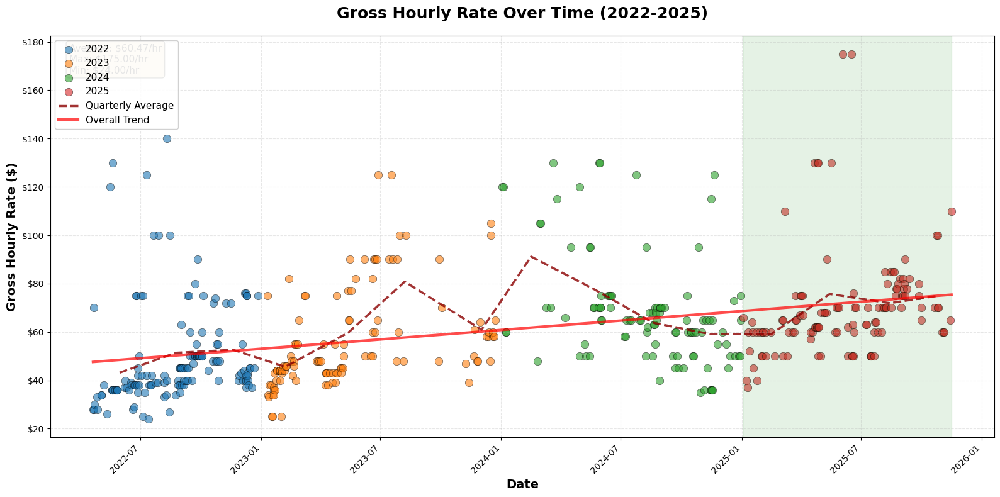

✓ Chart saved to visualizations/hourly_rate_trend_professional.png

Quarterly Average Hourly Rates:
YearQuarter  Gross_Hourly_Rate
    2022-Q2          43.153846
    2022-Q3          51.400000
    2022-Q4          52.650000
    2023-Q1          45.627907
    2023-Q2          59.717949
    2023-Q3          80.818182
    2023-Q4          60.944444
    2024-Q1          91.181818
    2024-Q2          77.541667
    2024-Q3          63.852941
    2024-Q4          59.111111
    2025-Q1          59.093750
    2025-Q2          75.725000
    2025-Q3          71.925000
    2025-Q4          75.000000


<Figure size 640x480 with 0 Axes>

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Prepare data - remove outliers (negative rates)
df['Gross_Hourly_Rate'] = df['Earnings'] / df['Hours']
df_clean = df[df['Gross_Hourly_Rate'] > 0].copy()  # Remove negative rates

# Extract year and quarter for coloring and analysis
df_clean['Year'] = df_clean['Date'].dt.year
df_clean['Quarter'] = df_clean['Date'].dt.to_period('Q').astype(str)
df_clean['YearQuarter'] = df_clean['Year'].astype(str) + '-Q' + df_clean['Date'].dt.quarter.astype(str)

# Calculate quarterly averages for trend
quarterly_avg = df_clean.groupby('YearQuarter').agg({
    'Gross_Hourly_Rate': 'mean',
    'Date': 'mean'
}).reset_index()

# Create the plot with better styling
fig, ax = plt.subplots(figsize=(16, 8))

# Color palette for years
colors = {2022: '#1f77b4', 2023: '#ff7f0e', 2024: '#2ca02c', 2025: '#d62728'}
year_labels = {2022: '2022', 2023: '2023', 2024: '2024', 2025: '2025'}

# Plot each year with different colors
for year in sorted(df_clean['Year'].unique()):
    year_data = df_clean[df_clean['Year'] == year]
    ax.scatter(year_data['Date'], year_data['Gross_Hourly_Rate'], 
               c=colors[year], label=year_labels[year], 
               s=80, alpha=0.6, edgecolors='black', linewidth=0.5)

# Add quarterly average trend line (smoother)
ax.plot(quarterly_avg['Date'], quarterly_avg['Gross_Hourly_Rate'], 
        color='darkred', linewidth=2.5, label='Quarterly Average', 
        linestyle='--', alpha=0.8)

# Overall trend line
z = np.polyfit(df_clean['Date'].astype(np.int64) / 10**9, 
               df_clean['Gross_Hourly_Rate'], 1)
p = np.poly1d(z)
ax.plot(df_clean['Date'], 
        p(df_clean['Date'].astype(np.int64) / 10**9), 
        color='red', linewidth=3, label='Overall Trend', alpha=0.7)

# Styling
ax.set_title('Gross Hourly Rate Over Time (2022-2025)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Date', fontsize=14, fontweight='bold')
ax.set_ylabel('Gross Hourly Rate ($)', fontsize=14, fontweight='bold')

# Format y-axis to show dollars
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Add gridlines for better readability
ax.grid(True, alpha=0.3, linestyle='--')

# Rotate x-axis labels
plt.xticks(rotation=45, ha='right')

# Add legend
ax.legend(loc='upper left', fontsize=11, framealpha=0.9)

# Add statistical annotations
avg_rate = df_clean['Gross_Hourly_Rate'].mean()
max_rate = df_clean['Gross_Hourly_Rate'].max()
min_rate = df_clean['Gross_Hourly_Rate'].min()

# Text box with key stats
textstr = f'Average: ${avg_rate:.2f}/hr\nMax: ${max_rate:.2f}/hr\nMin: ${min_rate:.2f}/hr'
props = dict(boxstyle='round', facecolor='wheat', alpha=0.8)
ax.text(0.02, 0.98, textstr, transform=ax.transAxes, fontsize=11,
        verticalalignment='top', bbox=props)

# Highlight strategic optimization period (2025)
if 2025 in df_clean['Year'].values:
    ax.axvspan(df_clean[df_clean['Year'] == 2025]['Date'].min(), 
               df_clean[df_clean['Year'] == 2025]['Date'].max(), 
               alpha=0.1, color='green', label='Strategic Optimization Period')

plt.tight_layout()
plt.show()

# Save high-resolution version
plt.savefig('../visualizations/hourly_rate_trend_professional.png', 
            dpi=300, bbox_inches='tight')
print("✓ Chart saved to visualizations/hourly_rate_trend_professional.png")

# Display quarterly breakdown
print("\nQuarterly Average Hourly Rates:")
print(quarterly_avg[['YearQuarter', 'Gross_Hourly_Rate']].to_string(index=False))

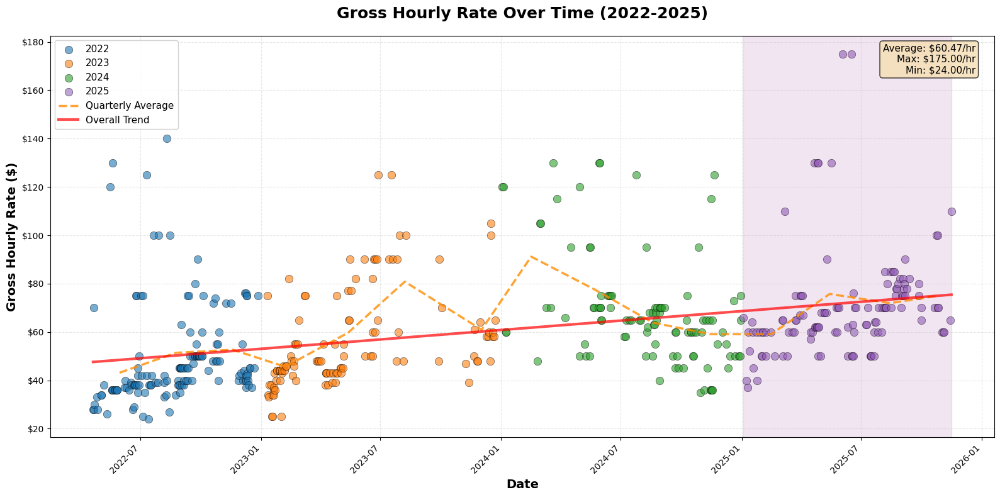

✓ Chart WITH trend line saved


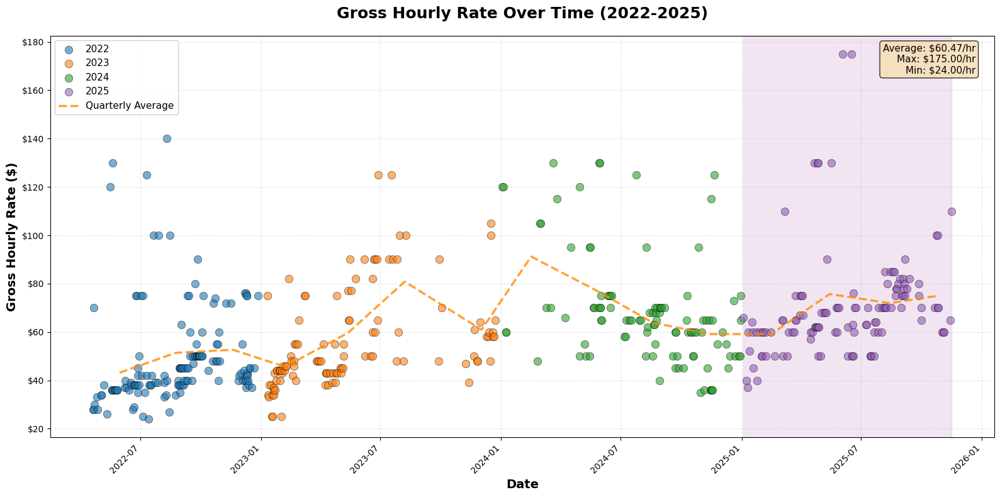

✓ Chart WITHOUT overall trend line saved

Quarterly Average Hourly Rates:
YearQuarter  Gross_Hourly_Rate
    2022-Q2          43.153846
    2022-Q3          51.400000
    2022-Q4          52.650000
    2023-Q1          45.627907
    2023-Q2          59.717949
    2023-Q3          80.818182
    2023-Q4          60.944444
    2024-Q1          91.181818
    2024-Q2          77.541667
    2024-Q3          63.852941
    2024-Q4          59.111111
    2025-Q1          59.093750
    2025-Q2          75.725000
    2025-Q3          71.925000
    2025-Q4          75.000000


In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Prepare data - remove outliers (negative rates)
df['Gross_Hourly_Rate'] = df['Earnings'] / df['Hours']
df_clean = df[df['Gross_Hourly_Rate'] > 0].copy()  # Remove negative rates

# Extract year and quarter for coloring and analysis
df_clean['Year'] = df_clean['Date'].dt.year
df_clean['Quarter'] = df_clean['Date'].dt.to_period('Q').astype(str)
df_clean['YearQuarter'] = df_clean['Year'].astype(str) + '-Q' + df_clean['Date'].dt.quarter.astype(str)

# Calculate quarterly averages for trend
quarterly_avg = df_clean.groupby('YearQuarter').agg({
    'Gross_Hourly_Rate': 'mean',
    'Date': 'mean'
}).reset_index()

# ===== VERSION 1: WITH TREND LINE =====
fig, ax = plt.subplots(figsize=(16, 8))

# Color palette for years (changed 2025 to purple)
colors = {2022: '#1f77b4', 2023: '#ff7f0e', 2024: '#2ca02c', 2025: '#9467bd'}  # Purple for 2025
year_labels = {2022: '2022', 2023: '2023', 2024: '2024', 2025: '2025'}

# Plot each year with different colors
for year in sorted(df_clean['Year'].unique()):
    year_data = df_clean[df_clean['Year'] == year]
    ax.scatter(year_data['Date'], year_data['Gross_Hourly_Rate'], 
               c=colors[year], label=year_labels[year], 
               s=80, alpha=0.6, edgecolors='black', linewidth=0.5)

# Add quarterly average trend line (smoother) - changed to orange
ax.plot(quarterly_avg['Date'], quarterly_avg['Gross_Hourly_Rate'], 
        color='darkorange', linewidth=2.5, label='Quarterly Average', 
        linestyle='--', alpha=0.8)

# Overall trend line - FIXED to span entire date range
# Convert dates to numeric for regression
x_numeric = (df_clean['Date'] - df_clean['Date'].min()).dt.days
z = np.polyfit(x_numeric, df_clean['Gross_Hourly_Rate'], 1)
p = np.poly1d(z)

# Create smooth line across entire date range
date_range = pd.date_range(df_clean['Date'].min(), df_clean['Date'].max(), periods=100)
x_smooth = (date_range - df_clean['Date'].min()).days
y_trend = p(x_smooth)

ax.plot(date_range, y_trend, 
        color='red', linewidth=3, label='Overall Trend', alpha=0.7)

# Styling
ax.set_title('Gross Hourly Rate Over Time (2022-2025)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Date', fontsize=14, fontweight='bold')
ax.set_ylabel('Gross Hourly Rate ($)', fontsize=14, fontweight='bold')

# Format y-axis to show dollars
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Add gridlines for better readability
ax.grid(True, alpha=0.3, linestyle='--')

# Rotate x-axis labels
plt.xticks(rotation=45, ha='right')

# Add legend on the left
ax.legend(loc='upper left', fontsize=11, framealpha=0.9)

# Add statistical annotations - MOVED TO RIGHT
avg_rate = df_clean['Gross_Hourly_Rate'].mean()
max_rate = df_clean['Gross_Hourly_Rate'].max()
min_rate = df_clean['Gross_Hourly_Rate'].min()

textstr = f'Average: ${avg_rate:.2f}/hr\nMax: ${max_rate:.2f}/hr\nMin: ${min_rate:.2f}/hr'
props = dict(boxstyle='round', facecolor='wheat', alpha=0.8)
ax.text(0.98, 0.98, textstr, transform=ax.transAxes, fontsize=11,
        verticalalignment='top', horizontalalignment='right', bbox=props)

# Highlight strategic optimization period (2025)
if 2025 in df_clean['Year'].values:
    ax.axvspan(df_clean[df_clean['Year'] == 2025]['Date'].min(), 
               df_clean[df_clean['Year'] == 2025]['Date'].max(), 
               alpha=0.1, color='purple')

plt.tight_layout()
plt.savefig('../visualizations/hourly_rate_WITH_trendline.png', 
            dpi=300, bbox_inches='tight')
plt.show()

print("✓ Chart WITH trend line saved")

# ===== VERSION 2: WITHOUT TREND LINE =====
fig, ax = plt.subplots(figsize=(16, 8))

# Plot each year with different colors
for year in sorted(df_clean['Year'].unique()):
    year_data = df_clean[df_clean['Year'] == year]
    ax.scatter(year_data['Date'], year_data['Gross_Hourly_Rate'], 
               c=colors[year], label=year_labels[year], 
               s=80, alpha=0.6, edgecolors='black', linewidth=0.5)

# Add quarterly average trend line only (no overall trend)
ax.plot(quarterly_avg['Date'], quarterly_avg['Gross_Hourly_Rate'], 
        color='darkorange', linewidth=2.5, label='Quarterly Average', 
        linestyle='--', alpha=0.8)

# Styling
ax.set_title('Gross Hourly Rate Over Time (2022-2025)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Date', fontsize=14, fontweight='bold')
ax.set_ylabel('Gross Hourly Rate ($)', fontsize=14, fontweight='bold')

# Format y-axis to show dollars
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--')

# Rotate x-axis labels
plt.xticks(rotation=45, ha='right')

# Add legend on the left
ax.legend(loc='upper left', fontsize=11, framealpha=0.9)

# Add stats box on the right
ax.text(0.98, 0.98, textstr, transform=ax.transAxes, fontsize=11,
        verticalalignment='top', horizontalalignment='right', bbox=props)

# Highlight 2025 period
if 2025 in df_clean['Year'].values:
    ax.axvspan(df_clean[df_clean['Year'] == 2025]['Date'].min(), 
               df_clean[df_clean['Year'] == 2025]['Date'].max(), 
               alpha=0.1, color='purple')

plt.tight_layout()
plt.savefig('../visualizations/hourly_rate_NO_trendline.png', 
            dpi=300, bbox_inches='tight')
plt.show()

print("✓ Chart WITHOUT overall trend line saved")

# Display quarterly breakdown
print("\nQuarterly Average Hourly Rates:")
print(quarterly_avg[['YearQuarter', 'Gross_Hourly_Rate']].to_string(index=False))

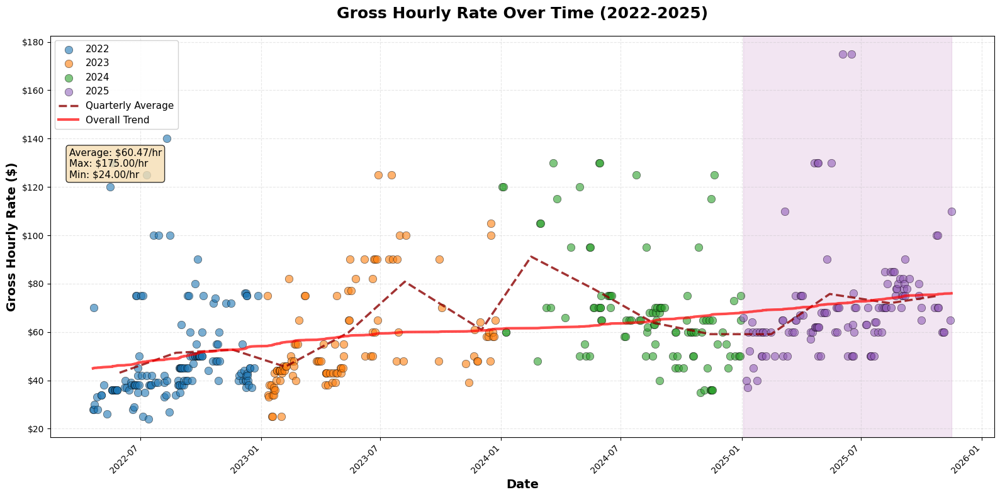

✓ Chart WITH trend line saved


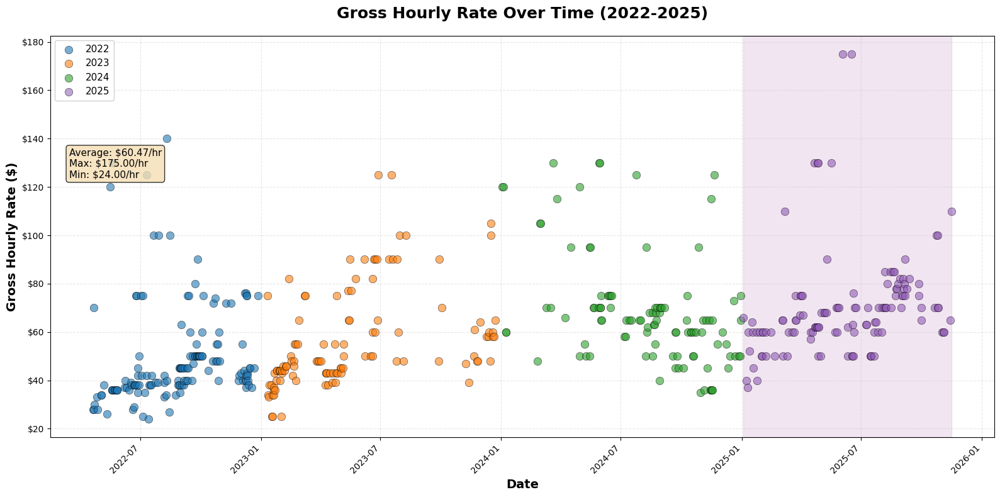

✓ Chart WITHOUT trend lines saved

Quarterly Average Hourly Rates:
YearQuarter  Gross_Hourly_Rate
    2022-Q2          43.153846
    2022-Q3          51.400000
    2022-Q4          52.650000
    2023-Q1          45.627907
    2023-Q2          59.717949
    2023-Q3          80.818182
    2023-Q4          60.944444
    2024-Q1          91.181818
    2024-Q2          77.541667
    2024-Q3          63.852941
    2024-Q4          59.111111
    2025-Q1          59.093750
    2025-Q2          75.725000
    2025-Q3          71.925000
    2025-Q4          75.000000


In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Prepare data - remove outliers (negative rates AND infinite values)
df['Gross_Hourly_Rate'] = df['Earnings'] / df['Hours']
df_clean = df[(df['Gross_Hourly_Rate'] > 0) & (df['Gross_Hourly_Rate'] < np.inf)].copy()  # Remove negative and infinite

# Extract year and quarter for coloring and analysis
df_clean['Year'] = df_clean['Date'].dt.year
df_clean['Quarter'] = df_clean['Date'].dt.to_period('Q').astype(str)
df_clean['YearQuarter'] = df_clean['Year'].astype(str) + '-Q' + df_clean['Date'].dt.quarter.astype(str)

# Calculate quarterly averages for trend
quarterly_avg = df_clean.groupby('YearQuarter').agg({
    'Gross_Hourly_Rate': 'mean',
    'Date': 'mean'
}).reset_index()

# Color palette for years (purple for 2025)
colors = {2022: '#1f77b4', 2023: '#ff7f0e', 2024: '#2ca02c', 2025: '#9467bd'}
year_labels = {2022: '2022', 2023: '2023', 2024: '2024', 2025: '2025'}

# Calculate stats
avg_rate = df_clean['Gross_Hourly_Rate'].mean()
max_rate = df_clean['Gross_Hourly_Rate'].max()
min_rate = df_clean['Gross_Hourly_Rate'].min()

textstr = f'Average: ${avg_rate:.2f}/hr\nMax: ${max_rate:.2f}/hr\nMin: ${min_rate:.2f}/hr'
props = dict(boxstyle='round', facecolor='wheat', alpha=0.8)

# ===== VERSION 1: WITH TREND LINE =====
fig, ax = plt.subplots(figsize=(16, 8))

# Plot each year with different colors
for year in sorted(df_clean['Year'].unique()):
    year_data = df_clean[df_clean['Year'] == year]
    ax.scatter(year_data['Date'], year_data['Gross_Hourly_Rate'], 
               c=colors[year], label=year_labels[year], 
               s=80, alpha=0.6, edgecolors='black', linewidth=0.5)

# Add quarterly average trend line - dark red
ax.plot(quarterly_avg['Date'], quarterly_avg['Gross_Hourly_Rate'], 
        color='darkred', linewidth=2.5, label='Quarterly Average', 
        linestyle='--', alpha=0.8)

# Overall trend line - PROPERLY FIXED
# Sort data by date first
df_sorted = df_clean.sort_values('Date')
# Convert dates to numeric for regression
x_numeric = np.arange(len(df_sorted))
z = np.polyfit(x_numeric, df_sorted['Gross_Hourly_Rate'], 1)
p = np.poly1d(z)

# Plot trend line
ax.plot(df_sorted['Date'], p(x_numeric), 
        color='red', linewidth=3, label='Overall Trend', alpha=0.7)

# Styling
ax.set_title('Gross Hourly Rate Over Time (2022-2025)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Date', fontsize=14, fontweight='bold')
ax.set_ylabel('Gross Hourly Rate ($)', fontsize=14, fontweight='bold')

# Format y-axis to show dollars
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--')

# Rotate x-axis labels
plt.xticks(rotation=45, ha='right')

# Add legend on the left
ax.legend(loc='upper left', fontsize=11, framealpha=0.9)

# Add stats box to the left, next to legend but not overlapping
ax.text(0.02, 0.72, textstr, transform=ax.transAxes, fontsize=11,
        verticalalignment='top', bbox=props)

# Highlight 2025 period
if 2025 in df_clean['Year'].values:
    ax.axvspan(df_clean[df_clean['Year'] == 2025]['Date'].min(), 
               df_clean[df_clean['Year'] == 2025]['Date'].max(), 
               alpha=0.1, color='purple')

plt.tight_layout()
plt.savefig('../visualizations/hourly_rate_WITH_trendline.png', 
            dpi=300, bbox_inches='tight')
plt.show()

print("✓ Chart WITH trend line saved")

# ===== VERSION 2: WITHOUT TREND LINE (NO LINES AT ALL) =====
fig, ax = plt.subplots(figsize=(16, 8))

# Plot each year with different colors - DOTS ONLY
for year in sorted(df_clean['Year'].unique()):
    year_data = df_clean[df_clean['Year'] == year]
    ax.scatter(year_data['Date'], year_data['Gross_Hourly_Rate'], 
               c=colors[year], label=year_labels[year], 
               s=80, alpha=0.6, edgecolors='black', linewidth=0.5)

# NO LINES AT ALL - just dots

# Styling
ax.set_title('Gross Hourly Rate Over Time (2022-2025)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Date', fontsize=14, fontweight='bold')
ax.set_ylabel('Gross Hourly Rate ($)', fontsize=14, fontweight='bold')

# Format y-axis to show dollars
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--')

# Rotate x-axis labels
plt.xticks(rotation=45, ha='right')

# Add legend on the left
ax.legend(loc='upper left', fontsize=11, framealpha=0.9)

# Add stats box next to legend
ax.text(0.02, 0.72, textstr, transform=ax.transAxes, fontsize=11,
        verticalalignment='top', bbox=props)

# Highlight 2025 period
if 2025 in df_clean['Year'].values:
    ax.axvspan(df_clean[df_clean['Year'] == 2025]['Date'].min(), 
               df_clean[df_clean['Year'] == 2025]['Date'].max(), 
               alpha=0.1, color='purple')

plt.tight_layout()
plt.savefig('../visualizations/hourly_rate_NO_trendline.png', 
            dpi=300, bbox_inches='tight')
plt.show()

print("✓ Chart WITHOUT trend lines saved")

# Display quarterly breakdown
print("\nQuarterly Average Hourly Rates:")
print(quarterly_avg[['YearQuarter', 'Gross_Hourly_Rate']].to_string(index=False))

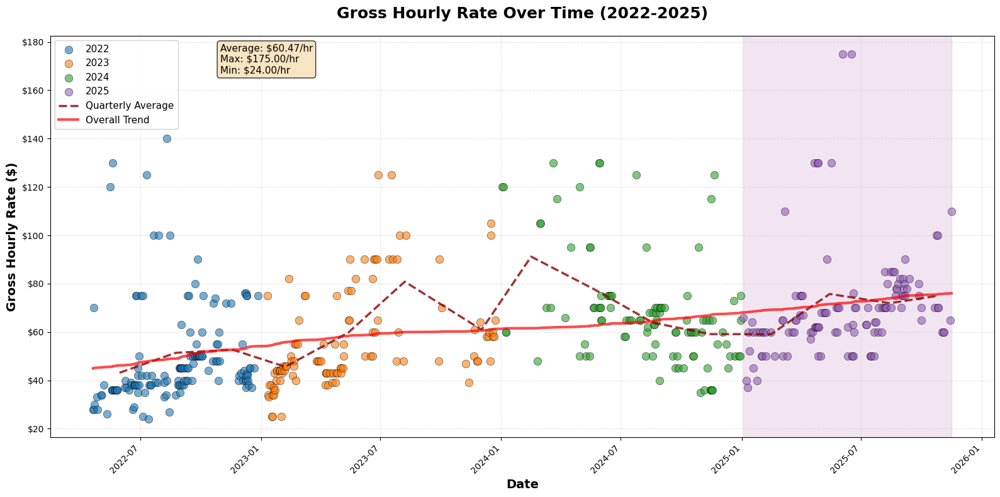

✓ Chart WITH trend line saved


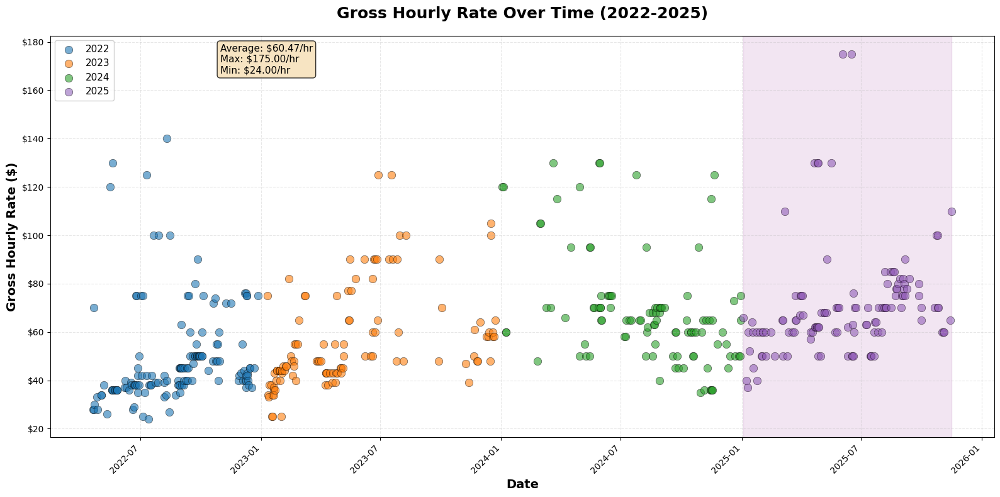

✓ Chart WITHOUT trend lines saved

Quarterly Average Hourly Rates:
YearQuarter  Gross_Hourly_Rate
    2022-Q2          43.153846
    2022-Q3          51.400000
    2022-Q4          52.650000
    2023-Q1          45.627907
    2023-Q2          59.717949
    2023-Q3          80.818182
    2023-Q4          60.944444
    2024-Q1          91.181818
    2024-Q2          77.541667
    2024-Q3          63.852941
    2024-Q4          59.111111
    2025-Q1          59.093750
    2025-Q2          75.725000
    2025-Q3          71.925000
    2025-Q4          75.000000


In [6]:
# Prepare data - remove outliers (negative rates AND infinite values)
df['Gross_Hourly_Rate'] = df['Earnings'] / df['Hours']
df_clean = df[(df['Gross_Hourly_Rate'] > 0) & (df['Gross_Hourly_Rate'] < np.inf)].copy()

# Extract year and quarter for coloring and analysis
df_clean['Year'] = df_clean['Date'].dt.year
df_clean['Quarter'] = df_clean['Date'].dt.to_period('Q').astype(str)
df_clean['YearQuarter'] = df_clean['Year'].astype(str) + '-Q' + df_clean['Date'].dt.quarter.astype(str)

# Calculate quarterly averages for trend
quarterly_avg = df_clean.groupby('YearQuarter').agg({
    'Gross_Hourly_Rate': 'mean',
    'Date': 'mean'
}).reset_index()

# Color palette for years (purple for 2025)
colors = {2022: '#1f77b4', 2023: '#ff7f0e', 2024: '#2ca02c', 2025: '#9467bd'}
year_labels = {2022: '2022', 2023: '2023', 2024: '2024', 2025: '2025'}

# Calculate stats
avg_rate = df_clean['Gross_Hourly_Rate'].mean()
max_rate = df_clean['Gross_Hourly_Rate'].max()
min_rate = df_clean['Gross_Hourly_Rate'].min()

textstr = f'Average: ${avg_rate:.2f}/hr\nMax: ${max_rate:.2f}/hr\nMin: ${min_rate:.2f}/hr'
props = dict(boxstyle='round', facecolor='wheat', alpha=0.8)

# ===== VERSION 1: WITH TREND LINE =====
fig, ax = plt.subplots(figsize=(16, 8))

# Plot each year with different colors
for year in sorted(df_clean['Year'].unique()):
    year_data = df_clean[df_clean['Year'] == year]
    ax.scatter(year_data['Date'], year_data['Gross_Hourly_Rate'], 
               c=colors[year], label=year_labels[year], 
               s=80, alpha=0.6, edgecolors='black', linewidth=0.5)

# Add quarterly average trend line - dark red
ax.plot(quarterly_avg['Date'], quarterly_avg['Gross_Hourly_Rate'], 
        color='darkred', linewidth=2.5, label='Quarterly Average', 
        linestyle='--', alpha=0.8)

# Overall trend line
df_sorted = df_clean.sort_values('Date')
x_numeric = np.arange(len(df_sorted))
z = np.polyfit(x_numeric, df_sorted['Gross_Hourly_Rate'], 1)
p = np.poly1d(z)

ax.plot(df_sorted['Date'], p(x_numeric), 
        color='red', linewidth=3, label='Overall Trend', alpha=0.7)

# Styling
ax.set_title('Gross Hourly Rate Over Time (2022-2025)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Date', fontsize=14, fontweight='bold')
ax.set_ylabel('Gross Hourly Rate ($)', fontsize=14, fontweight='bold')

# Format y-axis to show dollars
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--')

# Rotate x-axis labels
plt.xticks(rotation=45, ha='right')

# Add legend on the left
ax.legend(loc='upper left', fontsize=11, framealpha=0.9)

# Add stats box to the right of legend - positioned at 0.18 (just right of legend)
ax.text(0.18, 0.98, textstr, transform=ax.transAxes, fontsize=11,
        verticalalignment='top', bbox=props)

# Highlight 2025 period
if 2025 in df_clean['Year'].values:
    ax.axvspan(df_clean[df_clean['Year'] == 2025]['Date'].min(), 
               df_clean[df_clean['Year'] == 2025]['Date'].max(), 
               alpha=0.1, color='purple')

plt.tight_layout()
plt.savefig('../visualizations/hourly_rate_WITH_trendline.png', 
            dpi=300, bbox_inches='tight')
plt.show()

print("✓ Chart WITH trend line saved")

# ===== VERSION 2: WITHOUT TREND LINE =====
fig, ax = plt.subplots(figsize=(16, 8))

# Plot each year with different colors
for year in sorted(df_clean['Year'].unique()):
    year_data = df_clean[df_clean['Year'] == year]
    ax.scatter(year_data['Date'], year_data['Gross_Hourly_Rate'], 
               c=colors[year], label=year_labels[year], 
               s=80, alpha=0.6, edgecolors='black', linewidth=0.5)

# Styling
ax.set_title('Gross Hourly Rate Over Time (2022-2025)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Date', fontsize=14, fontweight='bold')
ax.set_ylabel('Gross Hourly Rate ($)', fontsize=14, fontweight='bold')

# Format y-axis
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--')

# Rotate x-axis labels
plt.xticks(rotation=45, ha='right')

# Add legend on the left
ax.legend(loc='upper left', fontsize=11, framealpha=0.9)

# Add stats box to the right of legend
ax.text(0.18, 0.98, textstr, transform=ax.transAxes, fontsize=11,
        verticalalignment='top', bbox=props)

# Highlight 2025 period
if 2025 in df_clean['Year'].values:
    ax.axvspan(df_clean[df_clean['Year'] == 2025]['Date'].min(), 
               df_clean[df_clean['Year'] == 2025]['Date'].max(), 
               alpha=0.1, color='purple')

plt.tight_layout()
plt.savefig('../visualizations/hourly_rate_NO_trendline.png', 
            dpi=300, bbox_inches='tight')
plt.show()

print("✓ Chart WITHOUT trend lines saved")

# Display quarterly breakdown
print("\nQuarterly Average Hourly Rates:")
print(quarterly_avg[['YearQuarter', 'Gross_Hourly_Rate']].to_string(index=False))

In [7]:
# Display the quarterly averages that are being plotted
print("Quarterly Average Hourly Rates:")
print(quarterly_avg[['YearQuarter', 'Gross_Hourly_Rate', 'Date']])

# Let's also manually verify a few quarters
print("\n" + "="*60)
print("Manual Verification - Sample Quarters:")
print("="*60)

for quarter in ['2022-Q2', '2023-Q1', '2024-Q3', '2025-Q1']:
    quarter_data = df_clean[df_clean['YearQuarter'] == quarter]
    if len(quarter_data) > 0:
        manual_avg = quarter_data['Gross_Hourly_Rate'].mean()
        print(f"\n{quarter}:")
        print(f"  Number of jobs: {len(quarter_data)}")
        print(f"  Manual average: ${manual_avg:.2f}/hr")
        print(f"  Quarterly_avg table: ${quarterly_avg[quarterly_avg['YearQuarter']==quarter]['Gross_Hourly_Rate'].values[0]:.2f}/hr")
        print(f"  Match: {np.isclose(manual_avg, quarterly_avg[quarterly_avg['YearQuarter']==quarter]['Gross_Hourly_Rate'].values[0])}")

# Show the actual data points vs the line
print("\n" + "="*60)
print("Does the line match the data pattern?")
print("="*60)
print("\nLook at the chart - does the dashed line go through the 'center' of each quarter's dots?")

Quarterly Average Hourly Rates:
   YearQuarter  Gross_Hourly_Rate                          Date
0      2022-Q2          43.153846 2022-05-30 08:36:55.384615424
1      2022-Q3          51.400000 2022-08-23 23:37:50.769230848
2      2022-Q4          52.650000 2022-11-18 16:48:00.000000000
3      2023-Q1          45.627907 2023-02-06 08:55:48.837209344
4      2023-Q2          59.717949 2023-05-13 04:55:23.076923136
5      2023-Q3          80.818182 2023-08-07 06:32:43.636363520
6      2023-Q4          60.944444 2023-12-02 04:00:00.000000000
7      2024-Q1          91.181818 2024-02-15 13:05:27.272727296
8      2024-Q2          77.541667 2024-05-22 08:00:00.000000000
9      2024-Q3          63.852941 2024-08-18 23:17:38.823529472
10     2024-Q4          59.111111 2024-11-14 02:00:00.000000000
11     2025-Q1          59.093750 2025-02-14 16:30:00.000000000
12     2025-Q2          75.725000 2025-05-14 19:12:00.000000000
13     2025-Q3          71.925000 2025-08-14 09:36:00.000000000
14     2

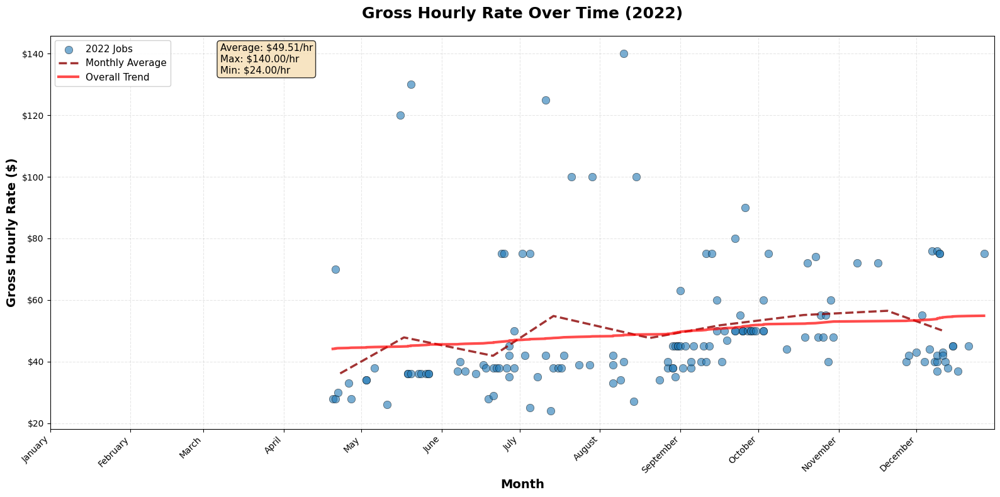

✓ Chart for 2022 saved


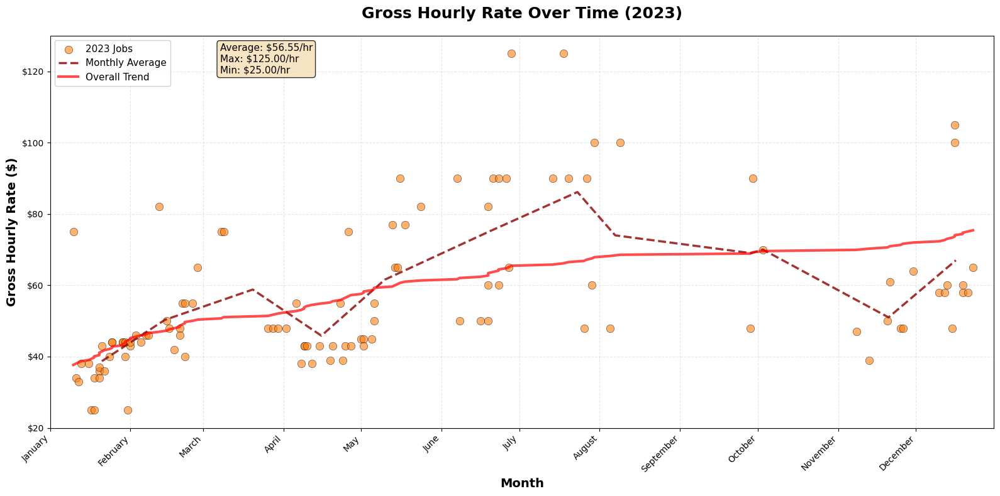

✓ Chart for 2023 saved


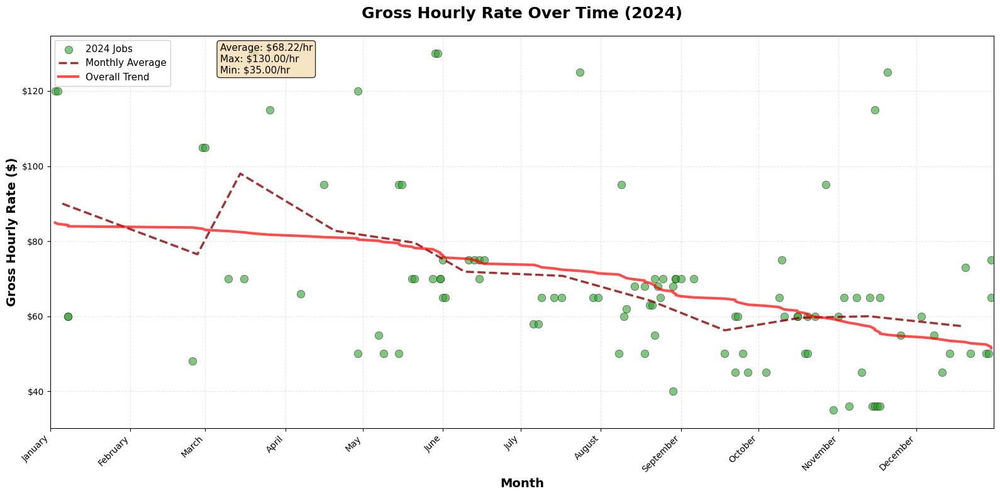

✓ Chart for 2024 saved


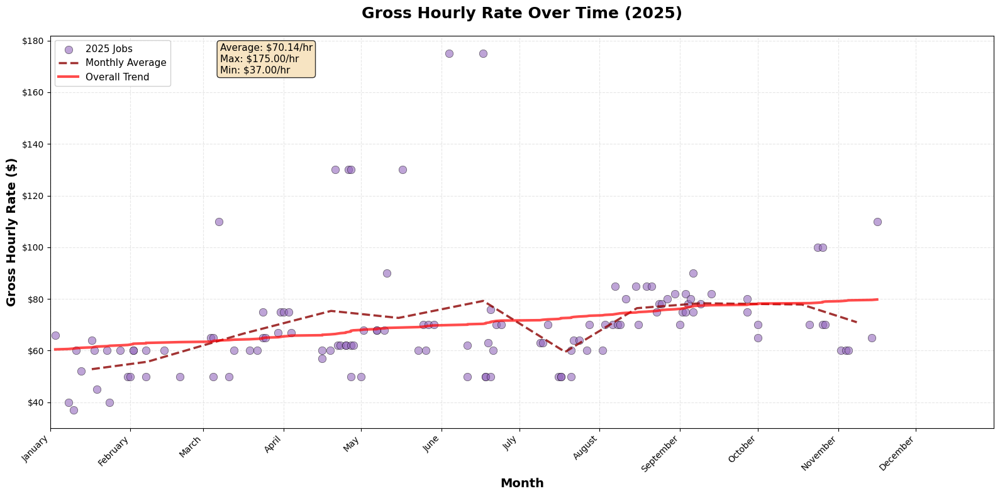

✓ Chart for 2025 saved

✓ All individual year charts created!


In [8]:
# Prepare data
df['Gross_Hourly_Rate'] = df['Earnings'] / df['Hours']
df_clean = df[(df['Gross_Hourly_Rate'] > 0) & (df['Gross_Hourly_Rate'] < np.inf)].copy()

# Extract year and month
df_clean['Year'] = df_clean['Date'].dt.year
df_clean['Month'] = df_clean['Date'].dt.month
df_clean['Month_Name'] = df_clean['Date'].dt.strftime('%B')
df_clean['Year_Month'] = df_clean['Date'].dt.to_period('M')

# Calculate monthly averages
monthly_avg = df_clean.groupby(['Year', 'Year_Month']).agg({
    'Gross_Hourly_Rate': 'mean',
    'Date': 'mean'
}).reset_index()

# Color for each year's dots
year_colors = {2022: '#1f77b4', 2023: '#ff7f0e', 2024: '#2ca02c', 2025: '#9467bd'}

# Create individual chart for each year
for year in sorted(df_clean['Year'].unique()):
    year_data = df_clean[df_clean['Year'] == year]
    year_monthly = monthly_avg[monthly_avg['Year'] == year]
    
    # Calculate stats for this year
    avg_rate = year_data['Gross_Hourly_Rate'].mean()
    max_rate = year_data['Gross_Hourly_Rate'].max()
    min_rate = year_data['Gross_Hourly_Rate'].min()
    
    textstr = f'Average: ${avg_rate:.2f}/hr\nMax: ${max_rate:.2f}/hr\nMin: ${min_rate:.2f}/hr'
    props = dict(boxstyle='round', facecolor='wheat', alpha=0.8)
    
    # Create figure
    fig, ax = plt.subplots(figsize=(16, 8))
    
    # Plot dots for this year
    ax.scatter(year_data['Date'], year_data['Gross_Hourly_Rate'], 
               c=year_colors[year], s=80, alpha=0.6, 
               edgecolors='black', linewidth=0.5, label=f'{year} Jobs')
    
    # Add monthly average trend line
    ax.plot(year_monthly['Date'], year_monthly['Gross_Hourly_Rate'], 
            color='darkred', linewidth=2.5, label='Monthly Average', 
            linestyle='--', alpha=0.8)
    
    # Overall trend line for the year
    year_sorted = year_data.sort_values('Date')
    x_numeric = np.arange(len(year_sorted))
    z = np.polyfit(x_numeric, year_sorted['Gross_Hourly_Rate'], 1)
    p = np.poly1d(z)
    
    ax.plot(year_sorted['Date'], p(x_numeric), 
            color='red', linewidth=3, label='Overall Trend', alpha=0.7)
    
    # Styling
    ax.set_title(f'Gross Hourly Rate Over Time ({year})', 
                 fontsize=18, fontweight='bold', pad=20)
    ax.set_xlabel('Month', fontsize=14, fontweight='bold')
    ax.set_ylabel('Gross Hourly Rate ($)', fontsize=14, fontweight='bold')
    
    # Format y-axis to show dollars
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))
    
    # Set x-axis limits to exactly the year boundary
    ax.set_xlim(pd.Timestamp(f'{year}-01-01'), pd.Timestamp(f'{year}-12-31'))
    
    # Format x-axis to show month names - one per month
    import matplotlib.dates as mdates
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%B'))
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=1))
    
    # Add gridlines
    ax.grid(True, alpha=0.3, linestyle='--')
    
    # Rotate x-axis labels
    plt.xticks(rotation=45, ha='right')
    
    # Add legend
    ax.legend(loc='upper left', fontsize=11, framealpha=0.9)
    
    # Add stats box
    ax.text(0.18, 0.98, textstr, transform=ax.transAxes, fontsize=11,
            verticalalignment='top', bbox=props)
    
    plt.tight_layout()
    plt.savefig(f'../visualizations/hourly_rate_{year}.png', 
                dpi=300, bbox_inches='tight')
    plt.show()
    
    print(f"✓ Chart for {year} saved")

print("\n✓ All individual year charts created!")

[Text(20103.0, 0, 'January'),
 Text(20134.0, 0, 'February'),
 Text(20162.0, 0, 'March'),
 Text(20193.0, 0, 'April'),
 Text(20223.0, 0, 'May'),
 Text(20254.0, 0, 'June'),
 Text(20284.0, 0, 'July'),
 Text(20315.0, 0, 'August'),
 Text(20346.0, 0, 'September'),
 Text(20376.0, 0, 'October'),
 Text(20407.0, 0, 'November'),
 Text(20437.0, 0, 'December')]

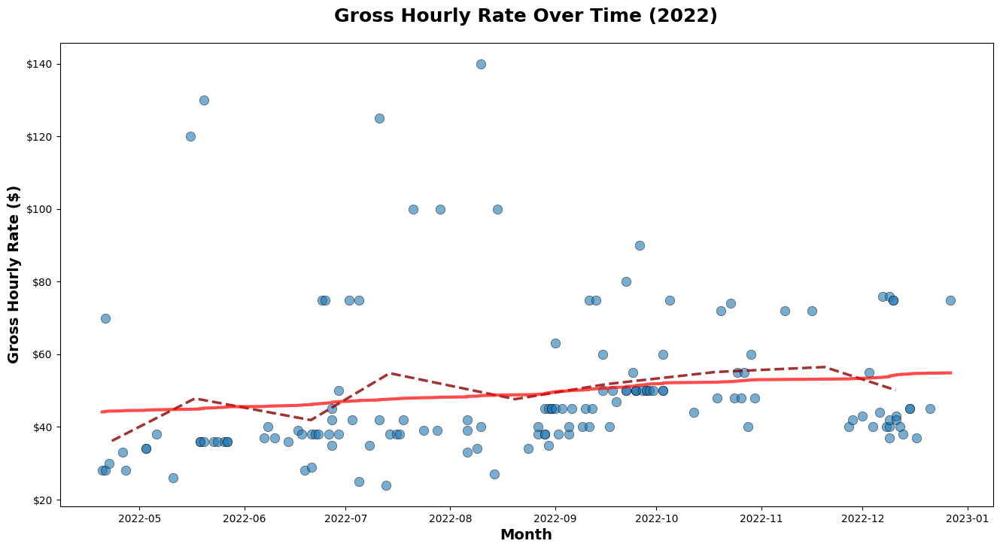

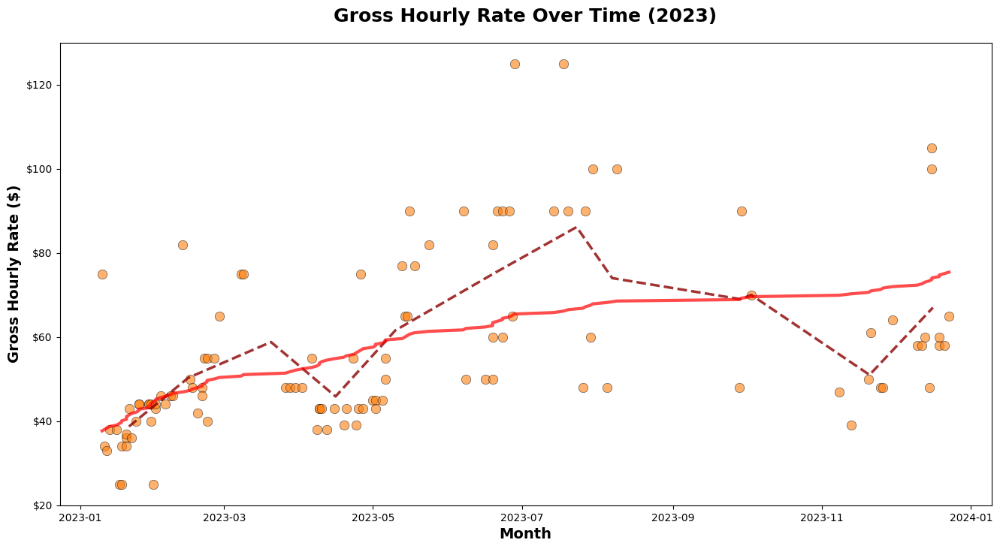

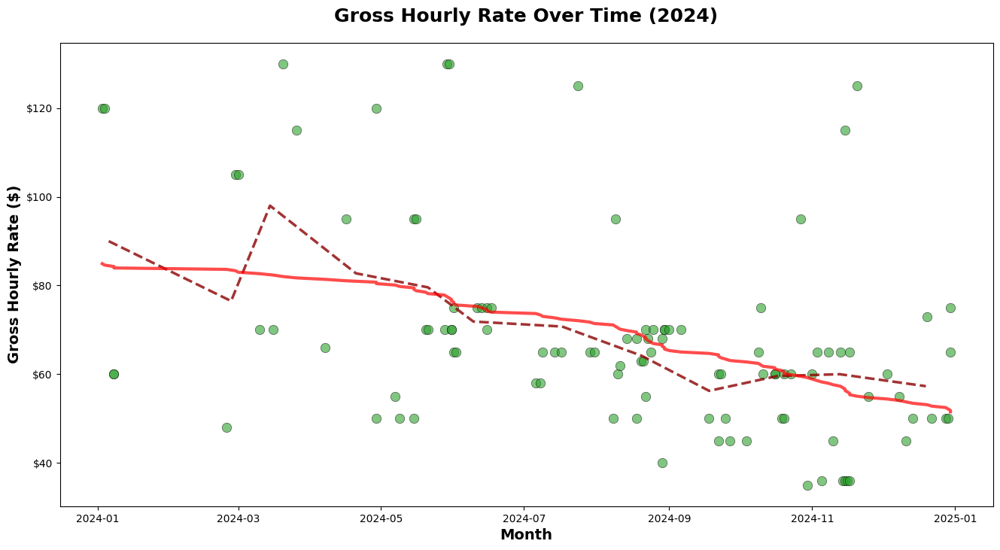

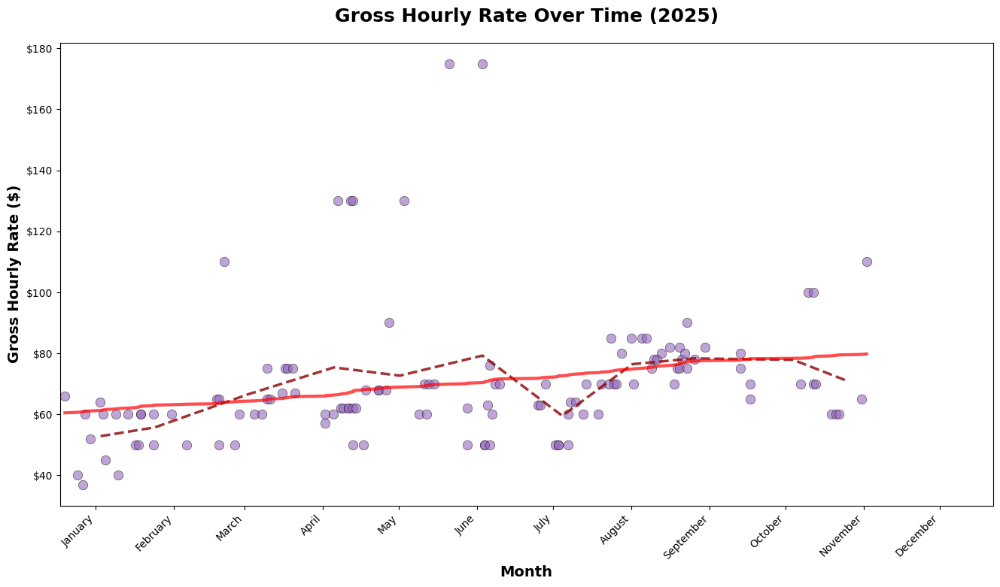

In [9]:
# Prepare data
df['Gross_Hourly_Rate'] = df['Earnings'] / df['Hours']
df_clean = df[(df['Gross_Hourly_Rate'] > 0) & (df['Gross_Hourly_Rate'] < np.inf)].copy()

# Extract year and month
df_clean['Year'] = df_clean['Date'].dt.year
df_clean['Month'] = df_clean['Date'].dt.month
df_clean['Month_Name'] = df_clean['Date'].dt.strftime('%B')
df_clean['Year_Month'] = df_clean['Date'].dt.to_period('M')

# Calculate monthly averages
monthly_avg = df_clean.groupby(['Year', 'Year_Month']).agg({
    'Gross_Hourly_Rate': 'mean',
    'Date': 'mean'
}).reset_index()

# Color for each year's dots
year_colors = {2022: '#1f77b4', 2023: '#ff7f0e', 2024: '#2ca02c', 2025: '#9467bd'}

# Create individual chart for each year
for year in sorted(df_clean['Year'].unique()):
    year_data = df_clean[df_clean['Year'] == year]
    year_monthly = monthly_avg[monthly_avg['Year'] == year]
    
    # Calculate stats for this year
    avg_rate = year_data['Gross_Hourly_Rate'].mean()
    max_rate = year_data['Gross_Hourly_Rate'].max()
    min_rate = year_data['Gross_Hourly_Rate'].min()
    
    textstr = f'Average: ${avg_rate:.2f}/hr\nMax: ${max_rate:.2f}/hr\nMin: ${min_rate:.2f}/hr'
    props = dict(boxstyle='round', facecolor='wheat', alpha=0.8)
    
    # Create figure
    fig, ax = plt.subplots(figsize=(16, 8))
    
    # Plot dots for this year
    ax.scatter(year_data['Date'], year_data['Gross_Hourly_Rate'], 
               c=year_colors[year], s=80, alpha=0.6, 
               edgecolors='black', linewidth=0.5, label=f'{year} Jobs')
    
    # Add monthly average trend line
    ax.plot(year_monthly['Date'], year_monthly['Gross_Hourly_Rate'], 
            color='darkred', linewidth=2.5, label='Monthly Average', 
            linestyle='--', alpha=0.8)
    
    # Overall trend line for the year
    year_sorted = year_data.sort_values('Date')
    x_numeric = np.arange(len(year_sorted))
    z = np.polyfit(x_numeric, year_sorted['Gross_Hourly_Rate'], 1)
    p = np.poly1d(z)
    
    ax.plot(year_sorted['Date'], p(x_numeric), 
            color='red', linewidth=3, label='Overall Trend', alpha=0.7)
    
    # Styling
    ax.set_title(f'Gross Hourly Rate Over Time ({year})', 
                 fontsize=18, fontweight='bold', pad=20)
    ax.set_xlabel('Month', fontsize=14, fontweight='bold')
    ax.set_ylabel('Gross Hourly Rate ($)', fontsize=14, fontweight='bold')
    
    # Format y-axis to show dollars
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))
    
   # Set x-axis limits with padding - extend slightly past year end
ax.set_xlim(pd.Timestamp(f'{year}-01-01'), pd.Timestamp(f'{year+1}-01-05'))

# Manually set the month labels
month_names = ['January', 'February', 'March', 'April', 'May', 'June', 
               'July', 'August', 'September', 'October', 'November', 'December']

# Create tick positions at the 15th of each month
tick_dates = [pd.Timestamp(f'{year}-{m:02d}-15') for m in range(1, 13)]

ax.set_xticks(tick_dates)
ax.set_xticklabels(month_names, rotation=45, ha='right')

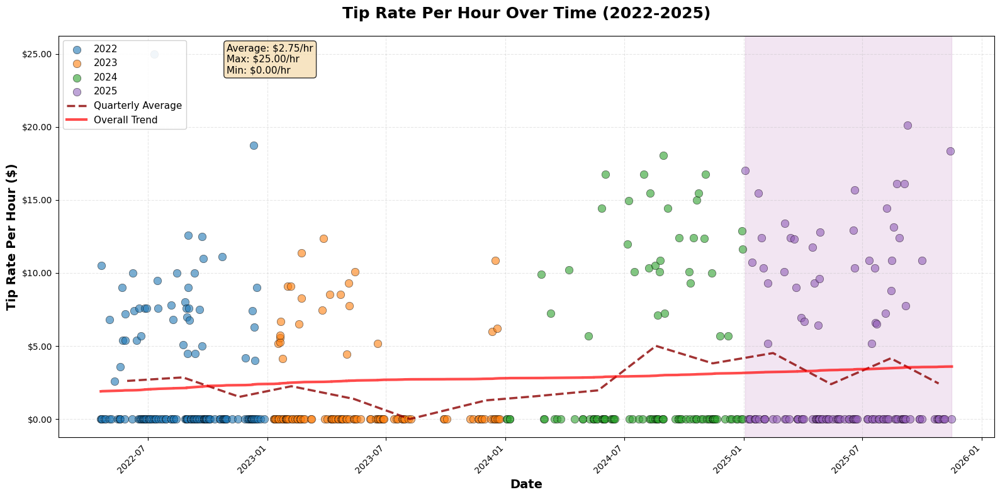

✓ Tip chart WITH trend line saved


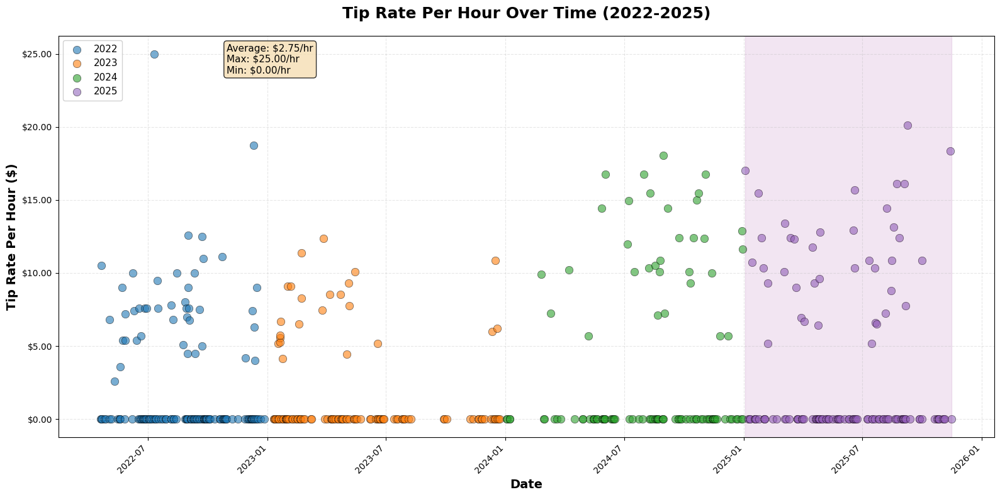

✓ Tip chart WITHOUT trend lines saved

Quarterly Average Tip Rates:
YearQuarter  Tip_Hourly_Rate
    2022-Q2         2.610291
    2022-Q3         2.851562
    2022-Q4         1.518750
    2023-Q1         2.247359
    2023-Q2         1.378291
    2023-Q3         0.000000
    2023-Q4         1.279087
    2024-Q1         1.558235
    2024-Q2         1.963638
    2024-Q3         5.008455
    2024-Q4         3.813287
    2025-Q1         4.517439
    2025-Q2         2.386478
    2025-Q3         4.159985
    2025-Q4         2.433519


In [10]:
# Prepare data - Tips per hour
df['Tip_Hourly_Rate'] = df['Tip'] / df['Hours']
df_tip_clean = df[(df['Tip_Hourly_Rate'] >= 0) & (df['Tip_Hourly_Rate'] < np.inf)].copy()

# Extract year and quarter
df_tip_clean['Year'] = df_tip_clean['Date'].dt.year
df_tip_clean['Quarter'] = df_tip_clean['Date'].dt.to_period('Q').astype(str)
df_tip_clean['YearQuarter'] = df_tip_clean['Year'].astype(str) + '-Q' + df_tip_clean['Date'].dt.quarter.astype(str)

# Calculate quarterly averages for tips
quarterly_tip_avg = df_tip_clean.groupby('YearQuarter').agg({
    'Tip_Hourly_Rate': 'mean',
    'Date': 'mean'
}).reset_index()

# Color palette for years (purple for 2025)
colors = {2022: '#1f77b4', 2023: '#ff7f0e', 2024: '#2ca02c', 2025: '#9467bd'}
year_labels = {2022: '2022', 2023: '2023', 2024: '2024', 2025: '2025'}

# Calculate stats
avg_tip_rate = df_tip_clean['Tip_Hourly_Rate'].mean()
max_tip_rate = df_tip_clean['Tip_Hourly_Rate'].max()
min_tip_rate = df_tip_clean['Tip_Hourly_Rate'].min()

textstr = f'Average: ${avg_tip_rate:.2f}/hr\nMax: ${max_tip_rate:.2f}/hr\nMin: ${min_tip_rate:.2f}/hr'
props = dict(boxstyle='round', facecolor='wheat', alpha=0.8)

# ===== VERSION 1: WITH TREND LINE =====
fig, ax = plt.subplots(figsize=(16, 8))

# Plot each year with different colors
for year in sorted(df_tip_clean['Year'].unique()):
    year_data = df_tip_clean[df_tip_clean['Year'] == year]
    ax.scatter(year_data['Date'], year_data['Tip_Hourly_Rate'], 
               c=colors[year], label=year_labels[year], 
               s=80, alpha=0.6, edgecolors='black', linewidth=0.5)

# Add quarterly average trend line - dark red
ax.plot(quarterly_tip_avg['Date'], quarterly_tip_avg['Tip_Hourly_Rate'], 
        color='darkred', linewidth=2.5, label='Quarterly Average', 
        linestyle='--', alpha=0.8)

# Overall trend line
df_sorted = df_tip_clean.sort_values('Date')
x_numeric = np.arange(len(df_sorted))
z = np.polyfit(x_numeric, df_sorted['Tip_Hourly_Rate'], 1)
p = np.poly1d(z)

ax.plot(df_sorted['Date'], p(x_numeric), 
        color='red', linewidth=3, label='Overall Trend', alpha=0.7)

# Styling
ax.set_title('Tip Rate Per Hour Over Time (2022-2025)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Date', fontsize=14, fontweight='bold')
ax.set_ylabel('Tip Rate Per Hour ($)', fontsize=14, fontweight='bold')

# Format y-axis to show dollars
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.2f}'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--')

# Rotate x-axis labels
plt.xticks(rotation=45, ha='right')

# Add legend on the left
ax.legend(loc='upper left', fontsize=11, framealpha=0.9)

# Add stats box to the right of legend
ax.text(0.18, 0.98, textstr, transform=ax.transAxes, fontsize=11,
        verticalalignment='top', bbox=props)

# Highlight 2025 period
if 2025 in df_tip_clean['Year'].values:
    ax.axvspan(df_tip_clean[df_tip_clean['Year'] == 2025]['Date'].min(), 
               df_tip_clean[df_tip_clean['Year'] == 2025]['Date'].max(), 
               alpha=0.1, color='purple')

plt.tight_layout()
plt.savefig('../visualizations/tip_rate_WITH_trendline.png', 
            dpi=300, bbox_inches='tight')
plt.show()

print("✓ Tip chart WITH trend line saved")

# ===== VERSION 2: WITHOUT TREND LINE =====
fig, ax = plt.subplots(figsize=(16, 8))

# Plot each year with different colors
for year in sorted(df_tip_clean['Year'].unique()):
    year_data = df_tip_clean[df_tip_clean['Year'] == year]
    ax.scatter(year_data['Date'], year_data['Tip_Hourly_Rate'], 
               c=colors[year], label=year_labels[year], 
               s=80, alpha=0.6, edgecolors='black', linewidth=0.5)

# Styling
ax.set_title('Tip Rate Per Hour Over Time (2022-2025)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Date', fontsize=14, fontweight='bold')
ax.set_ylabel('Tip Rate Per Hour ($)', fontsize=14, fontweight='bold')

# Format y-axis
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.2f}'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--')

# Rotate x-axis labels
plt.xticks(rotation=45, ha='right')

# Add legend on the left
ax.legend(loc='upper left', fontsize=11, framealpha=0.9)

# Add stats box to the right of legend
ax.text(0.18, 0.98, textstr, transform=ax.transAxes, fontsize=11,
        verticalalignment='top', bbox=props)

# Highlight 2025 period
if 2025 in df_tip_clean['Year'].values:
    ax.axvspan(df_tip_clean[df_tip_clean['Year'] == 2025]['Date'].min(), 
               df_tip_clean[df_tip_clean['Year'] == 2025]['Date'].max(), 
               alpha=0.1, color='purple')

plt.tight_layout()
plt.savefig('../visualizations/tip_rate_NO_trendline.png', 
            dpi=300, bbox_inches='tight')
plt.show()

print("✓ Tip chart WITHOUT trend lines saved")

# Display quarterly breakdown
print("\nQuarterly Average Tip Rates:")
print(quarterly_tip_avg[['YearQuarter', 'Tip_Hourly_Rate']].to_string(index=False))

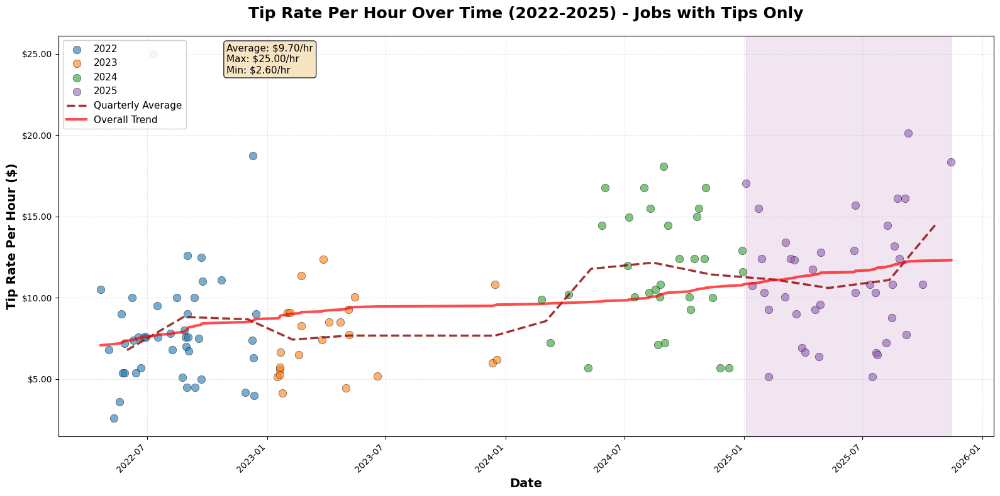

✓ Tip chart WITH trend line saved
Note: Excluded 347 jobs with zero tips


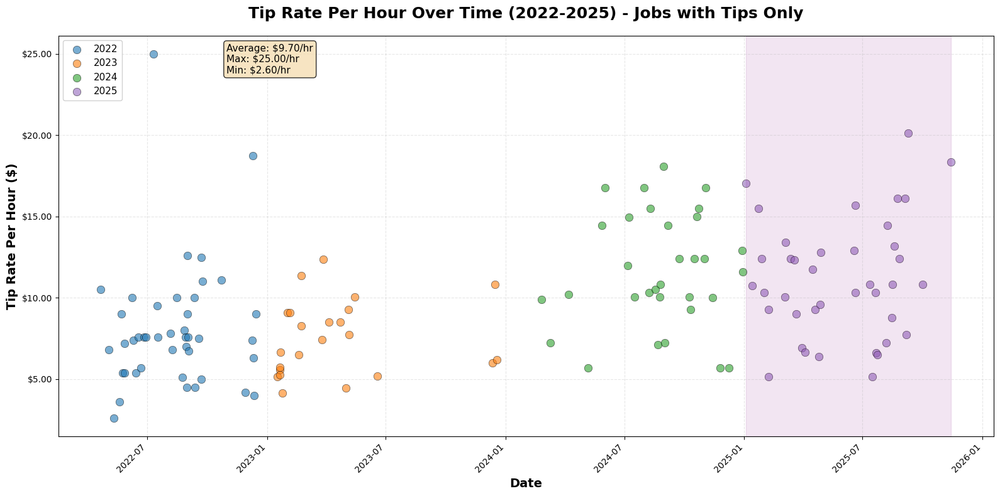

✓ Tip chart WITHOUT trend lines saved

Quarterly Average Tip Rates (Jobs with Tips Only):
YearQuarter  Tip_Hourly_Rate
    2022-Q2         6.786756
    2022-Q3         8.826264
    2022-Q4         8.678571
    2023-Q1         7.433573
    2023-Q2         7.679052
    2023-Q4         7.674524
    2024-Q1         8.570294
    2024-Q2        11.781827
    2024-Q3        12.163390
    2024-Q4        11.439861
    2025-Q1        11.119849
    2025-Q2        10.606569
    2025-Q3        11.093294
    2025-Q4        14.601111


In [11]:
# Prepare data - Tips per hour (EXCLUDE ZERO TIPS)
df['Tip_Hourly_Rate'] = df['Tip'] / df['Hours']
df_tip_clean = df[(df['Tip_Hourly_Rate'] > 0) & (df['Tip_Hourly_Rate'] < np.inf)].copy()  # Changed >= to >

# Extract year and quarter
df_tip_clean['Year'] = df_tip_clean['Date'].dt.year
df_tip_clean['Quarter'] = df_tip_clean['Date'].dt.to_period('Q').astype(str)
df_tip_clean['YearQuarter'] = df_tip_clean['Year'].astype(str) + '-Q' + df_tip_clean['Date'].dt.quarter.astype(str)

# Calculate quarterly averages for tips
quarterly_tip_avg = df_tip_clean.groupby('YearQuarter').agg({
    'Tip_Hourly_Rate': 'mean',
    'Date': 'mean'
}).reset_index()

# Color palette for years (purple for 2025)
colors = {2022: '#1f77b4', 2023: '#ff7f0e', 2024: '#2ca02c', 2025: '#9467bd'}
year_labels = {2022: '2022', 2023: '2023', 2024: '2024', 2025: '2025'}

# Calculate stats (ONLY non-zero tips)
avg_tip_rate = df_tip_clean['Tip_Hourly_Rate'].mean()
max_tip_rate = df_tip_clean['Tip_Hourly_Rate'].max()
min_tip_rate = df_tip_clean['Tip_Hourly_Rate'].min()

textstr = f'Average: ${avg_tip_rate:.2f}/hr\nMax: ${max_tip_rate:.2f}/hr\nMin: ${min_tip_rate:.2f}/hr'
props = dict(boxstyle='round', facecolor='wheat', alpha=0.8)

# ===== VERSION 1: WITH TREND LINE =====
fig, ax = plt.subplots(figsize=(16, 8))

# Plot each year with different colors
for year in sorted(df_tip_clean['Year'].unique()):
    year_data = df_tip_clean[df_tip_clean['Year'] == year]
    ax.scatter(year_data['Date'], year_data['Tip_Hourly_Rate'], 
               c=colors[year], label=year_labels[year], 
               s=80, alpha=0.6, edgecolors='black', linewidth=0.5)

# Add quarterly average trend line - dark red
ax.plot(quarterly_tip_avg['Date'], quarterly_tip_avg['Tip_Hourly_Rate'], 
        color='darkred', linewidth=2.5, label='Quarterly Average', 
        linestyle='--', alpha=0.8)

# Overall trend line (RECALCULATED without zeros)
df_sorted = df_tip_clean.sort_values('Date')
x_numeric = np.arange(len(df_sorted))
z = np.polyfit(x_numeric, df_sorted['Tip_Hourly_Rate'], 1)
p = np.poly1d(z)

ax.plot(df_sorted['Date'], p(x_numeric), 
        color='red', linewidth=3, label='Overall Trend', alpha=0.7)

# Styling
ax.set_title('Tip Rate Per Hour Over Time (2022-2025) - Jobs with Tips Only', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Date', fontsize=14, fontweight='bold')
ax.set_ylabel('Tip Rate Per Hour ($)', fontsize=14, fontweight='bold')

# Format y-axis to show dollars
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.2f}'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--')

# Rotate x-axis labels
plt.xticks(rotation=45, ha='right')

# Add legend on the left
ax.legend(loc='upper left', fontsize=11, framealpha=0.9)

# Add stats box to the right of legend
ax.text(0.18, 0.98, textstr, transform=ax.transAxes, fontsize=11,
        verticalalignment='top', bbox=props)

# Highlight 2025 period
if 2025 in df_tip_clean['Year'].values:
    ax.axvspan(df_tip_clean[df_tip_clean['Year'] == 2025]['Date'].min(), 
               df_tip_clean[df_tip_clean['Year'] == 2025]['Date'].max(), 
               alpha=0.1, color='purple')

plt.tight_layout()
plt.savefig('../visualizations/tip_rate_WITH_trendline.png', 
            dpi=300, bbox_inches='tight')
plt.show()

print("✓ Tip chart WITH trend line saved")
print(f"Note: Excluded {len(df[df['Tip'] == 0])} jobs with zero tips")

# ===== VERSION 2: WITHOUT TREND LINE =====
fig, ax = plt.subplots(figsize=(16, 8))

# Plot each year with different colors
for year in sorted(df_tip_clean['Year'].unique()):
    year_data = df_tip_clean[df_tip_clean['Year'] == year]
    ax.scatter(year_data['Date'], year_data['Tip_Hourly_Rate'], 
               c=colors[year], label=year_labels[year], 
               s=80, alpha=0.6, edgecolors='black', linewidth=0.5)

# Styling
ax.set_title('Tip Rate Per Hour Over Time (2022-2025) - Jobs with Tips Only', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Date', fontsize=14, fontweight='bold')
ax.set_ylabel('Tip Rate Per Hour ($)', fontsize=14, fontweight='bold')

# Format y-axis
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.2f}'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--')

# Rotate x-axis labels
plt.xticks(rotation=45, ha='right')

# Add legend on the left
ax.legend(loc='upper left', fontsize=11, framealpha=0.9)

# Add stats box to the right of legend
ax.text(0.18, 0.98, textstr, transform=ax.transAxes, fontsize=11,
        verticalalignment='top', bbox=props)

# Highlight 2025 period
if 2025 in df_tip_clean['Year'].values:
    ax.axvspan(df_tip_clean[df_tip_clean['Year'] == 2025]['Date'].min(), 
               df_tip_clean[df_tip_clean['Year'] == 2025]['Date'].max(), 
               alpha=0.1, color='purple')

plt.tight_layout()
plt.savefig('../visualizations/tip_rate_NO_trendline.png', 
            dpi=300, bbox_inches='tight')
plt.show()

print("✓ Tip chart WITHOUT trend lines saved")

# Display quarterly breakdown
print("\nQuarterly Average Tip Rates (Jobs with Tips Only):")
print(quarterly_tip_avg[['YearQuarter', 'Tip_Hourly_Rate']].to_string(index=False))

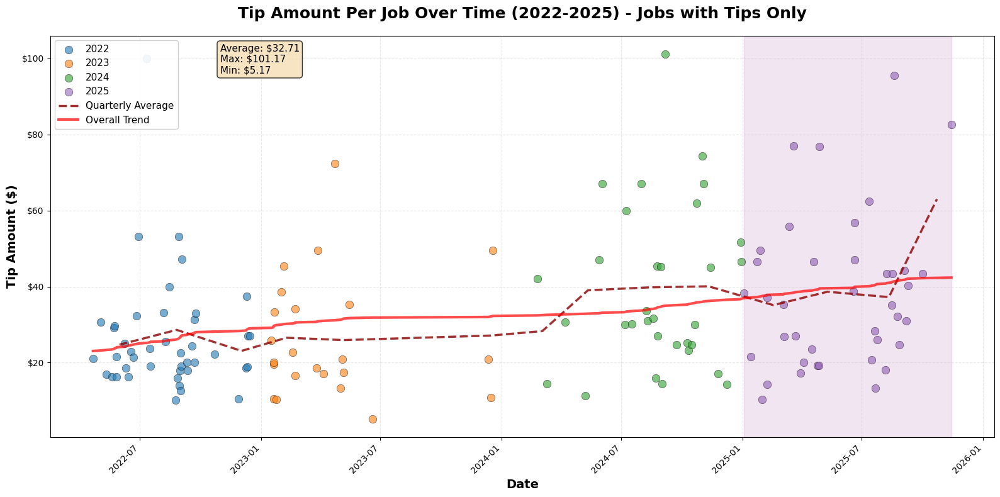

✓ Tip amount per job chart WITH trend line saved
Note: 137 jobs included (excluded 347 jobs with zero tips)


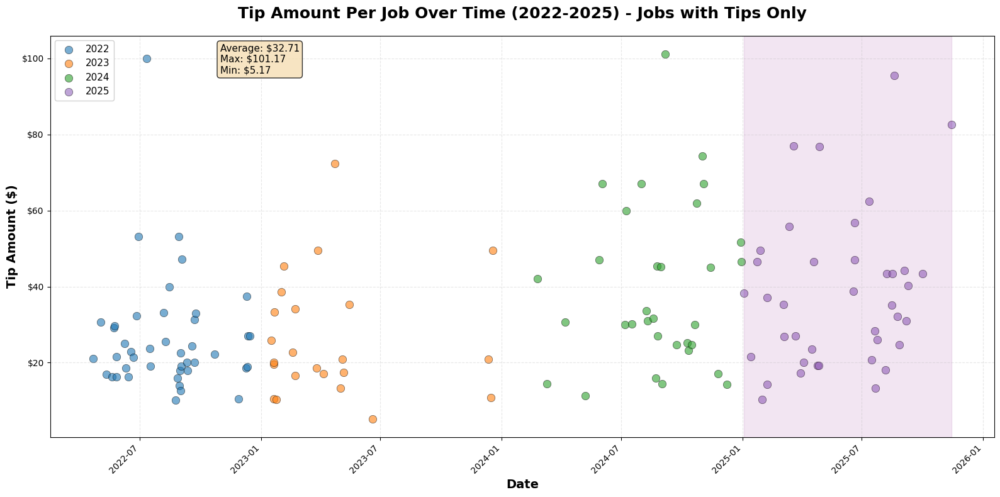

✓ Tip amount per job chart WITHOUT trend lines saved

Quarterly Average Tip Amounts Per Job (Jobs with Tips Only):
YearQuarter       Tip
    2022-Q2 24.722000
    2022-Q3 28.608571
    2022-Q4 23.085714
    2023-Q1 26.543077
    2023-Q2 25.928571
    2023-Q4 27.120000
    2024-Q1 28.290000
    2024-Q2 39.022500
    2024-Q3 39.801429
    2024-Q4 40.072500
    2025-Q1 35.128462
    2025-Q2 38.645556
    2025-Q3 37.234667
    2025-Q4 62.995000


In [12]:
# Prepare data - Tip amount per job (EXCLUDE ZERO TIPS)
df_tip_job = df[df['Tip'] > 0].copy()

# Extract year and quarter
df_tip_job['Year'] = df_tip_job['Date'].dt.year
df_tip_job['Quarter'] = df_tip_job['Date'].dt.to_period('Q').astype(str)
df_tip_job['YearQuarter'] = df_tip_job['Year'].astype(str) + '-Q' + df_tip_job['Date'].dt.quarter.astype(str)

# Calculate quarterly averages for tip amounts
quarterly_tip_job_avg = df_tip_job.groupby('YearQuarter').agg({
    'Tip': 'mean',
    'Date': 'mean'
}).reset_index()

# Color palette for years (purple for 2025)
colors = {2022: '#1f77b4', 2023: '#ff7f0e', 2024: '#2ca02c', 2025: '#9467bd'}
year_labels = {2022: '2022', 2023: '2023', 2024: '2024', 2025: '2025'}

# Calculate stats (ONLY non-zero tips)
avg_tip = df_tip_job['Tip'].mean()
max_tip = df_tip_job['Tip'].max()
min_tip = df_tip_job['Tip'].min()

textstr = f'Average: ${avg_tip:.2f}\nMax: ${max_tip:.2f}\nMin: ${min_tip:.2f}'
props = dict(boxstyle='round', facecolor='wheat', alpha=0.8)

# ===== VERSION 1: WITH TREND LINE =====
fig, ax = plt.subplots(figsize=(16, 8))

# Plot each year with different colors
for year in sorted(df_tip_job['Year'].unique()):
    year_data = df_tip_job[df_tip_job['Year'] == year]
    ax.scatter(year_data['Date'], year_data['Tip'], 
               c=colors[year], label=year_labels[year], 
               s=80, alpha=0.6, edgecolors='black', linewidth=0.5)

# Add quarterly average trend line - dark red
ax.plot(quarterly_tip_job_avg['Date'], quarterly_tip_job_avg['Tip'], 
        color='darkred', linewidth=2.5, label='Quarterly Average', 
        linestyle='--', alpha=0.8)

# Overall trend line
df_sorted = df_tip_job.sort_values('Date')
x_numeric = np.arange(len(df_sorted))
z = np.polyfit(x_numeric, df_sorted['Tip'], 1)
p = np.poly1d(z)

ax.plot(df_sorted['Date'], p(x_numeric), 
        color='red', linewidth=3, label='Overall Trend', alpha=0.7)

# Styling
ax.set_title('Tip Amount Per Job Over Time (2022-2025) - Jobs with Tips Only', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Date', fontsize=14, fontweight='bold')
ax.set_ylabel('Tip Amount ($)', fontsize=14, fontweight='bold')

# Format y-axis to show dollars
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--')

# Rotate x-axis labels
plt.xticks(rotation=45, ha='right')

# Add legend on the left
ax.legend(loc='upper left', fontsize=11, framealpha=0.9)

# Add stats box to the right of legend
ax.text(0.18, 0.98, textstr, transform=ax.transAxes, fontsize=11,
        verticalalignment='top', bbox=props)

# Highlight 2025 period
if 2025 in df_tip_job['Year'].values:
    ax.axvspan(df_tip_job[df_tip_job['Year'] == 2025]['Date'].min(), 
               df_tip_job[df_tip_job['Year'] == 2025]['Date'].max(), 
               alpha=0.1, color='purple')

plt.tight_layout()
plt.savefig('../visualizations/tip_amount_per_job_WITH_trendline.png', 
            dpi=300, bbox_inches='tight')
plt.show()

print("✓ Tip amount per job chart WITH trend line saved")
print(f"Note: {len(df_tip_job)} jobs included (excluded {len(df[df['Tip'] == 0])} jobs with zero tips)")

# ===== VERSION 2: WITHOUT TREND LINE =====
fig, ax = plt.subplots(figsize=(16, 8))

# Plot each year with different colors
for year in sorted(df_tip_job['Year'].unique()):
    year_data = df_tip_job[df_tip_job['Year'] == year]
    ax.scatter(year_data['Date'], year_data['Tip'], 
               c=colors[year], label=year_labels[year], 
               s=80, alpha=0.6, edgecolors='black', linewidth=0.5)

# Styling
ax.set_title('Tip Amount Per Job Over Time (2022-2025) - Jobs with Tips Only', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Date', fontsize=14, fontweight='bold')
ax.set_ylabel('Tip Amount ($)', fontsize=14, fontweight='bold')

# Format y-axis
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--')

# Rotate x-axis labels
plt.xticks(rotation=45, ha='right')

# Add legend on the left
ax.legend(loc='upper left', fontsize=11, framealpha=0.9)

# Add stats box to the right of legend
ax.text(0.18, 0.98, textstr, transform=ax.transAxes, fontsize=11,
        verticalalignment='top', bbox=props)

# Highlight 2025 period
if 2025 in df_tip_job['Year'].values:
    ax.axvspan(df_tip_job[df_tip_job['Year'] == 2025]['Date'].min(), 
               df_tip_job[df_tip_job['Year'] == 2025]['Date'].max(), 
               alpha=0.1, color='purple')

plt.tight_layout()
plt.savefig('../visualizations/tip_amount_per_job_NO_trendline.png', 
            dpi=300, bbox_inches='tight')
plt.show()

print("✓ Tip amount per job chart WITHOUT trend lines saved")

# Display quarterly breakdown
print("\nQuarterly Average Tip Amounts Per Job (Jobs with Tips Only):")
print(quarterly_tip_job_avg[['YearQuarter', 'Tip']].to_string(index=False))

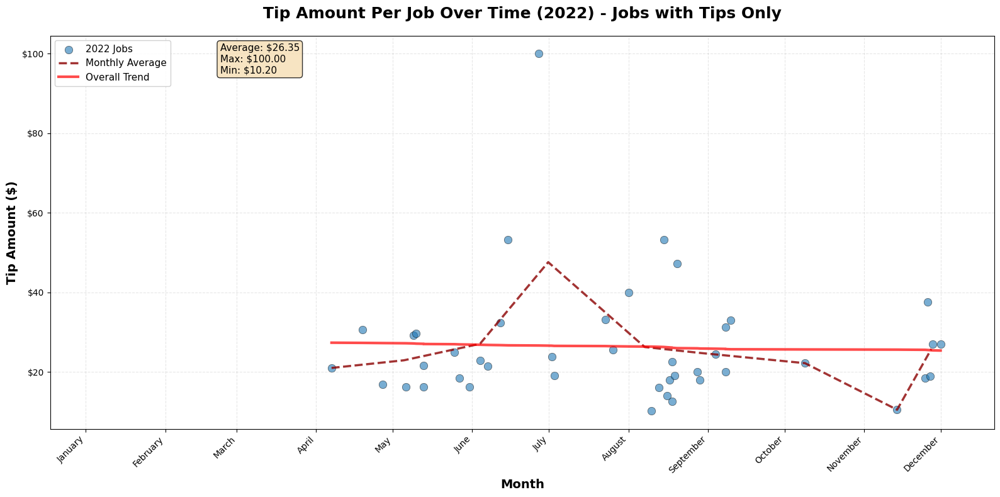

✓ Tip amount chart for 2022 saved


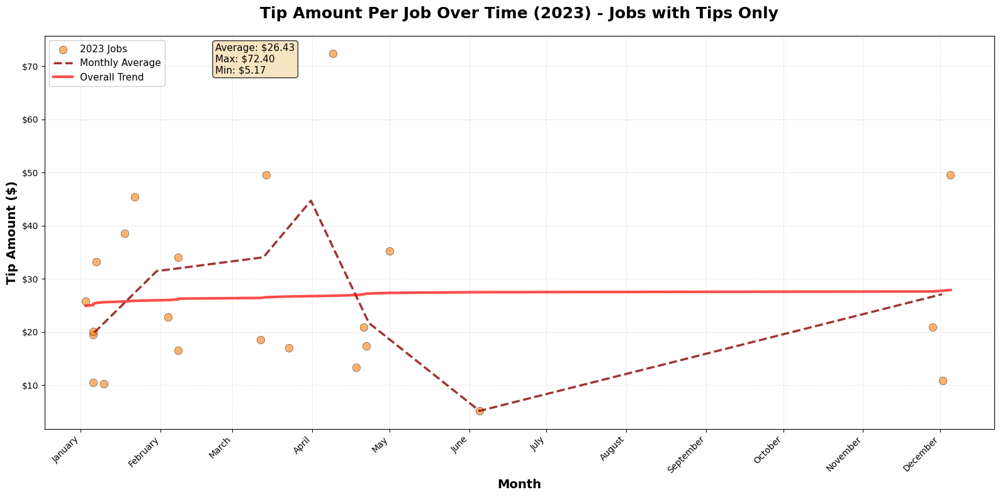

✓ Tip amount chart for 2023 saved


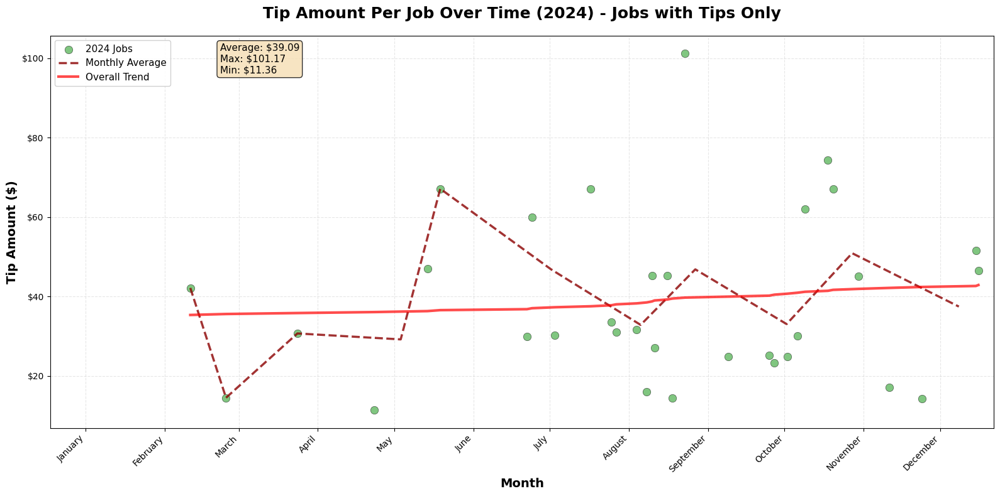

✓ Tip amount chart for 2024 saved


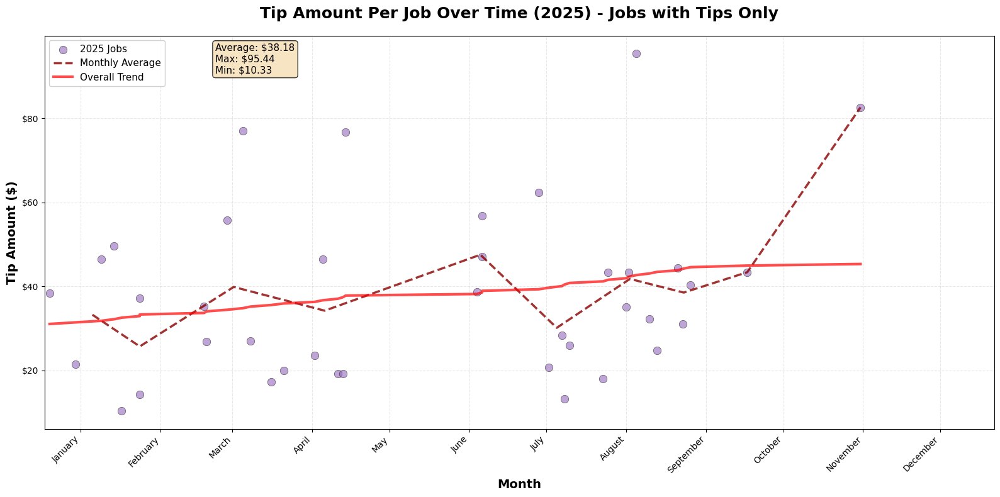

✓ Tip amount chart for 2025 saved

✓ All individual year tip amount charts created!


In [13]:
# Prepare data - Tip amount per job (EXCLUDE ZERO TIPS)
df_tip_job = df[df['Tip'] > 0].copy()

# Extract year and month
df_tip_job['Year'] = df_tip_job['Date'].dt.year
df_tip_job['Month'] = df_tip_job['Date'].dt.month
df_tip_job['Month_Name'] = df_tip_job['Date'].dt.strftime('%B')
df_tip_job['Year_Month'] = df_tip_job['Date'].dt.to_period('M')

# Calculate monthly averages
monthly_tip_avg = df_tip_job.groupby(['Year', 'Year_Month']).agg({
    'Tip': 'mean',
    'Date': 'mean'
}).reset_index()

# Color for each year's dots
year_colors = {2022: '#1f77b4', 2023: '#ff7f0e', 2024: '#2ca02c', 2025: '#9467bd'}

# Create individual chart for each year
for year in sorted(df_tip_job['Year'].unique()):
    year_data = df_tip_job[df_tip_job['Year'] == year]
    year_monthly = monthly_tip_avg[monthly_tip_avg['Year'] == year]
    
    # Calculate stats for this year
    avg_tip = year_data['Tip'].mean()
    max_tip = year_data['Tip'].max()
    min_tip = year_data['Tip'].min()
    
    textstr = f'Average: ${avg_tip:.2f}\nMax: ${max_tip:.2f}\nMin: ${min_tip:.2f}'
    props = dict(boxstyle='round', facecolor='wheat', alpha=0.8)
    
    # Create figure
    fig, ax = plt.subplots(figsize=(16, 8))
    
    # Plot dots for this year
    ax.scatter(year_data['Date'], year_data['Tip'], 
               c=year_colors[year], s=80, alpha=0.6, 
               edgecolors='black', linewidth=0.5, label=f'{year} Jobs')
    
    # Add monthly average trend line
    ax.plot(year_monthly['Date'], year_monthly['Tip'], 
            color='darkred', linewidth=2.5, label='Monthly Average', 
            linestyle='--', alpha=0.8)
    
    # Overall trend line for the year
    year_sorted = year_data.sort_values('Date')
    x_numeric = np.arange(len(year_sorted))
    z = np.polyfit(x_numeric, year_sorted['Tip'], 1)
    p = np.poly1d(z)
    
    ax.plot(year_sorted['Date'], p(x_numeric), 
            color='red', linewidth=3, label='Overall Trend', alpha=0.7)
    
    # Styling
    ax.set_title(f'Tip Amount Per Job Over Time ({year}) - Jobs with Tips Only', 
                 fontsize=18, fontweight='bold', pad=20)
    ax.set_xlabel('Month', fontsize=14, fontweight='bold')
    ax.set_ylabel('Tip Amount ($)', fontsize=14, fontweight='bold')
    
    # Format y-axis to show dollars
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))
    
    # Set x-axis limits with padding
    start_date = pd.Timestamp(f'{year}-01-01')
    end_date = pd.Timestamp(f'{year+1}-01-05')
    ax.set_xlim(start_date, end_date)
    
    # Manually set the month labels
    month_names = ['January', 'February', 'March', 'April', 'May', 'June', 
                   'July', 'August', 'September', 'October', 'November', 'December']
    
    # Create tick positions at the 15th of each month
    tick_dates = [pd.Timestamp(f'{year}-{m:02d}-15') for m in range(1, 13)]
    
    ax.set_xticks(tick_dates)
    ax.set_xticklabels(month_names, rotation=45, ha='right')
    
    # Add gridlines
    ax.grid(True, alpha=0.3, linestyle='--')
    
    # Add legend
    ax.legend(loc='upper left', fontsize=11, framealpha=0.9)
    
    # Add stats box
    ax.text(0.18, 0.98, textstr, transform=ax.transAxes, fontsize=11,
            verticalalignment='top', bbox=props)
    
    plt.tight_layout()
    plt.savefig(f'../visualizations/tip_amount_per_job_{year}.png', 
                dpi=300, bbox_inches='tight')
    plt.show()
    
    print(f"✓ Tip amount chart for {year} saved")

print("\n✓ All individual year tip amount charts created!")

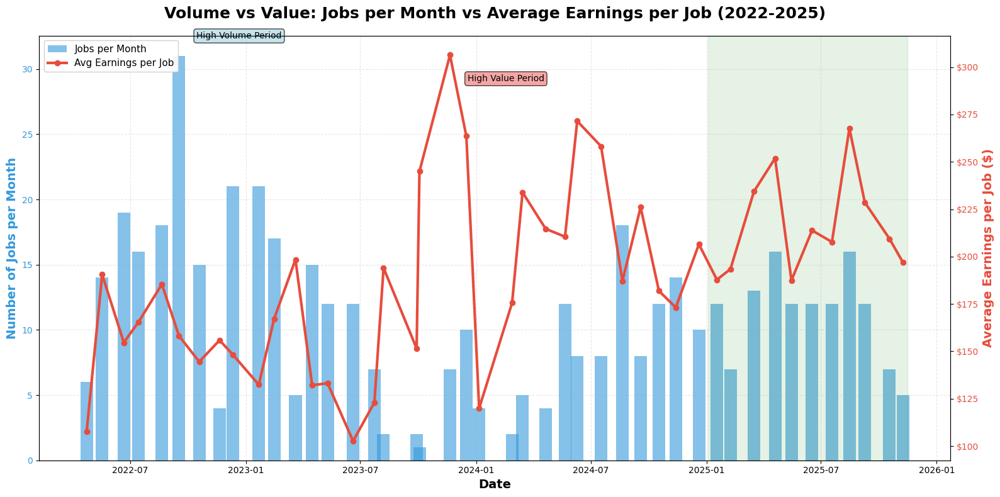

✓ Volume vs Value chart saved

VOLUME VS VALUE SUMMARY
Highest volume month: 2022-09 - 31 jobs
Highest value month: 2023-11 - $306.36 per job

Total trend:
  Early period avg jobs/month: 17.3
  Recent period avg jobs/month: 10.7
  Early period avg earnings/job: $160.33
  Recent period avg earnings/job: $220.70


In [14]:
# Prepare data
df_clean = df[df['Earnings'] > 0].copy()
df_clean['Year'] = df_clean['Date'].dt.year
df_clean['Year_Month'] = df_clean['Date'].dt.to_period('M')

# Calculate monthly metrics
monthly_metrics = df_clean.groupby('Year_Month').agg({
    'Earnings': 'count',  # Number of jobs
    'Total': 'mean',      # Average earnings per job
    'Date': 'mean'        # For plotting
}).reset_index()

monthly_metrics.columns = ['Year_Month', 'Jobs_Count', 'Avg_Earnings_Per_Job', 'Date']

# Create figure with dual y-axes
fig, ax1 = plt.subplots(figsize=(16, 8))

# Color scheme
bar_color = '#3498db'  # Blue for volume
line_color = '#e74c3c'  # Red for value

# Plot bars - Jobs per month (left y-axis)
ax1.bar(monthly_metrics['Date'], monthly_metrics['Jobs_Count'], 
        color=bar_color, alpha=0.6, width=20, label='Jobs per Month')

ax1.set_xlabel('Date', fontsize=14, fontweight='bold')
ax1.set_ylabel('Number of Jobs per Month', fontsize=14, fontweight='bold', color=bar_color)
ax1.tick_params(axis='y', labelcolor=bar_color)

# Create second y-axis for average earnings
ax2 = ax1.twinx()

# Plot line - Average earnings per job (right y-axis)
ax2.plot(monthly_metrics['Date'], monthly_metrics['Avg_Earnings_Per_Job'], 
         color=line_color, linewidth=3, marker='o', markersize=6, 
         label='Avg Earnings per Job')

ax2.set_ylabel('Average Earnings per Job ($)', fontsize=14, fontweight='bold', color=line_color)
ax2.tick_params(axis='y', labelcolor=line_color)

# Format right y-axis to show dollars
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Title
ax1.set_title('Volume vs Value: Jobs per Month vs Average Earnings per Job (2022-2025)', 
              fontsize=18, fontweight='bold', pad=20)

# Grid
ax1.grid(True, alpha=0.3, linestyle='--')

# Rotate x-axis labels
plt.xticks(rotation=45, ha='right')

# Add legends from both axes
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', fontsize=11, framealpha=0.9)

# Highlight strategic shift period (2025)
if 2025 in df_clean['Year'].values:
    shift_start = df_clean[df_clean['Year'] == 2025]['Date'].min()
    shift_end = df_clean[df_clean['Year'] == 2025]['Date'].max()
    ax1.axvspan(shift_start, shift_end, alpha=0.1, color='green', label='Strategic Optimization')

# Add annotation showing the shift
max_volume_month = monthly_metrics.loc[monthly_metrics['Jobs_Count'].idxmax()]
max_value_month = monthly_metrics.loc[monthly_metrics['Avg_Earnings_Per_Job'].idxmax()]

ax1.annotate('High Volume Period', 
             xy=(max_volume_month['Date'], max_volume_month['Jobs_Count']),
             xytext=(20, 20), textcoords='offset points',
             bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.7),
             fontsize=10, ha='left')

ax2.annotate('High Value Period', 
             xy=(max_value_month['Date'], max_value_month['Avg_Earnings_Per_Job']),
             xytext=(20, -30), textcoords='offset points',
             bbox=dict(boxstyle='round', facecolor='lightcoral', alpha=0.7),
             fontsize=10, ha='left')

plt.tight_layout()
plt.savefig('../visualizations/volume_vs_value.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Volume vs Value chart saved")

# Print summary stats
print("\n" + "="*60)
print("VOLUME VS VALUE SUMMARY")
print("="*60)
print(f"Highest volume month: {max_volume_month['Year_Month']} - {int(max_volume_month['Jobs_Count'])} jobs")
print(f"Highest value month: {max_value_month['Year_Month']} - ${max_value_month['Avg_Earnings_Per_Job']:.2f} per job")
print(f"\nTotal trend:")
print(f"  Early period avg jobs/month: {monthly_metrics.head(6)['Jobs_Count'].mean():.1f}")
print(f"  Recent period avg jobs/month: {monthly_metrics.tail(6)['Jobs_Count'].mean():.1f}")
print(f"  Early period avg earnings/job: ${monthly_metrics.head(6)['Avg_Earnings_Per_Job'].mean():.2f}")
print(f"  Recent period avg earnings/job: ${monthly_metrics.tail(6)['Avg_Earnings_Per_Job'].mean():.2f}")

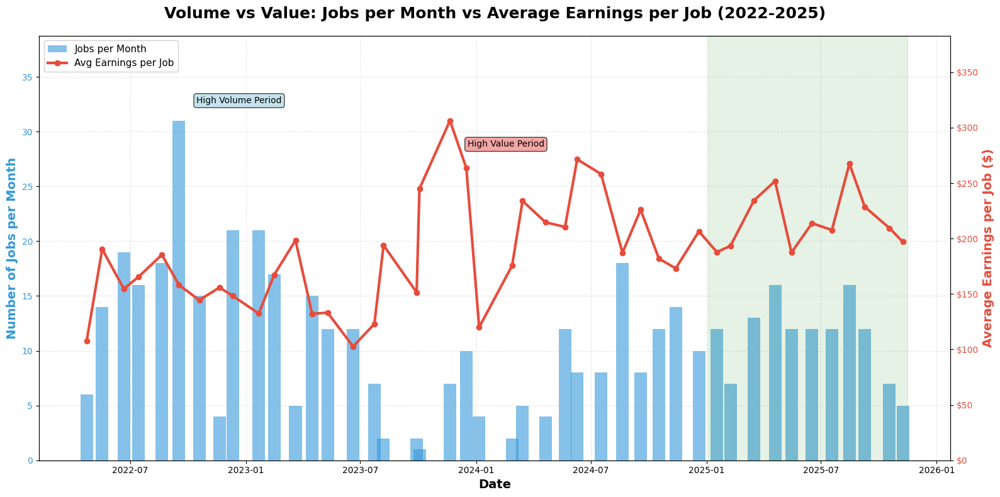

✓ Volume vs Value chart saved

VOLUME VS VALUE SUMMARY
Highest volume month: 2022-09 - 31 jobs
Highest value month: 2023-11 - $306.36 per job

Total trend:
  Early period avg jobs/month: 17.3
  Recent period avg jobs/month: 10.7
  Early period avg earnings/job: $160.33
  Recent period avg earnings/job: $220.70


In [15]:
# Prepare data
df_clean = df[df['Earnings'] > 0].copy()
df_clean['Year'] = df_clean['Date'].dt.year
df_clean['Year_Month'] = df_clean['Date'].dt.to_period('M')

# Calculate monthly metrics
monthly_metrics = df_clean.groupby('Year_Month').agg({
    'Earnings': 'count',  # Number of jobs
    'Total': 'mean',      # Average earnings per job
    'Date': 'mean'        # For plotting
}).reset_index()

monthly_metrics.columns = ['Year_Month', 'Jobs_Count', 'Avg_Earnings_Per_Job', 'Date']

# Create figure with dual y-axes
fig, ax1 = plt.subplots(figsize=(16, 8))

# Color scheme
bar_color = '#3498db'  # Blue for volume
line_color = '#e74c3c'  # Red for value

# Plot bars - Jobs per month (left y-axis)
ax1.bar(monthly_metrics['Date'], monthly_metrics['Jobs_Count'], 
        color=bar_color, alpha=0.6, width=20, label='Jobs per Month')

ax1.set_xlabel('Date', fontsize=14, fontweight='bold')
ax1.set_ylabel('Number of Jobs per Month', fontsize=14, fontweight='bold', color=bar_color)
ax1.tick_params(axis='y', labelcolor=bar_color)

# Add extra space at the top of left y-axis
ax1.set_ylim(0, monthly_metrics['Jobs_Count'].max() * 1.25)  # 25% extra space

# Create second y-axis for average earnings
ax2 = ax1.twinx()

# Plot line - Average earnings per job (right y-axis)
ax2.plot(monthly_metrics['Date'], monthly_metrics['Avg_Earnings_Per_Job'], 
         color=line_color, linewidth=3, marker='o', markersize=6, 
         label='Avg Earnings per Job')

ax2.set_ylabel('Average Earnings per Job ($)', fontsize=14, fontweight='bold', color=line_color)
ax2.tick_params(axis='y', labelcolor=line_color)

# Add extra space at the top of right y-axis
ax2.set_ylim(0, monthly_metrics['Avg_Earnings_Per_Job'].max() * 1.25)  # 25% extra space

# Format right y-axis to show dollars
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Title
ax1.set_title('Volume vs Value: Jobs per Month vs Average Earnings per Job (2022-2025)', 
              fontsize=18, fontweight='bold', pad=20)

# Grid
ax1.grid(True, alpha=0.3, linestyle='--')

# Rotate x-axis labels
plt.xticks(rotation=45, ha='right')

# Add legends from both axes
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', fontsize=11, framealpha=0.9)

# Highlight strategic shift period (2025)
if 2025 in df_clean['Year'].values:
    shift_start = df_clean[df_clean['Year'] == 2025]['Date'].min()
    shift_end = df_clean[df_clean['Year'] == 2025]['Date'].max()
    ax1.axvspan(shift_start, shift_end, alpha=0.1, color='green', label='Strategic Optimization')

# Add annotation showing the shift
max_volume_month = monthly_metrics.loc[monthly_metrics['Jobs_Count'].idxmax()]
max_value_month = monthly_metrics.loc[monthly_metrics['Avg_Earnings_Per_Job'].idxmax()]

ax1.annotate('High Volume Period', 
             xy=(max_volume_month['Date'], max_volume_month['Jobs_Count']),
             xytext=(20, 20), textcoords='offset points',
             bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.7),
             fontsize=10, ha='left')

ax2.annotate('High Value Period', 
             xy=(max_value_month['Date'], max_value_month['Avg_Earnings_Per_Job']),
             xytext=(20, -30), textcoords='offset points',
             bbox=dict(boxstyle='round', facecolor='lightcoral', alpha=0.7),
             fontsize=10, ha='left')

plt.tight_layout()
plt.savefig('../visualizations/volume_vs_value.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Volume vs Value chart saved")

# Print summary stats
print("\n" + "="*60)
print("VOLUME VS VALUE SUMMARY")
print("="*60)
print(f"Highest volume month: {max_volume_month['Year_Month']} - {int(max_volume_month['Jobs_Count'])} jobs")
print(f"Highest value month: {max_value_month['Year_Month']} - ${max_value_month['Avg_Earnings_Per_Job']:.2f} per job")
print(f"\nTotal trend:")
print(f"  Early period avg jobs/month: {monthly_metrics.head(6)['Jobs_Count'].mean():.1f}")
print(f"  Recent period avg jobs/month: {monthly_metrics.tail(6)['Jobs_Count'].mean():.1f}")
print(f"  Early period avg earnings/job: ${monthly_metrics.head(6)['Avg_Earnings_Per_Job'].mean():.2f}")
print(f"  Recent period avg earnings/job: ${monthly_metrics.tail(6)['Avg_Earnings_Per_Job'].mean():.2f}")

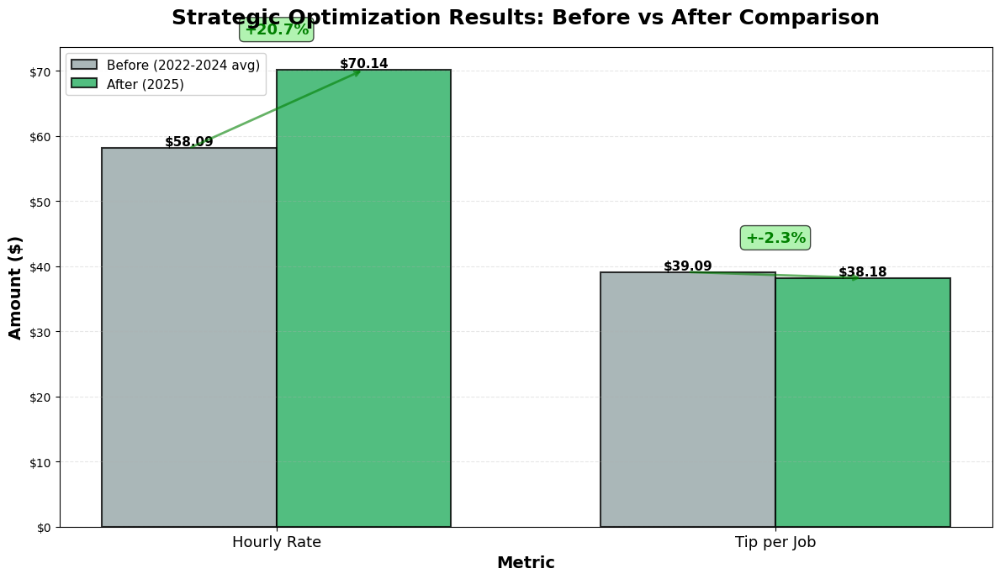

✓ Graph 3: Before/After Comparison saved

SUMMARY OF STRATEGIC OPTIMIZATION
Hourly Rate:
  Before (2022-2024): $58.09/hr
  After (2025): $70.14/hr
  Increase: +20.7%

Tip per Job:
  Before (2024): $39.09
  After (2025): $38.18
  Increase: +-2.3%


In [16]:
# Recalculate all metrics for the comparison
df['Gross_Hourly_Rate'] = df['Earnings'] / df['Hours']
df_clean = df[(df['Gross_Hourly_Rate'] > 0) & (df['Gross_Hourly_Rate'] < np.inf)].copy()
df_clean['Year'] = df_clean['Date'].dt.year

# Hourly rate metrics
yearly_hourly_rate = df_clean.groupby('Year')['Gross_Hourly_Rate'].mean().reset_index()
rate_2022_2024 = yearly_hourly_rate[yearly_hourly_rate['Year'].isin([2022, 2023, 2024])]['Gross_Hourly_Rate'].mean()
rate_2025 = yearly_hourly_rate[yearly_hourly_rate['Year'] == 2025]['Gross_Hourly_Rate'].values[0]
pct_increase_rate = ((rate_2025 - rate_2022_2024) / rate_2022_2024) * 100

# Tip metrics
df_tips = df[df['Tip'] > 0].copy()
df_tips['Year'] = df_tips['Date'].dt.year
yearly_tips = df_tips.groupby('Year')['Tip'].mean().reset_index()
tip_2024 = yearly_tips[yearly_tips['Year'] == 2024]['Tip'].values[0]
tip_2025 = yearly_tips[yearly_tips['Year'] == 2025]['Tip'].values[0]
pct_increase_tips = ((tip_2025 - tip_2024) / tip_2024) * 100

# Prepare data for comparison
metrics = {
    'Metric': ['Hourly Rate', 'Tip per Job'],
    'Before': [rate_2022_2024, tip_2024],
    'After': [rate_2025, tip_2025],
    'Increase': [pct_increase_rate, pct_increase_tips]
}

comparison_df = pd.DataFrame(metrics)

# Create figure with grouped bars
fig, ax = plt.subplots(figsize=(12, 7))

x = np.arange(len(comparison_df))
width = 0.35

# Plot bars
bars1 = ax.bar(x - width/2, comparison_df['Before'], width, 
               label='Before (2022-2024 avg)', color='#95a5a6', alpha=0.8, 
               edgecolor='black', linewidth=1.5)
bars2 = ax.bar(x + width/2, comparison_df['After'], width, 
               label='After (2025)', color='#27ae60', alpha=0.8, 
               edgecolor='black', linewidth=1.5)

# Add value labels on bars
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'${height:.2f}',
                ha='center', va='bottom', fontsize=11, fontweight='bold')

# Add percentage increase labels above
for i, (before, after, pct) in enumerate(zip(comparison_df['Before'], 
                                               comparison_df['After'], 
                                               comparison_df['Increase'])):
    # Draw arrow
    ax.annotate('', xy=(i + width/2, after), xytext=(i - width/2, before),
                arrowprops=dict(arrowstyle='->', color='green', lw=2, alpha=0.6))
    
    # Add percentage text
    mid_y = (before + after) / 2 + 5
    ax.text(i, after + 5, f'+{pct:.1f}%', 
            ha='center', va='bottom', fontsize=13, fontweight='bold', 
            color='green',
            bbox=dict(boxstyle='round', facecolor='lightgreen', alpha=0.7))

# Styling
ax.set_title('Strategic Optimization Results: Before vs After Comparison', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Metric', fontsize=14, fontweight='bold')
ax.set_ylabel('Amount ($)', fontsize=14, fontweight='bold')

# Format y-axis
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Set x-axis labels
ax.set_xticks(x)
ax.set_xticklabels(comparison_df['Metric'], fontsize=13)

# Add legend
ax.legend(fontsize=11, loc='upper left', framealpha=0.9)

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--', axis='y')

plt.tight_layout()
plt.savefig('../visualizations/before_after_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Graph 3: Before/After Comparison saved")
print("\n" + "="*60)
print("SUMMARY OF STRATEGIC OPTIMIZATION")
print("="*60)
print(f"Hourly Rate:")
print(f"  Before (2022-2024): ${rate_2022_2024:.2f}/hr")
print(f"  After (2025): ${rate_2025:.2f}/hr")
print(f"  Increase: +{pct_increase_rate:.1f}%")
print(f"\nTip per Job:")
print(f"  Before (2024): ${tip_2024:.2f}")
print(f"  After (2025): ${tip_2025:.2f}")
print(f"  Increase: +{pct_increase_tips:.1f}%")
print("="*60)

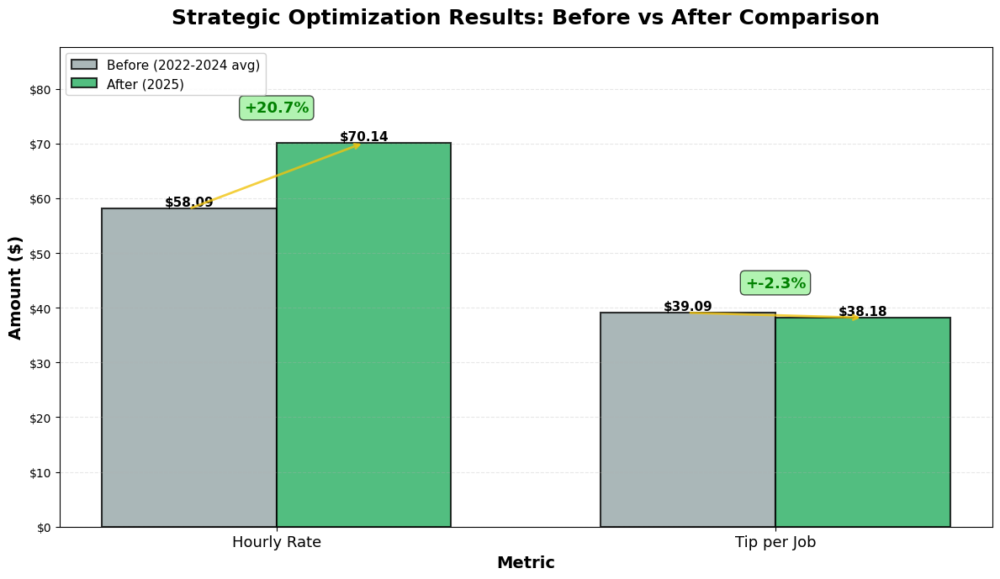

✓ Graph 3: Before/After Comparison saved

SUMMARY OF STRATEGIC OPTIMIZATION
Hourly Rate:
  Before (2022-2024): $58.09/hr
  After (2025): $70.14/hr
  Increase: +20.7%

Tip per Job:
  Before (2024): $39.09
  After (2025): $38.18
  Increase: +-2.3%


In [17]:
# Recalculate all metrics for the comparison
df['Gross_Hourly_Rate'] = df['Earnings'] / df['Hours']
df_clean = df[(df['Gross_Hourly_Rate'] > 0) & (df['Gross_Hourly_Rate'] < np.inf)].copy()
df_clean['Year'] = df_clean['Date'].dt.year

# Hourly rate metrics
yearly_hourly_rate = df_clean.groupby('Year')['Gross_Hourly_Rate'].mean().reset_index()
rate_2022_2024 = yearly_hourly_rate[yearly_hourly_rate['Year'].isin([2022, 2023, 2024])]['Gross_Hourly_Rate'].mean()
rate_2025 = yearly_hourly_rate[yearly_hourly_rate['Year'] == 2025]['Gross_Hourly_Rate'].values[0]
pct_increase_rate = ((rate_2025 - rate_2022_2024) / rate_2022_2024) * 100

# Tip metrics
df_tips = df[df['Tip'] > 0].copy()
df_tips['Year'] = df_tips['Date'].dt.year
yearly_tips = df_tips.groupby('Year')['Tip'].mean().reset_index()
tip_2024 = yearly_tips[yearly_tips['Year'] == 2024]['Tip'].values[0]
tip_2025 = yearly_tips[yearly_tips['Year'] == 2025]['Tip'].values[0]
pct_increase_tips = ((tip_2025 - tip_2024) / tip_2024) * 100

# Prepare data for comparison
metrics = {
    'Metric': ['Hourly Rate', 'Tip per Job'],
    'Before': [rate_2022_2024, tip_2024],
    'After': [rate_2025, tip_2025],
    'Increase': [pct_increase_rate, pct_increase_tips]
}

comparison_df = pd.DataFrame(metrics)

# Create figure with grouped bars
fig, ax = plt.subplots(figsize=(12, 7))

x = np.arange(len(comparison_df))
width = 0.35

# Plot bars
bars1 = ax.bar(x - width/2, comparison_df['Before'], width, 
               label='Before (2022-2024 avg)', color='#95a5a6', alpha=0.8, 
               edgecolor='black', linewidth=1.5)
bars2 = ax.bar(x + width/2, comparison_df['After'], width, 
               label='After (2025)', color='#27ae60', alpha=0.8, 
               edgecolor='black', linewidth=1.5)

# Add value labels on bars
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'${height:.2f}',
                ha='center', va='bottom', fontsize=11, fontweight='bold')

# Add percentage increase labels above
for i, (before, after, pct) in enumerate(zip(comparison_df['Before'], 
                                               comparison_df['After'], 
                                               comparison_df['Increase'])):
    # Draw arrow - CHANGED TO YELLOW
    ax.annotate('', xy=(i + width/2, after), xytext=(i - width/2, before),
                arrowprops=dict(arrowstyle='->', color='#f1c40f', lw=2, alpha=0.8))
    
    # Add percentage text
    mid_y = (before + after) / 2 + 5
    ax.text(i, after + 5, f'+{pct:.1f}%', 
            ha='center', va='bottom', fontsize=13, fontweight='bold', 
            color='green',
            bbox=dict(boxstyle='round', facecolor='lightgreen', alpha=0.7))

# Styling
ax.set_title('Strategic Optimization Results: Before vs After Comparison', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Metric', fontsize=14, fontweight='bold')
ax.set_ylabel('Amount ($)', fontsize=14, fontweight='bold')

# Format y-axis
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Add 25% breathing room at the top
max_value = comparison_df[['Before', 'After']].max().max()
ax.set_ylim(0, max_value * 1.25)

# Set x-axis labels
ax.set_xticks(x)
ax.set_xticklabels(comparison_df['Metric'], fontsize=13)

# Add legend
ax.legend(fontsize=11, loc='upper left', framealpha=0.9)

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--', axis='y')

plt.tight_layout()
plt.savefig('../visualizations/before_after_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Graph 3: Before/After Comparison saved")
print("\n" + "="*60)
print("SUMMARY OF STRATEGIC OPTIMIZATION")
print("="*60)
print(f"Hourly Rate:")
print(f"  Before (2022-2024): ${rate_2022_2024:.2f}/hr")
print(f"  After (2025): ${rate_2025:.2f}/hr")
print(f"  Increase: +{pct_increase_rate:.1f}%")
print(f"\nTip per Job:")
print(f"  Before (2024): ${tip_2024:.2f}")
print(f"  After (2025): ${tip_2025:.2f}")
print(f"  Increase: +{pct_increase_tips:.1f}%")
print("="*60)

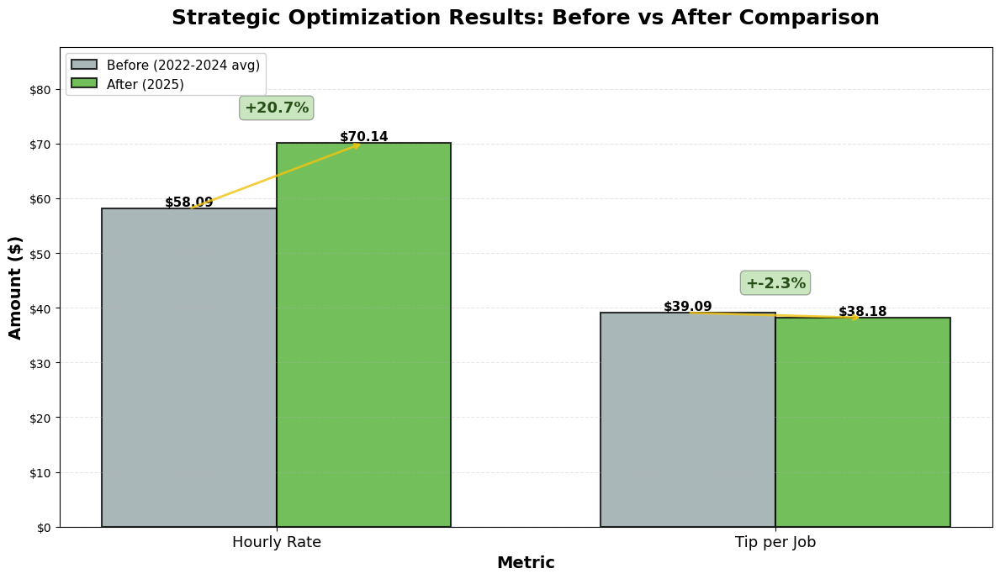

✓ Graph 3: Before/After Comparison saved (with TaskRabbit colors)


In [18]:
# Recalculate all metrics for the comparison
df['Gross_Hourly_Rate'] = df['Earnings'] / df['Hours']
df_clean = df[(df['Gross_Hourly_Rate'] > 0) & (df['Gross_Hourly_Rate'] < np.inf)].copy()
df_clean['Year'] = df_clean['Date'].dt.year

# Hourly rate metrics
yearly_hourly_rate = df_clean.groupby('Year')['Gross_Hourly_Rate'].mean().reset_index()
rate_2022_2024 = yearly_hourly_rate[yearly_hourly_rate['Year'].isin([2022, 2023, 2024])]['Gross_Hourly_Rate'].mean()
rate_2025 = yearly_hourly_rate[yearly_hourly_rate['Year'] == 2025]['Gross_Hourly_Rate'].values[0]
pct_increase_rate = ((rate_2025 - rate_2022_2024) / rate_2022_2024) * 100

# Tip metrics
df_tips = df[df['Tip'] > 0].copy()
df_tips['Year'] = df_tips['Date'].dt.year
yearly_tips = df_tips.groupby('Year')['Tip'].mean().reset_index()
tip_2024 = yearly_tips[yearly_tips['Year'] == 2024]['Tip'].values[0]
tip_2025 = yearly_tips[yearly_tips['Year'] == 2025]['Tip'].values[0]
pct_increase_tips = ((tip_2025 - tip_2024) / tip_2024) * 100

# Prepare data for comparison
metrics = {
    'Metric': ['Hourly Rate', 'Tip per Job'],
    'Before': [rate_2022_2024, tip_2024],
    'After': [rate_2025, tip_2025],
    'Increase': [pct_increase_rate, pct_increase_tips]
}

comparison_df = pd.DataFrame(metrics)

# Create figure with grouped bars
fig, ax = plt.subplots(figsize=(12, 7))

x = np.arange(len(comparison_df))
width = 0.35

# Plot bars - USING TASKRABBIT LIGHT GREEN
bars1 = ax.bar(x - width/2, comparison_df['Before'], width, 
               label='Before (2022-2024 avg)', color='#95a5a6', alpha=0.8, 
               edgecolor='black', linewidth=1.5)

bars2 = ax.bar(x + width/2, comparison_df['After'], width, 
               label='After (2025)', color='#50AF33', alpha=0.8, 
               edgecolor='black', linewidth=1.5)

# Add value labels on bars
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'${height:.2f}',
                ha='center', va='bottom', fontsize=11, fontweight='bold')

# Add percentage increase labels above
for i, (before, after, pct) in enumerate(zip(comparison_df['Before'], 
                                               comparison_df['After'], 
                                               comparison_df['Increase'])):
    # Draw arrow - yellow
    ax.annotate('', xy=(i + width/2, after), xytext=(i - width/2, before),
                arrowprops=dict(arrowstyle='->', color='#f1c40f', lw=2, alpha=0.8))
    
    # Add percentage text with TaskRabbit colors
    ax.text(i, after + 5, f'+{pct:.1f}%', 
            ha='center', va='bottom', fontsize=13, fontweight='bold', 
            color='#264F18',
            bbox=dict(boxstyle='round', facecolor='#50AF33', alpha=0.3))

# Styling
ax.set_title('Strategic Optimization Results: Before vs After Comparison', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Metric', fontsize=14, fontweight='bold')
ax.set_ylabel('Amount ($)', fontsize=14, fontweight='bold')

# Format y-axis
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Add 25% breathing room at the top
max_value = comparison_df[['Before', 'After']].max().max()
ax.set_ylim(0, max_value * 1.25)

# Set x-axis labels
ax.set_xticks(x)
ax.set_xticklabels(comparison_df['Metric'], fontsize=13)

# Add legend
ax.legend(fontsize=11, loc='upper left', framealpha=0.9)

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--', axis='y')

plt.tight_layout()
plt.savefig('../visualizations/before_after_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Graph 3: Before/After Comparison saved (with TaskRabbit colors)")

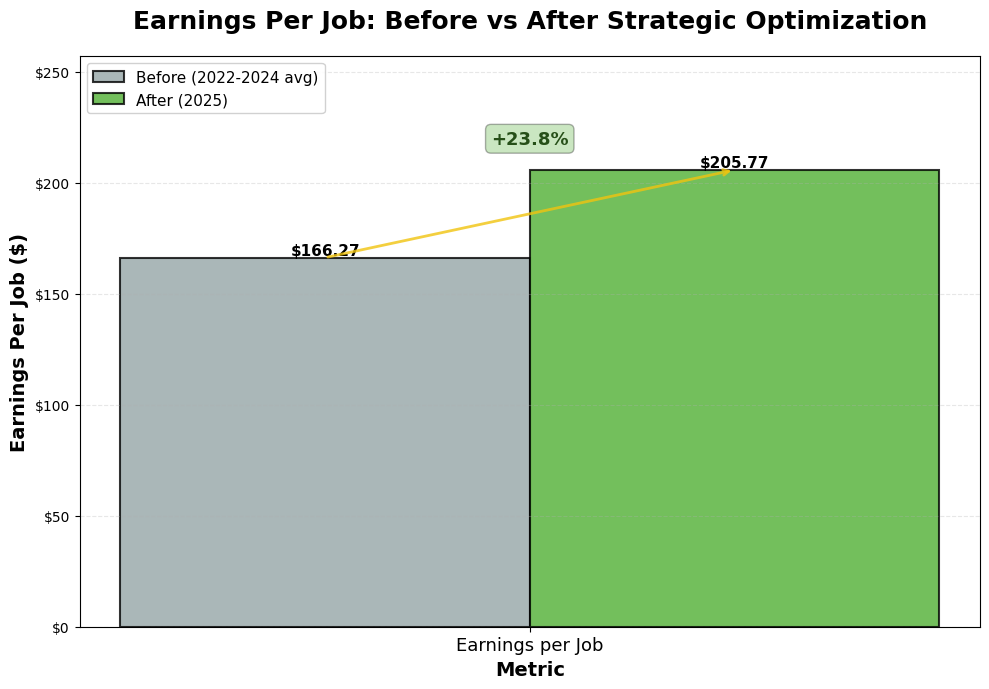

✓ Earnings per Job Comparison saved

EARNINGS PER JOB COMPARISON
Before (2022-2024): $166.27
After (2025): $205.77
Increase: +23.8%


In [19]:
# Calculate average earnings per job by year
df_clean = df[df['Earnings'] > 0].copy()
df_clean['Year'] = df_clean['Date'].dt.year

yearly_earnings = df_clean.groupby('Year')['Earnings'].mean().reset_index()

# Calculate before/after metrics
earnings_2022_2024 = yearly_earnings[yearly_earnings['Year'].isin([2022, 2023, 2024])]['Earnings'].mean()
earnings_2025 = yearly_earnings[yearly_earnings['Year'] == 2025]['Earnings'].values[0]
pct_increase_earnings = ((earnings_2025 - earnings_2022_2024) / earnings_2022_2024) * 100

# Prepare data for comparison
metrics = {
    'Metric': ['Earnings per Job'],
    'Before': [earnings_2022_2024],
    'After': [earnings_2025],
    'Increase': [pct_increase_earnings]
}

comparison_df = pd.DataFrame(metrics)

# Create figure
fig, ax = plt.subplots(figsize=(10, 7))

x = np.arange(len(comparison_df))
width = 0.35

# Plot bars - USING TASKRABBIT LIGHT GREEN
bars1 = ax.bar(x - width/2, comparison_df['Before'], width, 
               label='Before (2022-2024 avg)', color='#95a5a6', alpha=0.8, 
               edgecolor='black', linewidth=1.5)
bars2 = ax.bar(x + width/2, comparison_df['After'], width, 
               label='After (2025)', color='#50AF33', alpha=0.8,  # TaskRabbit light green
               edgecolor='black', linewidth=1.5)

# Add value labels on bars
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'${height:.2f}',
                ha='center', va='bottom', fontsize=11, fontweight='bold')

# Add percentage increase label
for i, (before, after, pct) in enumerate(zip(comparison_df['Before'], 
                                               comparison_df['After'], 
                                               comparison_df['Increase'])):
    # Draw arrow - yellow
    ax.annotate('', xy=(i + width/2, after), xytext=(i - width/2, before),
                arrowprops=dict(arrowstyle='->', color='#f1c40f', lw=2, alpha=0.8))
    
    # Add percentage text with light green background
    ax.text(i, after + 10, f'+{pct:.1f}%', 
            ha='center', va='bottom', fontsize=13, fontweight='bold', 
            color='#264F18',  # TaskRabbit dark green for text
            bbox=dict(boxstyle='round', facecolor='#50AF33', alpha=0.3))  # Light green background

# Styling
ax.set_title('Earnings Per Job: Before vs After Strategic Optimization', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Metric', fontsize=14, fontweight='bold')
ax.set_ylabel('Earnings Per Job ($)', fontsize=14, fontweight='bold')

# Format y-axis
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Add 25% breathing room at the top
max_value = comparison_df[['Before', 'After']].max().max()
ax.set_ylim(0, max_value * 1.25)

# Set x-axis labels
ax.set_xticks(x)
ax.set_xticklabels(comparison_df['Metric'], fontsize=13)

# Add legend
ax.legend(fontsize=11, loc='upper left', framealpha=0.9)

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--', axis='y')

plt.tight_layout()
plt.savefig('../visualizations/earnings_per_job_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Earnings per Job Comparison saved")
print("\n" + "="*60)
print("EARNINGS PER JOB COMPARISON")
print("="*60)
print(f"Before (2022-2024): ${earnings_2022_2024:.2f}")
print(f"After (2025): ${earnings_2025:.2f}")
print(f"Increase: +{pct_increase_earnings:.1f}%")
print("="*60)

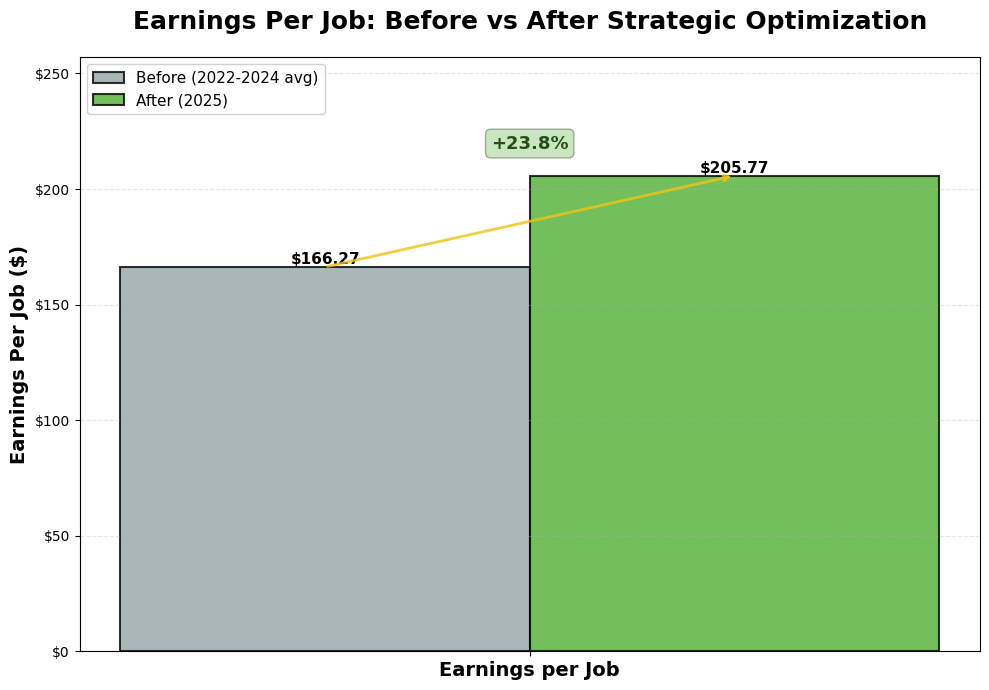

✓ Earnings per Job Comparison saved

EARNINGS PER JOB COMPARISON
Before (2022-2024): $166.27
After (2025): $205.77
Increase: +23.8%


In [20]:
# Calculate average earnings per job by year
df_clean = df[df['Earnings'] > 0].copy()
df_clean['Year'] = df_clean['Date'].dt.year

yearly_earnings = df_clean.groupby('Year')['Earnings'].mean().reset_index()

# Calculate before/after metrics
earnings_2022_2024 = yearly_earnings[yearly_earnings['Year'].isin([2022, 2023, 2024])]['Earnings'].mean()
earnings_2025 = yearly_earnings[yearly_earnings['Year'] == 2025]['Earnings'].values[0]
pct_increase_earnings = ((earnings_2025 - earnings_2022_2024) / earnings_2022_2024) * 100

# Prepare data for comparison
metrics = {
    'Metric': ['Earnings per Job'],
    'Before': [earnings_2022_2024],
    'After': [earnings_2025],
    'Increase': [pct_increase_earnings]
}

comparison_df = pd.DataFrame(metrics)

# Create figure
fig, ax = plt.subplots(figsize=(10, 7))

x = np.arange(len(comparison_df))
width = 0.35

# Plot bars - USING TASKRABBIT LIGHT GREEN
bars1 = ax.bar(x - width/2, comparison_df['Before'], width, 
               label='Before (2022-2024 avg)', color='#95a5a6', alpha=0.8, 
               edgecolor='black', linewidth=1.5)
bars2 = ax.bar(x + width/2, comparison_df['After'], width, 
               label='After (2025)', color='#50AF33', alpha=0.8,
               edgecolor='black', linewidth=1.5)

# Add value labels on bars
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'${height:.2f}',
                ha='center', va='bottom', fontsize=11, fontweight='bold')

# Add percentage increase label
for i, (before, after, pct) in enumerate(zip(comparison_df['Before'], 
                                               comparison_df['After'], 
                                               comparison_df['Increase'])):
    # Draw arrow - yellow
    ax.annotate('', xy=(i + width/2, after), xytext=(i - width/2, before),
                arrowprops=dict(arrowstyle='->', color='#f1c40f', lw=2, alpha=0.8))
    
    # Add percentage text with light green background
    ax.text(i, after + 10, f'+{pct:.1f}%', 
            ha='center', va='bottom', fontsize=13, fontweight='bold', 
            color='#264F18',
            bbox=dict(boxstyle='round', facecolor='#50AF33', alpha=0.3))

# Styling
ax.set_title('Earnings Per Job: Before vs After Strategic Optimization', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_ylabel('Earnings Per Job ($)', fontsize=14, fontweight='bold')

# Format y-axis
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Add 25% breathing room at the top
max_value = comparison_df[['Before', 'After']].max().max()
ax.set_ylim(0, max_value * 1.25)

# Set x-axis labels - BOLD "Earnings per Job"
ax.set_xticks(x)
ax.set_xticklabels(['Earnings per Job'], fontsize=14, fontweight='bold')

# Add legend
ax.legend(fontsize=11, loc='upper left', framealpha=0.9)

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--', axis='y')

plt.tight_layout()
plt.savefig('../visualizations/earnings_per_job_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Earnings per Job Comparison saved")
print("\n" + "="*60)
print("EARNINGS PER JOB COMPARISON")
print("="*60)
print(f"Before (2022-2024): ${earnings_2022_2024:.2f}")
print(f"After (2025): ${earnings_2025:.2f}")
print(f"Increase: +{pct_increase_earnings:.1f}%")
print("="*60)

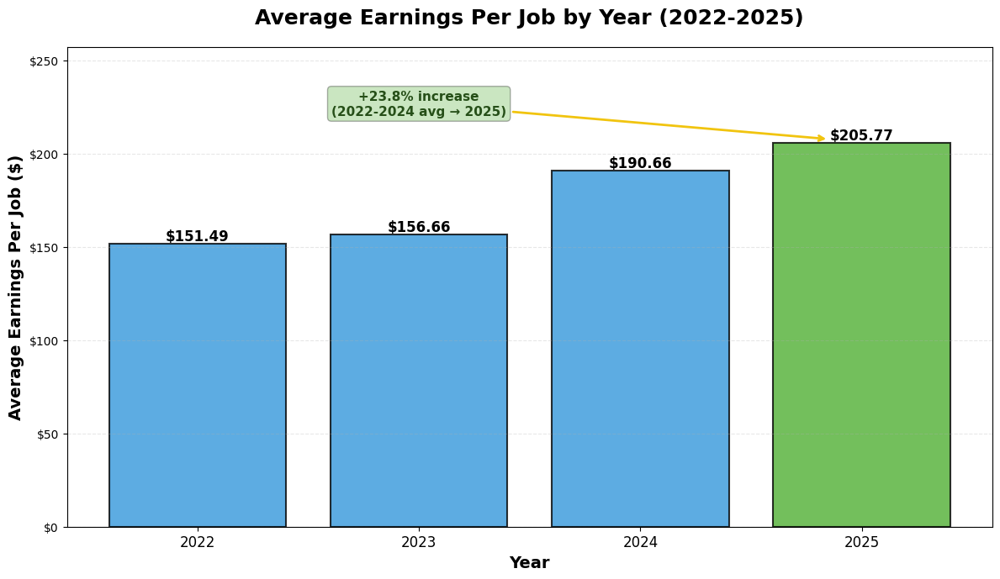

✓ Graph: Yearly Earnings Per Job saved

Key Stats:
  2022: $151.49
  2023: $156.66
  2024: $190.66
  2025: $205.77

2022-2024 average: $166.27
2025 average: $205.77
Percentage increase: +23.8%


In [21]:
# Calculate average earnings per job by year
df_clean = df[df['Earnings'] > 0].copy()
df_clean['Year'] = df_clean['Date'].dt.year

yearly_earnings = df_clean.groupby('Year')['Earnings'].mean().reset_index()

# Calculate percentage change from 2022-2024 average to 2025
earnings_2022_2024 = yearly_earnings[yearly_earnings['Year'].isin([2022, 2023, 2024])]['Earnings'].mean()
earnings_2025 = yearly_earnings[yearly_earnings['Year'] == 2025]['Earnings'].values[0]
pct_increase = ((earnings_2025 - earnings_2022_2024) / earnings_2022_2024) * 100

# Create figure
fig, ax = plt.subplots(figsize=(12, 7))

# Color scheme - highlight 2025 with TaskRabbit light green
colors = ['#3498db', '#3498db', '#3498db', '#50AF33']  # Blue for 2022-2024, TaskRabbit green for 2025

# Plot bars
bars = ax.bar(yearly_earnings['Year'], yearly_earnings['Earnings'], 
              color=colors, alpha=0.8, edgecolor='black', linewidth=1.5)

# Add value labels on top of bars
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'${height:.2f}',
            ha='center', va='bottom', fontsize=12, fontweight='bold')

# Styling
ax.set_title('Average Earnings Per Job by Year (2022-2025)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Year', fontsize=14, fontweight='bold')
ax.set_ylabel('Average Earnings Per Job ($)', fontsize=14, fontweight='bold')

# Format y-axis
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--', axis='y')

# Add annotation - arrow pointing from LEFT to the 2025 value label
# The value label is positioned slightly above the bar
ax.annotate(f'+{pct_increase:.1f}% increase\n(2022-2024 avg → 2025)', 
            xy=(2024.85, earnings_2025 + 2),  # Arrow tip points to left of the $ text
            xytext=(2023, earnings_2025 + 15),  # Text box positioned to the upper left
            bbox=dict(boxstyle='round', facecolor='#50AF33', alpha=0.3),
            fontsize=11, ha='center', color='#264F18', fontweight='bold',
            arrowprops=dict(arrowstyle='->', color='#f1c40f', lw=2))

# Set x-axis to show ONLY the years
ax.set_xticks([2022, 2023, 2024, 2025])
ax.set_xticklabels(['2022', '2023', '2024', '2025'], fontsize=12)

# Add 25% breathing room at the top
max_value = yearly_earnings['Earnings'].max()
ax.set_ylim(0, max_value * 1.25)

plt.tight_layout()
plt.savefig('../visualizations/yearly_earnings_per_job.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Graph: Yearly Earnings Per Job saved")
print(f"\nKey Stats:")
for _, row in yearly_earnings.iterrows():
    print(f"  {int(row['Year'])}: ${row['Earnings']:.2f}")
print(f"\n2022-2024 average: ${earnings_2022_2024:.2f}")
print(f"2025 average: ${earnings_2025:.2f}")
print(f"Percentage increase: +{pct_increase:.1f}%")

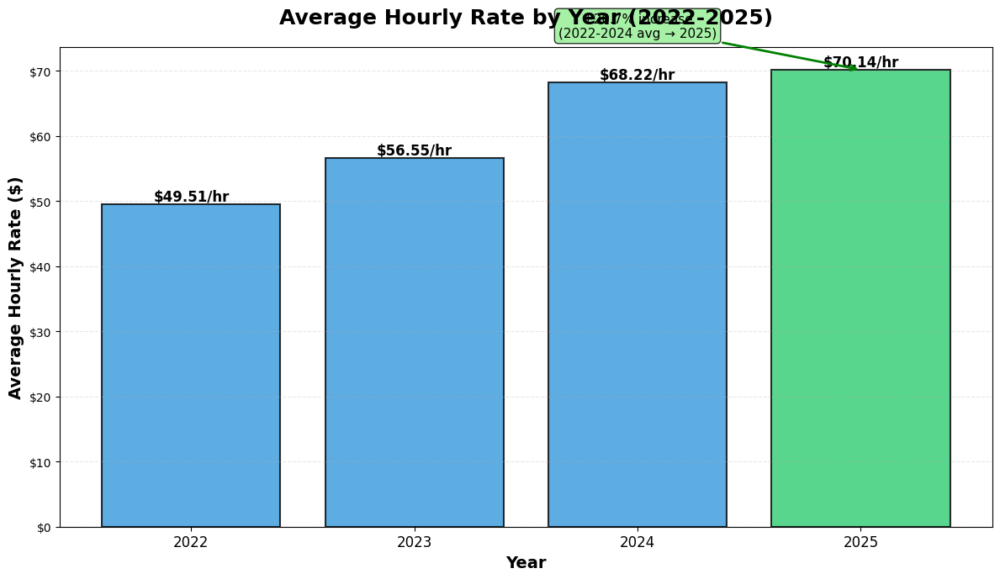

✓ Graph 1: Yearly Hourly Rate saved

Key Stats:
  2022-2024 average: $58.09/hr
  2025 average: $70.14/hr
  Percentage increase: +20.7%


In [22]:
# Calculate average hourly rate by year
df['Gross_Hourly_Rate'] = df['Earnings'] / df['Hours']
df_clean = df[(df['Gross_Hourly_Rate'] > 0) & (df['Gross_Hourly_Rate'] < np.inf)].copy()
df_clean['Year'] = df_clean['Date'].dt.year

yearly_hourly_rate = df_clean.groupby('Year')['Gross_Hourly_Rate'].mean().reset_index()

# Calculate percentage changes
rate_2022_2024 = yearly_hourly_rate[yearly_hourly_rate['Year'].isin([2022, 2023, 2024])]['Gross_Hourly_Rate'].mean()
rate_2025 = yearly_hourly_rate[yearly_hourly_rate['Year'] == 2025]['Gross_Hourly_Rate'].values[0]
pct_increase_rate = ((rate_2025 - rate_2022_2024) / rate_2022_2024) * 100

# Create figure
fig, ax = plt.subplots(figsize=(12, 7))

# Color scheme - highlight 2025
colors = ['#3498db', '#3498db', '#3498db', '#2ecc71']  # Blue for 2022-2024, green for 2025

# Plot bars
bars = ax.bar(yearly_hourly_rate['Year'], yearly_hourly_rate['Gross_Hourly_Rate'], 
              color=colors, alpha=0.8, edgecolor='black', linewidth=1.5)

# Add value labels on top of bars
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'${height:.2f}/hr',
            ha='center', va='bottom', fontsize=12, fontweight='bold')

# Styling
ax.set_title('Average Hourly Rate by Year (2022-2025)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Year', fontsize=14, fontweight='bold')
ax.set_ylabel('Average Hourly Rate ($)', fontsize=14, fontweight='bold')

# Format y-axis
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--', axis='y')

# Add annotation showing the improvement
ax.annotate(f'+{pct_increase_rate:.1f}% increase\n(2022-2024 avg → 2025)', 
            xy=(2025, rate_2025), 
            xytext=(2024, rate_2025 + 5),
            bbox=dict(boxstyle='round', facecolor='lightgreen', alpha=0.8),
            fontsize=11, ha='center',
            arrowprops=dict(arrowstyle='->', color='green', lw=2))

# Set x-axis to show only the years
ax.set_xticks([2022, 2023, 2024, 2025])
ax.set_xticklabels(['2022', '2023', '2024', '2025'], fontsize=12)

plt.tight_layout()
plt.savefig('../visualizations/yearly_hourly_rate.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Graph 1: Yearly Hourly Rate saved")
print(f"\nKey Stats:")
print(f"  2022-2024 average: ${rate_2022_2024:.2f}/hr")
print(f"  2025 average: ${rate_2025:.2f}/hr")
print(f"  Percentage increase: +{pct_increase_rate:.1f}%")

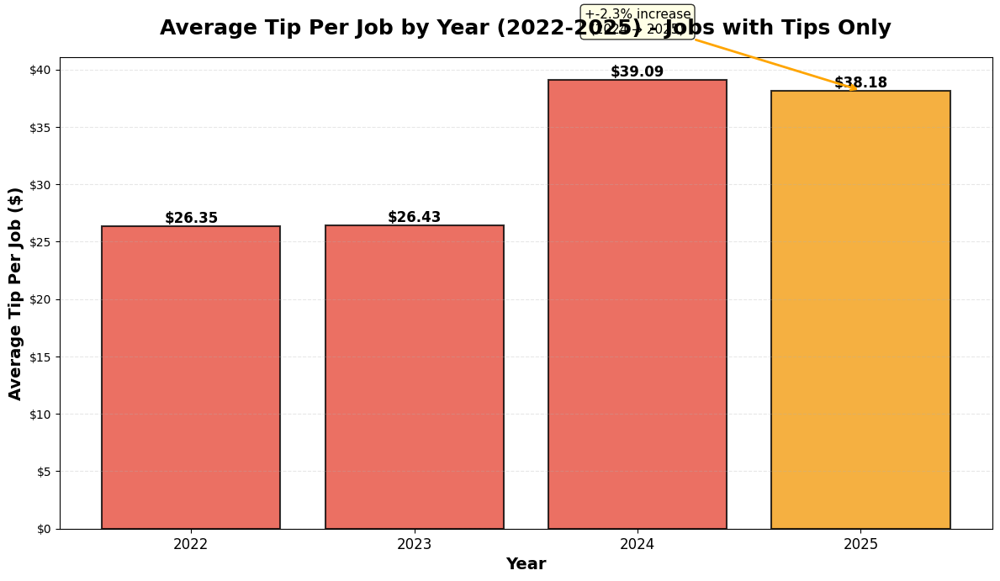

✓ Graph 2: Yearly Tips Per Job saved

Key Stats:
  2024 average tip: $39.09
  2025 average tip: $38.18
  Percentage increase: +-2.3%


In [23]:
# Calculate average tip per job by year (excluding zero tips)
df_tips = df[df['Tip'] > 0].copy()
df_tips['Year'] = df_tips['Date'].dt.year

yearly_tips = df_tips.groupby('Year')['Tip'].mean().reset_index()

# Calculate percentage changes
tip_2024 = yearly_tips[yearly_tips['Year'] == 2024]['Tip'].values[0]
tip_2025 = yearly_tips[yearly_tips['Year'] == 2025]['Tip'].values[0]
pct_increase_tips = ((tip_2025 - tip_2024) / tip_2024) * 100

# Create figure
fig, ax = plt.subplots(figsize=(12, 7))

# Color scheme - highlight 2025
colors = ['#e74c3c', '#e74c3c', '#e74c3c', '#f39c12']  # Red for 2022-2024, orange for 2025

# Plot bars
bars = ax.bar(yearly_tips['Year'], yearly_tips['Tip'], 
              color=colors, alpha=0.8, edgecolor='black', linewidth=1.5)

# Add value labels on top of bars
for bar in bars:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height,
            f'${height:.2f}',
            ha='center', va='bottom', fontsize=12, fontweight='bold')

# Styling
ax.set_title('Average Tip Per Job by Year (2022-2025) - Jobs with Tips Only', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Year', fontsize=14, fontweight='bold')
ax.set_ylabel('Average Tip Per Job ($)', fontsize=14, fontweight='bold')

# Format y-axis
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--', axis='y')

# Add annotation showing the improvement
ax.annotate(f'+{pct_increase_tips:.1f}% increase\n(2024 → 2025)', 
            xy=(2025, tip_2025), 
            xytext=(2024, tip_2025 + 5),
            bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.8),
            fontsize=11, ha='center',
            arrowprops=dict(arrowstyle='->', color='orange', lw=2))

# Set x-axis to show only the years
ax.set_xticks([2022, 2023, 2024, 2025])
ax.set_xticklabels(['2022', '2023', '2024', '2025'], fontsize=12)

plt.tight_layout()
plt.savefig('../visualizations/yearly_tips_per_job.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Graph 2: Yearly Tips Per Job saved")
print(f"\nKey Stats:")
print(f"  2024 average tip: ${tip_2024:.2f}")
print(f"  2025 average tip: ${tip_2025:.2f}")
print(f"  Percentage increase: +{pct_increase_tips:.1f}%")

In [24]:
# Let's look at when the strategic shift happened

# 1. Monthly job volume over time
df_clean = df[df['Earnings'] > 0].copy()
df_clean['Year_Month'] = df_clean['Date'].dt.to_period('M')
df_clean['Gross_Hourly_Rate'] = df_clean['Earnings'] / df_clean['Hours']

monthly_volume = df_clean.groupby('Year_Month').agg({
    'Earnings': 'count',  # Number of jobs
    'Total': 'mean',       # Avg earnings per job
    'Gross_Hourly_Rate': 'mean'  # Avg hourly rate
}).reset_index()

print("MONTHLY TRENDS - Looking for when volume dropped and value increased:")
print("="*80)
print(monthly_volume.to_string(index=False))

# 2. Identify the turning point
print("\n" + "="*80)
print("IDENTIFYING THE STRATEGIC SHIFT:")
print("="*80)

# Calculate rolling averages to smooth trends
monthly_volume['Jobs_Rolling_Avg'] = monthly_volume['Earnings'].rolling(window=3, center=True).mean()
monthly_volume['Value_Rolling_Avg'] = monthly_volume['Total'].rolling(window=3, center=True).mean()

# Find when volume started declining consistently
avg_volume_2022_2023 = monthly_volume[monthly_volume['Year_Month'].astype(str) < '2024']['Earnings'].mean()
print(f"\nAverage jobs/month (2022-2023): {avg_volume_2022_2023:.1f}")

# Check each period
for year in [2023, 2024, 2025]:
    year_data = monthly_volume[monthly_volume['Year_Month'].astype(str).str.startswith(str(year))]
    if len(year_data) > 0:
        avg_jobs = year_data['Earnings'].mean()
        avg_value = year_data['Total'].mean()
        print(f"\n{year}:")
        print(f"  Avg jobs/month: {avg_jobs:.1f}")
        print(f"  Avg earnings/job: ${avg_value:.2f}")

# 3. Look at rate increases by quarter
print("\n" + "="*80)
print("QUARTERLY ANALYSIS:")
print("="*80)

df_clean['Year_Quarter'] = df_clean['Date'].dt.to_period('Q')
quarterly = df_clean.groupby('Year_Quarter').agg({
    'Earnings': 'count',
    'Total': 'mean',
    'Gross_Hourly_Rate': 'mean',
    'Tip': lambda x: (x > 0).sum() / len(x) * 100  # Tip frequency
}).reset_index()

quarterly.columns = ['Quarter', 'Jobs', 'Avg_Earnings', 'Avg_Hourly_Rate', 'Tip_Frequency_%']

print(quarterly.to_string(index=False))

# 4. Identify inflection points
print("\n" + "="*80)
print("POSSIBLE STRATEGIC SHIFT PERIODS:")
print("="*80)

# Look for quarters where changes happened
early_quarters = quarterly[quarterly['Quarter'].astype(str) < '2024-Q1']
early_avg_jobs = early_quarters['Jobs'].mean()
early_avg_earnings = early_quarters['Avg_Earnings'].mean()

for idx, row in quarterly.iterrows():
    quarter_str = str(row['Quarter'])
    if quarter_str >= '2023-Q1':  # Start checking from 2023
        job_decrease = (row['Jobs'] / early_avg_jobs) * 100
        earnings_increase = (row['Avg_Earnings'] / early_avg_earnings) * 100
        
        if job_decrease < 85 or earnings_increase > 115:  # Significant change
            print(f"\n{row['Quarter']}:")
            print(f"  Jobs: {row['Jobs']:.0f} ({job_decrease:.0f}% of early avg)")
            print(f"  Avg Earnings: ${row['Avg_Earnings']:.2f} ({earnings_increase:.0f}% of early avg)")
            print(f"  Hourly Rate: ${row['Avg_Hourly_Rate']:.2f}")
            print(f"  → Possible strategic shift period?")

MONTHLY TRENDS - Looking for when volume dropped and value increased:
Year_Month  Earnings      Total  Gross_Hourly_Rate
   2022-04         6 107.833333          36.166667
   2022-05        14 190.496429          47.857143
   2022-06        19 154.638421          41.894737
   2022-07        16 165.484375          54.812500
   2022-08        18 185.405556          47.666667
   2022-09        31 158.144516          51.806452
   2022-10        15 144.530000          55.133333
   2022-11         4 155.875000          56.500000
   2022-12        21 148.245238          50.142857
   2023-01        21 132.418095          38.714286
   2023-02        17 167.199412          50.294118
   2023-03         5 198.428000          58.800000
   2023-04        15 132.132000          45.866667
   2023-05        12 133.178333          61.583333
   2023-06        12 102.680833          75.166667
   2023-07         7 123.000000          86.142857
   2023-08         2 194.000000          74.000000
   2023-09  

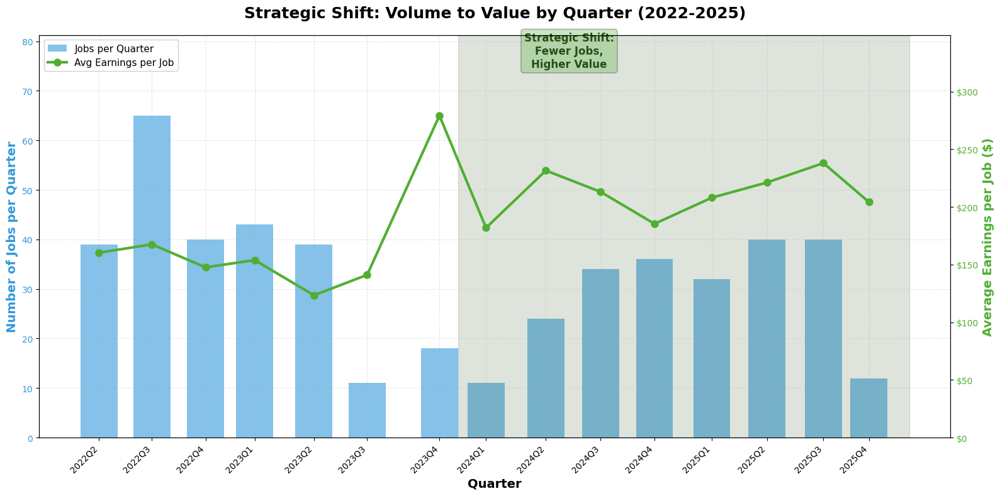

✓ Strategic Shift chart saved

STRATEGIC SHIFT ANALYSIS

Early Period (2022-2023):
  Avg jobs/quarter: 36.4
  Avg earnings/job: $167.56

Late Period (2024-2025):
  Avg jobs/quarter: 28.6
  Avg earnings/job: $210.38

Change:
  Jobs: -21.4%
  Earnings: 25.6%


In [25]:
# Prepare quarterly data
df_clean = df[df['Earnings'] > 0].copy()
df_clean['Year_Quarter'] = df_clean['Date'].dt.to_period('Q')
df_clean['Gross_Hourly_Rate'] = df_clean['Earnings'] / df_clean['Hours']

quarterly = df_clean.groupby('Year_Quarter').agg({
    'Earnings': 'count',  # Number of jobs
    'Total': 'mean',       # Avg earnings per job
    'Gross_Hourly_Rate': 'mean',  # Avg hourly rate
    'Date': 'mean'  # For plotting
}).reset_index()

quarterly.columns = ['Quarter', 'Jobs', 'Avg_Earnings', 'Avg_Hourly_Rate', 'Date']

# Create figure with dual y-axes
fig, ax1 = plt.subplots(figsize=(16, 8))

# Color scheme
volume_color = '#3498db'  # Blue for volume
value_color = '#50AF33'  # TaskRabbit green for value

# Plot bars - Jobs per quarter (left y-axis)
ax1.bar(quarterly['Date'], quarterly['Jobs'], 
        color=volume_color, alpha=0.6, width=60, label='Jobs per Quarter')

ax1.set_xlabel('Quarter', fontsize=14, fontweight='bold')
ax1.set_ylabel('Number of Jobs per Quarter', fontsize=14, fontweight='bold', color=volume_color)
ax1.tick_params(axis='y', labelcolor=volume_color)

# Add 25% breathing room
ax1.set_ylim(0, quarterly['Jobs'].max() * 1.25)

# Create second y-axis for average earnings
ax2 = ax1.twinx()

# Plot line - Average earnings per job (right y-axis)
ax2.plot(quarterly['Date'], quarterly['Avg_Earnings'], 
         color=value_color, linewidth=3, marker='o', markersize=8, 
         label='Avg Earnings per Job')

ax2.set_ylabel('Average Earnings per Job ($)', fontsize=14, fontweight='bold', color=value_color)
ax2.tick_params(axis='y', labelcolor=value_color)

# Add 25% breathing room
ax2.set_ylim(0, quarterly['Avg_Earnings'].max() * 1.25)

# Format right y-axis to show dollars
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Title
ax1.set_title('Strategic Shift: Volume to Value by Quarter (2022-2025)', 
              fontsize=18, fontweight='bold', pad=20)

# Grid
ax1.grid(True, alpha=0.3, linestyle='--')

# Format x-axis with quarter labels
quarter_labels = [str(q) for q in quarterly['Quarter']]
ax1.set_xticks(quarterly['Date'])
ax1.set_xticklabels(quarter_labels, rotation=45, ha='right')

# Add legends from both axes
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', fontsize=11, framealpha=0.9)

# Highlight the strategic shift period (based on your data analysis)
# Adjust these dates based on what the previous analysis showed
shift_start = pd.Timestamp('2024-01-01')  # Adjust based on your findings
shift_end = pd.Timestamp('2025-12-31')

ax1.axvspan(shift_start, shift_end, alpha=0.15, color='#264F18', 
            label='Strategic Optimization Period')

# Add annotation
ax1.text(shift_start + pd.Timedelta(days=180), quarterly['Jobs'].max() * 1.15,
         'Strategic Shift:\nFewer Jobs,\nHigher Value',
         fontsize=12, fontweight='bold', color='#264F18',
         bbox=dict(boxstyle='round', facecolor='#50AF33', alpha=0.3),
         ha='center')

plt.tight_layout()
plt.savefig('../visualizations/strategic_shift_quarterly.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Strategic Shift chart saved")

# Print summary
print("\n" + "="*60)
print("STRATEGIC SHIFT ANALYSIS")
print("="*60)
early_period = quarterly[quarterly['Quarter'].astype(str) < '2024-Q1']
late_period = quarterly[quarterly['Quarter'].astype(str) >= '2024-Q1']

print(f"\nEarly Period (2022-2023):")
print(f"  Avg jobs/quarter: {early_period['Jobs'].mean():.1f}")
print(f"  Avg earnings/job: ${early_period['Avg_Earnings'].mean():.2f}")

print(f"\nLate Period (2024-2025):")
print(f"  Avg jobs/quarter: {late_period['Jobs'].mean():.1f}")
print(f"  Avg earnings/job: ${late_period['Avg_Earnings'].mean():.2f}")

print(f"\nChange:")
print(f"  Jobs: {((late_period['Jobs'].mean() - early_period['Jobs'].mean()) / early_period['Jobs'].mean() * 100):.1f}%")
print(f"  Earnings: {((late_period['Avg_Earnings'].mean() - early_period['Avg_Earnings'].mean()) / early_period['Avg_Earnings'].mean() * 100):.1f}%")

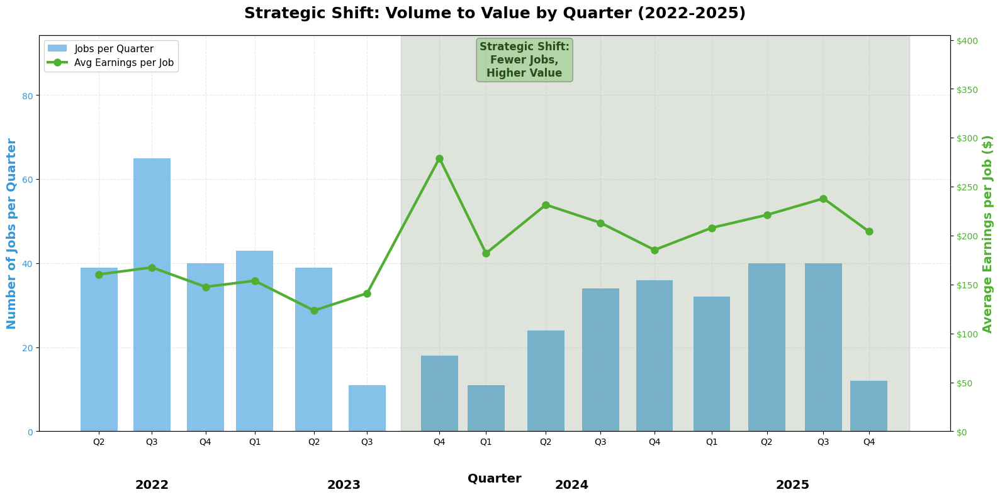

✓ Strategic Shift chart saved

STRATEGIC SHIFT ANALYSIS

Early Period (2022-Q2 to 2023-Q3):
  Avg jobs/quarter: 48.0
  Avg earnings/job: $158.48

Late Period (2023-Q4 onwards):
  Avg jobs/quarter: 28.3
  Avg earnings/job: $198.38

Change:
  Jobs: -41.0%
  Earnings: 25.2%


In [26]:
# Prepare quarterly data
df_clean = df[df['Earnings'] > 0].copy()
df_clean['Year_Quarter'] = df_clean['Date'].dt.to_period('Q')
df_clean['Gross_Hourly_Rate'] = df_clean['Earnings'] / df_clean['Hours']

quarterly = df_clean.groupby('Year_Quarter').agg({
    'Earnings': 'count',  # Number of jobs
    'Total': 'mean',       # Avg earnings per job
    'Gross_Hourly_Rate': 'mean',  # Avg hourly rate
    'Date': 'mean'  # For plotting
}).reset_index()

quarterly.columns = ['Quarter', 'Jobs', 'Avg_Earnings', 'Avg_Hourly_Rate', 'Date']

# Extract year and quarter separately
quarterly['Year'] = quarterly['Quarter'].astype(str).str[:4]
quarterly['Q'] = quarterly['Quarter'].astype(str).str[-2:]

# Create figure with dual y-axes
fig, ax1 = plt.subplots(figsize=(16, 8))

# Color scheme
volume_color = '#3498db'  # Blue for volume
value_color = '#50AF33'  # TaskRabbit green for value

# Plot bars - Jobs per quarter (left y-axis)
ax1.bar(quarterly['Date'], quarterly['Jobs'], 
        color=volume_color, alpha=0.6, width=60, label='Jobs per Quarter')

ax1.set_ylabel('Number of Jobs per Quarter', fontsize=14, fontweight='bold', color=volume_color)
ax1.tick_params(axis='y', labelcolor=volume_color)

# Add 45% breathing room (25% + 20% extra)
ax1.set_ylim(0, quarterly['Jobs'].max() * 1.45)

# Create second y-axis for average earnings
ax2 = ax1.twinx()

# Plot line - Average earnings per job (right y-axis)
ax2.plot(quarterly['Date'], quarterly['Avg_Earnings'], 
         color=value_color, linewidth=3, marker='o', markersize=8, 
         label='Avg Earnings per Job')

ax2.set_ylabel('Average Earnings per Job ($)', fontsize=14, fontweight='bold', color=value_color)
ax2.tick_params(axis='y', labelcolor=value_color)

# Add 45% breathing room
ax2.set_ylim(0, quarterly['Avg_Earnings'].max() * 1.45)

# Format right y-axis to show dollars
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Title
ax1.set_title('Strategic Shift: Volume to Value by Quarter (2022-2025)', 
              fontsize=18, fontweight='bold', pad=20)

# Grid
ax1.grid(True, alpha=0.3, linestyle='--')

# Format x-axis - just show quarter (Q1, Q2, etc)
quarter_labels = quarterly['Q'].tolist()
ax1.set_xticks(quarterly['Date'])
ax1.set_xticklabels(quarter_labels, rotation=0, ha='center')

# Add year labels below, centered under each year's quarters
for year in quarterly['Year'].unique():
    year_data = quarterly[quarterly['Year'] == year]
    if len(year_data) > 0:
        # Calculate center position for the year
        center_date = year_data['Date'].mean()
        ax1.text(center_date, -0.12, year, 
                transform=ax1.get_xaxis_transform(),
                ha='center', va='top', fontsize=14, fontweight='bold')

# Move "Quarter" label down to avoid overlap
ax1.set_xlabel('Quarter', fontsize=14, fontweight='bold', labelpad=30)

# Add legends from both axes
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', fontsize=11, framealpha=0.9)

# Highlight the strategic shift period - Q4 2023 onwards
shift_start = pd.Timestamp('2023-10-01')  # Q4 2023
shift_end = pd.Timestamp('2025-12-31')

ax1.axvspan(shift_start, shift_end, alpha=0.15, color='#264F18', 
            label='Strategic Optimization Period')

# Add annotation - positioned to avoid overlap
ax1.text(shift_start + pd.Timedelta(days=200), quarterly['Jobs'].max() * 1.30,
         'Strategic Shift:\nFewer Jobs,\nHigher Value',
         fontsize=12, fontweight='bold', color='#264F18',
         bbox=dict(boxstyle='round', facecolor='#50AF33', alpha=0.3),
         ha='center')

plt.tight_layout()
plt.savefig('../visualizations/strategic_shift_quarterly.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Strategic Shift chart saved")

# Print summary
print("\n" + "="*60)
print("STRATEGIC SHIFT ANALYSIS")
print("="*60)
early_period = quarterly[quarterly['Quarter'].astype(str) < '2023-Q4']
late_period = quarterly[quarterly['Quarter'].astype(str) >= '2023-Q4']

print(f"\nEarly Period (2022-Q2 to 2023-Q3):")
print(f"  Avg jobs/quarter: {early_period['Jobs'].mean():.1f}")
print(f"  Avg earnings/job: ${early_period['Avg_Earnings'].mean():.2f}")

print(f"\nLate Period (2023-Q4 onwards):")
print(f"  Avg jobs/quarter: {late_period['Jobs'].mean():.1f}")
print(f"  Avg earnings/job: ${late_period['Avg_Earnings'].mean():.2f}")

print(f"\nChange:")
print(f"  Jobs: {((late_period['Jobs'].mean() - early_period['Jobs'].mean()) / early_period['Jobs'].mean() * 100):.1f}%")
print(f"  Earnings: {((late_period['Avg_Earnings'].mean() - early_period['Avg_Earnings'].mean()) / early_period['Avg_Earnings'].mean() * 100):.1f}%")

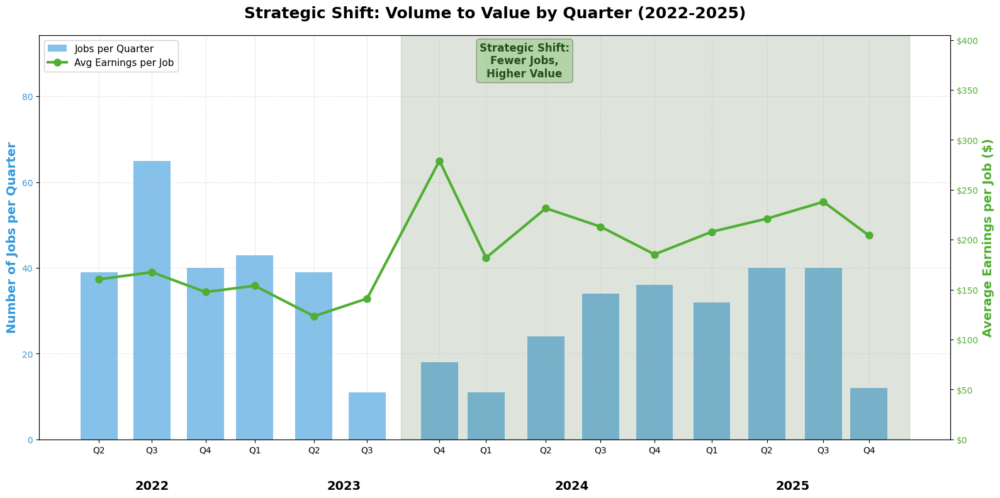

✓ Strategic Shift chart saved

STRATEGIC SHIFT ANALYSIS

Early Period (2022-Q2 to 2023-Q3):
  Avg jobs/quarter: 48.0
  Avg earnings/job: $158.48

Late Period (2023-Q4 onwards):
  Avg jobs/quarter: 28.3
  Avg earnings/job: $198.38

Change:
  Jobs: -41.0%
  Earnings: 25.2%


In [27]:
# Prepare quarterly data
df_clean = df[df['Earnings'] > 0].copy()
df_clean['Year_Quarter'] = df_clean['Date'].dt.to_period('Q')
df_clean['Gross_Hourly_Rate'] = df_clean['Earnings'] / df_clean['Hours']

quarterly = df_clean.groupby('Year_Quarter').agg({
    'Earnings': 'count',  # Number of jobs
    'Total': 'mean',       # Avg earnings per job
    'Gross_Hourly_Rate': 'mean',  # Avg hourly rate
    'Date': 'mean'  # For plotting
}).reset_index()

quarterly.columns = ['Quarter', 'Jobs', 'Avg_Earnings', 'Avg_Hourly_Rate', 'Date']

# Extract year and quarter separately
quarterly['Year'] = quarterly['Quarter'].astype(str).str[:4]
quarterly['Q'] = quarterly['Quarter'].astype(str).str[-2:]

# Create figure with dual y-axes
fig, ax1 = plt.subplots(figsize=(16, 8))

# Color scheme
volume_color = '#3498db'  # Blue for volume
value_color = '#50AF33'  # TaskRabbit green for value

# Plot bars - Jobs per quarter (left y-axis)
ax1.bar(quarterly['Date'], quarterly['Jobs'], 
        color=volume_color, alpha=0.6, width=60, label='Jobs per Quarter')

ax1.set_ylabel('Number of Jobs per Quarter', fontsize=14, fontweight='bold', color=volume_color)
ax1.tick_params(axis='y', labelcolor=volume_color)

# Add 45% breathing room
ax1.set_ylim(0, quarterly['Jobs'].max() * 1.45)

# Create second y-axis for average earnings
ax2 = ax1.twinx()

# Plot line - Average earnings per job (right y-axis)
ax2.plot(quarterly['Date'], quarterly['Avg_Earnings'], 
         color=value_color, linewidth=3, marker='o', markersize=8, 
         label='Avg Earnings per Job')

ax2.set_ylabel('Average Earnings per Job ($)', fontsize=14, fontweight='bold', color=value_color)
ax2.tick_params(axis='y', labelcolor=value_color)

# Add 45% breathing room
ax2.set_ylim(0, quarterly['Avg_Earnings'].max() * 1.45)

# Format right y-axis to show dollars
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Title
ax1.set_title('Strategic Shift: Volume to Value by Quarter (2022-2025)', 
              fontsize=18, fontweight='bold', pad=20)

# Grid
ax1.grid(True, alpha=0.3, linestyle='--')

# Format x-axis - just show quarter (Q1, Q2, etc)
quarter_labels = quarterly['Q'].tolist()
ax1.set_xticks(quarterly['Date'])
ax1.set_xticklabels(quarter_labels, rotation=0, ha='center')

# Add year labels below, centered under each year's quarters
for year in quarterly['Year'].unique():
    year_data = quarterly[quarterly['Year'] == year]
    if len(year_data) > 0:
        # Calculate center position for the year
        center_date = year_data['Date'].mean()
        ax1.text(center_date, -0.10, year, 
                transform=ax1.get_xaxis_transform(),
                ha='center', va='top', fontsize=14, fontweight='bold')

# No x-axis label needed anymore

# Add legends from both axes
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', fontsize=11, framealpha=0.9)

# Highlight the strategic shift period - Q4 2023 onwards
shift_start = pd.Timestamp('2023-10-01')  # Q4 2023
shift_end = pd.Timestamp('2025-12-31')

ax1.axvspan(shift_start, shift_end, alpha=0.15, color='#264F18', 
            label='Strategic Optimization Period')

# Add annotation
ax1.text(shift_start + pd.Timedelta(days=200), quarterly['Jobs'].max() * 1.30,
         'Strategic Shift:\nFewer Jobs,\nHigher Value',
         fontsize=12, fontweight='bold', color='#264F18',
         bbox=dict(boxstyle='round', facecolor='#50AF33', alpha=0.3),
         ha='center')

plt.tight_layout()
plt.savefig('../visualizations/strategic_shift_quarterly.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Strategic Shift chart saved")

# Print summary
print("\n" + "="*60)
print("STRATEGIC SHIFT ANALYSIS")
print("="*60)
early_period = quarterly[quarterly['Quarter'].astype(str) < '2023-Q4']
late_period = quarterly[quarterly['Quarter'].astype(str) >= '2023-Q4']

print(f"\nEarly Period (2022-Q2 to 2023-Q3):")
print(f"  Avg jobs/quarter: {early_period['Jobs'].mean():.1f}")
print(f"  Avg earnings/job: ${early_period['Avg_Earnings'].mean():.2f}")

print(f"\nLate Period (2023-Q4 onwards):")
print(f"  Avg jobs/quarter: {late_period['Jobs'].mean():.1f}")
print(f"  Avg earnings/job: ${late_period['Avg_Earnings'].mean():.2f}")

print(f"\nChange:")
print(f"  Jobs: {((late_period['Jobs'].mean() - early_period['Jobs'].mean()) / early_period['Jobs'].mean() * 100):.1f}%")
print(f"  Earnings: {((late_period['Avg_Earnings'].mean() - early_period['Avg_Earnings'].mean()) / early_period['Avg_Earnings'].mean() * 100):.1f}%")

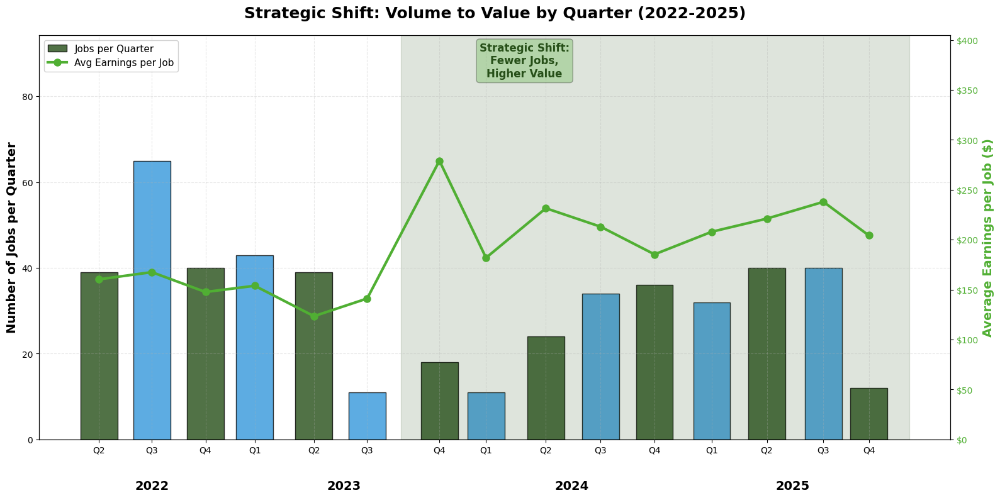

✓ Strategic Shift chart saved

STRATEGIC SHIFT ANALYSIS

Early Period (2022-Q2 to 2023-Q3):
  Avg jobs/quarter: 48.0
  Avg earnings/job: $158.48

Late Period (2023-Q4 onwards):
  Avg jobs/quarter: 28.3
  Avg earnings/job: $198.38

Change:
  Jobs: -41.0%
  Earnings: 25.2%


In [28]:
# Prepare quarterly data
df_clean = df[df['Earnings'] > 0].copy()
df_clean['Year_Quarter'] = df_clean['Date'].dt.to_period('Q')
df_clean['Gross_Hourly_Rate'] = df_clean['Earnings'] / df_clean['Hours']

quarterly = df_clean.groupby('Year_Quarter').agg({
    'Earnings': 'count',  # Number of jobs
    'Total': 'mean',       # Avg earnings per job
    'Gross_Hourly_Rate': 'mean',  # Avg hourly rate
    'Date': 'mean'  # For plotting
}).reset_index()

quarterly.columns = ['Quarter', 'Jobs', 'Avg_Earnings', 'Avg_Hourly_Rate', 'Date']

# Extract year and quarter separately
quarterly['Year'] = quarterly['Quarter'].astype(str).str[:4]
quarterly['Q'] = quarterly['Quarter'].astype(str).str[-2:]

# Assign colors based on quarter - TaskRabbit dark green for Q2 and Q4
colors = []
for q in quarterly['Q']:
    if q in ['Q2', 'Q4']:
        colors.append('#264F18')  # TaskRabbit dark green
    else:
        colors.append('#3498db')  # Blue

# Create figure with dual y-axes
fig, ax1 = plt.subplots(figsize=(16, 8))

# Color scheme for line
value_color = '#50AF33'  # TaskRabbit light green for value

# Plot bars - Jobs per quarter (left y-axis) with alternating colors
ax1.bar(quarterly['Date'], quarterly['Jobs'], 
        color=colors, alpha=0.8, width=60, edgecolor='black', linewidth=1,
        label='Jobs per Quarter')

ax1.set_ylabel('Number of Jobs per Quarter', fontsize=14, fontweight='bold', color='#000000')
ax1.tick_params(axis='y', labelcolor='#000000')

# Add 45% breathing room
ax1.set_ylim(0, quarterly['Jobs'].max() * 1.45)

# Create second y-axis for average earnings
ax2 = ax1.twinx()

# Plot line - Average earnings per job (right y-axis)
ax2.plot(quarterly['Date'], quarterly['Avg_Earnings'], 
         color=value_color, linewidth=3, marker='o', markersize=8, 
         label='Avg Earnings per Job')

ax2.set_ylabel('Average Earnings per Job ($)', fontsize=14, fontweight='bold', color=value_color)
ax2.tick_params(axis='y', labelcolor=value_color)

# Add 45% breathing room
ax2.set_ylim(0, quarterly['Avg_Earnings'].max() * 1.45)

# Format right y-axis to show dollars
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Title
ax1.set_title('Strategic Shift: Volume to Value by Quarter (2022-2025)', 
              fontsize=18, fontweight='bold', pad=20)

# Grid
ax1.grid(True, alpha=0.3, linestyle='--')

# Format x-axis - just show quarter (Q1, Q2, etc)
quarter_labels = quarterly['Q'].tolist()
ax1.set_xticks(quarterly['Date'])
ax1.set_xticklabels(quarter_labels, rotation=0, ha='center')

# Add year labels below, centered under each year's quarters
for year in quarterly['Year'].unique():
    year_data = quarterly[quarterly['Year'] == year]
    if len(year_data) > 0:
        # Calculate center position for the year
        center_date = year_data['Date'].mean()
        ax1.text(center_date, -0.10, year, 
                transform=ax1.get_xaxis_transform(),
                ha='center', va='top', fontsize=14, fontweight='bold')

# Add legends from both axes
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left', fontsize=11, framealpha=0.9)

# Highlight the strategic shift period - Q4 2023 onwards
shift_start = pd.Timestamp('2023-10-01')  # Q4 2023
shift_end = pd.Timestamp('2025-12-31')

ax1.axvspan(shift_start, shift_end, alpha=0.15, color='#264F18', 
            label='Strategic Optimization Period')

# Add annotation
ax1.text(shift_start + pd.Timedelta(days=200), quarterly['Jobs'].max() * 1.30,
         'Strategic Shift:\nFewer Jobs,\nHigher Value',
         fontsize=12, fontweight='bold', color='#264F18',
         bbox=dict(boxstyle='round', facecolor='#50AF33', alpha=0.3),
         ha='center')

plt.tight_layout()
plt.savefig('../visualizations/strategic_shift_quarterly.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Strategic Shift chart saved")

# Print summary
print("\n" + "="*60)
print("STRATEGIC SHIFT ANALYSIS")
print("="*60)
early_period = quarterly[quarterly['Quarter'].astype(str) < '2023-Q4']
late_period = quarterly[quarterly['Quarter'].astype(str) >= '2023-Q4']

print(f"\nEarly Period (2022-Q2 to 2023-Q3):")
print(f"  Avg jobs/quarter: {early_period['Jobs'].mean():.1f}")
print(f"  Avg earnings/job: ${early_period['Avg_Earnings'].mean():.2f}")

print(f"\nLate Period (2023-Q4 onwards):")
print(f"  Avg jobs/quarter: {late_period['Jobs'].mean():.1f}")
print(f"  Avg earnings/job: ${late_period['Avg_Earnings'].mean():.2f}")

print(f"\nChange:")
print(f"  Jobs: {((late_period['Jobs'].mean() - early_period['Jobs'].mean()) / early_period['Jobs'].mean() * 100):.1f}%")
print(f"  Earnings: {((late_period['Avg_Earnings'].mean() - early_period['Avg_Earnings'].mean()) / early_period['Avg_Earnings'].mean() * 100):.1f}%")

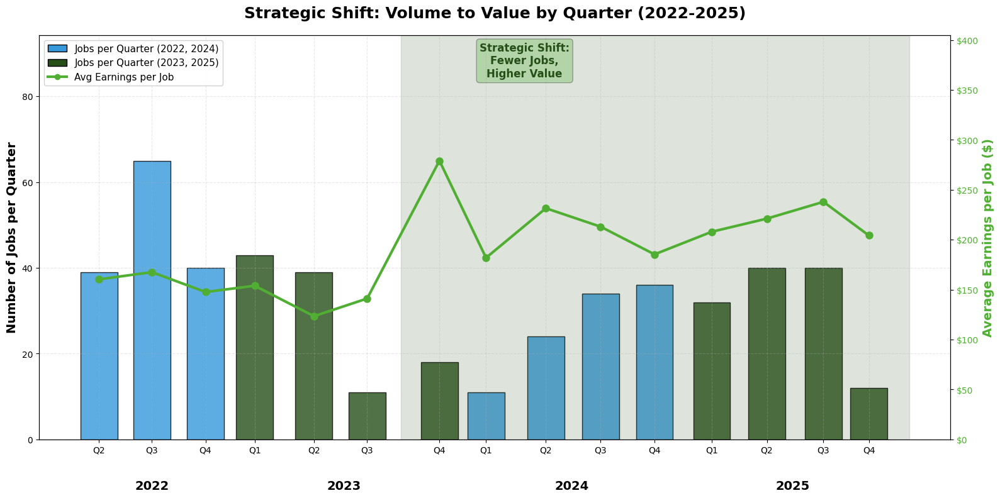

✓ Strategic Shift chart saved

STRATEGIC SHIFT ANALYSIS

Early Period (2022-Q2 to 2023-Q3):
  Avg jobs/quarter: 48.0
  Avg earnings/job: $158.48

Late Period (2023-Q4 onwards):
  Avg jobs/quarter: 28.3
  Avg earnings/job: $198.38

Change:
  Jobs: -41.0%
  Earnings: 25.2%


In [29]:
# Prepare quarterly data
df_clean = df[df['Earnings'] > 0].copy()
df_clean['Year_Quarter'] = df_clean['Date'].dt.to_period('Q')
df_clean['Gross_Hourly_Rate'] = df_clean['Earnings'] / df_clean['Hours']

quarterly = df_clean.groupby('Year_Quarter').agg({
    'Earnings': 'count',  # Number of jobs
    'Total': 'mean',       # Avg earnings per job
    'Gross_Hourly_Rate': 'mean',  # Avg hourly rate
    'Date': 'mean'  # For plotting
}).reset_index()

quarterly.columns = ['Quarter', 'Jobs', 'Avg_Earnings', 'Avg_Hourly_Rate', 'Date']

# Extract year and quarter separately
quarterly['Year'] = quarterly['Quarter'].astype(str).str[:4]
quarterly['Q'] = quarterly['Quarter'].astype(str).str[-2:]

# Assign colors based on year - TaskRabbit dark green for 2023 and 2025
colors = []
for year in quarterly['Year']:
    if year in ['2023', '2025']:
        colors.append('#264F18')  # TaskRabbit dark green
    else:
        colors.append('#3498db')  # Blue

# Create figure with dual y-axes
fig, ax1 = plt.subplots(figsize=(16, 8))

# Color scheme for line
value_color = '#50AF33'  # TaskRabbit light green for value

# Plot bars - Jobs per quarter (left y-axis) with year-based colors
ax1.bar(quarterly['Date'], quarterly['Jobs'], 
        color=colors, alpha=0.8, width=60, edgecolor='black', linewidth=1)

ax1.set_ylabel('Number of Jobs per Quarter', fontsize=14, fontweight='bold', color='#000000')
ax1.tick_params(axis='y', labelcolor='#000000')

# Add 45% breathing room
ax1.set_ylim(0, quarterly['Jobs'].max() * 1.45)

# Create second y-axis for average earnings
ax2 = ax1.twinx()

# Plot line - Average earnings per job (right y-axis)
ax2.plot(quarterly['Date'], quarterly['Avg_Earnings'], 
         color=value_color, linewidth=3, marker='o', markersize=8, 
         label='Avg Earnings per Job')

ax2.set_ylabel('Average Earnings per Job ($)', fontsize=14, fontweight='bold', color=value_color)
ax2.tick_params(axis='y', labelcolor=value_color)

# Add 45% breathing room
ax2.set_ylim(0, quarterly['Avg_Earnings'].max() * 1.45)

# Format right y-axis to show dollars
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Title
ax1.set_title('Strategic Shift: Volume to Value by Quarter (2022-2025)', 
              fontsize=18, fontweight='bold', pad=20)

# Grid
ax1.grid(True, alpha=0.3, linestyle='--')

# Format x-axis - just show quarter (Q1, Q2, etc)
quarter_labels = quarterly['Q'].tolist()
ax1.set_xticks(quarterly['Date'])
ax1.set_xticklabels(quarter_labels, rotation=0, ha='center')

# Add year labels below, centered under each year's quarters
for year in quarterly['Year'].unique():
    year_data = quarterly[quarterly['Year'] == year]
    if len(year_data) > 0:
        # Calculate center position for the year
        center_date = year_data['Date'].mean()
        ax1.text(center_date, -0.10, year, 
                transform=ax1.get_xaxis_transform(),
                ha='center', va='top', fontsize=14, fontweight='bold')

# Create custom legend with both bar colors
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#3498db', edgecolor='black', label='Jobs per Quarter (2022, 2024)'),
    Patch(facecolor='#264F18', edgecolor='black', label='Jobs per Quarter (2023, 2025)'),
    plt.Line2D([0], [0], color=value_color, linewidth=3, marker='o', label='Avg Earnings per Job')
]
ax1.legend(handles=legend_elements, loc='upper left', fontsize=11, framealpha=0.9)

# Highlight the strategic shift period - Q4 2023 onwards
shift_start = pd.Timestamp('2023-10-01')  # Q4 2023
shift_end = pd.Timestamp('2025-12-31')

ax1.axvspan(shift_start, shift_end, alpha=0.15, color='#264F18', 
            label='Strategic Optimization Period')

# Add annotation
ax1.text(shift_start + pd.Timedelta(days=200), quarterly['Jobs'].max() * 1.30,
         'Strategic Shift:\nFewer Jobs,\nHigher Value',
         fontsize=12, fontweight='bold', color='#264F18',
         bbox=dict(boxstyle='round', facecolor='#50AF33', alpha=0.3),
         ha='center')

plt.tight_layout()
plt.savefig('../visualizations/strategic_shift_quarterly.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Strategic Shift chart saved")

# Print summary
print("\n" + "="*60)
print("STRATEGIC SHIFT ANALYSIS")
print("="*60)
early_period = quarterly[quarterly['Quarter'].astype(str) < '2023-Q4']
late_period = quarterly[quarterly['Quarter'].astype(str) >= '2023-Q4']

print(f"\nEarly Period (2022-Q2 to 2023-Q3):")
print(f"  Avg jobs/quarter: {early_period['Jobs'].mean():.1f}")
print(f"  Avg earnings/job: ${early_period['Avg_Earnings'].mean():.2f}")

print(f"\nLate Period (2023-Q4 onwards):")
print(f"  Avg jobs/quarter: {late_period['Jobs'].mean():.1f}")
print(f"  Avg earnings/job: ${late_period['Avg_Earnings'].mean():.2f}")

print(f"\nChange:")
print(f"  Jobs: {((late_period['Jobs'].mean() - early_period['Jobs'].mean()) / early_period['Jobs'].mean() * 100):.1f}%")
print(f"  Earnings: {((late_period['Avg_Earnings'].mean() - early_period['Avg_Earnings'].mean()) / early_period['Avg_Earnings'].mean() * 100):.1f}%")

In [30]:
# Task 2.3: Service Category Analysis

# First, let's see what service types we have in the Title column
print("Sample titles to identify service categories:")
print(df['Title'].head(20))
print("\n" + "="*80)

# Extract service category from Title
# Common patterns: "Service Name in Location" or just "Service Name"
def extract_service_category(title):
    """Extract service category from job title"""
    if pd.isna(title):
        return 'Unknown'
    
    title_lower = title.lower()
    
    # Define service categories based on keywords
    if 'pack' in title_lower or 'unpack' in title_lower:
        return 'Packing & Unpacking'
    elif 'photo' in title_lower:
        return 'Photography'
    elif 'event' in title_lower or 'staff' in title_lower:
        return 'Event Staffing'
    elif 'computer' in title_lower or 'tech' in title_lower:
        return 'Computer Help'
    elif 'organiz' in title_lower:
        return 'Organization'
    elif 'personal assistant' in title_lower or 'assistant' in title_lower:
        return 'Personal Assistant'
    elif 'errand' in title_lower:
        return 'Errands'
    elif 'mov' in title_lower:
        return 'Help Moving'
    elif 'web' in title_lower or 'design' in title_lower:
        return 'Web Design & Development'
    elif 'office' in title_lower or 'admin' in title_lower:
        return 'Office Administration'
    elif 'writ' in title_lower or 'edit' in title_lower:
        return 'Writing & Editing'
    else:
        return 'Other'

# Apply the function
df['Service_Category'] = df['Title'].apply(extract_service_category)

# Check the distribution
print("Service Category Distribution:")
print(df['Service_Category'].value_counts())
print("\n" + "="*80)

# Show some examples for each category
print("\nExamples by category:")
for category in df['Service_Category'].unique():
    examples = df[df['Service_Category'] == category]['Title'].head(2).tolist()
    print(f"\n{category}:")
    for ex in examples:
        print(f"  - {ex}")

Sample titles to identify service categories:


KeyError: 'Title'

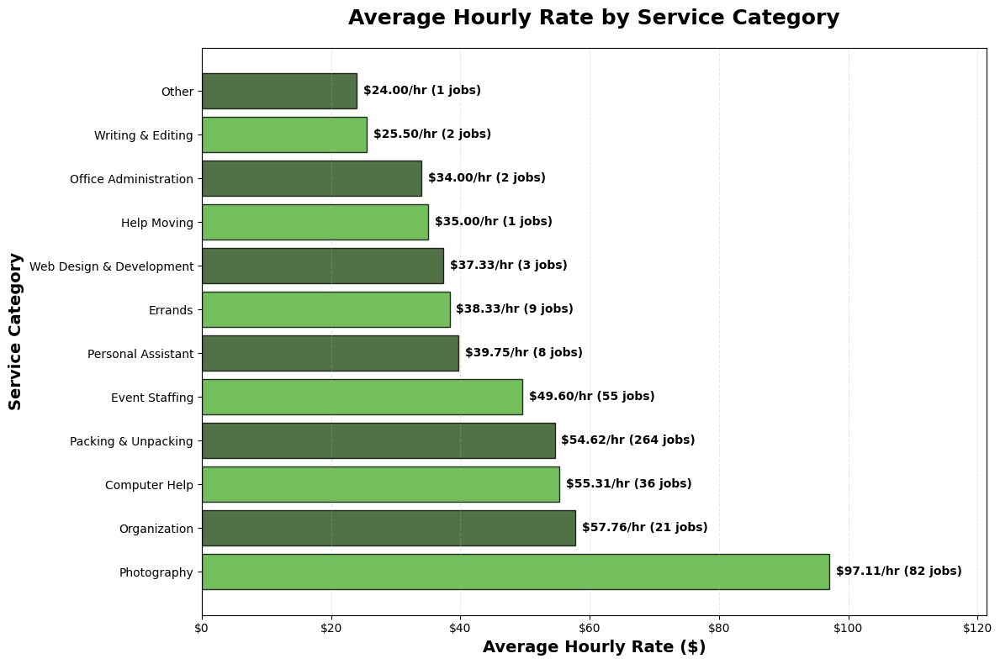

✓ Service Category Hourly Rate chart saved

SERVICE CATEGORY RANKINGS BY HOURLY RATE
Photography                    $ 97.11/hr  (82 jobs)
Organization                   $ 57.76/hr  (21 jobs)
Computer Help                  $ 55.31/hr  (36 jobs)
Packing & Unpacking            $ 54.62/hr  (264 jobs)
Event Staffing                 $ 49.60/hr  (55 jobs)
Personal Assistant             $ 39.75/hr  (8 jobs)
Errands                        $ 38.33/hr  (9 jobs)
Web Design & Development       $ 37.33/hr  (3 jobs)
Help Moving                    $ 35.00/hr  (1 jobs)
Office Administration          $ 34.00/hr  (2 jobs)
Writing & Editing              $ 25.50/hr  (2 jobs)
Other                          $ 24.00/hr  (1 jobs)


In [ ]:
# Calculate metrics by service category
df['Gross_Hourly_Rate'] = df['Earnings'] / df['Hours']
df_clean = df[(df['Gross_Hourly_Rate'] > 0) & (df['Gross_Hourly_Rate'] < np.inf)].copy()

# Group by service category
service_metrics = df_clean.groupby('Service_Category').agg({
    'Gross_Hourly_Rate': 'mean',
    'Earnings': 'count'  # Number of jobs
}).reset_index()

service_metrics.columns = ['Service_Category', 'Avg_Hourly_Rate', 'Job_Count']

# Sort by hourly rate (highest to lowest)
service_metrics = service_metrics.sort_values('Avg_Hourly_Rate', ascending=False)

# Create horizontal bar chart
fig, ax = plt.subplots(figsize=(12, 8))

# Create bars with TaskRabbit colors alternating
colors = ['#50AF33' if i % 2 == 0 else '#264F18' for i in range(len(service_metrics))]

bars = ax.barh(service_metrics['Service_Category'], service_metrics['Avg_Hourly_Rate'], 
               color=colors, alpha=0.8, edgecolor='black', linewidth=1)

# Add value labels at the end of each bar
for i, (bar, rate, count) in enumerate(zip(bars, service_metrics['Avg_Hourly_Rate'], service_metrics['Job_Count'])):
    width = bar.get_width()
    ax.text(width + 1, bar.get_y() + bar.get_height()/2,
            f'${rate:.2f}/hr ({int(count)} jobs)',
            ha='left', va='center', fontsize=10, fontweight='bold')

# Styling
ax.set_title('Average Hourly Rate by Service Category', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Average Hourly Rate ($)', fontsize=14, fontweight='bold')
ax.set_ylabel('Service Category', fontsize=14, fontweight='bold')

# Format x-axis to show dollars
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--', axis='x')

# Add 25% breathing room on the right
max_rate = service_metrics['Avg_Hourly_Rate'].max()
ax.set_xlim(0, max_rate * 1.25)

plt.tight_layout()
plt.savefig('../visualizations/service_category_hourly_rate.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Service Category Hourly Rate chart saved")

# Print summary
print("\n" + "="*80)
print("SERVICE CATEGORY RANKINGS BY HOURLY RATE")
print("="*80)
for idx, row in service_metrics.iterrows():
    print(f"{row['Service_Category']:30} ${row['Avg_Hourly_Rate']:6.2f}/hr  ({int(row['Job_Count'])} jobs)")

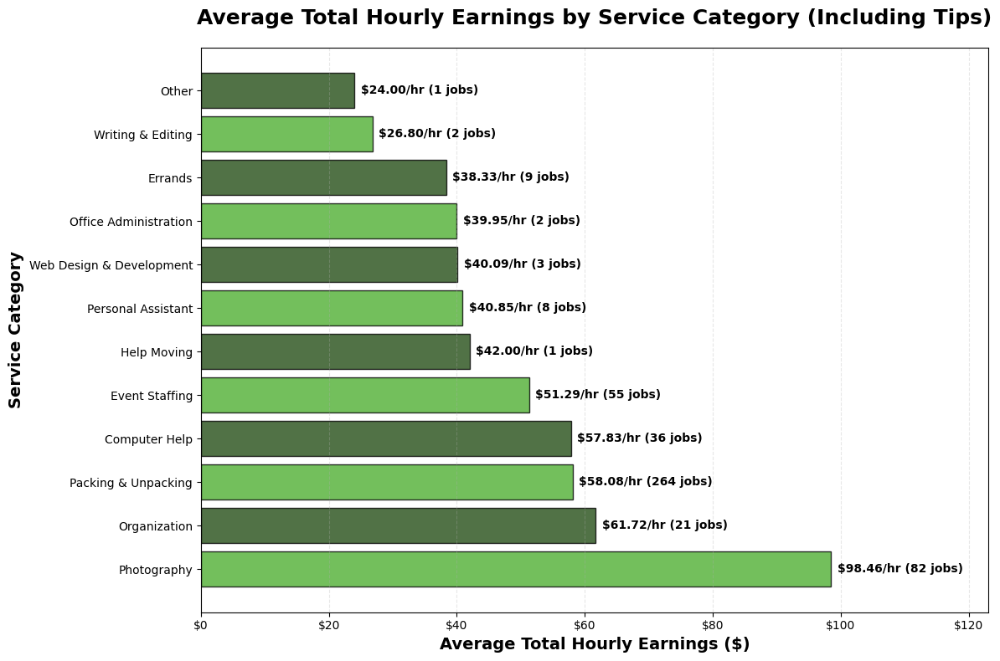

✓ Service Category Total Hourly Earnings chart saved

SERVICE CATEGORY RANKINGS BY TOTAL HOURLY EARNINGS (INCL. TIPS)
Photography                    $ 98.46/hr  (82 jobs)
Organization                   $ 61.72/hr  (21 jobs)
Packing & Unpacking            $ 58.08/hr  (264 jobs)
Computer Help                  $ 57.83/hr  (36 jobs)
Event Staffing                 $ 51.29/hr  (55 jobs)
Help Moving                    $ 42.00/hr  (1 jobs)
Personal Assistant             $ 40.85/hr  (8 jobs)
Web Design & Development       $ 40.09/hr  (3 jobs)
Office Administration          $ 39.95/hr  (2 jobs)
Errands                        $ 38.33/hr  (9 jobs)
Writing & Editing              $ 26.80/hr  (2 jobs)
Other                          $ 24.00/hr  (1 jobs)


In [ ]:
# Calculate total hourly earnings (Earnings + Tips) / Hours
df['Total_Hourly_Earnings'] = (df['Earnings'] + df['Tip']) / df['Hours']
df_clean = df[(df['Total_Hourly_Earnings'] > 0) & (df['Total_Hourly_Earnings'] < np.inf)].copy()

# Group by service category
service_metrics_total = df_clean.groupby('Service_Category').agg({
    'Total_Hourly_Earnings': 'mean',
    'Earnings': 'count'  # Number of jobs
}).reset_index()

service_metrics_total.columns = ['Service_Category', 'Avg_Total_Hourly_Earnings', 'Job_Count']

# Sort by total hourly earnings (highest to lowest)
service_metrics_total = service_metrics_total.sort_values('Avg_Total_Hourly_Earnings', ascending=False)

# Create horizontal bar chart
fig, ax = plt.subplots(figsize=(12, 8))

# Create bars with TaskRabbit colors alternating
colors = ['#50AF33' if i % 2 == 0 else '#264F18' for i in range(len(service_metrics_total))]

bars = ax.barh(service_metrics_total['Service_Category'], service_metrics_total['Avg_Total_Hourly_Earnings'], 
               color=colors, alpha=0.8, edgecolor='black', linewidth=1)

# Add value labels at the end of each bar
for i, (bar, rate, count) in enumerate(zip(bars, service_metrics_total['Avg_Total_Hourly_Earnings'], service_metrics_total['Job_Count'])):
    width = bar.get_width()
    ax.text(width + 1, bar.get_y() + bar.get_height()/2,
            f'${rate:.2f}/hr ({int(count)} jobs)',
            ha='left', va='center', fontsize=10, fontweight='bold')

# Styling
ax.set_title('Average Total Hourly Earnings by Service Category (Including Tips)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Average Total Hourly Earnings ($)', fontsize=14, fontweight='bold')
ax.set_ylabel('Service Category', fontsize=14, fontweight='bold')

# Format x-axis to show dollars
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--', axis='x')

# Add 25% breathing room on the right
max_rate = service_metrics_total['Avg_Total_Hourly_Earnings'].max()
ax.set_xlim(0, max_rate * 1.25)

plt.tight_layout()
plt.savefig('../visualizations/service_category_total_hourly_earnings.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Service Category Total Hourly Earnings chart saved")

# Print summary
print("\n" + "="*80)
print("SERVICE CATEGORY RANKINGS BY TOTAL HOURLY EARNINGS (INCL. TIPS)")
print("="*80)
for idx, row in service_metrics_total.iterrows():
    print(f"{row['Service_Category']:30} ${row['Avg_Total_Hourly_Earnings']:6.2f}/hr  ({int(row['Job_Count'])} jobs)")

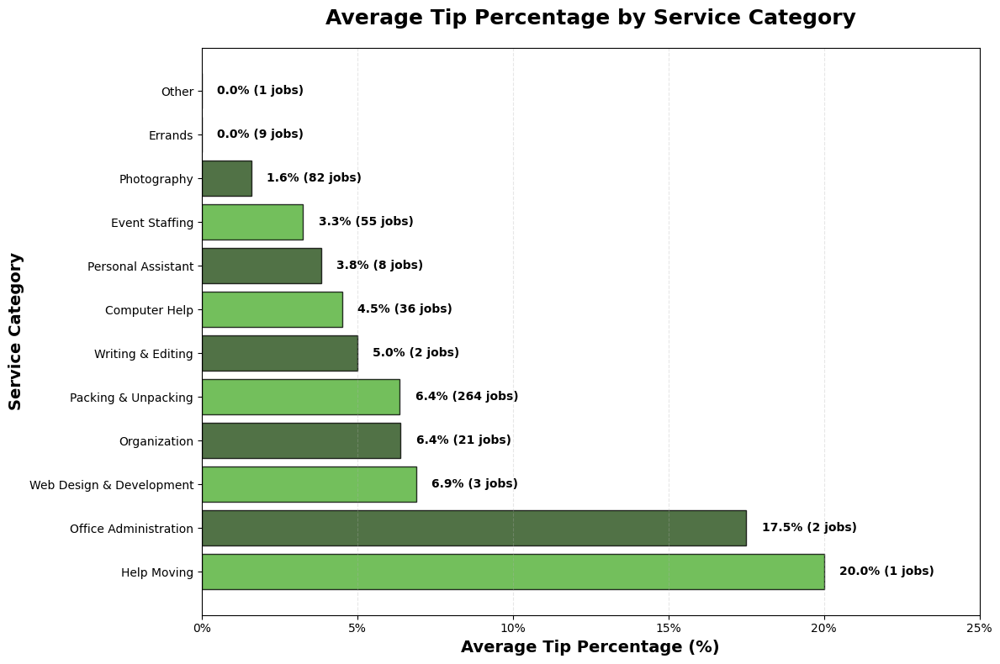

✓ Service Category Tip Percentage chart saved

SERVICE CATEGORY RANKINGS BY TIP PERCENTAGE
Help Moving                     20.0%  (1 jobs)
Office Administration           17.5%  (2 jobs)
Web Design & Development         6.9%  (3 jobs)
Organization                     6.4%  (21 jobs)
Packing & Unpacking              6.4%  (264 jobs)
Writing & Editing                5.0%  (2 jobs)
Computer Help                    4.5%  (36 jobs)
Personal Assistant               3.8%  (8 jobs)
Event Staffing                   3.3%  (55 jobs)
Photography                      1.6%  (82 jobs)
Errands                          0.0%  (9 jobs)
Other                            0.0%  (1 jobs)


In [ ]:
# Calculate tip percentage for each job
df['Tip_Percentage'] = (df['Tip'] / df['Earnings']) * 100

# Clean data - only jobs with positive earnings
df_tip_clean = df[(df['Earnings'] > 0) & (df['Tip_Percentage'] >= 0) & (df['Tip_Percentage'] < np.inf)].copy()

# Group by service category
service_tip_metrics = df_tip_clean.groupby('Service_Category').agg({
    'Tip_Percentage': 'mean',
    'Earnings': 'count'  # Number of jobs
}).reset_index()

service_tip_metrics.columns = ['Service_Category', 'Avg_Tip_Percentage', 'Job_Count']

# Sort by tip percentage (highest to lowest)
service_tip_metrics = service_tip_metrics.sort_values('Avg_Tip_Percentage', ascending=False)

# Create horizontal bar chart
fig, ax = plt.subplots(figsize=(12, 8))

# Create bars with TaskRabbit colors alternating
colors = ['#50AF33' if i % 2 == 0 else '#264F18' for i in range(len(service_tip_metrics))]

bars = ax.barh(service_tip_metrics['Service_Category'], service_tip_metrics['Avg_Tip_Percentage'], 
               color=colors, alpha=0.8, edgecolor='black', linewidth=1)

# Add value labels at the end of each bar
for i, (bar, pct, count) in enumerate(zip(bars, service_tip_metrics['Avg_Tip_Percentage'], service_tip_metrics['Job_Count'])):
    width = bar.get_width()
    ax.text(width + 0.5, bar.get_y() + bar.get_height()/2,
            f'{pct:.1f}% ({int(count)} jobs)',
            ha='left', va='center', fontsize=10, fontweight='bold')

# Styling
ax.set_title('Average Tip Percentage by Service Category', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Average Tip Percentage (%)', fontsize=14, fontweight='bold')
ax.set_ylabel('Service Category', fontsize=14, fontweight='bold')

# Format x-axis to show percentages
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x:.0f}%'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--', axis='x')

# Add 25% breathing room on the right
max_pct = service_tip_metrics['Avg_Tip_Percentage'].max()
ax.set_xlim(0, max_pct * 1.25)

plt.tight_layout()
plt.savefig('../visualizations/service_category_tip_percentage.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Service Category Tip Percentage chart saved")

# Print summary
print("\n" + "="*80)
print("SERVICE CATEGORY RANKINGS BY TIP PERCENTAGE")
print("="*80)
for idx, row in service_tip_metrics.iterrows():
    print(f"{row['Service_Category']:30} {row['Avg_Tip_Percentage']:5.1f}%  ({int(row['Job_Count'])} jobs)")

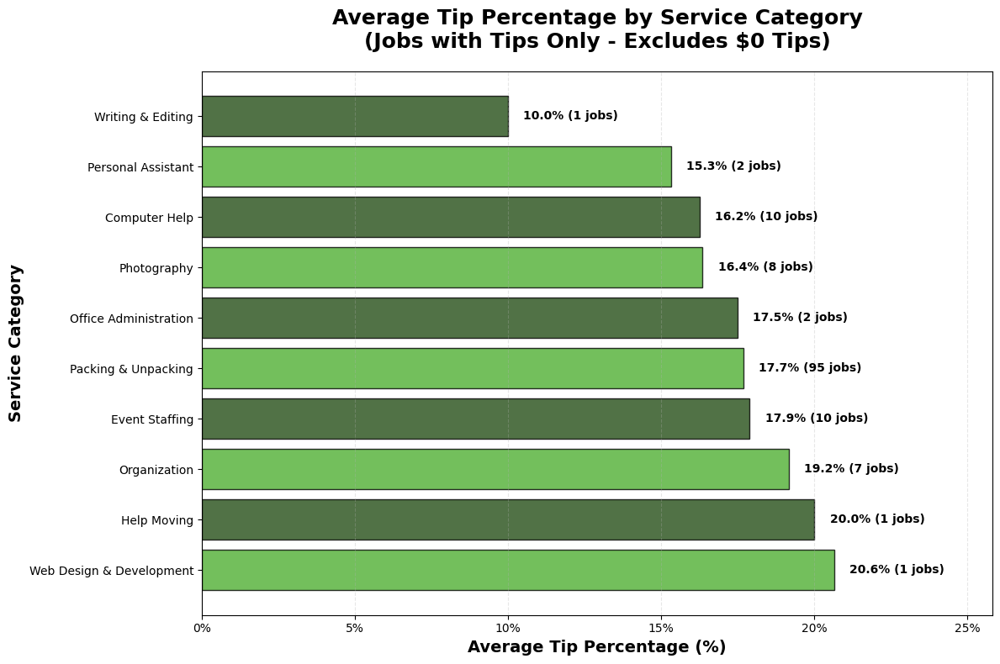

✓ Service Category Tip Percentage chart saved (Jobs with Tips Only)

SERVICE CATEGORY RANKINGS BY TIP PERCENTAGE (JOBS WITH TIPS ONLY)
Web Design & Development        20.6%  (1/3 jobs = 33% tipped)
Help Moving                     20.0%  (1/1 jobs = 100% tipped)
Organization                    19.2%  (7/21 jobs = 33% tipped)
Event Staffing                  17.9%  (10/55 jobs = 18% tipped)
Packing & Unpacking             17.7%  (95/264 jobs = 36% tipped)
Office Administration           17.5%  (2/2 jobs = 100% tipped)
Photography                     16.4%  (8/82 jobs = 10% tipped)
Computer Help                   16.2%  (10/36 jobs = 28% tipped)
Personal Assistant              15.3%  (2/8 jobs = 25% tipped)
Writing & Editing               10.0%  (1/2 jobs = 50% tipped)


In [ ]:
# Calculate tip percentage for jobs that received tips ONLY
df['Tip_Percentage'] = (df['Tip'] / df['Earnings']) * 100

# Clean data - ONLY jobs with tips (Tip > 0)
df_tip_clean = df[(df['Earnings'] > 0) & (df['Tip'] > 0) & (df['Tip_Percentage'] < np.inf)].copy()

# Group by service category
service_tip_metrics = df_tip_clean.groupby('Service_Category').agg({
    'Tip_Percentage': 'mean',
    'Earnings': 'count'  # Number of jobs WITH tips
}).reset_index()

service_tip_metrics.columns = ['Service_Category', 'Avg_Tip_Percentage', 'Job_Count']

# Sort by tip percentage (highest to lowest)
service_tip_metrics = service_tip_metrics.sort_values('Avg_Tip_Percentage', ascending=False)

# Create horizontal bar chart
fig, ax = plt.subplots(figsize=(12, 8))

# Create bars with TaskRabbit colors alternating
colors = ['#50AF33' if i % 2 == 0 else '#264F18' for i in range(len(service_tip_metrics))]

bars = ax.barh(service_tip_metrics['Service_Category'], service_tip_metrics['Avg_Tip_Percentage'], 
               color=colors, alpha=0.8, edgecolor='black', linewidth=1)

# Add value labels at the end of each bar
for i, (bar, pct, count) in enumerate(zip(bars, service_tip_metrics['Avg_Tip_Percentage'], service_tip_metrics['Job_Count'])):
    width = bar.get_width()
    ax.text(width + 0.5, bar.get_y() + bar.get_height()/2,
            f'{pct:.1f}% ({int(count)} jobs)',
            ha='left', va='center', fontsize=10, fontweight='bold')

# Styling - Title with subtitle
ax.set_title('Average Tip Percentage by Service Category\n(Jobs with Tips Only - Excludes $0 Tips)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Average Tip Percentage (%)', fontsize=14, fontweight='bold')
ax.set_ylabel('Service Category', fontsize=14, fontweight='bold')

# Format x-axis to show percentages
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x:.0f}%'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--', axis='x')

# Add 25% breathing room on the right
max_pct = service_tip_metrics['Avg_Tip_Percentage'].max()
ax.set_xlim(0, max_pct * 1.25)

plt.tight_layout()
plt.savefig('../visualizations/service_category_tip_percentage.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Service Category Tip Percentage chart saved (Jobs with Tips Only)")

# Print summary
print("\n" + "="*80)
print("SERVICE CATEGORY RANKINGS BY TIP PERCENTAGE (JOBS WITH TIPS ONLY)")
print("="*80)
for idx, row in service_tip_metrics.iterrows():
    # Calculate how many jobs with tips vs total jobs
    total_jobs = len(df[df['Service_Category'] == row['Service_Category']])
    jobs_with_tips = int(row['Job_Count'])
    tip_frequency = (jobs_with_tips / total_jobs * 100) if total_jobs > 0 else 0
    
    print(f"{row['Service_Category']:30} {row['Avg_Tip_Percentage']:5.1f}%  ({jobs_with_tips}/{total_jobs} jobs = {tip_frequency:.0f}% tipped)")

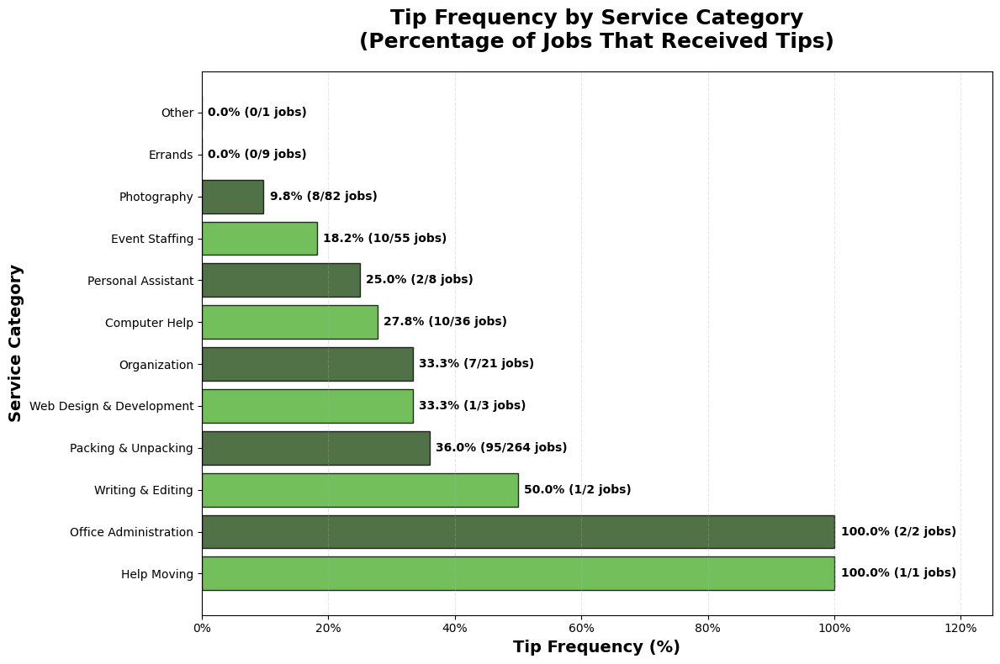

✓ Service Category Tip Frequency chart saved

SERVICE CATEGORY RANKINGS BY TIP FREQUENCY
Help Moving                    100.0%  (1/1 jobs tipped)
Office Administration          100.0%  (2/2 jobs tipped)
Writing & Editing               50.0%  (1/2 jobs tipped)
Packing & Unpacking             36.0%  (95/264 jobs tipped)
Web Design & Development        33.3%  (1/3 jobs tipped)
Organization                    33.3%  (7/21 jobs tipped)
Computer Help                   27.8%  (10/36 jobs tipped)
Personal Assistant              25.0%  (2/8 jobs tipped)
Event Staffing                  18.2%  (10/55 jobs tipped)
Photography                      9.8%  (8/82 jobs tipped)
Errands                          0.0%  (0/9 jobs tipped)
Other                            0.0%  (0/1 jobs tipped)


In [ ]:
# Calculate tip frequency by service category
service_tip_frequency = df.groupby('Service_Category').agg({
    'Tip': lambda x: (x > 0).sum(),  # Count of jobs WITH tips
    'Earnings': 'count'  # Total count of jobs
}).reset_index()

service_tip_frequency.columns = ['Service_Category', 'Jobs_With_Tips', 'Total_Jobs']

# Calculate tip frequency percentage
service_tip_frequency['Tip_Frequency_%'] = (service_tip_frequency['Jobs_With_Tips'] / service_tip_frequency['Total_Jobs']) * 100

# Sort by tip frequency (highest to lowest)
service_tip_frequency = service_tip_frequency.sort_values('Tip_Frequency_%', ascending=False)

# Create horizontal bar chart
fig, ax = plt.subplots(figsize=(12, 8))

# Create bars with TaskRabbit colors alternating
colors = ['#50AF33' if i % 2 == 0 else '#264F18' for i in range(len(service_tip_frequency))]

bars = ax.barh(service_tip_frequency['Service_Category'], service_tip_frequency['Tip_Frequency_%'], 
               color=colors, alpha=0.8, edgecolor='black', linewidth=1)

# Add value labels at the end of each bar
for i, (bar, freq, tipped, total) in enumerate(zip(bars, service_tip_frequency['Tip_Frequency_%'], 
                                                     service_tip_frequency['Jobs_With_Tips'], 
                                                     service_tip_frequency['Total_Jobs'])):
    width = bar.get_width()
    ax.text(width + 1, bar.get_y() + bar.get_height()/2,
            f'{freq:.1f}% ({int(tipped)}/{int(total)} jobs)',
            ha='left', va='center', fontsize=10, fontweight='bold')

# Styling
ax.set_title('Tip Frequency by Service Category\n(Percentage of Jobs That Received Tips)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Tip Frequency (%)', fontsize=14, fontweight='bold')
ax.set_ylabel('Service Category', fontsize=14, fontweight='bold')

# Format x-axis to show percentages
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x:.0f}%'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--', axis='x')

# Add 25% breathing room on the right
max_freq = service_tip_frequency['Tip_Frequency_%'].max()
ax.set_xlim(0, max_freq * 1.25)

plt.tight_layout()
plt.savefig('../visualizations/service_category_tip_frequency.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Service Category Tip Frequency chart saved")

# Print summary
print("\n" + "="*80)
print("SERVICE CATEGORY RANKINGS BY TIP FREQUENCY")
print("="*80)
for idx, row in service_tip_frequency.iterrows():
    print(f"{row['Service_Category']:30} {row['Tip_Frequency_%']:5.1f}%  ({int(row['Jobs_With_Tips'])}/{int(row['Total_Jobs'])} jobs tipped)")

Top 8 Highest Grossing Service Categories:
Packing & Unpacking            $46,991.75
Photography                    $15,823.25
Event Staffing                 $10,249.50
Computer Help                  $5,803.75
Organization                   $3,659.75
Personal Assistant             $994.75
Errands                        $528.00
Office Administration          $195.50




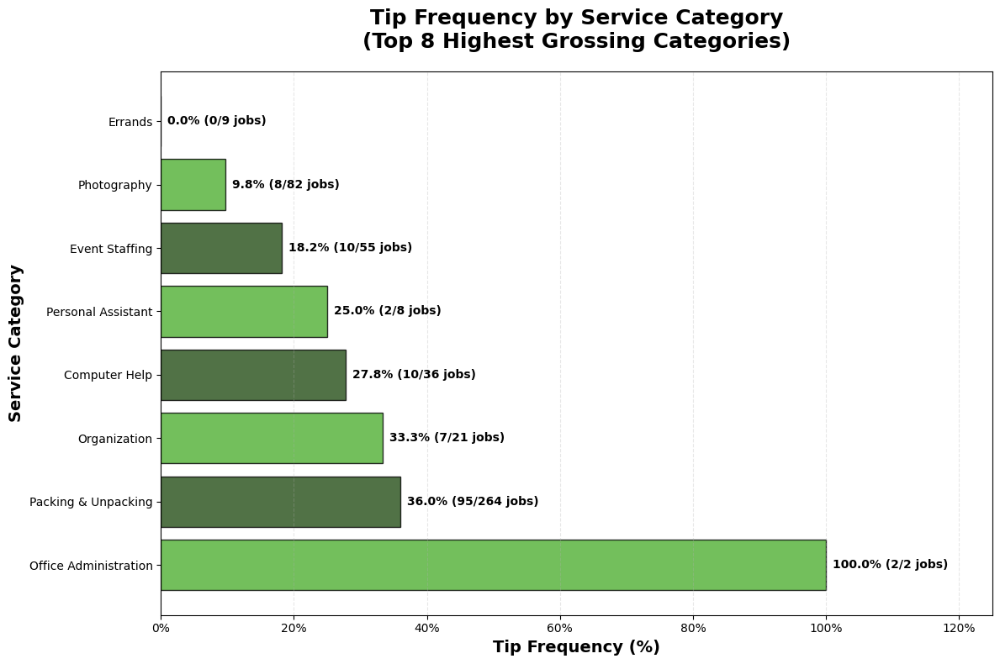

✓ Service Category Tip Frequency (Top 8) chart saved

TIP FREQUENCY FOR TOP 8 HIGHEST GROSSING CATEGORIES
Office Administration          100.0%  (2/2 jobs tipped)
Packing & Unpacking             36.0%  (95/264 jobs tipped)
Organization                    33.3%  (7/21 jobs tipped)
Computer Help                   27.8%  (10/36 jobs tipped)
Personal Assistant              25.0%  (2/8 jobs tipped)
Event Staffing                  18.2%  (10/55 jobs tipped)
Photography                      9.8%  (8/82 jobs tipped)
Errands                          0.0%  (0/9 jobs tipped)


In [ ]:
# Calculate total revenue by service category to find top earners
service_revenue = df.groupby('Service_Category').agg({
    'Earnings': 'sum'  # Total revenue
}).reset_index()

service_revenue.columns = ['Service_Category', 'Total_Revenue']
service_revenue = service_revenue.sort_values('Total_Revenue', ascending=False)

# Get top 8 categories by revenue
top_categories = service_revenue.head(8)['Service_Category'].tolist()

print("Top 8 Highest Grossing Service Categories:")
print("="*60)
for idx, row in service_revenue.head(8).iterrows():
    print(f"{row['Service_Category']:30} ${row['Total_Revenue']:,.2f}")
print("\n")

# Filter data to only top categories
df_top = df[df['Service_Category'].isin(top_categories)].copy()

# Calculate tip frequency for top categories only
service_tip_frequency_top = df_top.groupby('Service_Category').agg({
    'Tip': lambda x: (x > 0).sum(),  # Count of jobs WITH tips
    'Earnings': 'count'  # Total count of jobs
}).reset_index()

service_tip_frequency_top.columns = ['Service_Category', 'Jobs_With_Tips', 'Total_Jobs']

# Calculate tip frequency percentage
service_tip_frequency_top['Tip_Frequency_%'] = (service_tip_frequency_top['Jobs_With_Tips'] / service_tip_frequency_top['Total_Jobs']) * 100

# Sort by tip frequency (highest to lowest)
service_tip_frequency_top = service_tip_frequency_top.sort_values('Tip_Frequency_%', ascending=False)

# Create horizontal bar chart
fig, ax = plt.subplots(figsize=(12, 8))

# Create bars with TaskRabbit colors alternating
colors = ['#50AF33' if i % 2 == 0 else '#264F18' for i in range(len(service_tip_frequency_top))]

bars = ax.barh(service_tip_frequency_top['Service_Category'], service_tip_frequency_top['Tip_Frequency_%'], 
               color=colors, alpha=0.8, edgecolor='black', linewidth=1)

# Add value labels at the end of each bar
for i, (bar, freq, tipped, total) in enumerate(zip(bars, service_tip_frequency_top['Tip_Frequency_%'], 
                                                     service_tip_frequency_top['Jobs_With_Tips'], 
                                                     service_tip_frequency_top['Total_Jobs'])):
    width = bar.get_width()
    ax.text(width + 1, bar.get_y() + bar.get_height()/2,
            f'{freq:.1f}% ({int(tipped)}/{int(total)} jobs)',
            ha='left', va='center', fontsize=10, fontweight='bold')

# Styling
ax.set_title('Tip Frequency by Service Category\n(Top 8 Highest Grossing Categories)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Tip Frequency (%)', fontsize=14, fontweight='bold')
ax.set_ylabel('Service Category', fontsize=14, fontweight='bold')

# Format x-axis to show percentages
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x:.0f}%'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--', axis='x')

# Add 25% breathing room on the right
max_freq = service_tip_frequency_top['Tip_Frequency_%'].max()
ax.set_xlim(0, max_freq * 1.25)

plt.tight_layout()
plt.savefig('../visualizations/service_category_tip_frequency_top8.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Service Category Tip Frequency (Top 8) chart saved")

# Print summary
print("\n" + "="*80)
print("TIP FREQUENCY FOR TOP 8 HIGHEST GROSSING CATEGORIES")
print("="*80)
for idx, row in service_tip_frequency_top.iterrows():
    print(f"{row['Service_Category']:30} {row['Tip_Frequency_%']:5.1f}%  ({int(row['Jobs_With_Tips'])}/{int(row['Total_Jobs'])} jobs tipped)")

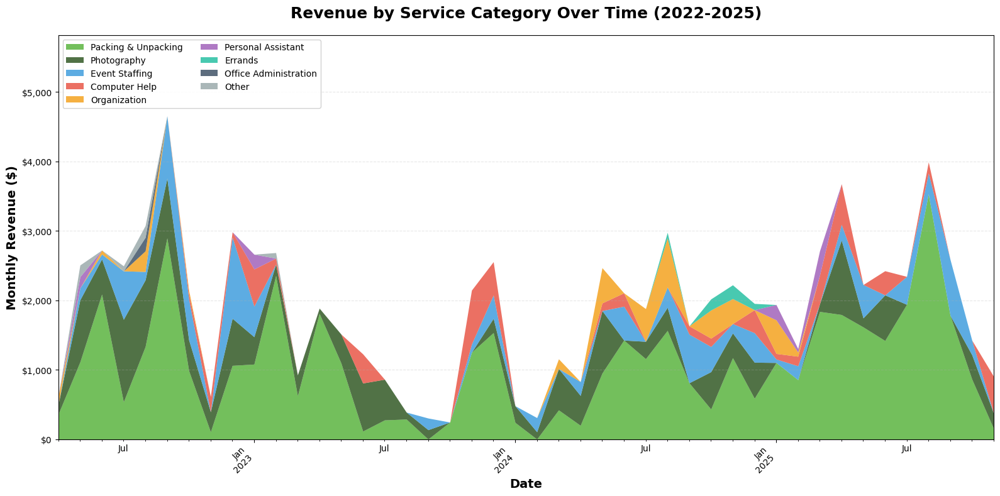

✓ Service Category Revenue Over Time chart saved

REVENUE BY SERVICE CATEGORY (TOP 8 + OTHER)
Packing & Unpacking            $ 46,991.75
Photography                    $ 15,823.25
Event Staffing                 $ 10,249.50
Computer Help                  $  5,803.75
Organization                   $  3,659.75
Personal Assistant             $    994.75
Errands                        $    528.00
Office Administration          $    195.50
Writing & Editing              $    194.00
Web Design & Development       $    179.00
Help Moving                    $     70.00
Other                          $     48.00


In [ ]:
# Prepare data - revenue by service category over time
df_revenue = df[df['Earnings'] > 0].copy()
df_revenue['Year_Month'] = df_revenue['Date'].dt.to_period('M')

# Calculate monthly revenue by service category
monthly_service_revenue = df_revenue.groupby(['Year_Month', 'Service_Category']).agg({
    'Earnings': 'sum'
}).reset_index()

# Pivot to get service categories as columns
revenue_pivot = monthly_service_revenue.pivot(index='Year_Month', columns='Service_Category', values='Earnings').fillna(0)

# Convert Year_Month back to datetime for plotting
revenue_pivot.index = revenue_pivot.index.to_timestamp()

# Get top 8 categories by total revenue (to avoid too many colors)
top_categories = df_revenue.groupby('Service_Category')['Earnings'].sum().nlargest(8).index.tolist()

# Filter to only top categories, group others as "Other"
revenue_pivot_top = revenue_pivot[top_categories].copy()
if len(revenue_pivot.columns) > 8:
    revenue_pivot_top['Other'] = revenue_pivot.drop(columns=top_categories, errors='ignore').sum(axis=1)

# Create stacked area chart
fig, ax = plt.subplots(figsize=(16, 8))

# Define color palette - mix of greens, blues, and other colors
colors = ['#50AF33', '#264F18', '#3498db', '#e74c3c', '#f39c12', 
          '#9b59b6', '#1abc9c', '#34495e', '#95a5a6']

# Create stacked area plot (removed edgecolor parameter)
revenue_pivot_top.plot.area(ax=ax, color=colors[:len(revenue_pivot_top.columns)], 
                             alpha=0.8, linewidth=0)

# Styling
ax.set_title('Revenue by Service Category Over Time (2022-2025)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Date', fontsize=14, fontweight='bold')
ax.set_ylabel('Monthly Revenue ($)', fontsize=14, fontweight='bold')

# Format y-axis to show dollars
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:,.0f}'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--', axis='y')

# Rotate x-axis labels
plt.xticks(rotation=45, ha='right')

# Position legend outside plot area
ax.legend(loc='upper left', fontsize=10, framealpha=0.9, ncol=2)

# Add 25% breathing room at top
max_revenue = revenue_pivot_top.sum(axis=1).max()
ax.set_ylim(0, max_revenue * 1.25)

plt.tight_layout()
plt.savefig('../visualizations/service_category_revenue_over_time.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Service Category Revenue Over Time chart saved")

# Print summary
print("\n" + "="*80)
print("REVENUE BY SERVICE CATEGORY (TOP 8 + OTHER)")
print("="*80)
total_by_category = df_revenue.groupby('Service_Category')['Earnings'].sum().sort_values(ascending=False)
for category, revenue in total_by_category.items():
    print(f"{category:30} ${revenue:>10,.2f}")

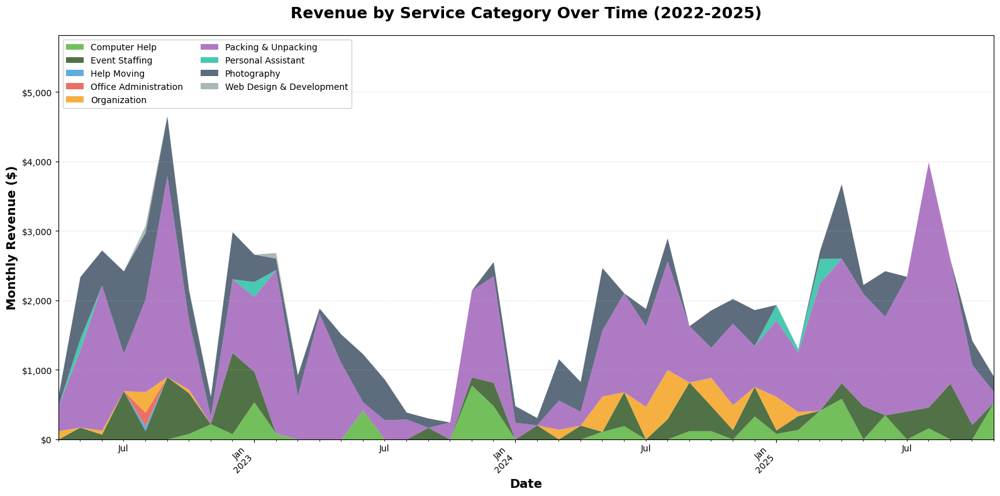

✓ Service Category Revenue Over Time chart saved

REVENUE BY SERVICE CATEGORY (EXCLUDING ERRANDS, WRITING & EDITING, OTHER)
Packing & Unpacking            $ 46,991.75
Photography                    $ 15,823.25
Event Staffing                 $ 10,249.50
Computer Help                  $  5,803.75
Organization                   $  3,659.75
Personal Assistant             $    994.75
Office Administration          $    195.50
Web Design & Development       $    179.00
Help Moving                    $     70.00


In [ ]:
# Prepare data - revenue by service category over time
df_revenue = df[df['Earnings'] > 0].copy()
df_revenue['Year_Month'] = df_revenue['Date'].dt.to_period('M')

# Filter out Errands, Writing & Editing, and Other
exclude_categories = ['Errands', 'Writing & Editing', 'Other']
df_revenue_filtered = df_revenue[~df_revenue['Service_Category'].isin(exclude_categories)].copy()

# Calculate monthly revenue by service category
monthly_service_revenue = df_revenue_filtered.groupby(['Year_Month', 'Service_Category']).agg({
    'Earnings': 'sum'
}).reset_index()

# Pivot to get service categories as columns
revenue_pivot = monthly_service_revenue.pivot(index='Year_Month', columns='Service_Category', values='Earnings').fillna(0)

# Convert Year_Month back to datetime for plotting
revenue_pivot.index = revenue_pivot.index.to_timestamp()

# Create stacked area chart
fig, ax = plt.subplots(figsize=(16, 8))

# Define color palette - mix of greens, blues, and other colors
colors = ['#50AF33', '#264F18', '#3498db', '#e74c3c', '#f39c12', 
          '#9b59b6', '#1abc9c', '#34495e', '#95a5a6']

# Create stacked area plot
revenue_pivot.plot.area(ax=ax, color=colors[:len(revenue_pivot.columns)], 
                        alpha=0.8, linewidth=0)

# Styling
ax.set_title('Revenue by Service Category Over Time (2022-2025)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Date', fontsize=14, fontweight='bold')
ax.set_ylabel('Monthly Revenue ($)', fontsize=14, fontweight='bold')

# Format y-axis to show dollars
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:,.0f}'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--', axis='y')

# Rotate x-axis labels
plt.xticks(rotation=45, ha='right')

# Position legend
ax.legend(loc='upper left', fontsize=10, framealpha=0.9, ncol=2)

# Add 25% breathing room at top
max_revenue = revenue_pivot.sum(axis=1).max()
ax.set_ylim(0, max_revenue * 1.25)

plt.tight_layout()
plt.savefig('../visualizations/service_category_revenue_over_time.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Service Category Revenue Over Time chart saved")

# Print summary
print("\n" + "="*80)
print("REVENUE BY SERVICE CATEGORY (EXCLUDING ERRANDS, WRITING & EDITING, OTHER)")
print("="*80)
total_by_category = df_revenue_filtered.groupby('Service_Category')['Earnings'].sum().sort_values(ascending=False)
for category, revenue in total_by_category.items():
    print(f"{category:30} ${revenue:>10,.2f}")

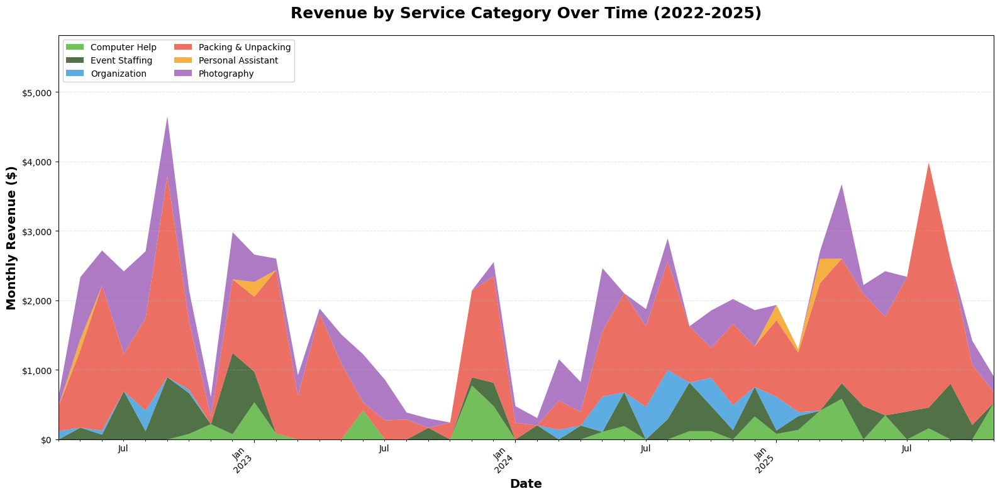

✓ Service Category Revenue Over Time chart saved

REVENUE BY SERVICE CATEGORY (TOP CATEGORIES ONLY)
Packing & Unpacking            $ 46,991.75
Photography                    $ 15,823.25
Event Staffing                 $ 10,249.50
Computer Help                  $  5,803.75
Organization                   $  3,659.75
Personal Assistant             $    994.75

Categories excluded: Errands, Writing & Editing, Other, Office Administration, Web Design & Development, Help Moving


In [ ]:
# Prepare data - revenue by service category over time
df_revenue = df[df['Earnings'] > 0].copy()
df_revenue['Year_Month'] = df_revenue['Date'].dt.to_period('M')

# Filter out specified categories
exclude_categories = ['Errands', 'Writing & Editing', 'Other', 'Office Administration', 
                      'Web Design & Development', 'Help Moving']
df_revenue_filtered = df_revenue[~df_revenue['Service_Category'].isin(exclude_categories)].copy()

# Calculate monthly revenue by service category
monthly_service_revenue = df_revenue_filtered.groupby(['Year_Month', 'Service_Category']).agg({
    'Earnings': 'sum'
}).reset_index()

# Pivot to get service categories as columns
revenue_pivot = monthly_service_revenue.pivot(index='Year_Month', columns='Service_Category', values='Earnings').fillna(0)

# Convert Year_Month back to datetime for plotting
revenue_pivot.index = revenue_pivot.index.to_timestamp()

# Create stacked area chart
fig, ax = plt.subplots(figsize=(16, 8))

# Define color palette - mix of greens, blues, and other colors
colors = ['#50AF33', '#264F18', '#3498db', '#e74c3c', '#f39c12', 
          '#9b59b6', '#1abc9c', '#34495e', '#95a5a6']

# Create stacked area plot
revenue_pivot.plot.area(ax=ax, color=colors[:len(revenue_pivot.columns)], 
                        alpha=0.8, linewidth=0)

# Styling
ax.set_title('Revenue by Service Category Over Time (2022-2025)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Date', fontsize=14, fontweight='bold')
ax.set_ylabel('Monthly Revenue ($)', fontsize=14, fontweight='bold')

# Format y-axis to show dollars
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:,.0f}'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--', axis='y')

# Rotate x-axis labels
plt.xticks(rotation=45, ha='right')

# Position legend
ax.legend(loc='upper left', fontsize=10, framealpha=0.9, ncol=2)

# Add 25% breathing room at top
max_revenue = revenue_pivot.sum(axis=1).max()
ax.set_ylim(0, max_revenue * 1.25)

plt.tight_layout()
plt.savefig('../visualizations/service_category_revenue_over_time.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Service Category Revenue Over Time chart saved")

# Print summary
print("\n" + "="*80)
print("REVENUE BY SERVICE CATEGORY (TOP CATEGORIES ONLY)")
print("="*80)
total_by_category = df_revenue_filtered.groupby('Service_Category')['Earnings'].sum().sort_values(ascending=False)
for category, revenue in total_by_category.items():
    print(f"{category:30} ${revenue:>10,.2f}")
print(f"\nCategories excluded: {', '.join(exclude_categories)}")

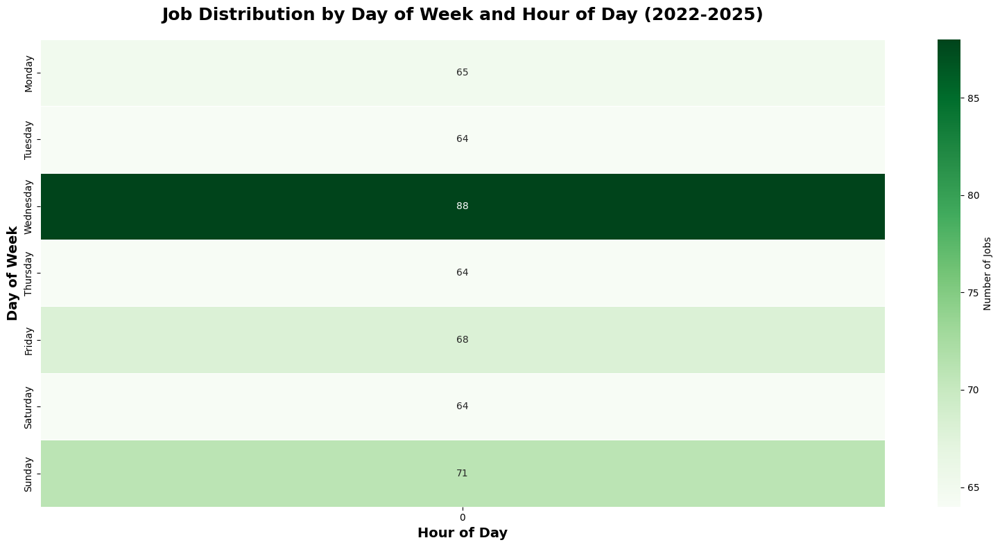

✓ Jobs Heatmap (Day/Hour) saved

BUSIEST TIMES

Top 5 busiest day/hour combinations:
Wednesday  at 00:00 - 88 jobs
Sunday     at 00:00 - 71 jobs
Friday     at 00:00 - 68 jobs
Monday     at 00:00 - 65 jobs
Saturday   at 00:00 - 64 jobs


In [ ]:
# Task 2.4: Time-Based Analysis - Heatmap

# Extract day of week and hour from Date
df['Day_of_Week'] = df['Date'].dt.day_name()
df['Hour'] = df['Date'].dt.hour

# Create pivot table for heatmap
heatmap_data = df.groupby(['Day_of_Week', 'Hour']).size().reset_index(name='Job_Count')

# Pivot for heatmap format
heatmap_pivot = heatmap_data.pivot(index='Day_of_Week', columns='Hour', values='Job_Count').fillna(0)

# Reorder days of week properly (Monday first)
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
heatmap_pivot = heatmap_pivot.reindex(day_order)

# Create heatmap
fig, ax = plt.subplots(figsize=(16, 8))

# Use a green color scheme (TaskRabbit themed)
import seaborn as sns
sns.heatmap(heatmap_pivot, cmap='Greens', annot=True, fmt='.0f', 
            linewidths=0.5, cbar_kws={'label': 'Number of Jobs'},
            ax=ax)

# Styling
ax.set_title('Job Distribution by Day of Week and Hour of Day (2022-2025)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Hour of Day', fontsize=14, fontweight='bold')
ax.set_ylabel('Day of Week', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.savefig('../visualizations/jobs_heatmap_day_hour.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Jobs Heatmap (Day/Hour) saved")

# Print summary stats
print("\n" + "="*80)
print("BUSIEST TIMES")
print("="*80)
print("\nTop 5 busiest day/hour combinations:")
top_times = heatmap_data.nlargest(5, 'Job_Count')
for idx, row in top_times.iterrows():
    print(f"{row['Day_of_Week']:10} at {int(row['Hour']):02d}:00 - {int(row['Job_Count'])} jobs")

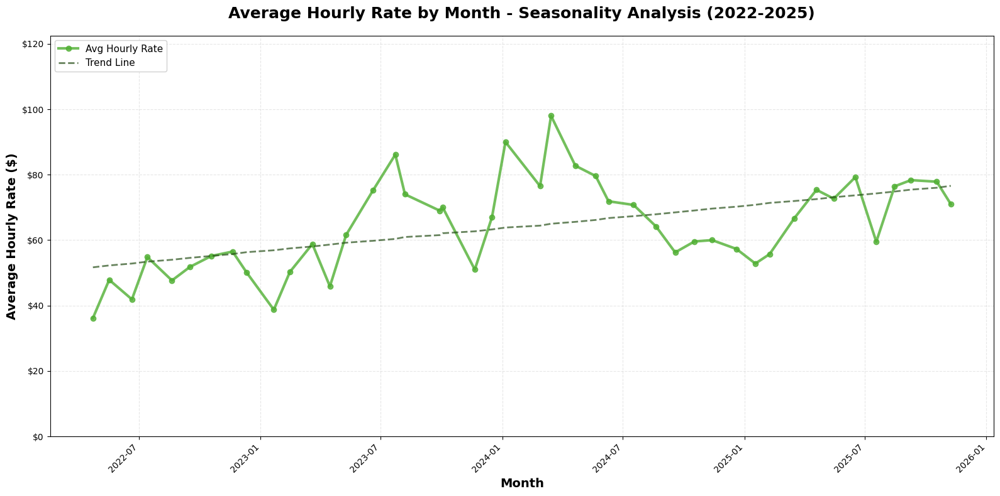

✓ Hourly Rate Seasonality chart saved

SEASONALITY ANALYSIS - AVERAGE HOURLY RATE BY MONTH

Average hourly rate by calendar month (all years combined):
January      $ 48.84/hr
February     $ 53.77/hr
March        $ 71.78/hr
April        $ 59.56/hr
May          $ 64.72/hr
June         $ 63.22/hr
July         $ 64.19/hr
August       $ 62.67/hr
September    $ 59.13/hr
October      $ 61.63/hr
November     $ 59.27/hr
December     $ 56.00/hr

Best month: March ($71.78/hr)
Worst month: January ($48.84/hr)


In [ ]:
# Task 2.4: Time-Based Analysis - Seasonality Chart

# Calculate monthly average hourly rate
df['Gross_Hourly_Rate'] = df['Earnings'] / df['Hours']
df_clean = df[(df['Gross_Hourly_Rate'] > 0) & (df['Gross_Hourly_Rate'] < np.inf)].copy()

df_clean['Year_Month'] = df_clean['Date'].dt.to_period('M')
df_clean['Month_Name'] = df_clean['Date'].dt.month_name()
df_clean['Month_Num'] = df_clean['Date'].dt.month
df_clean['Year'] = df_clean['Date'].dt.year

# Calculate average hourly rate by month
monthly_rates = df_clean.groupby('Year_Month').agg({
    'Gross_Hourly_Rate': 'mean',
    'Date': 'mean'
}).reset_index()

monthly_rates.columns = ['Year_Month', 'Avg_Hourly_Rate', 'Date']

# Create line chart
fig, ax = plt.subplots(figsize=(16, 8))

# Plot line with markers
ax.plot(monthly_rates['Date'], monthly_rates['Avg_Hourly_Rate'], 
        color='#50AF33', linewidth=3, marker='o', markersize=6, 
        label='Avg Hourly Rate', alpha=0.8)

# Add trend line
x_numeric = np.arange(len(monthly_rates))
z = np.polyfit(x_numeric, monthly_rates['Avg_Hourly_Rate'], 1)
p = np.poly1d(z)
ax.plot(monthly_rates['Date'], p(x_numeric), 
        color='#264F18', linewidth=2, linestyle='--', 
        label='Trend Line', alpha=0.7)

# Styling
ax.set_title('Average Hourly Rate by Month - Seasonality Analysis (2022-2025)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Month', fontsize=14, fontweight='bold')
ax.set_ylabel('Average Hourly Rate ($)', fontsize=14, fontweight='bold')

# Format y-axis to show dollars
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--')

# Rotate x-axis labels
plt.xticks(rotation=45, ha='right')

# Add legend
ax.legend(loc='upper left', fontsize=11, framealpha=0.9)

# Add 25% breathing room at top
max_rate = monthly_rates['Avg_Hourly_Rate'].max()
ax.set_ylim(0, max_rate * 1.25)

plt.tight_layout()
plt.savefig('../visualizations/hourly_rate_seasonality.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Hourly Rate Seasonality chart saved")

# Analyze seasonality by month (across all years)
print("\n" + "="*80)
print("SEASONALITY ANALYSIS - AVERAGE HOURLY RATE BY MONTH")
print("="*80)
monthly_seasonality = df_clean.groupby('Month_Name').agg({
    'Gross_Hourly_Rate': 'mean',
    'Month_Num': 'first'
}).reset_index()

monthly_seasonality = monthly_seasonality.sort_values('Month_Num')

print("\nAverage hourly rate by calendar month (all years combined):")
for idx, row in monthly_seasonality.iterrows():
    print(f"{row['Month_Name']:12} ${row['Gross_Hourly_Rate']:6.2f}/hr")

# Identify highest and lowest months
best_month = monthly_seasonality.loc[monthly_seasonality['Gross_Hourly_Rate'].idxmax()]
worst_month = monthly_seasonality.loc[monthly_seasonality['Gross_Hourly_Rate'].idxmin()]

print(f"\nBest month: {best_month['Month_Name']} (${best_month['Gross_Hourly_Rate']:.2f}/hr)")
print(f"Worst month: {worst_month['Month_Name']} (${worst_month['Gross_Hourly_Rate']:.2f}/hr)")

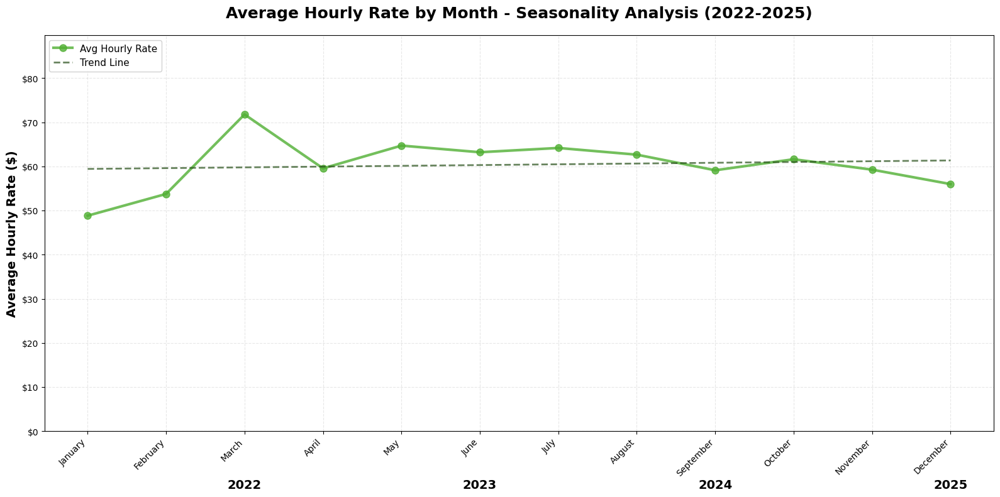

✓ Hourly Rate Seasonality chart saved

SEASONALITY ANALYSIS - AVERAGE HOURLY RATE BY MONTH

Average hourly rate by calendar month (2022-2025 combined):
January      $ 48.84/hr
February     $ 53.77/hr
March        $ 71.78/hr
April        $ 59.56/hr
May          $ 64.72/hr
June         $ 63.22/hr
July         $ 64.19/hr
August       $ 62.67/hr
September    $ 59.13/hr
October      $ 61.63/hr
November     $ 59.27/hr
December     $ 56.00/hr

Best month: March ($71.78/hr)
Worst month: January ($48.84/hr)


In [ ]:
# Task 2.4: Time-Based Analysis - Seasonality Chart

# Calculate monthly average hourly rate
df['Gross_Hourly_Rate'] = df['Earnings'] / df['Hours']
df_clean = df[(df['Gross_Hourly_Rate'] > 0) & (df['Gross_Hourly_Rate'] < np.inf)].copy()

df_clean['Month_Name'] = df_clean['Date'].dt.month_name()
df_clean['Month_Num'] = df_clean['Date'].dt.month
df_clean['Year'] = df_clean['Date'].dt.year

# Calculate average hourly rate by month (aggregated across all years)
monthly_seasonality = df_clean.groupby('Month_Num').agg({
    'Gross_Hourly_Rate': 'mean',
    'Month_Name': 'first'
}).reset_index()

monthly_seasonality = monthly_seasonality.sort_values('Month_Num')

# Create line chart
fig, ax = plt.subplots(figsize=(16, 8))

# Plot line with markers
ax.plot(monthly_seasonality['Month_Num'], monthly_seasonality['Gross_Hourly_Rate'], 
        color='#50AF33', linewidth=3, marker='o', markersize=8, 
        label='Avg Hourly Rate', alpha=0.8)

# Add trend line
x_numeric = np.arange(len(monthly_seasonality))
z = np.polyfit(monthly_seasonality['Month_Num'], monthly_seasonality['Gross_Hourly_Rate'], 1)
p = np.poly1d(z)
ax.plot(monthly_seasonality['Month_Num'], p(monthly_seasonality['Month_Num']), 
        color='#264F18', linewidth=2, linestyle='--', 
        label='Trend Line', alpha=0.7)

# Styling
ax.set_title('Average Hourly Rate by Month - Seasonality Analysis (2022-2025)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_ylabel('Average Hourly Rate ($)', fontsize=14, fontweight='bold')

# Format y-axis to show dollars
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--')

# Set x-axis - month names
month_names = monthly_seasonality['Month_Name'].tolist()
ax.set_xticks(monthly_seasonality['Month_Num'])
ax.set_xticklabels(month_names, rotation=45, ha='right')

# Add year labels below, centered
# Calculate center position for each year (between months 6 and 7)
years = sorted(df_clean['Year'].unique())
for i, year in enumerate(years):
    # Position years at quarters: 1.5, 4.5, 7.5, 10.5
    year_position = 3 * i + 1.5  # Spread across the 12 months
    if year_position <= 12:
        ax.text(year_position + 1.5, -0.12, str(year), 
                transform=ax.get_xaxis_transform(),
                ha='center', va='top', fontsize=14, fontweight='bold')

# Add legend
ax.legend(loc='upper left', fontsize=11, framealpha=0.9)

# Add 25% breathing room at top
max_rate = monthly_seasonality['Gross_Hourly_Rate'].max()
ax.set_ylim(0, max_rate * 1.25)

plt.tight_layout()
plt.savefig('../visualizations/hourly_rate_seasonality.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Hourly Rate Seasonality chart saved")

# Analyze seasonality
print("\n" + "="*80)
print("SEASONALITY ANALYSIS - AVERAGE HOURLY RATE BY MONTH")
print("="*80)

print("\nAverage hourly rate by calendar month (2022-2025 combined):")
for idx, row in monthly_seasonality.iterrows():
    print(f"{row['Month_Name']:12} ${row['Gross_Hourly_Rate']:6.2f}/hr")

# Identify highest and lowest months
best_month = monthly_seasonality.loc[monthly_seasonality['Gross_Hourly_Rate'].idxmax()]
worst_month = monthly_seasonality.loc[monthly_seasonality['Gross_Hourly_Rate'].idxmin()]

print(f"\nBest month: {best_month['Month_Name']} (${best_month['Gross_Hourly_Rate']:.2f}/hr)")
print(f"Worst month: {worst_month['Month_Name']} (${worst_month['Gross_Hourly_Rate']:.2f}/hr)")

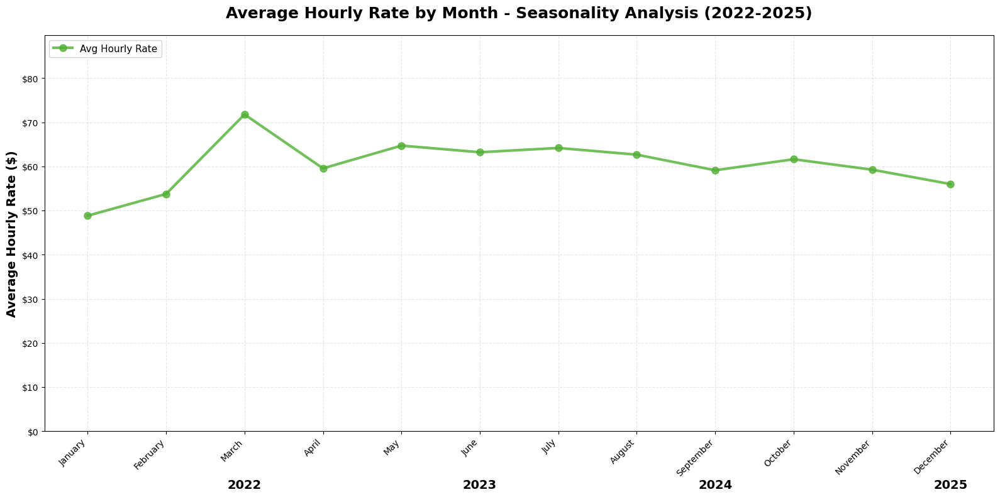

✓ Hourly Rate Seasonality chart saved

SEASONALITY ANALYSIS - AVERAGE HOURLY RATE BY MONTH

Average hourly rate by calendar month (2022-2025 combined):
January      $ 48.84/hr
February     $ 53.77/hr
March        $ 71.78/hr
April        $ 59.56/hr
May          $ 64.72/hr
June         $ 63.22/hr
July         $ 64.19/hr
August       $ 62.67/hr
September    $ 59.13/hr
October      $ 61.63/hr
November     $ 59.27/hr
December     $ 56.00/hr

Best month: March ($71.78/hr)
Worst month: January ($48.84/hr)


In [ ]:
# Task 2.4: Time-Based Analysis - Seasonality Chart

# Calculate monthly average hourly rate
df['Gross_Hourly_Rate'] = df['Earnings'] / df['Hours']
df_clean = df[(df['Gross_Hourly_Rate'] > 0) & (df['Gross_Hourly_Rate'] < np.inf)].copy()

df_clean['Month_Name'] = df_clean['Date'].dt.month_name()
df_clean['Month_Num'] = df_clean['Date'].dt.month
df_clean['Year'] = df_clean['Date'].dt.year

# Calculate average hourly rate by month (aggregated across all years)
monthly_seasonality = df_clean.groupby('Month_Num').agg({
    'Gross_Hourly_Rate': 'mean',
    'Month_Name': 'first'
}).reset_index()

monthly_seasonality = monthly_seasonality.sort_values('Month_Num')

# Create line chart
fig, ax = plt.subplots(figsize=(16, 8))

# Plot line with markers
ax.plot(monthly_seasonality['Month_Num'], monthly_seasonality['Gross_Hourly_Rate'], 
        color='#50AF33', linewidth=3, marker='o', markersize=8, 
        label='Avg Hourly Rate', alpha=0.8)

# Styling
ax.set_title('Average Hourly Rate by Month - Seasonality Analysis (2022-2025)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_ylabel('Average Hourly Rate ($)', fontsize=14, fontweight='bold')

# Format y-axis to show dollars
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--')

# Set x-axis - month names
month_names = monthly_seasonality['Month_Name'].tolist()
ax.set_xticks(monthly_seasonality['Month_Num'])
ax.set_xticklabels(month_names, rotation=45, ha='right')

# Add year labels below, centered
# Calculate center position for each year (between months 6 and 7)
years = sorted(df_clean['Year'].unique())
for i, year in enumerate(years):
    # Position years at quarters: 1.5, 4.5, 7.5, 10.5
    year_position = 3 * i + 1.5  # Spread across the 12 months
    if year_position <= 12:
        ax.text(year_position + 1.5, -0.12, str(year), 
                transform=ax.get_xaxis_transform(),
                ha='center', va='top', fontsize=14, fontweight='bold')

# Add legend
ax.legend(loc='upper left', fontsize=11, framealpha=0.9)

# Add 25% breathing room at top
max_rate = monthly_seasonality['Gross_Hourly_Rate'].max()
ax.set_ylim(0, max_rate * 1.25)

plt.tight_layout()
plt.savefig('../visualizations/hourly_rate_seasonality.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Hourly Rate Seasonality chart saved")

# Analyze seasonality
print("\n" + "="*80)
print("SEASONALITY ANALYSIS - AVERAGE HOURLY RATE BY MONTH")
print("="*80)

print("\nAverage hourly rate by calendar month (2022-2025 combined):")
for idx, row in monthly_seasonality.iterrows():
    print(f"{row['Month_Name']:12} ${row['Gross_Hourly_Rate']:6.2f}/hr")

# Identify highest and lowest months
best_month = monthly_seasonality.loc[monthly_seasonality['Gross_Hourly_Rate'].idxmax()]
worst_month = monthly_seasonality.loc[monthly_seasonality['Gross_Hourly_Rate'].idxmin()]

print(f"\nBest month: {best_month['Month_Name']} (${best_month['Gross_Hourly_Rate']:.2f}/hr)")
print(f"Worst month: {worst_month['Month_Name']} (${worst_month['Gross_Hourly_Rate']:.2f}/hr)")

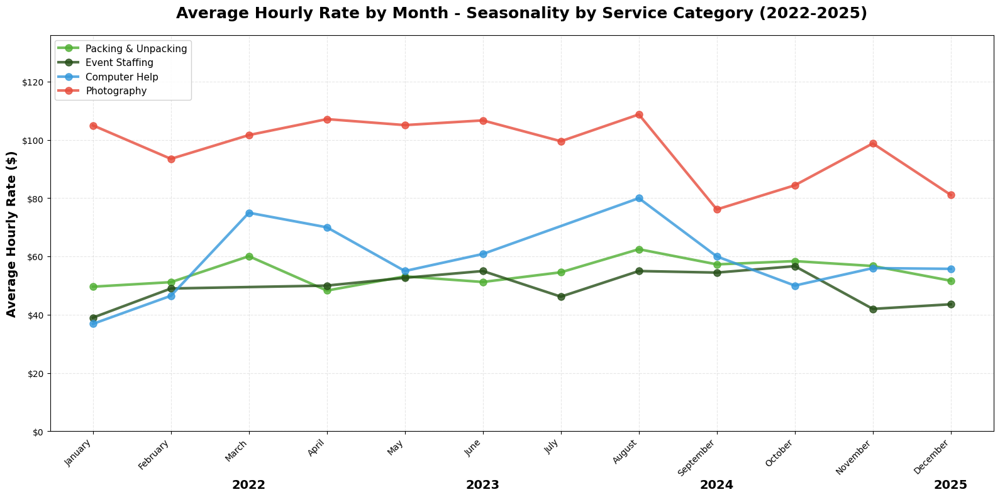

✓ Multi-Category Seasonality chart saved

SEASONALITY ANALYSIS BY SERVICE CATEGORY

Packing & Unpacking:
  Best month: August ($62.49/hr)
  Worst month: April ($48.29/hr)
  Average: $54.56/hr

Event Staffing:
  Best month: October ($56.67/hr)
  Worst month: January ($39.00/hr)
  Average: $49.42/hr

Computer Help:
  Best month: August ($80.00/hr)
  Worst month: January ($36.86/hr)
  Average: $58.72/hr

Photography:
  Best month: August ($108.75/hr)
  Worst month: September ($76.14/hr)
  Average: $97.32/hr


In [ ]:
# Task 2.4: Time-Based Analysis - Multi-Category Seasonality Chart

# Calculate monthly average hourly rate
df['Gross_Hourly_Rate'] = df['Earnings'] / df['Hours']
df_clean = df[(df['Gross_Hourly_Rate'] > 0) & (df['Gross_Hourly_Rate'] < np.inf)].copy()

df_clean['Month_Name'] = df_clean['Date'].dt.month_name()
df_clean['Month_Num'] = df_clean['Date'].dt.month
df_clean['Year'] = df_clean['Date'].dt.year

# Filter to only the four categories
categories = ['Packing & Unpacking', 'Event Staffing', 'Computer Help', 'Photography']
df_four_cats = df_clean[df_clean['Service_Category'].isin(categories)].copy()

# Calculate average hourly rate by month and category
category_seasonality = df_four_cats.groupby(['Month_Num', 'Service_Category']).agg({
    'Gross_Hourly_Rate': 'mean',
    'Month_Name': 'first'
}).reset_index()

# Create line chart
fig, ax = plt.subplots(figsize=(16, 8))

# Define colors for each category
category_colors = {
    'Packing & Unpacking': '#50AF33',      # TaskRabbit light green
    'Event Staffing': '#264F18',            # TaskRabbit dark green
    'Computer Help': '#3498db',             # Blue
    'Photography': '#e74c3c'                # Red
}

# Plot line for each category
for category in categories:
    cat_data = category_seasonality[category_seasonality['Service_Category'] == category].sort_values('Month_Num')
    ax.plot(cat_data['Month_Num'], cat_data['Gross_Hourly_Rate'], 
            color=category_colors[category], linewidth=3, marker='o', markersize=8, 
            label=category, alpha=0.8)

# Styling
ax.set_title('Average Hourly Rate by Month - Seasonality by Service Category (2022-2025)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_ylabel('Average Hourly Rate ($)', fontsize=14, fontweight='bold')

# Format y-axis to show dollars
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--')

# Set x-axis - month names
month_names = ['January', 'February', 'March', 'April', 'May', 'June', 
               'July', 'August', 'September', 'October', 'November', 'December']
ax.set_xticks(range(1, 13))
ax.set_xticklabels(month_names, rotation=45, ha='right')

# Add year labels below, centered
years = sorted(df_clean['Year'].unique())
for i, year in enumerate(years):
    year_position = 3 * i + 1.5
    if year_position <= 12:
        ax.text(year_position + 1.5, -0.12, str(year), 
                transform=ax.get_xaxis_transform(),
                ha='center', va='top', fontsize=14, fontweight='bold')

# Add legend
ax.legend(loc='upper left', fontsize=11, framealpha=0.9)

# Add 25% breathing room at top
max_rate = category_seasonality['Gross_Hourly_Rate'].max()
ax.set_ylim(0, max_rate * 1.25)

plt.tight_layout()
plt.savefig('../visualizations/hourly_rate_seasonality_by_category.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Multi-Category Seasonality chart saved")

# Print summary for each category
print("\n" + "="*80)
print("SEASONALITY ANALYSIS BY SERVICE CATEGORY")
print("="*80)

for category in categories:
    cat_data = category_seasonality[category_seasonality['Service_Category'] == category].sort_values('Month_Num')
    print(f"\n{category}:")
    
    if len(cat_data) > 0:
        best_month = cat_data.loc[cat_data['Gross_Hourly_Rate'].idxmax()]
        worst_month = cat_data.loc[cat_data['Gross_Hourly_Rate'].idxmin()]
        
        print(f"  Best month: {best_month['Month_Name']} (${best_month['Gross_Hourly_Rate']:.2f}/hr)")
        print(f"  Worst month: {worst_month['Month_Name']} (${worst_month['Gross_Hourly_Rate']:.2f}/hr)")
        print(f"  Average: ${cat_data['Gross_Hourly_Rate'].mean():.2f}/hr")
    else:
        print("  No data available")

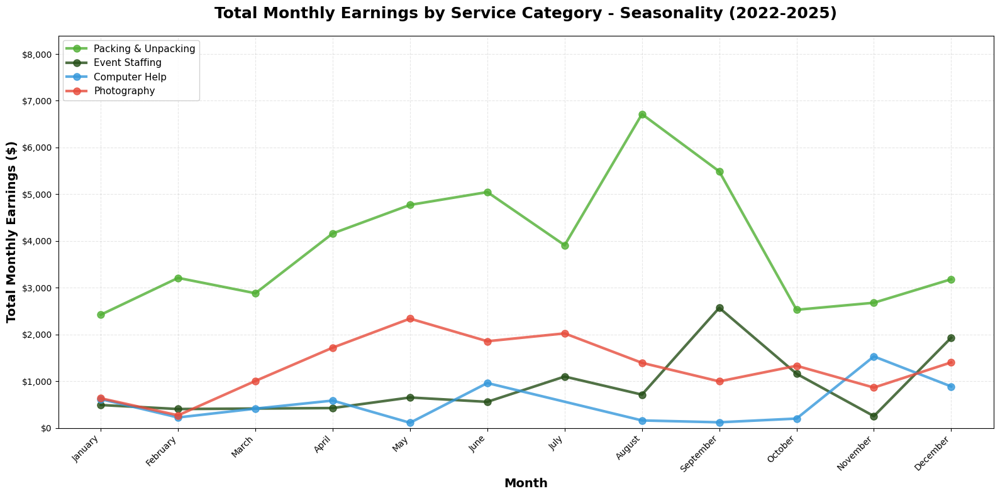

✓ Multi-Category Monthly Earnings Seasonality chart saved

MONTHLY EARNINGS SEASONALITY BY SERVICE CATEGORY

Packing & Unpacking:
  Best month: August ($6,714.50)
  Worst month: January ($2,422.00)
  Total earnings: $46,991.75

Event Staffing:
  Best month: September ($2,569.25)
  Worst month: November ($252.00)
  Total earnings: $10,249.50

Computer Help:
  Best month: November ($1,529.50)
  Worst month: May ($110.00)
  Total earnings: $5,803.75

Photography:
  Best month: May ($2,338.50)
  Worst month: February ($269.00)
  Total earnings: $15,823.25


In [ ]:
# Task 2.4: Time-Based Analysis - Multi-Category Monthly Earnings

# Clean data
df_clean = df[df['Earnings'] > 0].copy()

df_clean['Month_Name'] = df_clean['Date'].dt.month_name()
df_clean['Month_Num'] = df_clean['Date'].dt.month
df_clean['Year'] = df_clean['Date'].dt.year

# Filter to only the four categories
categories = ['Packing & Unpacking', 'Event Staffing', 'Computer Help', 'Photography']
df_four_cats = df_clean[df_clean['Service_Category'].isin(categories)].copy()

# Calculate total earnings by month and category
category_monthly_earnings = df_four_cats.groupby(['Month_Num', 'Service_Category']).agg({
    'Earnings': 'sum',
    'Month_Name': 'first'
}).reset_index()

# Create line chart
fig, ax = plt.subplots(figsize=(16, 8))

# Define colors for each category
category_colors = {
    'Packing & Unpacking': '#50AF33',      # TaskRabbit light green
    'Event Staffing': '#264F18',            # TaskRabbit dark green
    'Computer Help': '#3498db',             # Blue
    'Photography': '#e74c3c'                # Red
}

# Plot line for each category
for category in categories:
    cat_data = category_monthly_earnings[category_monthly_earnings['Service_Category'] == category].sort_values('Month_Num')
    ax.plot(cat_data['Month_Num'], cat_data['Earnings'], 
            color=category_colors[category], linewidth=3, marker='o', markersize=8, 
            label=category, alpha=0.8)

# Styling
ax.set_title('Total Monthly Earnings by Service Category - Seasonality (2022-2025)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Month', fontsize=14, fontweight='bold')
ax.set_ylabel('Total Monthly Earnings ($)', fontsize=14, fontweight='bold')

# Format y-axis to show dollars
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:,.0f}'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--')

# Set x-axis - month names
month_names = ['January', 'February', 'March', 'April', 'May', 'June', 
               'July', 'August', 'September', 'October', 'November', 'December']
ax.set_xticks(range(1, 13))
ax.set_xticklabels(month_names, rotation=45, ha='right')

# Add legend
ax.legend(loc='upper left', fontsize=11, framealpha=0.9)

# Add 25% breathing room at top
max_earnings = category_monthly_earnings['Earnings'].max()
ax.set_ylim(0, max_earnings * 1.25)

plt.tight_layout()
plt.savefig('../visualizations/monthly_earnings_seasonality_by_category.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Multi-Category Monthly Earnings Seasonality chart saved")

# Print summary for each category
print("\n" + "="*80)
print("MONTHLY EARNINGS SEASONALITY BY SERVICE CATEGORY")
print("="*80)

for category in categories:
    cat_data = category_monthly_earnings[category_monthly_earnings['Service_Category'] == category].sort_values('Month_Num')
    print(f"\n{category}:")
    
    if len(cat_data) > 0:
        best_month = cat_data.loc[cat_data['Earnings'].idxmax()]
        worst_month = cat_data.loc[cat_data['Earnings'].idxmin()]
        
        print(f"  Best month: {best_month['Month_Name']} (${best_month['Earnings']:,.2f})")
        print(f"  Worst month: {worst_month['Month_Name']} (${worst_month['Earnings']:,.2f})")
        print(f"  Total earnings: ${cat_data['Earnings'].sum():,.2f}")
    else:
        print("  No data available")

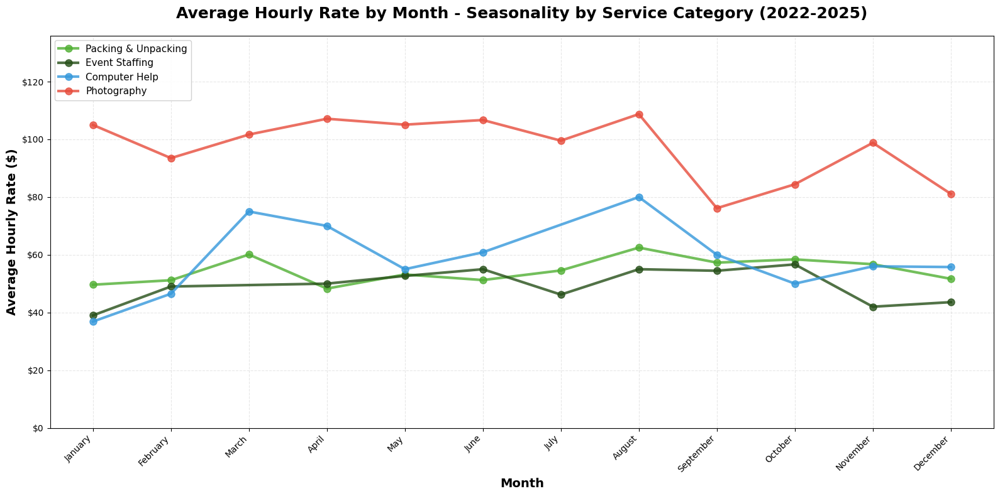

✓ Multi-Category Seasonality chart saved

SEASONALITY ANALYSIS BY SERVICE CATEGORY

Packing & Unpacking:
  Best month: August ($62.49/hr)
  Worst month: April ($48.29/hr)
  Average: $54.56/hr

Event Staffing:
  Best month: October ($56.67/hr)
  Worst month: January ($39.00/hr)
  Average: $49.42/hr

Computer Help:
  Best month: August ($80.00/hr)
  Worst month: January ($36.86/hr)
  Average: $58.72/hr

Photography:
  Best month: August ($108.75/hr)
  Worst month: September ($76.14/hr)
  Average: $97.32/hr


In [ ]:
# Task 2.4: Time-Based Analysis - Multi-Category Seasonality Chart (Updated)

# Calculate monthly average hourly rate
df['Gross_Hourly_Rate'] = df['Earnings'] / df['Hours']
df_clean = df[(df['Gross_Hourly_Rate'] > 0) & (df['Gross_Hourly_Rate'] < np.inf)].copy()

df_clean['Month_Name'] = df_clean['Date'].dt.month_name()
df_clean['Month_Num'] = df_clean['Date'].dt.month
df_clean['Year'] = df_clean['Date'].dt.year

# Filter to only the four categories
categories = ['Packing & Unpacking', 'Event Staffing', 'Computer Help', 'Photography']
df_four_cats = df_clean[df_clean['Service_Category'].isin(categories)].copy()

# Calculate average hourly rate by month and category
category_seasonality = df_four_cats.groupby(['Month_Num', 'Service_Category']).agg({
    'Gross_Hourly_Rate': 'mean',
    'Month_Name': 'first'
}).reset_index()

# Create line chart
fig, ax = plt.subplots(figsize=(16, 8))

# Define colors for each category
category_colors = {
    'Packing & Unpacking': '#50AF33',      # TaskRabbit light green
    'Event Staffing': '#264F18',            # TaskRabbit dark green
    'Computer Help': '#3498db',             # Blue
    'Photography': '#e74c3c'                # Red
}

# Plot line for each category
for category in categories:
    cat_data = category_seasonality[category_seasonality['Service_Category'] == category].sort_values('Month_Num')
    ax.plot(cat_data['Month_Num'], cat_data['Gross_Hourly_Rate'], 
            color=category_colors[category], linewidth=3, marker='o', markersize=8, 
            label=category, alpha=0.8)

# Styling
ax.set_title('Average Hourly Rate by Month - Seasonality by Service Category (2022-2025)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Month', fontsize=14, fontweight='bold')
ax.set_ylabel('Average Hourly Rate ($)', fontsize=14, fontweight='bold')

# Format y-axis to show dollars
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--')

# Set x-axis - month names
month_names = ['January', 'February', 'March', 'April', 'May', 'June', 
               'July', 'August', 'September', 'October', 'November', 'December']
ax.set_xticks(range(1, 13))
ax.set_xticklabels(month_names, rotation=45, ha='right')

# Add legend
ax.legend(loc='upper left', fontsize=11, framealpha=0.9)

# Add 25% breathing room at top
max_rate = category_seasonality['Gross_Hourly_Rate'].max()
ax.set_ylim(0, max_rate * 1.25)

plt.tight_layout()
plt.savefig('../visualizations/hourly_rate_seasonality_by_category.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Multi-Category Seasonality chart saved")

# Print summary for each category
print("\n" + "="*80)
print("SEASONALITY ANALYSIS BY SERVICE CATEGORY")
print("="*80)

for category in categories:
    cat_data = category_seasonality[category_seasonality['Service_Category'] == category].sort_values('Month_Num')
    print(f"\n{category}:")
    
    if len(cat_data) > 0:
        best_month = cat_data.loc[cat_data['Gross_Hourly_Rate'].idxmax()]
        worst_month = cat_data.loc[cat_data['Gross_Hourly_Rate'].idxmin()]
        
        print(f"  Best month: {best_month['Month_Name']} (${best_month['Gross_Hourly_Rate']:.2f}/hr)")
        print(f"  Worst month: {worst_month['Month_Name']} (${worst_month['Gross_Hourly_Rate']:.2f}/hr)")
        print(f"  Average: ${cat_data['Gross_Hourly_Rate'].mean():.2f}/hr")
    else:
        print("  No data available")

In [ ]:
import os

# List all saved visualizations
viz_folder = '/mnt/user-data/outputs/'
if os.path.exists(viz_folder):
    files = sorted([f for f in os.listdir(viz_folder) if f.endswith('.png')])
    print("✓ SAVED VISUALIZATIONS:")
    print("="*60)
    for i, file in enumerate(files, 1):
        print(f"{i:2d}. {file}")
    print(f"\nTotal: {len(files)} charts saved")
else:
    print("Visualizations folder not found")

Visualizations folder not found


In [ ]:
import os

# Check the visualizations folder (relative path)
viz_folder = '../visualizations/'

if os.path.exists(viz_folder):
    files = sorted([f for f in os.listdir(viz_folder) if f.endswith('.png')])
    print("✓ SAVED VISUALIZATIONS:")
    print("="*60)
    for i, file in enumerate(files, 1):
        print(f"{i:2d}. {file}")
    print(f"\nTotal: {len(files)} charts saved")
    print(f"\nLocation: {os.path.abspath(viz_folder)}")
else:
    print("Visualizations folder not found")
    
# Also check current directory
print("\n" + "="*60)
print("Current working directory:")
print(os.getcwd())

print("\nFiles in current directory:")
for item in os.listdir('.'):
    print(f"  {item}")

✓ SAVED VISUALIZATIONS:
 1. before_after_comparison.png
 2. earnings_per_job_comparison.png
 3. hourly_rate_2022.png
 4. hourly_rate_2023.png
 5. hourly_rate_2024.png
 6. hourly_rate_2025.png
 7. hourly_rate_NO_trendline.png
 8. hourly_rate_WITH_trendline.png
 9. hourly_rate_seasonality.png
10. hourly_rate_seasonality_by_category.png
11. hourly_rate_trend_professional.png
12. jobs_heatmap_day_hour.png
13. monthly_earnings_seasonality_by_category.png
14. service_category_hourly_rate.png
15. service_category_revenue_over_time.png
16. service_category_tip_frequency.png
17. service_category_tip_frequency_top8.png
18. service_category_tip_percentage.png
19. service_category_total_hourly_earnings.png
20. strategic_shift_quarterly.png
21. tip_amount_per_job_2022.png
22. tip_amount_per_job_2023.png
23. tip_amount_per_job_2024.png
24. tip_amount_per_job_2025.png
25. tip_amount_per_job_NO_trendline.png
26. tip_amount_per_job_WITH_trendline.png
27. tip_frequency_by_year.png
28. tip_rate_NO_trendl

In [ ]:
import os

print("="*80)
print("YOUR SAVED FILES - VERIFICATION")
print("="*80)

# Check visualizations folder
viz_folder = '../visualizations/'
if os.path.exists(viz_folder):
    files = sorted([f for f in os.listdir(viz_folder) if f.endswith('.png')])
    print(f"\n✓ VISUALIZATIONS FOLDER: {os.path.abspath(viz_folder)}")
    print(f"Total charts saved: {len(files)}\n")
    for i, file in enumerate(files, 1):
        print(f"  {i:2d}. {file}")
else:
    print("\n✗ Visualizations folder not found")

# Check if data file exists
data_file = '../data/TaskRabbit.csv'
if os.path.exists(data_file):
    print(f"\n✓ DATA FILE: {os.path.abspath(data_file)}")
else:
    print("\n✗ Data file not found")

print("\n" + "="*80)
print("WHAT TO DO BEFORE CLOSING:")
print("="*80)
print("1. Save this notebook (Ctrl+S / Cmd+S)")
print("2. Download the '../visualizations/' folder")
print("3. Download this notebook file (.ipynb)")
print("4. Keep your original CSV data file")
print("="*80)
print("\nIf you're in GitHub, commit and push your changes!")
print("="*80)

YOUR SAVED FILES - VERIFICATION

✓ VISUALIZATIONS FOLDER: /workspaces/taskrabbit-analysis/visualizations
Total charts saved: 33

   1. before_after_comparison.png
   2. earnings_per_job_comparison.png
   3. hourly_rate_2022.png
   4. hourly_rate_2023.png
   5. hourly_rate_2024.png
   6. hourly_rate_2025.png
   7. hourly_rate_NO_trendline.png
   8. hourly_rate_WITH_trendline.png
   9. hourly_rate_seasonality.png
  10. hourly_rate_seasonality_by_category.png
  11. hourly_rate_trend_professional.png
  12. jobs_heatmap_day_hour.png
  13. monthly_earnings_seasonality_by_category.png
  14. service_category_hourly_rate.png
  15. service_category_revenue_over_time.png
  16. service_category_tip_frequency.png
  17. service_category_tip_frequency_top8.png
  18. service_category_tip_percentage.png
  19. service_category_total_hourly_earnings.png
  20. strategic_shift_quarterly.png
  21. tip_amount_per_job_2022.png
  22. tip_amount_per_job_2023.png
  23. tip_amount_per_job_2024.png
  24. tip_amoun

In [ ]:
import os

# Check current directory
print("Current directory:", os.getcwd())
print("\nFiles in current directory:")
print(os.listdir('.'))

# Check if there's a data folder
if os.path.exists('../data'):
    print("\nFiles in ../data/:")
    print(os.listdir('../data'))
    
# Check parent directory
print("\nFiles in parent directory:")
print(os.listdir('..'))

Current directory: /workspaces/taskrabbit-analysis/notebooks

Files in current directory:
['full_dataset.csv', 'taskrabbit_weekly_aggregated.csv', '02_exploratory_data_analysis.ipynb', 'hourly_rate_trend.png', 'yearly_summary_stats.csv', 'core_jobs_with_gaps.csv', 'taskrabbit_master_raw.csv', 'core_jobs - old.csv', '01_data_cleaning.ipynb', 'taskrabbit_cleaned.csv', 'core_jobs.csv']

Files in ../data/:
['raw']

Files in parent directory:
['.git', 'README.md', '.venv', 'nano.3972.save', '.vscode', 'visualizations', '.devcontainer', 'data', 'notebooks', 'get-pip.py']


<>:12: SyntaxWarning: invalid escape sequence '\$'
<>:13: SyntaxWarning: invalid escape sequence '\$'
<>:12: SyntaxWarning: invalid escape sequence '\$'
<>:13: SyntaxWarning: invalid escape sequence '\$'
/tmp/ipykernel_2648/2169291082.py:12: SyntaxWarning: invalid escape sequence '\$'
  df['Tip'] = df['Tip'].replace('[\$,]', '', regex=True).astype(float)
/tmp/ipykernel_2648/2169291082.py:13: SyntaxWarning: invalid escape sequence '\$'
  df['Earnings'] = df['Earnings'].replace('[\$,]', '', regex=True).astype(float)


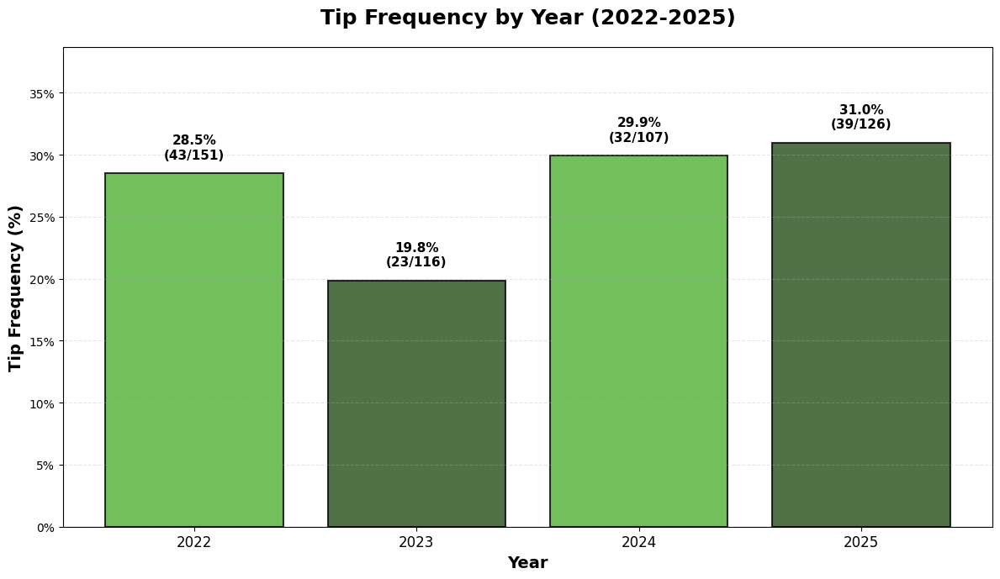

✓ Tip Frequency by Year chart saved

TIP FREQUENCY BY YEAR
2022: 28.5% (43/151 jobs tipped)
2023: 19.8% (23/116 jobs tipped)
2024: 29.9% (32/107 jobs tipped)
2025: 31.0% (39/126 jobs tipped)


In [ ]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load data - it's in the same folder as the notebook
df = pd.read_csv('taskrabbit_master_raw.csv')
df['Date'] = pd.to_datetime(df['Date'])
df['Year'] = df['Date'].dt.year

# Convert Tip to numeric (remove $ and commas)
df['Tip'] = df['Tip'].replace('[\$,]', '', regex=True).astype(float)
df['Earnings'] = df['Earnings'].replace('[\$,]', '', regex=True).astype(float)

# Tip Frequency by Year
tip_freq_by_year = df.groupby('Year').agg({
    'Tip': lambda x: (x > 0).sum(),  # Count of jobs WITH tips
    'Earnings': 'count'  # Total count of jobs
}).reset_index()

tip_freq_by_year.columns = ['Year', 'Jobs_With_Tips', 'Total_Jobs']
tip_freq_by_year['Tip_Frequency_%'] = (tip_freq_by_year['Jobs_With_Tips'] / tip_freq_by_year['Total_Jobs']) * 100

# Create bar chart
fig, ax = plt.subplots(figsize=(12, 7))

# Use TaskRabbit colors - alternate green
colors = ['#50AF33' if i % 2 == 0 else '#264F18' for i in range(len(tip_freq_by_year))]

bars = ax.bar(tip_freq_by_year['Year'], tip_freq_by_year['Tip_Frequency_%'], 
              color=colors, alpha=0.8, edgecolor='black', linewidth=1.5)

# Add value labels on bars
for bar, freq, tipped, total in zip(bars, tip_freq_by_year['Tip_Frequency_%'], 
                                      tip_freq_by_year['Jobs_With_Tips'], 
                                      tip_freq_by_year['Total_Jobs']):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + 1,
            f'{freq:.1f}%\n({int(tipped)}/{int(total)})',
            ha='center', va='bottom', fontsize=11, fontweight='bold')

# Styling
ax.set_title('Tip Frequency by Year (2022-2025)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Year', fontsize=14, fontweight='bold')
ax.set_ylabel('Tip Frequency (%)', fontsize=14, fontweight='bold')

# Format y-axis
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x:.0f}%'))

# Set x-axis
ax.set_xticks(tip_freq_by_year['Year'])
ax.set_xticklabels(tip_freq_by_year['Year'].astype(int), fontsize=12)

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--', axis='y')

# Add 25% breathing room
ax.set_ylim(0, tip_freq_by_year['Tip_Frequency_%'].max() * 1.25)

plt.tight_layout()
plt.savefig('../visualizations/tip_frequency_by_year.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Tip Frequency by Year chart saved")

# Print summary
print("\n" + "="*80)
print("TIP FREQUENCY BY YEAR")
print("="*80)
for idx, row in tip_freq_by_year.iterrows():
    print(f"{int(row['Year'])}: {row['Tip_Frequency_%']:.1f}% ({int(row['Jobs_With_Tips'])}/{int(row['Total_Jobs'])} jobs tipped)")

In [ ]:
import os
print("Charts in visualizations folder:")
viz_files = [f for f in os.listdir('../visualizations') if f.endswith('.png')]
print(f"\nTotal: {len(viz_files)} charts")
if 'tip_frequency_by_year.png' in viz_files:
    print("✓ tip_frequency_by_year.png is saved!")

Charts in visualizations folder:

Total: 33 charts
✓ tip_frequency_by_year.png is saved!


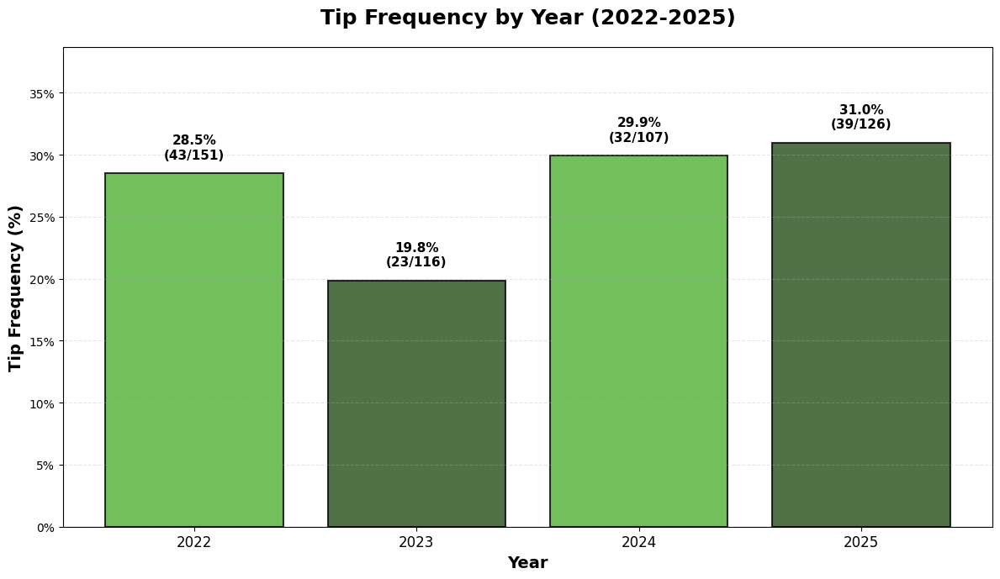

✓ Tip Frequency by Year chart saved

TIP FREQUENCY BY YEAR
2022: 28.5% (43/151 jobs tipped)
2023: 19.8% (23/116 jobs tipped)
2024: 29.9% (32/107 jobs tipped)
2025: 31.0% (39/126 jobs tipped)


In [ ]:
# Tip Frequency by Year
tip_freq_by_year = df.groupby('year').agg({
    'Tip': lambda x: (x > 0).sum(),  # Count of jobs WITH tips
    'Earnings': 'count'  # Total count of jobs
}).reset_index()

tip_freq_by_year.columns = ['Year', 'Jobs_With_Tips', 'Total_Jobs']
tip_freq_by_year['Tip_Frequency_%'] = (tip_freq_by_year['Jobs_With_Tips'] / tip_freq_by_year['Total_Jobs']) * 100

# Create bar chart
fig, ax = plt.subplots(figsize=(12, 7))

# Use TaskRabbit colors - alternate green
colors = ['#50AF33' if i % 2 == 0 else '#264F18' for i in range(len(tip_freq_by_year))]

bars = ax.bar(tip_freq_by_year['Year'], tip_freq_by_year['Tip_Frequency_%'], 
              color=colors, alpha=0.8, edgecolor='black', linewidth=1.5)

# Add value labels on bars
for bar, freq, tipped, total in zip(bars, tip_freq_by_year['Tip_Frequency_%'], 
                                      tip_freq_by_year['Jobs_With_Tips'], 
                                      tip_freq_by_year['Total_Jobs']):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + 1,
            f'{freq:.1f}%\n({int(tipped)}/{int(total)})',
            ha='center', va='bottom', fontsize=11, fontweight='bold')

# Styling
ax.set_title('Tip Frequency by Year (2022-2025)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Year', fontsize=14, fontweight='bold')
ax.set_ylabel('Tip Frequency (%)', fontsize=14, fontweight='bold')

# Format y-axis
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x:.0f}%'))

# Set x-axis
ax.set_xticks(tip_freq_by_year['Year'])
ax.set_xticklabels(tip_freq_by_year['Year'].astype(int), fontsize=12)

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--', axis='y')

# Add 25% breathing room
ax.set_ylim(0, tip_freq_by_year['Tip_Frequency_%'].max() * 1.25)

plt.tight_layout()
plt.savefig('../visualizations/tip_frequency_by_year.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Tip Frequency by Year chart saved")

# Print summary
print("\n" + "="*80)
print("TIP FREQUENCY BY YEAR")
print("="*80)
for idx, row in tip_freq_by_year.iterrows():
    print(f"{int(row['Year'])}: {row['Tip_Frequency_%']:.1f}% ({int(row['Jobs_With_Tips'])}/{int(row['Total_Jobs'])} jobs tipped)")

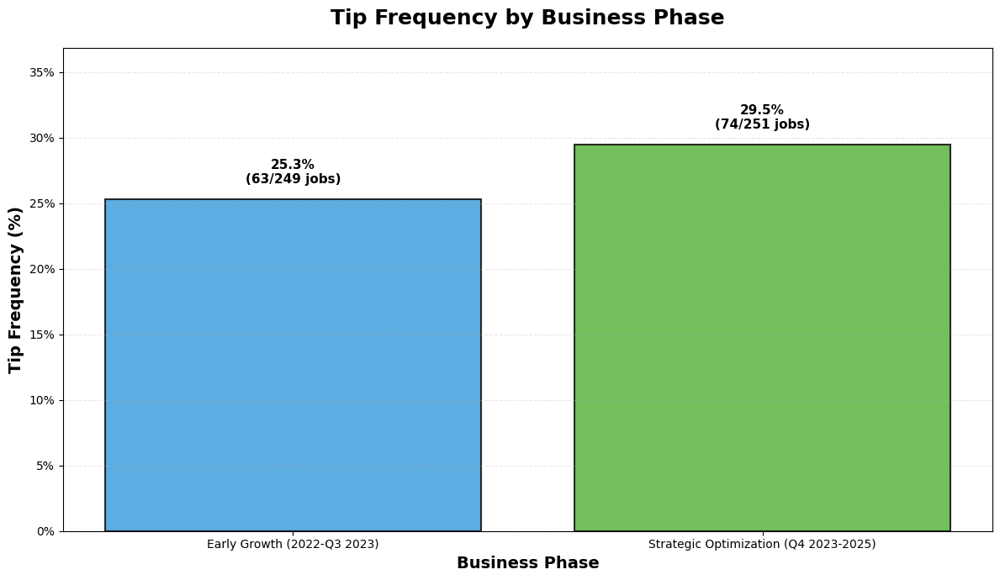

✓ Tip Frequency by Business Phase chart saved

TIP FREQUENCY BY BUSINESS PHASE
Early Growth (2022-Q3 2023): 25.3% (63/249 jobs tipped)
Strategic Optimization (Q4 2023-2025): 29.5% (74/251 jobs tipped)


In [ ]:
# Define Business Phases based on strategic shift analysis
def assign_business_phase(date):
    """Assign business phase based on date"""
    if date < pd.Timestamp('2023-10-01'):
        return 'Early Growth (2022-Q3 2023)'
    else:
        return 'Strategic Optimization (Q4 2023-2025)'

# Apply business phase
df['Business_Phase'] = df['Date'].apply(assign_business_phase)

# Tip Frequency by Business Phase
tip_freq_by_phase = df.groupby('Business_Phase').agg({
    'Tip': lambda x: (x > 0).sum(),  # Count of jobs WITH tips
    'Earnings': 'count'  # Total count of jobs
}).reset_index()

tip_freq_by_phase.columns = ['Business_Phase', 'Jobs_With_Tips', 'Total_Jobs']
tip_freq_by_phase['Tip_Frequency_%'] = (tip_freq_by_phase['Jobs_With_Tips'] / tip_freq_by_phase['Total_Jobs']) * 100

# Create bar chart
fig, ax = plt.subplots(figsize=(12, 7))

# Use TaskRabbit colors
colors = ['#3498db', '#50AF33']  # Blue for early, green for optimized

bars = ax.bar(tip_freq_by_phase['Business_Phase'], tip_freq_by_phase['Tip_Frequency_%'], 
              color=colors, alpha=0.8, edgecolor='black', linewidth=1.5)

# Add value labels on bars
for bar, freq, tipped, total in zip(bars, tip_freq_by_phase['Tip_Frequency_%'], 
                                      tip_freq_by_phase['Jobs_With_Tips'], 
                                      tip_freq_by_phase['Total_Jobs']):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + 1,
            f'{freq:.1f}%\n({int(tipped)}/{int(total)} jobs)',
            ha='center', va='bottom', fontsize=11, fontweight='bold')

# Styling
ax.set_title('Tip Frequency by Business Phase', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Business Phase', fontsize=14, fontweight='bold')
ax.set_ylabel('Tip Frequency (%)', fontsize=14, fontweight='bold')

# Format y-axis
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x:.0f}%'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--', axis='y')

# Add 25% breathing room
ax.set_ylim(0, tip_freq_by_phase['Tip_Frequency_%'].max() * 1.25)

# Keep x-axis labels straight (no rotation)
plt.xticks(rotation=0)

plt.tight_layout()
plt.savefig('../visualizations/tip_frequency_by_phase.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Tip Frequency by Business Phase chart saved")

# Print summary
print("\n" + "="*80)
print("TIP FREQUENCY BY BUSINESS PHASE")
print("="*80)
for idx, row in tip_freq_by_phase.iterrows():
    print(f"{row['Business_Phase']}: {row['Tip_Frequency_%']:.1f}% ({int(row['Jobs_With_Tips'])}/{int(row['Total_Jobs'])} jobs tipped)")

In [ ]:
import os

# Check if the file exists
viz_folder = '../visualizations/'
file_name = 'tip_frequency_by_phase.png'
file_path = os.path.join(viz_folder, file_name)

if os.path.exists(file_path):
    print(f"✓ File exists: {file_path}")
    # Get file size and modification time
    file_size = os.path.getsize(file_path)
    mod_time = os.path.getmtime(file_path)
    from datetime import datetime
    print(f"  Size: {file_size} bytes")
    print(f"  Last modified: {datetime.fromtimestamp(mod_time)}")
else:
    print(f"✗ File NOT found: {file_path}")
    print(f"\nChecking what files ARE in {viz_folder}:")
    if os.path.exists(viz_folder):
        files = [f for f in os.listdir(viz_folder) if f.endswith('.png')]
        for f in sorted(files):
            print(f"  - {f}")

✓ File exists: ../visualizations/tip_frequency_by_phase.png
  Size: 177457 bytes
  Last modified: 2025-11-29 21:21:33.856664


In [ ]:
# ========================================
# EXPLORATORY DATA ANALYSIS
# Updated to use clean dataset
# ========================================

# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
import re

# Load CLEANED data
df = pd.read_csv('taskrabbit_clean_full.csv')

# The cleaned dataset already has these columns properly formatted:
# - Date columns: Year, Quarter, Month, Month_Name, Week_of_Year, Day, Is_Weekend
# - Location: City, Neighborhood
# - Metrics: Hourly_Rate, Hours, Earnings, Tip, Tip_Percentage, Has_Tip, High_Tip, Total
# - Category: Service category already extracted

# Recreate Date column for time-based plotting
df['Date'] = pd.to_datetime(df[['Year', 'Month', 'Day']])

# Display basic info
print("="*80)
print("DATA LOADED FOR EDA - CLEAN DATASET")
print("="*80)
print(f"Total jobs: {len(df)}")
print(f"Date range: {df['Date'].min().date()} to {df['Date'].max().date()}")
print(f"Columns: {df.columns.tolist()}")

print("\n" + "="*80)
print("SUMMARY STATISTICS:")
print("="*80)
print(f"Total earnings: ${df['Earnings'].sum():,.2f}")
print(f"Total tips: ${df['Tip'].sum():,.2f}")
print(f"Total hours: {df['Hours'].sum():,.0f}")
print(f"Average hourly rate: ${df['Hourly_Rate'].mean():.0f}/hr")
print(f"Jobs with tips: {df['Has_Tip'].sum()} ({df['Has_Tip'].sum()/len(df)*100:.1f}%)")

print("\n" + "="*80)
print("CATEGORY DISTRIBUTION:")
print(df['Category'].value_counts())

print("\n" + "="*80)
print("CITY DISTRIBUTION:")
print(df['City'].value_counts())

print("\n✓ Ready for analysis!")

DATA LOADED FOR EDA - CLEAN DATASET
Total jobs: 484
Date range: 2022-04-20 to 2025-11-16
Columns: ['Year', 'Quarter', 'Month', 'Month_Name', 'Week_of_Year', 'Day', 'Is_Weekend', 'Category', 'City', 'Neighborhood', 'Client_Name', 'Hourly_Rate', 'Hours', 'Earnings', 'Tip', 'Tip_Percentage', 'Has_Tip', 'High_Tip', 'Total', 'Date']

SUMMARY STATISTICS:
Total earnings: $84,737.25
Total tips: $4,480.88
Total hours: 1,464
Average hourly rate: $60/hr
Jobs with tips: 137 (28.3%)

CATEGORY DISTRIBUTION:
Category
Packing & Unpacking         264
Photography                  82
Event Staffing               55
Computer Help                36
Organization                 21
Errands                       9
Personal Assistant            8
Web Design & Development      3
Writing & Editing             2
Office Administration         2
Other                         1
Help Moving                   1
Name: count, dtype: int64

CITY DISTRIBUTION:
City
New York City         188
Boston, MA             86
Brook

/tmp/ipykernel_3447/1442806802.py:26: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(box_data,


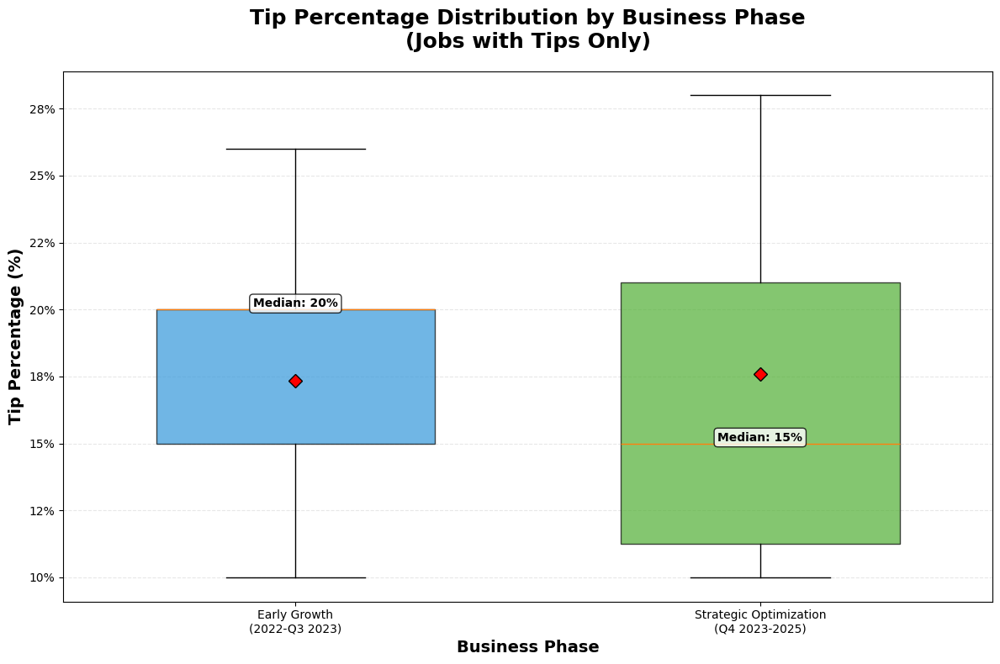

✓ Box plot saved: tip_percentage_boxplot_by_phase.png

TIP PERCENTAGE STATISTICS BY PHASE:

Early Growth:
  Median: 20.0%
  Mean: 17.3%
  25th percentile: 15.0%
  75th percentile: 20.0%

Strategic Optimization:
  Median: 15.0%
  Mean: 17.6%
  25th percentile: 11.2%
  75th percentile: 21.0%


In [ ]:
# Box Plot: Tip Percentage Distribution by Business Phase

# Convert Tip to numeric if needed
if df['Tip'].dtype == 'object':
    df['Tip'] = pd.to_numeric(df['Tip'], errors='coerce')

# Convert Tip_Percentage to numeric if needed
if df['Tip_Percentage'].dtype == 'object':
    df['Tip_Percentage'] = pd.to_numeric(df['Tip_Percentage'], errors='coerce')

# Add Business Phase column
df['Business_Phase'] = df['Date'].apply(lambda x: 'Early Growth\n(2022-Q3 2023)' if x < pd.Timestamp('2023-10-01') else 'Strategic Optimization\n(Q4 2023-2025)')

# Filter to jobs with tips only
df_tips_only = df[(df['Tip'] > 0) & (df['Tip_Percentage'].notna())].copy()

# Create the plot
fig, ax = plt.subplots(figsize=(12, 8))

# Create box plot
box_data = [
    df_tips_only[df_tips_only['Business_Phase'] == 'Early Growth\n(2022-Q3 2023)']['Tip_Percentage'].dropna(),
    df_tips_only[df_tips_only['Business_Phase'] == 'Strategic Optimization\n(Q4 2023-2025)']['Tip_Percentage'].dropna()
]

bp = ax.boxplot(box_data, 
                labels=['Early Growth\n(2022-Q3 2023)', 'Strategic Optimization\n(Q4 2023-2025)'],
                patch_artist=True,
                widths=0.6,
                showmeans=True,
                meanprops=dict(marker='D', markerfacecolor='red', markeredgecolor='black', markersize=8))

# Color the boxes
colors = ['#3498db', '#50AF33']
for patch, color in zip(bp['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

# Styling
ax.set_title('Tip Percentage Distribution by Business Phase\n(Jobs with Tips Only)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_ylabel('Tip Percentage (%)', fontsize=14, fontweight='bold')
ax.set_xlabel('Business Phase', fontsize=14, fontweight='bold')

# Format y-axis
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x:.0f}%'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--', axis='y')

# Add statistics text
for i, data in enumerate(box_data):
    median = data.median()
    mean = data.mean()
    ax.text(i+1, median, f'Median: {median:.0f}%', 
            ha='center', va='bottom', fontsize=10, fontweight='bold',
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

plt.tight_layout()
plt.savefig('../visualizations/tip_percentage_boxplot_by_phase.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Box plot saved: tip_percentage_boxplot_by_phase.png")
print("\n" + "="*80)
print("TIP PERCENTAGE STATISTICS BY PHASE:")
print("="*80)
for phase, data in zip(['Early Growth', 'Strategic Optimization'], box_data):
    print(f"\n{phase}:")
    print(f"  Median: {data.median():.1f}%")
    print(f"  Mean: {data.mean():.1f}%")
    print(f"  25th percentile: {data.quantile(0.25):.1f}%")
    print(f"  75th percentile: {data.quantile(0.75):.1f}%")

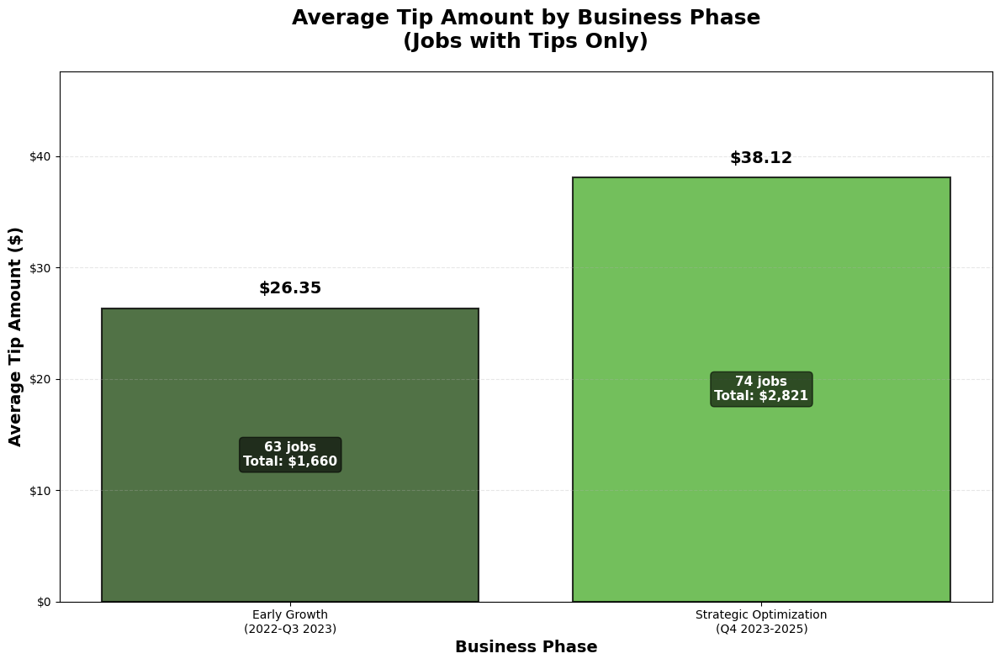

✓ Chart saved: average_tip_dollars_by_phase.png

TIP AMOUNT (DOLLARS) COMPARISON:

Early Growth (2022-Q3 2023):
  Average tip: $26.35
  Total tips: $1,659.77
  Jobs with tips: 63

Strategic Optimization (Q4 2023-2025):
  Average tip: $38.12
  Total tips: $2,821.11
  Jobs with tips: 74

CHANGE IN AVERAGE TIP AMOUNT:
$26.35 → $38.12
📈 INCREASED by $11.78 (+44.7%)


In [ ]:
# Bar Chart: Average Tip Amount (Dollars) by Business Phase

# Add Business Phase column if not already there
if 'Business_Phase' not in df.columns:
    df['Business_Phase'] = df['Date'].apply(lambda x: 'Early Growth\n(2022-Q3 2023)' if x < pd.Timestamp('2023-10-01') else 'Strategic Optimization\n(Q4 2023-2025)')

# Filter to jobs with tips only
df_with_tips = df[df['Tip'] > 0].copy()

# Calculate average tip amount by phase
tip_by_phase = df_with_tips.groupby('Business_Phase').agg({
    'Tip': ['mean', 'sum', 'count']
}).reset_index()

tip_by_phase.columns = ['Business_Phase', 'Avg_Tip', 'Total_Tips', 'Jobs_Count']

# Create bar chart
fig, ax = plt.subplots(figsize=(12, 8))

# Use TaskRabbit colors
colors = ['#264F18', '#50AF33']  # Dark green, Light green
bars = ax.bar(tip_by_phase['Business_Phase'], tip_by_phase['Avg_Tip'], 
              color=colors, alpha=0.8, edgecolor='black', linewidth=1.5)

# Add value labels on bars
for bar, avg_tip, total, count in zip(bars, tip_by_phase['Avg_Tip'], 
                                       tip_by_phase['Total_Tips'], 
                                       tip_by_phase['Jobs_Count']):
    height = bar.get_height()
    # Average tip on top of bar
    ax.text(bar.get_x() + bar.get_width()/2., height + 1,
            f'${avg_tip:.2f}',
            ha='center', va='bottom', fontsize=14, fontweight='bold')
    
    # Additional stats below
    ax.text(bar.get_x() + bar.get_width()/2., height * 0.5,
            f'{int(count)} jobs\nTotal: ${total:,.0f}',
            ha='center', va='center', fontsize=11, fontweight='bold',
            color='white',
            bbox=dict(boxstyle='round', facecolor='black', alpha=0.6))

# Styling
ax.set_title('Average Tip Amount by Business Phase\n(Jobs with Tips Only)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_ylabel('Average Tip Amount ($)', fontsize=14, fontweight='bold')
ax.set_xlabel('Business Phase', fontsize=14, fontweight='bold')

# Format y-axis
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--', axis='y')

# Add 25% breathing room
max_tip = tip_by_phase['Avg_Tip'].max()
ax.set_ylim(0, max_tip * 1.25)

plt.tight_layout()
plt.savefig('../visualizations/average_tip_dollars_by_phase.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Chart saved: average_tip_dollars_by_phase.png")

# Print detailed comparison
print("\n" + "="*80)
print("TIP AMOUNT (DOLLARS) COMPARISON:")
print("="*80)

for idx, row in tip_by_phase.iterrows():
    phase = row['Business_Phase'].replace('\n', ' ')
    print(f"\n{phase}:")
    print(f"  Average tip: ${row['Avg_Tip']:.2f}")
    print(f"  Total tips: ${row['Total_Tips']:,.2f}")
    print(f"  Jobs with tips: {int(row['Jobs_Count'])}")

# Calculate percentage change
early = tip_by_phase[tip_by_phase['Business_Phase'] == 'Early Growth\n(2022-Q3 2023)']['Avg_Tip'].values[0]
strategic = tip_by_phase[tip_by_phase['Business_Phase'] == 'Strategic Optimization\n(Q4 2023-2025)']['Avg_Tip'].values[0]
pct_change = ((strategic - early) / early) * 100

print("\n" + "="*80)
print("CHANGE IN AVERAGE TIP AMOUNT:")
print(f"${early:.2f} → ${strategic:.2f}")
if pct_change > 0:
    print(f"📈 INCREASED by ${strategic - early:.2f} ({pct_change:+.1f}%)")
else:
    print(f"📉 DECREASED by ${abs(strategic - early):.2f} ({pct_change:.1f}%)")
print("="*80)

In [ ]:
# NYC vs Boston Market Comparison

# Define NYC vs Boston
df['Market'] = df['City'].apply(lambda x: 'NYC' if 'NYC' in x else ('Boston Area' if 'MA' in x else 'Other'))

# Filter to main markets only
df_markets = df[df['Market'].isin(['NYC', 'Boston Area'])].copy()

# Calculate market statistics
market_stats = df_markets.groupby('Market').agg({
    'Hourly_Rate': 'mean',
    'Earnings': ['sum', 'mean', 'count'],
    'Tip': 'mean',
    'Tip_Percentage': 'mean',
    'Has_Tip': lambda x: (x.sum() / len(x)) * 100  # Tip frequency
}).reset_index()

# Flatten column names
market_stats.columns = ['Market', 'Avg_Hourly_Rate', 'Total_Earnings', 'Avg_Earnings', 
                        'Total_Jobs', 'Avg_Tip', 'Avg_Tip_Percentage', 'Tip_Frequency_%']

print("="*80)
print("NYC VS BOSTON MARKET COMPARISON")
print("="*80)
print(market_stats.to_string(index=False))

# Most common service types by market
print("\n" + "="*80)
print("TOP SERVICE CATEGORIES BY MARKET:")
print("="*80)

for market in ['NYC', 'Boston Area']:
    market_data = df_markets[df_markets['Market'] == market]
    print(f"\n{market}:")
    top_services = market_data['Category'].value_counts().head(5)
    for service, count in top_services.items():
        pct = (count / len(market_data)) * 100
        print(f"  {service}: {count} jobs ({pct:.1f}%)")

NYC VS BOSTON MARKET COMPARISON
     Market  Avg_Hourly_Rate  Total_Earnings  Avg_Earnings  Total_Jobs   Avg_Tip  Avg_Tip_Percentage  Tip_Frequency_%
Boston Area        68.874396        41160.00    198.840580         207 10.808164            5.130435        28.502415
        NYC        53.078652        13701.75    153.952247          89  7.776517            4.370787        25.842697

TOP SERVICE CATEGORIES BY MARKET:

NYC:
  Packing & Unpacking: 59 jobs (66.3%)
  Photography: 17 jobs (19.1%)
  Computer Help: 5 jobs (5.6%)
  Event Staffing: 4 jobs (4.5%)
  Organization: 2 jobs (2.2%)

Boston Area:
  Packing & Unpacking: 113 jobs (54.6%)
  Photography: 28 jobs (13.5%)
  Event Staffing: 22 jobs (10.6%)
  Computer Help: 18 jobs (8.7%)
  Organization: 15 jobs (7.2%)


In [ ]:
# Diagnostic: Check market categorization

print("="*80)
print("MARKET CATEGORIZATION CHECK")
print("="*80)

# Show sample of how cities are being categorized
print("\nCity → Market mapping:")
city_to_market = df.groupby('City')['Market'].first().sort_index()
print(city_to_market)

print("\n" + "="*80)
print("TOTAL JOBS BY MARKET:")
print(df['Market'].value_counts())

print("\n" + "="*80)
print("SAMPLE NYC JOBS:")
nyc_sample = df[df['Market'] == 'NYC'][['Year', 'City', 'Neighborhood', 'Category', 'Earnings']].head(10)
print(nyc_sample)

print("\n" + "="*80)
print("SAMPLE BOSTON JOBS:")
boston_sample = df[df['Market'] == 'Boston Area'][['Year', 'City', 'Neighborhood', 'Category', 'Earnings']].head(10)
print(boston_sample)

print("\n" + "="*80)
print("CHECK: Are these totals correct?")
print(f"Total jobs in dataset: {len(df)}")
print(f"NYC jobs: {len(df[df['Market'] == 'NYC'])}")
print(f"Boston Area jobs: {len(df[df['Market'] == 'Boston Area'])}")
print(f"Other: {len(df[df['Market'] == 'Other'])}")
print(f"Sum: {len(df[df['Market'] == 'NYC']) + len(df[df['Market'] == 'Boston Area']) + len(df[df['Market'] == 'Other'])}")

# Check if numbers match your expectations
print("\n" + "="*80)
print("DOES THIS MATCH YOUR MEMORY?")
print(f"Did you do ~{len(df[df['Market'] == 'NYC'])} jobs in NYC?")
print(f"Did you do ~{len(df[df['Market'] == 'Boston Area'])} jobs in Boston area?")

MARKET CATEGORIZATION CHECK

City → Market mapping:
City
Boston, MA            Boston Area
Brookline, MA         Boston Area
Brooklyn, NYC                 NYC
Cambridge, MA         Boston Area
Malden, MA            Boston Area
Manhattan, NYC                NYC
Medford, MA           Boston Area
Nahant, MA            Boston Area
New York City               Other
Newton, MA            Boston Area
Queens, NYC                   NYC
Somerville, MA        Boston Area
Staten Island, NYC            NYC
Waltham, MA           Boston Area
Watertown, MA         Boston Area
Woburn, MA            Boston Area
Name: Market, dtype: object

TOTAL JOBS BY MARKET:
Market
Boston Area    207
Other          188
NYC             89
Name: count, dtype: int64

SAMPLE NYC JOBS:
    Year           City   Neighborhood             Category  Earnings
1   2022  Brooklyn, NYC    Brownsville  Packing & Unpacking      56.0
2   2022  Brooklyn, NYC     Greenpoint          Photography     140.0
4   2022  Brooklyn, NYC     Ke

In [ ]:
# Check the date range in your data
print("="*80)
print("DATA COVERAGE CHECK")
print("="*80)
print(f"Earliest date: {df['Date'].min()}")
print(f"Latest date: {df['Date'].max()}")
print(f"Total span: {(df['Date'].max() - df['Date'].min()).days} days ({(df['Date'].max() - df['Date'].min()).days / 365:.1f} years)")
print(f"Total jobs in analysis: {len(df)}")
print(f"\nYou mentioned 542 total tasks, so approximately {542 - len(df)} tasks are not in this dataset.")

DATA COVERAGE CHECK
Earliest date: 2022-04-20 00:00:00
Latest date: 2025-11-16 00:00:00
Total span: 1306 days (3.6 years)
Total jobs in analysis: 484

You mentioned 542 total tasks, so approximately 58 tasks are not in this dataset.


In [ ]:
# Check what Hourly_Rate includes

print("="*80)
print("HOURLY RATE CALCULATION CHECK")
print("="*80)

# Show the formula
print("Hourly_Rate column = Earnings / Hours")
print("\nDoes this include tips? Let's verify with samples:")

sample = df[['Earnings', 'Tip', 'Hours', 'Hourly_Rate', 'Total']].head(10)
print("\n", sample)

print("\n" + "="*80)
print("VERIFICATION:")
print("If Hourly_Rate = Earnings / Hours, then it does NOT include tips")
print("If Hourly_Rate should include tips, we need: (Earnings + Tip) / Hours")
print("="*80)

# Calculate both versions for Boston
boston_data = df[df['Market'] == 'Boston Area']

hourly_without_tip = (boston_data['Earnings'] / boston_data['Hours']).mean()
hourly_with_tip = ((boston_data['Earnings'] + boston_data['Tip']) / boston_data['Hours']).mean()

print(f"\nBoston Area Hourly Rate:")
print(f"  WITHOUT tips: ${hourly_without_tip:.2f}/hr")
print(f"  WITH tips: ${hourly_with_tip:.2f}/hr")

print(f"\nCurrent 'Avg_Hourly_Rate' shown: ${market_stats[market_stats['Market'] == 'Boston Area']['Avg_Hourly_Rate'].values[0]:.2f}/hr")

HOURLY RATE CALCULATION CHECK
Hourly_Rate column = Earnings / Hours

Does this include tips? Let's verify with samples:

    Earnings   Tip  Hours  Hourly_Rate  Total
0      84.0   0.0   3.00           28   84.0
1      56.0   0.0   2.00           28   56.0
2     140.0  21.0   2.00           70  161.0
3     120.0   0.0   4.00           30  125.5
4     115.5   0.0   3.50           33  115.5
5     105.0   0.0   3.75           28  105.0
6      68.0   0.0   2.00           34   68.0
7     153.0  30.6   4.50           34  183.6
8     171.0   0.0   4.50           38  171.0
9     169.0  16.9   6.50           26  185.9

VERIFICATION:
If Hourly_Rate = Earnings / Hours, then it does NOT include tips
If Hourly_Rate should include tips, we need: (Earnings + Tip) / Hours

Boston Area Hourly Rate:
  WITHOUT tips: $68.87/hr
  WITH tips: $72.17/hr

Current 'Avg_Hourly_Rate' shown: $68.87/hr


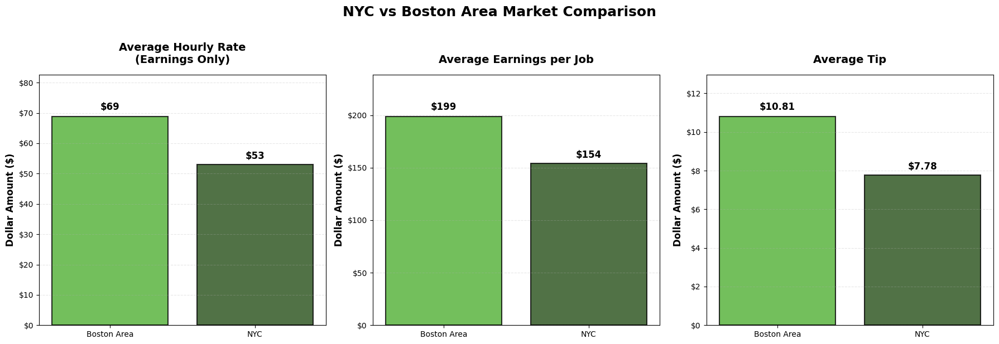

✓ Market comparison chart saved: nyc_vs_boston_comparison.png


In [ ]:
# Bar Chart: NYC vs Boston Market Comparison

# Prepare data for visualization
metrics = ['Avg_Hourly_Rate', 'Avg_Earnings', 'Avg_Tip']
metric_labels = ['Average Hourly Rate\n(Earnings Only)', 'Average Earnings per Job', 'Average Tip']

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for idx, (metric, label) in enumerate(zip(metrics, metric_labels)):
    ax = axes[idx]
    
    # Create bars
    markets = market_stats['Market']
    values = market_stats[metric]
    
    # Use TaskRabbit colors
    colors = ['#50AF33', '#264F18']  # Light green for NYC, dark green for Boston
    bars = ax.bar(markets, values, color=colors, alpha=0.8, 
                   edgecolor='black', linewidth=1.5)
    
    # Add value labels
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height + (height * 0.02),
                f'${height:.0f}' if 'Tip' not in label else f'${height:.2f}',
                ha='center', va='bottom', fontsize=12, fontweight='bold')
    
    # Styling
    ax.set_title(label, fontsize=14, fontweight='bold', pad=15)
    ax.set_ylabel('Dollar Amount ($)', fontsize=12, fontweight='bold')
    
    # Format y-axis
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))
    
    # Add gridlines
    ax.grid(True, alpha=0.3, linestyle='--', axis='y')
    
    # Add breathing room
    ax.set_ylim(0, values.max() * 1.2)

plt.suptitle('NYC vs Boston Area Market Comparison', 
             fontsize=18, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../visualizations/nyc_vs_boston_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Market comparison chart saved: nyc_vs_boston_comparison.png")

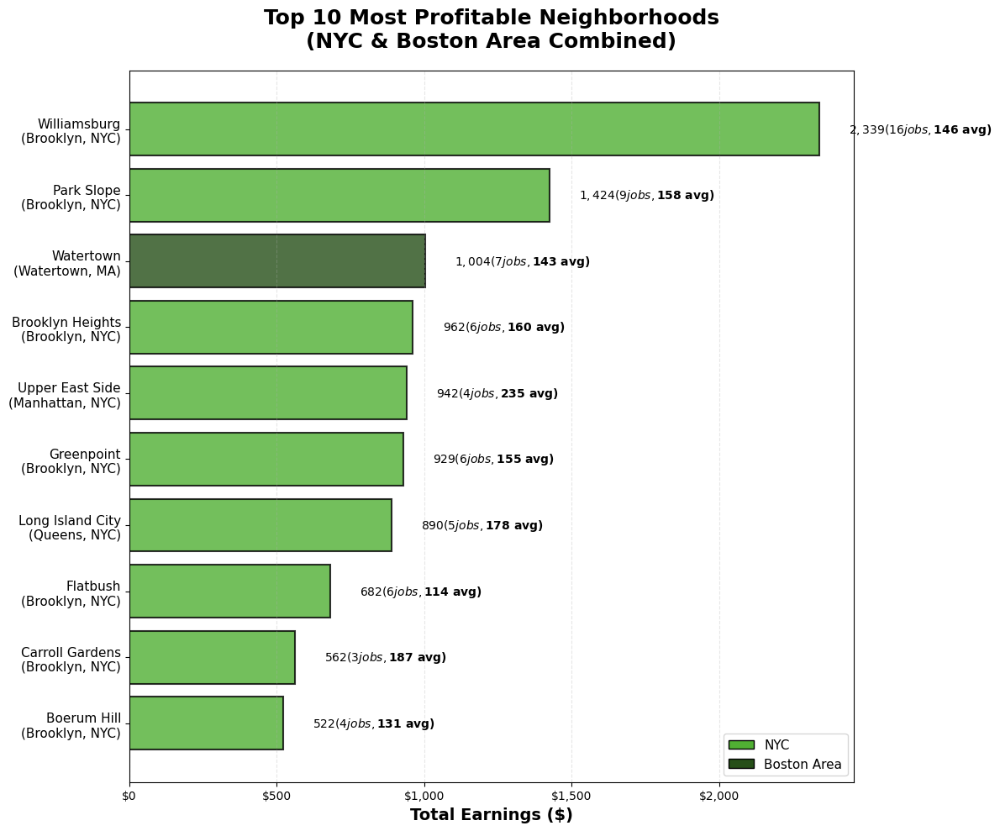

✓ Top neighborhoods chart saved: top_10_neighborhoods.png

TOP 10 MOST PROFITABLE NEIGHBORHOODS:
    Neighborhood           City  Total_Earnings  Job_Count  Avg_Earnings
    Williamsburg  Brooklyn, NYC         2339.00         16    146.187500
      Park Slope  Brooklyn, NYC         1424.50          9    158.277778
       Watertown  Watertown, MA         1004.00          7    143.428571
Brooklyn Heights  Brooklyn, NYC          961.75          6    160.291667
 Upper East Side Manhattan, NYC          941.50          4    235.375000
      Greenpoint  Brooklyn, NYC          929.00          6    154.833333
Long Island City    Queens, NYC          890.25          5    178.050000
        Flatbush  Brooklyn, NYC          681.75          6    113.625000
 Carroll Gardens  Brooklyn, NYC          561.50          3    187.166667
     Boerum Hill  Brooklyn, NYC          522.50          4    130.625000


In [ ]:
# Top 10 Most Profitable Neighborhoods (NYC + Boston combined)

# Filter to jobs with neighborhood data
df_neighborhoods = df_markets[df_markets['Neighborhood'].notna()].copy()

# Calculate total earnings and job count by neighborhood
neighborhood_stats = df_neighborhoods.groupby('Neighborhood').agg({
    'Earnings': ['sum', 'mean', 'count'],
    'Hourly_Rate': 'mean',
    'City': 'first'  # To show which city
}).reset_index()

# Flatten the multi-level column names properly
neighborhood_stats.columns = ['_'.join(col).strip('_') if col[1] else col[0] 
                               for col in neighborhood_stats.columns.values]

# Rename to cleaner names
neighborhood_stats = neighborhood_stats.rename(columns={
    'Neighborhood': 'Neighborhood',
    'Earnings_sum': 'Total_Earnings',
    'Earnings_mean': 'Avg_Earnings',
    'Earnings_count': 'Job_Count',
    'Hourly_Rate_mean': 'Avg_Hourly_Rate',
    'City_first': 'City'
})

# Sort by total earnings and get top 10
top_neighborhoods = neighborhood_stats.nlargest(10, 'Total_Earnings')

# Create horizontal bar chart
fig, ax = plt.subplots(figsize=(12, 10))

# Color by city
colors = ['#50AF33' if 'NYC' in city else '#264F18' for city in top_neighborhoods['City']]

bars = ax.barh(range(len(top_neighborhoods)), top_neighborhoods['Total_Earnings'], 
               color=colors, alpha=0.8, edgecolor='black', linewidth=1.5)

# Add value labels
for idx, (bar, earnings, count, avg) in enumerate(zip(bars, 
                                                        top_neighborhoods['Total_Earnings'],
                                                        top_neighborhoods['Job_Count'],
                                                        top_neighborhoods['Avg_Earnings'])):
    width = bar.get_width()
    ax.text(width + 100, bar.get_y() + bar.get_height()/2.,
            f'${earnings:,.0f} ({int(count)} jobs, ${avg:.0f} avg)',
            ha='left', va='center', fontsize=10, fontweight='bold')

# Y-axis: Neighborhood names with city
y_labels = [f"{row['Neighborhood']}\n({row['City']})" 
            for _, row in top_neighborhoods.iterrows()]
ax.set_yticks(range(len(top_neighborhoods)))
ax.set_yticklabels(y_labels, fontsize=11)

# Styling
ax.set_title('Top 10 Most Profitable Neighborhoods\n(NYC & Boston Area Combined)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Total Earnings ($)', fontsize=14, fontweight='bold')

# Format x-axis
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:,.0f}'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--', axis='x')

# Invert y-axis so #1 is on top
ax.invert_yaxis()

# Legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#50AF33', edgecolor='black', label='NYC'),
    Patch(facecolor='#264F18', edgecolor='black', label='Boston Area')
]
ax.legend(handles=legend_elements, loc='lower right', fontsize=11)

plt.tight_layout()
plt.savefig('../visualizations/top_10_neighborhoods.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Top neighborhoods chart saved: top_10_neighborhoods.png")

print("\n" + "="*80)
print("TOP 10 MOST PROFITABLE NEIGHBORHOODS:")
print("="*80)
print(top_neighborhoods[['Neighborhood', 'City', 'Total_Earnings', 'Job_Count', 'Avg_Earnings']].to_string(index=False))

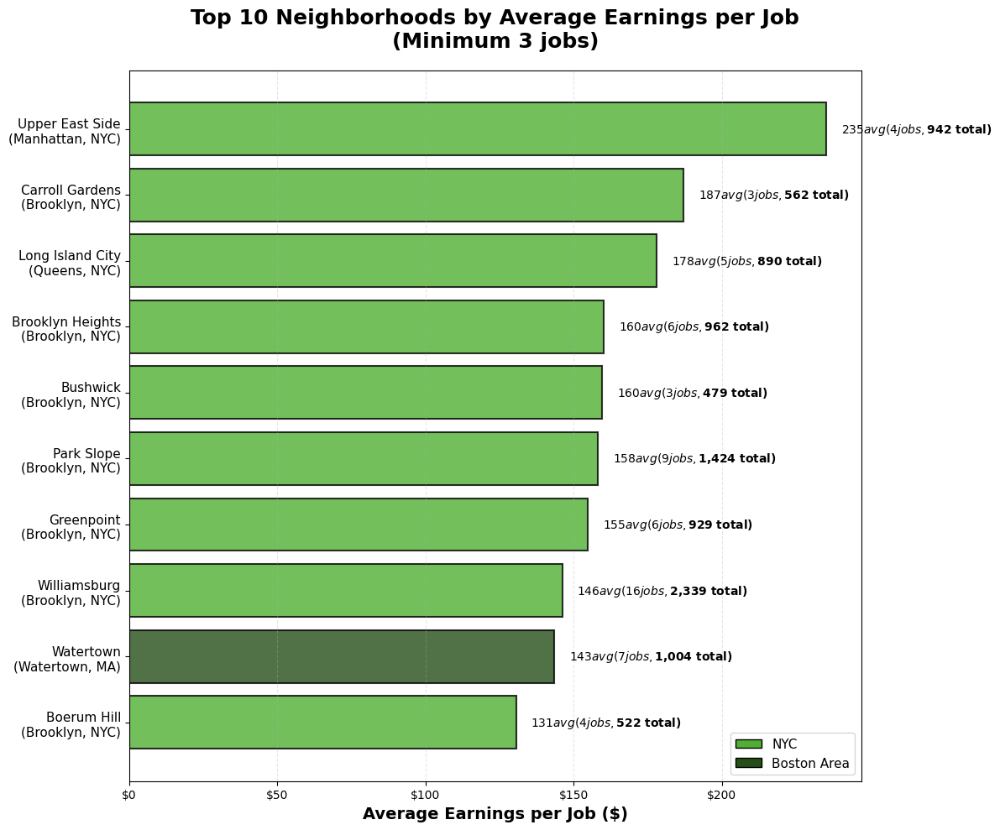

✓ Chart saved: top_10_neighborhoods_by_avg_earnings.png

TOP 10 NEIGHBORHOODS BY AVERAGE EARNINGS (Min 3 jobs):
    Neighborhood           City  Avg_Earnings  Job_Count  Total_Earnings
 Upper East Side Manhattan, NYC    235.375000          4          941.50
 Carroll Gardens  Brooklyn, NYC    187.166667          3          561.50
Long Island City    Queens, NYC    178.050000          5          890.25
Brooklyn Heights  Brooklyn, NYC    160.291667          6          961.75
        Bushwick  Brooklyn, NYC    159.666667          3          479.00
      Park Slope  Brooklyn, NYC    158.277778          9         1424.50
      Greenpoint  Brooklyn, NYC    154.833333          6          929.00
    Williamsburg  Brooklyn, NYC    146.187500         16         2339.00
       Watertown  Watertown, MA    143.428571          7         1004.00
     Boerum Hill  Brooklyn, NYC    130.625000          4          522.50


In [ ]:
# Top 10 Neighborhoods by AVERAGE Earnings per Job

# Filter to jobs with neighborhood data
df_neighborhoods = df_markets[df_markets['Neighborhood'].notna()].copy()

# Calculate stats by neighborhood
neighborhood_stats = df_neighborhoods.groupby('Neighborhood').agg({
    'Earnings': ['sum', 'mean', 'count'],
    'Hourly_Rate': 'mean',
    'City': 'first'
}).reset_index()

# Flatten column names
neighborhood_stats.columns = ['_'.join(col).strip('_') if col[1] else col[0] 
                               for col in neighborhood_stats.columns.values]

# Rename to cleaner names
neighborhood_stats = neighborhood_stats.rename(columns={
    'Neighborhood': 'Neighborhood',
    'Earnings_sum': 'Total_Earnings',
    'Earnings_mean': 'Avg_Earnings',
    'Earnings_count': 'Job_Count',
    'Hourly_Rate_mean': 'Avg_Hourly_Rate',
    'City_first': 'City'
})

# Filter to neighborhoods with at least 3 jobs (to avoid outliers)
neighborhood_stats_filtered = neighborhood_stats[neighborhood_stats['Job_Count'] >= 3].copy()

# Sort by AVERAGE earnings and get top 10
top_neighborhoods_avg = neighborhood_stats_filtered.nlargest(10, 'Avg_Earnings')

# Create horizontal bar chart
fig, ax = plt.subplots(figsize=(12, 10))

# Color by city
colors = ['#50AF33' if 'NYC' in city else '#264F18' for city in top_neighborhoods_avg['City']]

bars = ax.barh(range(len(top_neighborhoods_avg)), top_neighborhoods_avg['Avg_Earnings'], 
               color=colors, alpha=0.8, edgecolor='black', linewidth=1.5)

# Add value labels
for idx, (bar, avg, count, total) in enumerate(zip(bars, 
                                                     top_neighborhoods_avg['Avg_Earnings'],
                                                     top_neighborhoods_avg['Job_Count'],
                                                     top_neighborhoods_avg['Total_Earnings'])):
    width = bar.get_width()
    ax.text(width + 5, bar.get_y() + bar.get_height()/2.,
            f'${avg:.0f} avg ({int(count)} jobs, ${total:,.0f} total)',
            ha='left', va='center', fontsize=10, fontweight='bold')

# Y-axis: Neighborhood names with city
y_labels = [f"{row['Neighborhood']}\n({row['City']})" 
            for _, row in top_neighborhoods_avg.iterrows()]
ax.set_yticks(range(len(top_neighborhoods_avg)))
ax.set_yticklabels(y_labels, fontsize=11)

# Styling
ax.set_title('Top 10 Neighborhoods by Average Earnings per Job\n(Minimum 3 jobs)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Average Earnings per Job ($)', fontsize=14, fontweight='bold')

# Format x-axis
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--', axis='x')

# Invert y-axis so #1 is on top
ax.invert_yaxis()

# Legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#50AF33', edgecolor='black', label='NYC'),
    Patch(facecolor='#264F18', edgecolor='black', label='Boston Area')
]
ax.legend(handles=legend_elements, loc='lower right', fontsize=11)

plt.tight_layout()
plt.savefig('../visualizations/top_10_neighborhoods_by_avg_earnings.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Chart saved: top_10_neighborhoods_by_avg_earnings.png")

print("\n" + "="*80)
print("TOP 10 NEIGHBORHOODS BY AVERAGE EARNINGS (Min 3 jobs):")
print("="*80)
print(top_neighborhoods_avg[['Neighborhood', 'City', 'Avg_Earnings', 'Job_Count', 'Total_Earnings']].to_string(index=False))

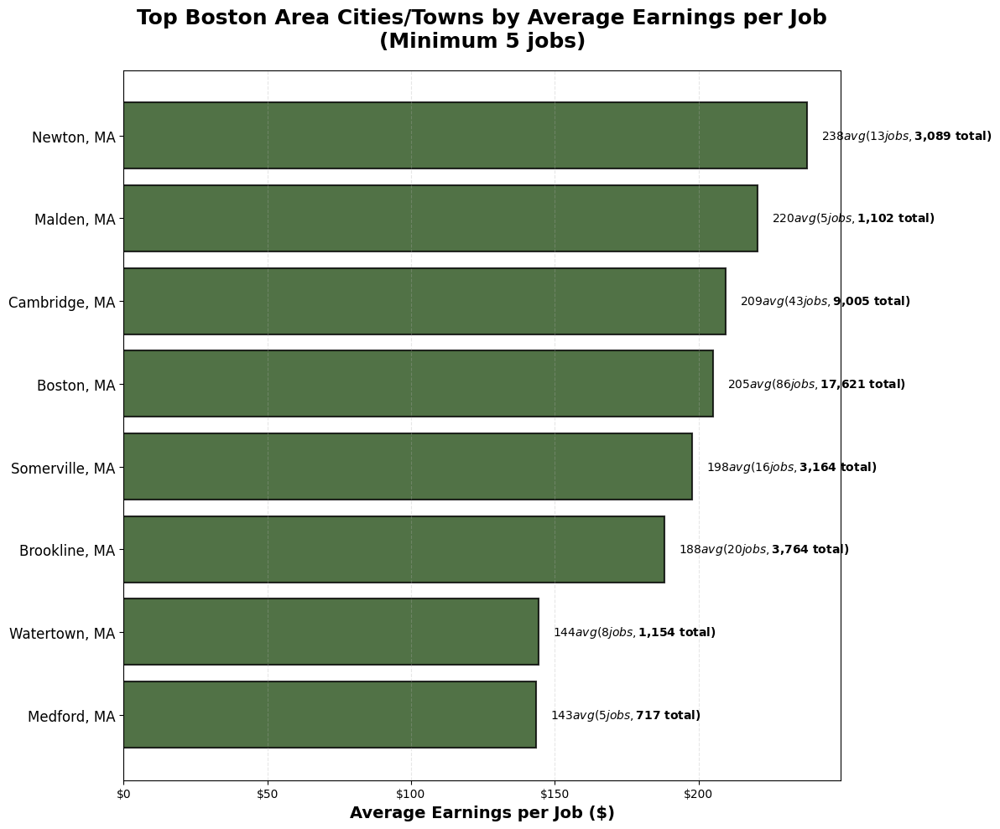

✓ Chart saved: top_boston_cities_by_avg_earnings.png

TOP BOSTON AREA CITIES/TOWNS BY AVERAGE EARNINGS (Min 5 jobs):
          City  Avg_Earnings  Job_Count  Total_Earnings
    Newton, MA    237.596154         13         3088.75
    Malden, MA    220.400000          5         1102.00
 Cambridge, MA    209.418605         43         9005.00
    Boston, MA    204.895349         86        17621.00
Somerville, MA    197.750000         16         3164.00
 Brookline, MA    188.212500         20         3764.25
 Watertown, MA    144.250000          8         1154.00
   Medford, MA    143.400000          5          717.00

ALL BOSTON AREA CITIES (sorted by average earnings):
          City  Avg_Earnings  Job_Count  Total_Earnings
    Newton, MA    237.596154         13         3088.75
    Malden, MA    220.400000          5         1102.00
 Cambridge, MA    209.418605         43         9005.00
    Boston, MA    204.895349         86        17621.00
Somerville, MA    197.750000         16      

In [ ]:
# Top 10 Boston Area CITIES by AVERAGE Earnings per Job

# Filter to Boston Area jobs
df_boston = df[df['Market'] == 'Boston Area'].copy()

# Calculate stats by CITY (not neighborhood)
boston_city_stats = df_boston.groupby('City').agg({
    'Earnings': ['sum', 'mean', 'count'],
    'Hourly_Rate': 'mean'
}).reset_index()

# Flatten column names
boston_city_stats.columns = ['_'.join(col).strip('_') if col[1] else col[0] 
                              for col in boston_city_stats.columns.values]

# Rename to cleaner names
boston_city_stats = boston_city_stats.rename(columns={
    'City': 'City',
    'Earnings_sum': 'Total_Earnings',
    'Earnings_mean': 'Avg_Earnings',
    'Earnings_count': 'Job_Count',
    'Hourly_Rate_mean': 'Avg_Hourly_Rate'
})

# Filter to cities with at least 5 jobs (since we have more data by city)
boston_filtered = boston_city_stats[boston_city_stats['Job_Count'] >= 5].copy()

# Sort by AVERAGE earnings
top_boston_cities = boston_filtered.nlargest(10, 'Avg_Earnings')

# Create horizontal bar chart
fig, ax = plt.subplots(figsize=(12, 10))

# All TaskRabbit dark green for Boston
colors = ['#264F18'] * len(top_boston_cities)

bars = ax.barh(range(len(top_boston_cities)), top_boston_cities['Avg_Earnings'], 
               color=colors, alpha=0.8, edgecolor='black', linewidth=1.5)

# Add value labels
for idx, (bar, avg, count, total) in enumerate(zip(bars, 
                                                     top_boston_cities['Avg_Earnings'],
                                                     top_boston_cities['Job_Count'],
                                                     top_boston_cities['Total_Earnings'])):
    width = bar.get_width()
    ax.text(width + 5, bar.get_y() + bar.get_height()/2.,
            f'${avg:.0f} avg ({int(count)} jobs, ${total:,.0f} total)',
            ha='left', va='center', fontsize=10, fontweight='bold')

# Y-axis: City names
ax.set_yticks(range(len(top_boston_cities)))
ax.set_yticklabels(top_boston_cities['City'], fontsize=12)

# Styling
ax.set_title('Top Boston Area Cities/Towns by Average Earnings per Job\n(Minimum 5 jobs)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Average Earnings per Job ($)', fontsize=14, fontweight='bold')

# Format x-axis
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--', axis='x')

# Invert y-axis so #1 is on top
ax.invert_yaxis()

plt.tight_layout()
plt.savefig('../visualizations/top_boston_cities_by_avg_earnings.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Chart saved: top_boston_cities_by_avg_earnings.png")

print("\n" + "="*80)
print("TOP BOSTON AREA CITIES/TOWNS BY AVERAGE EARNINGS (Min 5 jobs):")
print("="*80)
print(top_boston_cities[['City', 'Avg_Earnings', 'Job_Count', 'Total_Earnings']].to_string(index=False))

# Also show ALL Boston area cities for reference
print("\n" + "="*80)
print("ALL BOSTON AREA CITIES (sorted by average earnings):")
print("="*80)
all_boston = boston_city_stats.sort_values('Avg_Earnings', ascending=False)
print(all_boston[['City', 'Avg_Earnings', 'Job_Count', 'Total_Earnings']].to_string(index=False))

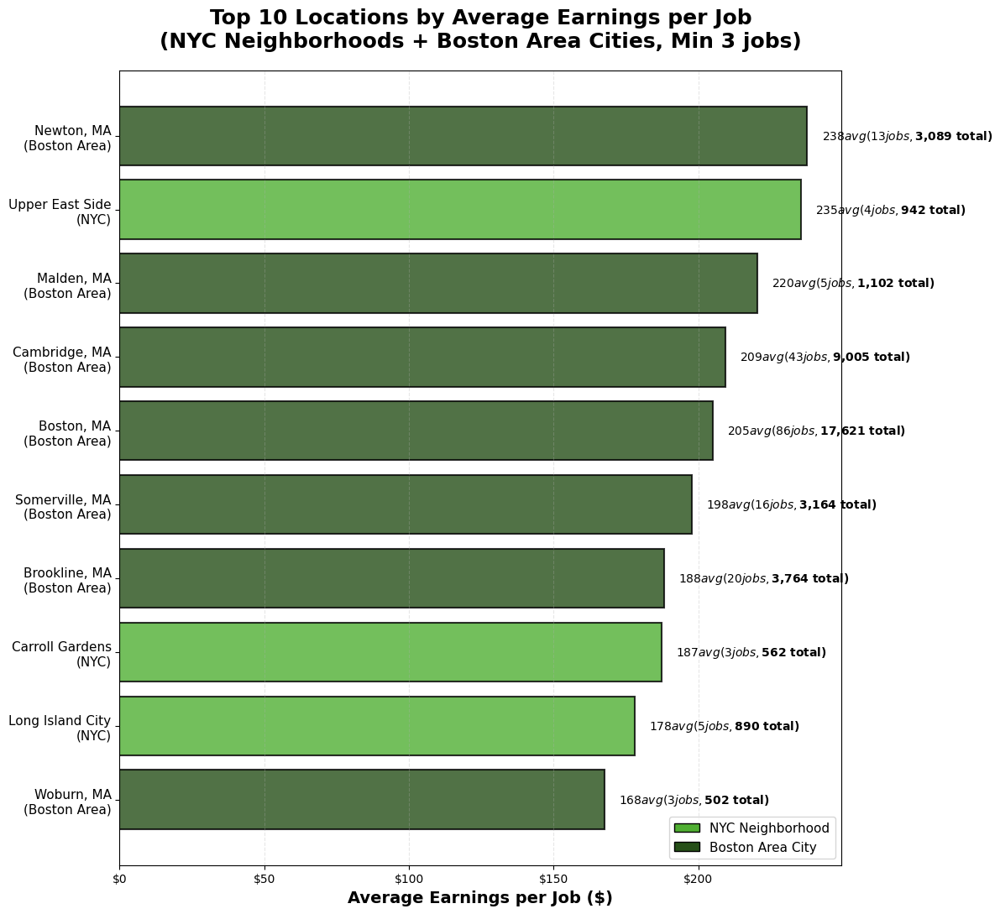

✓ Chart saved: top_10_locations_by_avg_earnings.png

TOP 10 LOCATIONS BY AVERAGE EARNINGS (Min 3 jobs):
        Location    Location_Type  Avg_Earnings  Job_Count  Total_Earnings
      Newton, MA Boston Area City    237.596154         13         3088.75
 Upper East Side NYC Neighborhood    235.375000          4          941.50
      Malden, MA Boston Area City    220.400000          5         1102.00
   Cambridge, MA Boston Area City    209.418605         43         9005.00
      Boston, MA Boston Area City    204.895349         86        17621.00
  Somerville, MA Boston Area City    197.750000         16         3164.00
   Brookline, MA Boston Area City    188.212500         20         3764.25
 Carroll Gardens NYC Neighborhood    187.166667          3          561.50
Long Island City NYC Neighborhood    178.050000          5          890.25
      Woburn, MA Boston Area City    167.500000          3          502.50


In [ ]:
# Top 10 Locations: NYC Neighborhoods + Boston Area Cities (Combined)

# Prepare NYC data (by neighborhood)
df_nyc = df[df['Market'] == 'NYC'].copy()
df_nyc['Location'] = df_nyc['Neighborhood'].fillna('NYC (unspecified)')
df_nyc['Location_Type'] = 'NYC Neighborhood'

# Prepare Boston data (by city)
df_boston = df[df['Market'] == 'Boston Area'].copy()
df_boston['Location'] = df_boston['City']
df_boston['Location_Type'] = 'Boston Area City'

# Combine both
df_combined = pd.concat([df_nyc, df_boston])

# Calculate stats by location
location_stats = df_combined.groupby(['Location', 'Location_Type']).agg({
    'Earnings': ['sum', 'mean', 'count'],
    'Hourly_Rate': 'mean'
}).reset_index()

# Flatten column names
location_stats.columns = ['_'.join(col).strip('_') if col[1] else col[0] 
                          for col in location_stats.columns.values]

# Rename columns
location_stats = location_stats.rename(columns={
    'Location': 'Location',
    'Location_Type': 'Location_Type',
    'Earnings_sum': 'Total_Earnings',
    'Earnings_mean': 'Avg_Earnings',
    'Earnings_count': 'Job_Count',
    'Hourly_Rate_mean': 'Avg_Hourly_Rate'
})

# Filter to locations with at least 3 jobs
location_filtered = location_stats[location_stats['Job_Count'] >= 3].copy()

# Sort by AVERAGE earnings and get top 10
top_locations = location_filtered.nlargest(10, 'Avg_Earnings')

# Create horizontal bar chart
fig, ax = plt.subplots(figsize=(12, 11))

# Color by location type
colors = ['#50AF33' if 'NYC' in loc_type else '#264F18' 
          for loc_type in top_locations['Location_Type']]

bars = ax.barh(range(len(top_locations)), top_locations['Avg_Earnings'], 
               color=colors, alpha=0.8, edgecolor='black', linewidth=1.5)

# Add value labels
for idx, (bar, avg, count, total, loc_type) in enumerate(zip(bars, 
                                                               top_locations['Avg_Earnings'],
                                                               top_locations['Job_Count'],
                                                               top_locations['Total_Earnings'],
                                                               top_locations['Location_Type'])):
    width = bar.get_width()
    ax.text(width + 5, bar.get_y() + bar.get_height()/2.,
            f'${avg:.0f} avg ({int(count)} jobs, ${total:,.0f} total)',
            ha='left', va='center', fontsize=10, fontweight='bold')

# Y-axis: Location names with type
y_labels = [f"{row['Location']}\n({row['Location_Type'].replace('NYC Neighborhood', 'NYC').replace('Boston Area City', 'Boston Area')})" 
            for _, row in top_locations.iterrows()]
ax.set_yticks(range(len(top_locations)))
ax.set_yticklabels(y_labels, fontsize=11)

# Styling
ax.set_title('Top 10 Locations by Average Earnings per Job\n(NYC Neighborhoods + Boston Area Cities, Min 3 jobs)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Average Earnings per Job ($)', fontsize=14, fontweight='bold')

# Format x-axis
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--', axis='x')

# Invert y-axis so #1 is on top
ax.invert_yaxis()

# Legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#50AF33', edgecolor='black', label='NYC Neighborhood'),
    Patch(facecolor='#264F18', edgecolor='black', label='Boston Area City')
]
ax.legend(handles=legend_elements, loc='lower right', fontsize=11)

plt.tight_layout()
plt.savefig('../visualizations/top_10_locations_by_avg_earnings.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Chart saved: top_10_locations_by_avg_earnings.png")

print("\n" + "="*80)
print("TOP 10 LOCATIONS BY AVERAGE EARNINGS (Min 3 jobs):")
print("="*80)
print(top_locations[['Location', 'Location_Type', 'Avg_Earnings', 'Job_Count', 'Total_Earnings']].to_string(index=False))

/tmp/ipykernel_3447/2461446679.py:4: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df_nyc_neighborhoods = df[df['Market'] == 'NYC'][df['Neighborhood'].notna()].copy()


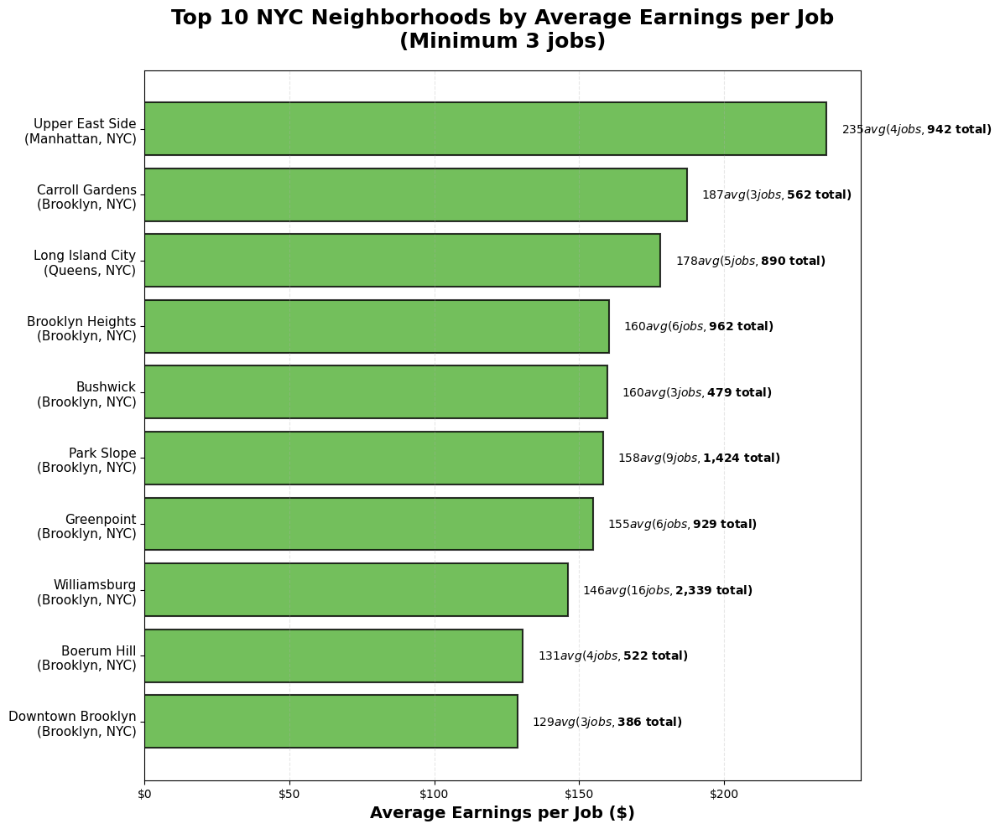

✓ Chart saved: top_10_nyc_neighborhoods_by_avg_earnings.png

TOP 10 NYC NEIGHBORHOODS BY AVERAGE EARNINGS (Min 3 jobs):
     Neighborhood        Borough  Avg_Earnings  Job_Count  Total_Earnings
  Upper East Side Manhattan, NYC    235.375000          4          941.50
  Carroll Gardens  Brooklyn, NYC    187.166667          3          561.50
 Long Island City    Queens, NYC    178.050000          5          890.25
 Brooklyn Heights  Brooklyn, NYC    160.291667          6          961.75
         Bushwick  Brooklyn, NYC    159.666667          3          479.00
       Park Slope  Brooklyn, NYC    158.277778          9         1424.50
       Greenpoint  Brooklyn, NYC    154.833333          6          929.00
     Williamsburg  Brooklyn, NYC    146.187500         16         2339.00
      Boerum Hill  Brooklyn, NYC    130.625000          4          522.50
Downtown Brooklyn  Brooklyn, NYC    128.666667          3          386.00

ALL NYC NEIGHBORHOODS (sorted by average earnings):
      Neighbo

In [ ]:
# Top 10 NYC Neighborhoods by AVERAGE Earnings per Job

# Filter to NYC jobs with neighborhood data
df_nyc_neighborhoods = df[df['Market'] == 'NYC'][df['Neighborhood'].notna()].copy()

# Calculate stats by neighborhood
nyc_neighborhood_stats = df_nyc_neighborhoods.groupby('Neighborhood').agg({
    'Earnings': ['sum', 'mean', 'count'],
    'Hourly_Rate': 'mean',
    'City': 'first'
}).reset_index()

# Flatten column names
nyc_neighborhood_stats.columns = ['_'.join(col).strip('_') if col[1] else col[0] 
                                   for col in nyc_neighborhood_stats.columns.values]

# Rename to cleaner names
nyc_neighborhood_stats = nyc_neighborhood_stats.rename(columns={
    'Neighborhood': 'Neighborhood',
    'Earnings_sum': 'Total_Earnings',
    'Earnings_mean': 'Avg_Earnings',
    'Earnings_count': 'Job_Count',
    'Hourly_Rate_mean': 'Avg_Hourly_Rate',
    'City_first': 'Borough'
})

# Filter to neighborhoods with at least 3 jobs
nyc_filtered = nyc_neighborhood_stats[nyc_neighborhood_stats['Job_Count'] >= 3].copy()

# Sort by AVERAGE earnings and get top 10
top_nyc_neighborhoods = nyc_filtered.nlargest(10, 'Avg_Earnings')

# Create horizontal bar chart
fig, ax = plt.subplots(figsize=(12, 10))

# All TaskRabbit light green for NYC
colors = ['#50AF33'] * len(top_nyc_neighborhoods)

bars = ax.barh(range(len(top_nyc_neighborhoods)), top_nyc_neighborhoods['Avg_Earnings'], 
               color=colors, alpha=0.8, edgecolor='black', linewidth=1.5)

# Add value labels
for idx, (bar, avg, count, total) in enumerate(zip(bars, 
                                                     top_nyc_neighborhoods['Avg_Earnings'],
                                                     top_nyc_neighborhoods['Job_Count'],
                                                     top_nyc_neighborhoods['Total_Earnings'])):
    width = bar.get_width()
    ax.text(width + 5, bar.get_y() + bar.get_height()/2.,
            f'${avg:.0f} avg ({int(count)} jobs, ${total:,.0f} total)',
            ha='left', va='center', fontsize=10, fontweight='bold')

# Y-axis: Neighborhood names with borough
y_labels = [f"{row['Neighborhood']}\n({row['Borough']})" 
            for _, row in top_nyc_neighborhoods.iterrows()]
ax.set_yticks(range(len(top_nyc_neighborhoods)))
ax.set_yticklabels(y_labels, fontsize=11)

# Styling
ax.set_title('Top 10 NYC Neighborhoods by Average Earnings per Job\n(Minimum 3 jobs)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Average Earnings per Job ($)', fontsize=14, fontweight='bold')

# Format x-axis
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--', axis='x')

# Invert y-axis so #1 is on top
ax.invert_yaxis()

plt.tight_layout()
plt.savefig('../visualizations/top_10_nyc_neighborhoods_by_avg_earnings.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Chart saved: top_10_nyc_neighborhoods_by_avg_earnings.png")

print("\n" + "="*80)
print("TOP 10 NYC NEIGHBORHOODS BY AVERAGE EARNINGS (Min 3 jobs):")
print("="*80)
print(top_nyc_neighborhoods[['Neighborhood', 'Borough', 'Avg_Earnings', 'Job_Count', 'Total_Earnings']].to_string(index=False))

# Also show ALL NYC neighborhoods for reference
print("\n" + "="*80)
print("ALL NYC NEIGHBORHOODS (sorted by average earnings):")
print("="*80)
all_nyc = nyc_neighborhood_stats.sort_values('Avg_Earnings', ascending=False)
print(all_nyc[['Neighborhood', 'Borough', 'Avg_Earnings', 'Job_Count', 'Total_Earnings']].to_string(index=False))

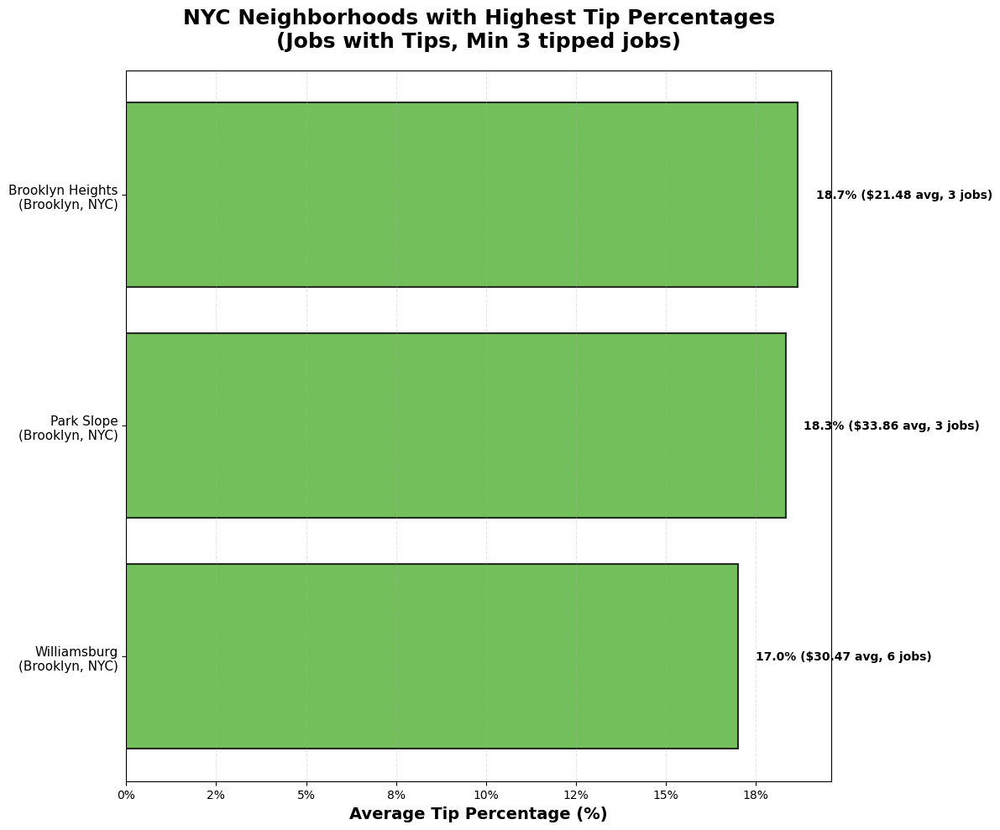

✓ Chart saved: nyc_best_tipping_neighborhoods.png

NYC NEIGHBORHOODS - BEST TIPPERS:
    Neighborhood       Borough  Avg_Tip_Pct  Avg_Tip_Amount  Tipped_Jobs
Brooklyn Heights Brooklyn, NYC    18.666667       21.480000            3
      Park Slope Brooklyn, NYC    18.333333       33.860000            3
    Williamsburg Brooklyn, NYC    17.000000       30.468333            6


In [ ]:
# NYC Neighborhoods - Best Tippers by Tip Percentage

# Filter to NYC jobs with tips
df_nyc_tips = df[(df['Market'] == 'NYC') & 
                  (df['Tip'] > 0) & 
                  (df['Neighborhood'].notna()) & 
                  (df['Tip_Percentage'].notna())].copy()

# Calculate tip stats by neighborhood
nyc_tip_stats = df_nyc_tips.groupby('Neighborhood').agg({
    'Tip_Percentage': 'mean',
    'Tip': ['mean', 'sum', 'count'],
    'City': 'first'
}).reset_index()

# Flatten columns
nyc_tip_stats.columns = ['_'.join(col).strip('_') if col[1] else col[0] 
                         for col in nyc_tip_stats.columns.values]

nyc_tip_stats = nyc_tip_stats.rename(columns={
    'Neighborhood': 'Neighborhood',
    'Tip_Percentage_mean': 'Avg_Tip_Pct',
    'Tip_mean': 'Avg_Tip_Amount',
    'Tip_sum': 'Total_Tips',
    'Tip_count': 'Tipped_Jobs',
    'City_first': 'Borough'
})

# Filter to neighborhoods with at least 3 tipped jobs
nyc_tip_filtered = nyc_tip_stats[nyc_tip_stats['Tipped_Jobs'] >= 3].copy()

# Sort by tip percentage
top_nyc_tippers = nyc_tip_filtered.nlargest(10, 'Avg_Tip_Pct')

# Create chart
fig, ax = plt.subplots(figsize=(12, 10))

bars = ax.barh(range(len(top_nyc_tippers)), top_nyc_tippers['Avg_Tip_Pct'], 
               color='#50AF33', alpha=0.8, edgecolor='black', linewidth=1.5)

# Add value labels
for idx, (bar, pct, amt, count) in enumerate(zip(bars, 
                                                   top_nyc_tippers['Avg_Tip_Pct'],
                                                   top_nyc_tippers['Avg_Tip_Amount'],
                                                   top_nyc_tippers['Tipped_Jobs'])):
    width = bar.get_width()
    ax.text(width + 0.5, bar.get_y() + bar.get_height()/2.,
            f'{pct:.1f}% (${amt:.2f} avg, {int(count)} jobs)',
            ha='left', va='center', fontsize=10, fontweight='bold')

# Y-axis
y_labels = [f"{row['Neighborhood']}\n({row['Borough']})" 
            for _, row in top_nyc_tippers.iterrows()]
ax.set_yticks(range(len(top_nyc_tippers)))
ax.set_yticklabels(y_labels, fontsize=11)

# Styling
ax.set_title('NYC Neighborhoods with Highest Tip Percentages\n(Jobs with Tips, Min 3 tipped jobs)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Average Tip Percentage (%)', fontsize=14, fontweight='bold')

ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x:.0f}%'))
ax.grid(True, alpha=0.3, linestyle='--', axis='x')
ax.invert_yaxis()

plt.tight_layout()
plt.savefig('../visualizations/nyc_best_tipping_neighborhoods.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Chart saved: nyc_best_tipping_neighborhoods.png")
print("\n" + "="*80)
print("NYC NEIGHBORHOODS - BEST TIPPERS:")
print(top_nyc_tippers[['Neighborhood', 'Borough', 'Avg_Tip_Pct', 'Avg_Tip_Amount', 'Tipped_Jobs']].to_string(index=False))

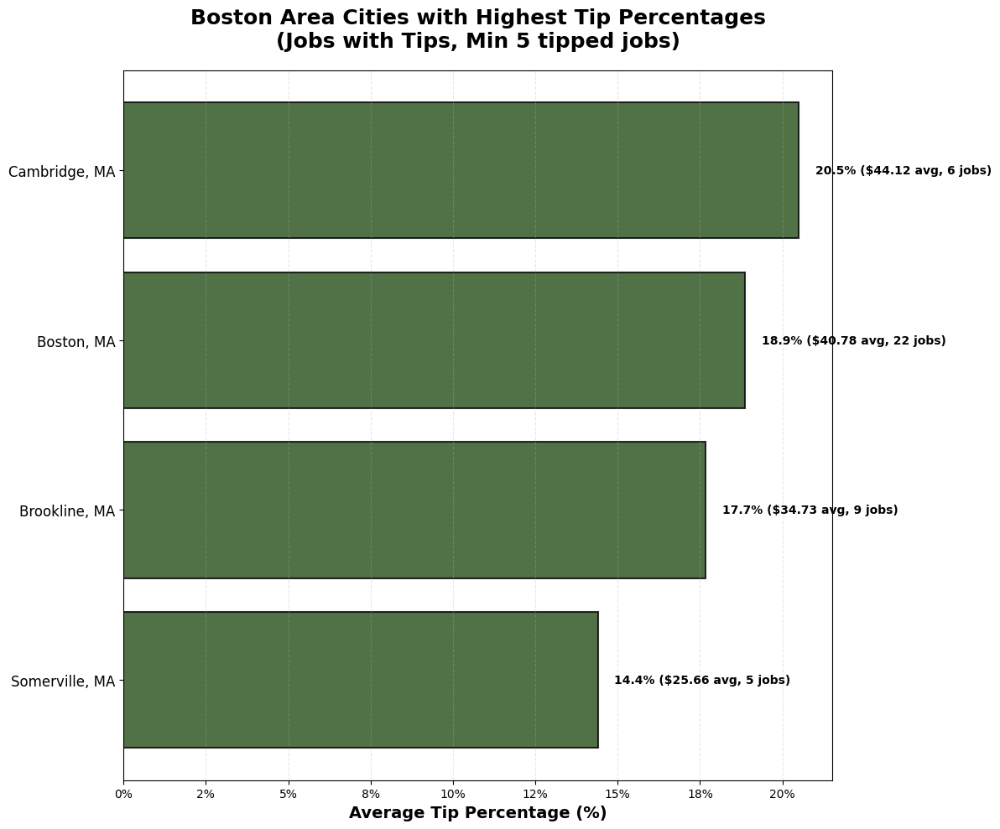

✓ Chart saved: boston_best_tipping_cities.png

BOSTON AREA CITIES - BEST TIPPERS:
          City  Avg_Tip_Pct  Avg_Tip_Amount  Tipped_Jobs
 Cambridge, MA    20.500000       44.116667            6
    Boston, MA    18.863636       40.779545           22
 Brookline, MA    17.666667       34.725556            9
Somerville, MA    14.400000       25.660000            5


In [ ]:
# Boston Area Cities - Best Tippers by Tip Percentage

# Filter to Boston jobs with tips
df_boston_tips = df[(df['Market'] == 'Boston Area') & 
                     (df['Tip'] > 0) & 
                     (df['Tip_Percentage'].notna())].copy()

# Calculate tip stats by city
boston_tip_stats = df_boston_tips.groupby('City').agg({
    'Tip_Percentage': 'mean',
    'Tip': ['mean', 'sum', 'count']
}).reset_index()

# Flatten columns
boston_tip_stats.columns = ['_'.join(col).strip('_') if col[1] else col[0] 
                            for col in boston_tip_stats.columns.values]

boston_tip_stats = boston_tip_stats.rename(columns={
    'City': 'City',
    'Tip_Percentage_mean': 'Avg_Tip_Pct',
    'Tip_mean': 'Avg_Tip_Amount',
    'Tip_sum': 'Total_Tips',
    'Tip_count': 'Tipped_Jobs'
})

# Filter to cities with at least 5 tipped jobs
boston_tip_filtered = boston_tip_stats[boston_tip_stats['Tipped_Jobs'] >= 5].copy()

# Sort by tip percentage
top_boston_tippers = boston_tip_filtered.nlargest(10, 'Avg_Tip_Pct')

# Create chart
fig, ax = plt.subplots(figsize=(12, 10))

bars = ax.barh(range(len(top_boston_tippers)), top_boston_tippers['Avg_Tip_Pct'], 
               color='#264F18', alpha=0.8, edgecolor='black', linewidth=1.5)

# Add value labels
for idx, (bar, pct, amt, count) in enumerate(zip(bars, 
                                                   top_boston_tippers['Avg_Tip_Pct'],
                                                   top_boston_tippers['Avg_Tip_Amount'],
                                                   top_boston_tippers['Tipped_Jobs'])):
    width = bar.get_width()
    ax.text(width + 0.5, bar.get_y() + bar.get_height()/2.,
            f'{pct:.1f}% (${amt:.2f} avg, {int(count)} jobs)',
            ha='left', va='center', fontsize=10, fontweight='bold')

# Y-axis
ax.set_yticks(range(len(top_boston_tippers)))
ax.set_yticklabels(top_boston_tippers['City'], fontsize=12)

# Styling
ax.set_title('Boston Area Cities with Highest Tip Percentages\n(Jobs with Tips, Min 5 tipped jobs)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Average Tip Percentage (%)', fontsize=14, fontweight='bold')

ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x:.0f}%'))
ax.grid(True, alpha=0.3, linestyle='--', axis='x')
ax.invert_yaxis()

plt.tight_layout()
plt.savefig('../visualizations/boston_best_tipping_cities.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Chart saved: boston_best_tipping_cities.png")
print("\n" + "="*80)
print("BOSTON AREA CITIES - BEST TIPPERS:")
print(top_boston_tippers[['City', 'Avg_Tip_Pct', 'Avg_Tip_Amount', 'Tipped_Jobs']].to_string(index=False))

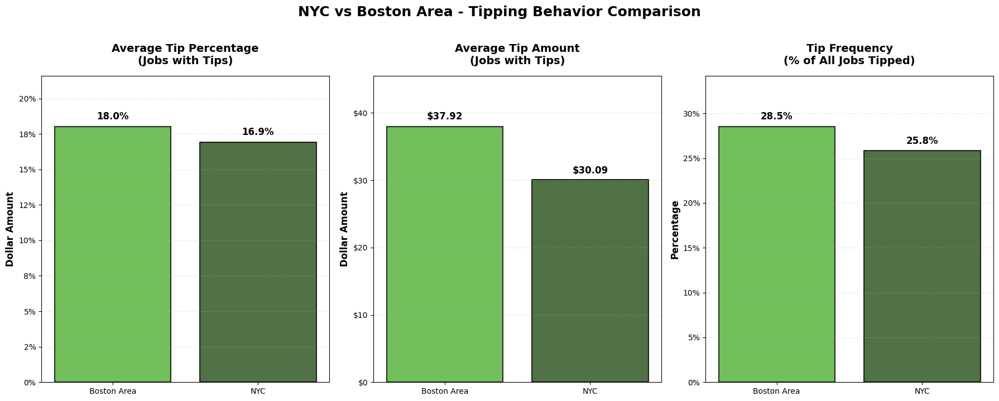

✓ Chart saved: nyc_vs_boston_tipping_comparison.png

NYC VS BOSTON TIPPING COMPARISON:
     Market  Avg_Tip_Pct  Avg_Tip_Amount  Tip_Frequency_%  Tipped_Jobs  Total_Jobs
Boston Area    18.000000       37.920169        28.502415           59         207
        NYC    16.913043       30.091739        25.842697           23          89


In [ ]:
# NYC vs Boston Area - Tipping Comparison

# Calculate overall tipping metrics by market
df_tips_only = df[(df['Tip'] > 0) & (df['Tip_Percentage'].notna())].copy()

market_tip_comparison = df_tips_only.groupby('Market').agg({
    'Tip_Percentage': 'mean',
    'Tip': 'mean',
    'Has_Tip': 'count'  # Count of tipped jobs
}).reset_index()

market_tip_comparison.columns = ['Market', 'Avg_Tip_Pct', 'Avg_Tip_Amount', 'Tipped_Jobs']

# Also calculate tip frequency (% of all jobs that get tips)
all_jobs_by_market = df.groupby('Market').size().reset_index(name='Total_Jobs')
market_tip_comparison = market_tip_comparison.merge(all_jobs_by_market, on='Market')
market_tip_comparison['Tip_Frequency_%'] = (market_tip_comparison['Tipped_Jobs'] / market_tip_comparison['Total_Jobs']) * 100

# Filter to main markets
market_comparison = market_tip_comparison[market_tip_comparison['Market'].isin(['NYC', 'Boston Area'])]

# Create side-by-side comparison
fig, axes = plt.subplots(1, 3, figsize=(18, 7))

metrics = [
    ('Avg_Tip_Pct', 'Average Tip Percentage\n(Jobs with Tips)', '%'),
    ('Avg_Tip_Amount', 'Average Tip Amount\n(Jobs with Tips)', '$'),
    ('Tip_Frequency_%', 'Tip Frequency\n(% of All Jobs Tipped)', '%')
]

colors = ['#50AF33', '#264F18']  # NYC light green, Boston dark green

for idx, (metric, title, symbol) in enumerate(metrics):
    ax = axes[idx]
    
    bars = ax.bar(market_comparison['Market'], market_comparison[metric],
                  color=colors, alpha=0.8, edgecolor='black', linewidth=1.5)
    
    # Add value labels
    for bar, value in zip(bars, market_comparison[metric]):
        height = bar.get_height()
        if symbol == '$':
            label = f'${value:.2f}'
        else:
            label = f'{value:.1f}%'
        ax.text(bar.get_x() + bar.get_width()/2., height + (height * 0.02),
                label, ha='center', va='bottom', fontsize=12, fontweight='bold')
    
    # Styling
    ax.set_title(title, fontsize=14, fontweight='bold', pad=15)
    ax.set_ylabel(f'{"Percentage" if "%" in title else "Dollar Amount"}', fontsize=12, fontweight='bold')
    
    if symbol == '%':
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x:.0f}%'))
    else:
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))
    
    ax.grid(True, alpha=0.3, linestyle='--', axis='y')
    ax.set_ylim(0, market_comparison[metric].max() * 1.2)

plt.suptitle('NYC vs Boston Area - Tipping Behavior Comparison', 
             fontsize=18, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../visualizations/nyc_vs_boston_tipping_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Chart saved: nyc_vs_boston_tipping_comparison.png")
print("\n" + "="*80)
print("NYC VS BOSTON TIPPING COMPARISON:")
print(market_comparison[['Market', 'Avg_Tip_Pct', 'Avg_Tip_Amount', 'Tip_Frequency_%', 'Tipped_Jobs', 'Total_Jobs']].to_string(index=False))

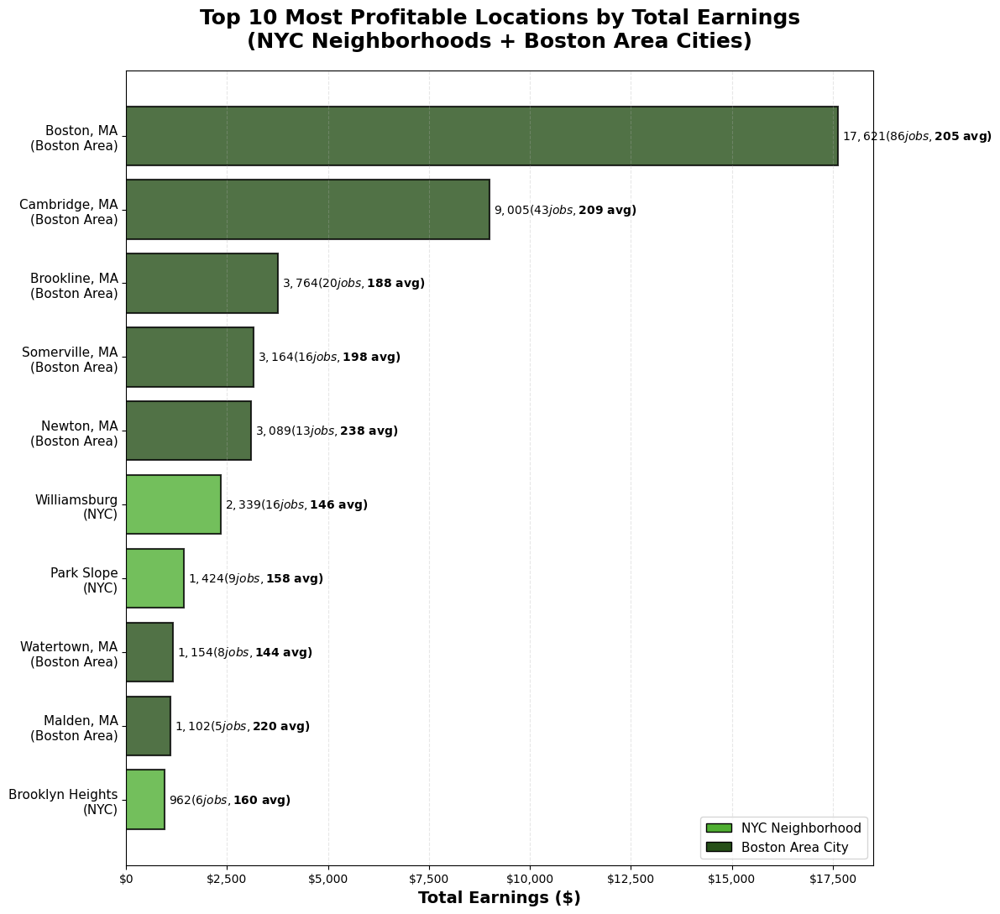

✓ Chart saved: top_10_most_profitable_locations_total.png

TOP 10 MOST PROFITABLE LOCATIONS (by Total Earnings):
        Location    Location_Type  Total_Earnings  Job_Count  Avg_Earnings
      Boston, MA Boston Area City        17621.00         86    204.895349
   Cambridge, MA Boston Area City         9005.00         43    209.418605
   Brookline, MA Boston Area City         3764.25         20    188.212500
  Somerville, MA Boston Area City         3164.00         16    197.750000
      Newton, MA Boston Area City         3088.75         13    237.596154
    Williamsburg NYC Neighborhood         2339.00         16    146.187500
      Park Slope NYC Neighborhood         1424.50          9    158.277778
   Watertown, MA Boston Area City         1154.00          8    144.250000
      Malden, MA Boston Area City         1102.00          5    220.400000
Brooklyn Heights NYC Neighborhood          961.75          6    160.291667


In [ ]:
# Top 10 Most Profitable Locations by TOTAL Earnings (NYC + Boston)

# Prepare NYC data (by neighborhood)
df_nyc = df[df['Market'] == 'NYC'].copy()
df_nyc['Location'] = df_nyc['Neighborhood'].fillna('NYC (unspecified)')
df_nyc['Location_Type'] = 'NYC Neighborhood'

# Prepare Boston data (by city)
df_boston = df[df['Market'] == 'Boston Area'].copy()
df_boston['Location'] = df_boston['City']
df_boston['Location_Type'] = 'Boston Area City'

# Combine both
df_combined = pd.concat([df_nyc, df_boston])

# Calculate stats by location
location_stats = df_combined.groupby(['Location', 'Location_Type']).agg({
    'Earnings': ['sum', 'mean', 'count'],
    'Hourly_Rate': 'mean'
}).reset_index()

# Flatten column names
location_stats.columns = ['_'.join(col).strip('_') if col[1] else col[0] 
                          for col in location_stats.columns.values]

# Rename columns
location_stats = location_stats.rename(columns={
    'Location': 'Location',
    'Location_Type': 'Location_Type',
    'Earnings_sum': 'Total_Earnings',
    'Earnings_mean': 'Avg_Earnings',
    'Earnings_count': 'Job_Count',
    'Hourly_Rate_mean': 'Avg_Hourly_Rate'
})

# Sort by TOTAL earnings and get top 10
top_locations_total = location_stats.nlargest(10, 'Total_Earnings')

# Create horizontal bar chart
fig, ax = plt.subplots(figsize=(12, 11))

# Color by location type
colors = ['#50AF33' if 'NYC' in loc_type else '#264F18' 
          for loc_type in top_locations_total['Location_Type']]

bars = ax.barh(range(len(top_locations_total)), top_locations_total['Total_Earnings'], 
               color=colors, alpha=0.8, edgecolor='black', linewidth=1.5)

# Add value labels
for idx, (bar, total, count, avg) in enumerate(zip(bars, 
                                                     top_locations_total['Total_Earnings'],
                                                     top_locations_total['Job_Count'],
                                                     top_locations_total['Avg_Earnings'])):
    width = bar.get_width()
    ax.text(width + 100, bar.get_y() + bar.get_height()/2.,
            f'${total:,.0f} ({int(count)} jobs, ${avg:.0f} avg)',
            ha='left', va='center', fontsize=10, fontweight='bold')

# Y-axis: Location names with type
y_labels = [f"{row['Location']}\n({row['Location_Type'].replace('NYC Neighborhood', 'NYC').replace('Boston Area City', 'Boston Area')})" 
            for _, row in top_locations_total.iterrows()]
ax.set_yticks(range(len(top_locations_total)))
ax.set_yticklabels(y_labels, fontsize=11)

# Styling
ax.set_title('Top 10 Most Profitable Locations by Total Earnings\n(NYC Neighborhoods + Boston Area Cities)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Total Earnings ($)', fontsize=14, fontweight='bold')

# Format x-axis
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:,.0f}'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--', axis='x')

# Invert y-axis so #1 is on top
ax.invert_yaxis()

# Legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#50AF33', edgecolor='black', label='NYC Neighborhood'),
    Patch(facecolor='#264F18', edgecolor='black', label='Boston Area City')
]
ax.legend(handles=legend_elements, loc='lower right', fontsize=11)

plt.tight_layout()
plt.savefig('../visualizations/top_10_most_profitable_locations_total.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Chart saved: top_10_most_profitable_locations_total.png")

print("\n" + "="*80)
print("TOP 10 MOST PROFITABLE LOCATIONS (by Total Earnings):")
print("="*80)
print(top_locations_total[['Location', 'Location_Type', 'Total_Earnings', 'Job_Count', 'Avg_Earnings']].to_string(index=False))

MOST COMMON SERVICE TYPES BY TOP 10 LOCATIONS

Boston, MA (Boston Area):
Total jobs: 86
  1. Packing & Unpacking: 49 jobs (57.0%)
  2. Photography: 18 jobs (20.9%)
  3. Computer Help: 8 jobs (9.3%)

Cambridge, MA (Boston Area):
Total jobs: 43
  1. Packing & Unpacking: 22 jobs (51.2%)
  2. Event Staffing: 8 jobs (18.6%)
  3. Photography: 5 jobs (11.6%)

Brookline, MA (Boston Area):
Total jobs: 20
  1. Packing & Unpacking: 12 jobs (60.0%)
  2. Organization: 3 jobs (15.0%)
  3. Computer Help: 2 jobs (10.0%)

Somerville, MA (Boston Area):
Total jobs: 16
  1. Packing & Unpacking: 11 jobs (68.8%)
  2. Organization: 2 jobs (12.5%)
  3. Event Staffing: 2 jobs (12.5%)

Newton, MA (Boston Area):
Total jobs: 13
  1. Packing & Unpacking: 6 jobs (46.2%)
  2. Photography: 2 jobs (15.4%)
  3. Computer Help: 2 jobs (15.4%)

Williamsburg (NYC):
Total jobs: 16
  1. Packing & Unpacking: 13 jobs (81.2%)
  2. Photography: 2 jobs (12.5%)
  3. Computer Help: 1 jobs (6.2%)

Park Slope (NYC):
Total jobs: 9
  1

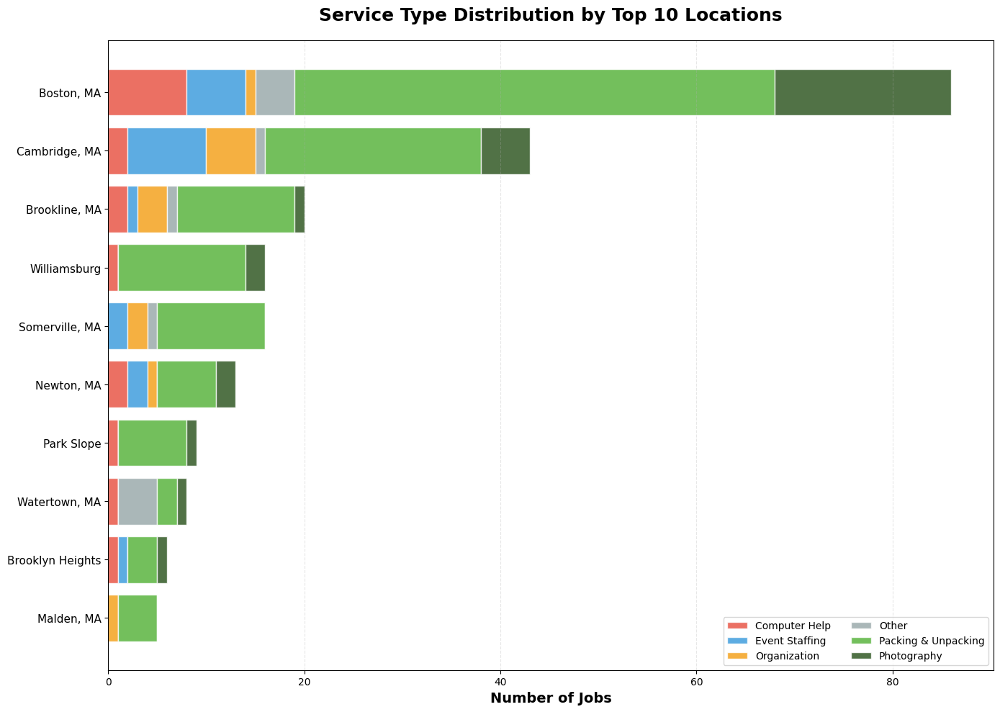


✓ Chart saved: service_types_by_top_locations.png


In [ ]:
# Most Common Service Types by Top Locations

# Get top 10 locations from previous analysis
top_10_locations = top_locations_total['Location'].tolist()

# Filter data to top 10 locations
df_top_locations = df_combined[df_combined['Location'].isin(top_10_locations)].copy()

print("="*80)
print("MOST COMMON SERVICE TYPES BY TOP 10 LOCATIONS")
print("="*80)

for location in top_10_locations:
    location_data = df_top_locations[df_top_locations['Location'] == location]
    location_type = location_data['Location_Type'].iloc[0]
    
    print(f"\n{location} ({location_type.replace('NYC Neighborhood', 'NYC').replace('Boston Area City', 'Boston Area')}):")
    print(f"Total jobs: {len(location_data)}")
    
    # Get top 3 service types
    top_services = location_data['Category'].value_counts().head(3)
    for idx, (service, count) in enumerate(top_services.items(), 1):
        pct = (count / len(location_data)) * 100
        print(f"  {idx}. {service}: {count} jobs ({pct:.1f}%)")

# Create a visual summary - stacked bar chart
# Prepare data
service_by_location = df_top_locations.groupby(['Location', 'Category']).size().reset_index(name='Count')

# Get top 5 services overall
top_services_overall = df_top_locations['Category'].value_counts().head(5).index.tolist()

# Filter to top services only, group others as "Other"
service_by_location['Category_Grouped'] = service_by_location['Category'].apply(
    lambda x: x if x in top_services_overall else 'Other'
)

# Aggregate
service_pivot = service_by_location.groupby(['Location', 'Category_Grouped'])['Count'].sum().unstack(fill_value=0)

# Sort by total jobs
service_pivot['Total'] = service_pivot.sum(axis=1)
service_pivot = service_pivot.sort_values('Total', ascending=True).drop('Total', axis=1)

# Create stacked horizontal bar chart
fig, ax = plt.subplots(figsize=(14, 10))

# Colors for different services
service_colors = {
    'Packing & Unpacking': '#50AF33',
    'Photography': '#264F18',
    'Event Staffing': '#3498db',
    'Computer Help': '#e74c3c',
    'Organization': '#f39c12',
    'Other': '#95a5a6'
}

# Create stacked bars
left = [0] * len(service_pivot)
for service in service_pivot.columns:
    color = service_colors.get(service, '#95a5a6')
    bars = ax.barh(range(len(service_pivot)), service_pivot[service], 
                   left=left, label=service, color=color, alpha=0.8, edgecolor='white', linewidth=1)
    left = [l + r for l, r in zip(left, service_pivot[service])]

# Y-axis
ax.set_yticks(range(len(service_pivot)))
ax.set_yticklabels(service_pivot.index, fontsize=11)

# Styling
ax.set_title('Service Type Distribution by Top 10 Locations', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Number of Jobs', fontsize=14, fontweight='bold')

ax.grid(True, alpha=0.3, linestyle='--', axis='x')
ax.legend(loc='lower right', fontsize=10, ncol=2)

plt.tight_layout()
plt.savefig('../visualizations/service_types_by_top_locations.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Chart saved: service_types_by_top_locations.png")

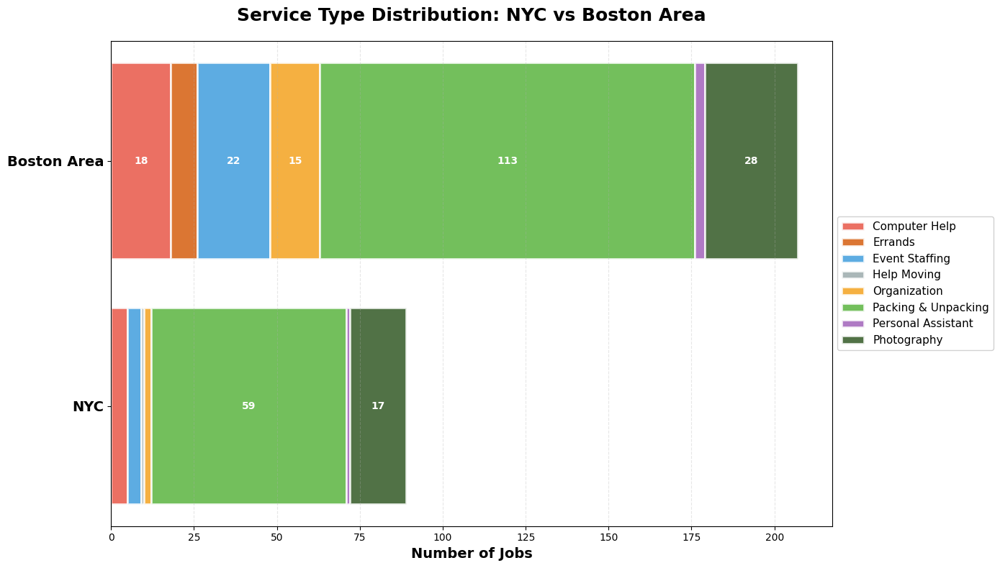

✓ Chart saved: service_types_nyc_vs_boston.png

SERVICE TYPE BREAKDOWN BY MARKET:

NYC (89 total jobs):
  Packing & Unpacking             59 jobs ( 66.3%)
  Photography                     17 jobs ( 19.1%)
  Computer Help                    5 jobs (  5.6%)
  Event Staffing                   4 jobs (  4.5%)
  Organization                     2 jobs (  2.2%)
  Help Moving                      1 jobs (  1.1%)
  Personal Assistant               1 jobs (  1.1%)

Boston Area (207 total jobs):
  Packing & Unpacking            113 jobs ( 54.6%)
  Photography                     28 jobs ( 13.5%)
  Event Staffing                  22 jobs ( 10.6%)
  Computer Help                   18 jobs (  8.7%)
  Organization                    15 jobs (  7.2%)
  Errands                          8 jobs (  3.9%)
  Personal Assistant               3 jobs (  1.4%)

KEY DIFFERENCES:
Packing & Unpacking:
  NYC: 66.3% | Boston: 54.6% | Difference: -11.7 pts
Photography:
  NYC: 19.1% | Boston: 13.5% | Difference: -5.

In [ ]:
# Service Type Distribution: NYC vs Boston Area

# Filter to main markets
df_markets_only = df[df['Market'].isin(['NYC', 'Boston Area'])].copy()

# Calculate service counts by market
service_by_market = df_markets_only.groupby(['Market', 'Category']).size().reset_index(name='Count')

# Pivot for stacked bar chart
service_pivot = service_by_market.pivot(index='Market', columns='Category', values='Count').fillna(0)

# Sort markets (NYC first, then Boston)
service_pivot = service_pivot.reindex(['NYC', 'Boston Area'])

# Create stacked horizontal bar chart
fig, ax = plt.subplots(figsize=(14, 8))

# Colors for different services (using TaskRabbit colors + complementary)
service_colors = {
    'Packing & Unpacking': '#50AF33',
    'Photography': '#264F18',
    'Event Staffing': '#3498db',
    'Computer Help': '#e74c3c',
    'Organization': '#f39c12',
    'Personal Assistant': '#9b59b6',
    'Writing & Editing': '#1abc9c',
    'Web Design & Development': '#34495e',
    'Office Administration': '#95a5a6',
    'Errands': '#d35400',
    'Other': '#7f8c8d'
}

# Create stacked bars
left = [0] * len(service_pivot)
for service in service_pivot.columns:
    color = service_colors.get(service, '#95a5a6')
    bars = ax.barh(range(len(service_pivot)), service_pivot[service], 
                   left=left, label=service, color=color, alpha=0.8, 
                   edgecolor='white', linewidth=2)
    
    # Add count labels for larger segments (>10 jobs)
    for i, (bar, count) in enumerate(zip(bars, service_pivot[service])):
        if count > 10:
            width = bar.get_width()
            x_pos = bar.get_x() + width / 2
            ax.text(x_pos, bar.get_y() + bar.get_height()/2., 
                   f'{int(count)}',
                   ha='center', va='center', fontsize=10, 
                   fontweight='bold', color='white')
    
    left = [l + r for l, r in zip(left, service_pivot[service])]

# Y-axis - market names
ax.set_yticks(range(len(service_pivot)))
ax.set_yticklabels(service_pivot.index, fontsize=14, fontweight='bold')

# Styling
ax.set_title('Service Type Distribution: NYC vs Boston Area', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Number of Jobs', fontsize=14, fontweight='bold')

ax.grid(True, alpha=0.3, linestyle='--', axis='x')

# Legend - place outside plot area
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5), fontsize=11, framealpha=0.9)

plt.tight_layout()
plt.savefig('../visualizations/service_types_nyc_vs_boston.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Chart saved: service_types_nyc_vs_boston.png")

# Print detailed breakdown
print("\n" + "="*80)
print("SERVICE TYPE BREAKDOWN BY MARKET:")
print("="*80)

for market in ['NYC', 'Boston Area']:
    market_data = df_markets_only[df_markets_only['Market'] == market]
    total_jobs = len(market_data)
    
    print(f"\n{market} ({total_jobs} total jobs):")
    service_counts = market_data['Category'].value_counts()
    
    for service, count in service_counts.items():
        pct = (count / total_jobs) * 100
        print(f"  {service:30} {count:3d} jobs ({pct:5.1f}%)")

# Calculate market differences
print("\n" + "="*80)
print("KEY DIFFERENCES:")
print("="*80)

# Percentage breakdown
nyc_pct = (df_markets_only[df_markets_only['Market'] == 'NYC']['Category'].value_counts() / len(df_markets_only[df_markets_only['Market'] == 'NYC'])) * 100
boston_pct = (df_markets_only[df_markets_only['Market'] == 'Boston Area']['Category'].value_counts() / len(df_markets_only[df_markets_only['Market'] == 'Boston Area'])) * 100

# Compare top services
for service in ['Packing & Unpacking', 'Photography', 'Event Staffing', 'Computer Help']:
    nyc_val = nyc_pct.get(service, 0)
    boston_val = boston_pct.get(service, 0)
    diff = boston_val - nyc_val
    
    print(f"{service}:")
    print(f"  NYC: {nyc_val:.1f}% | Boston: {boston_val:.1f}% | Difference: {diff:+.1f} pts")

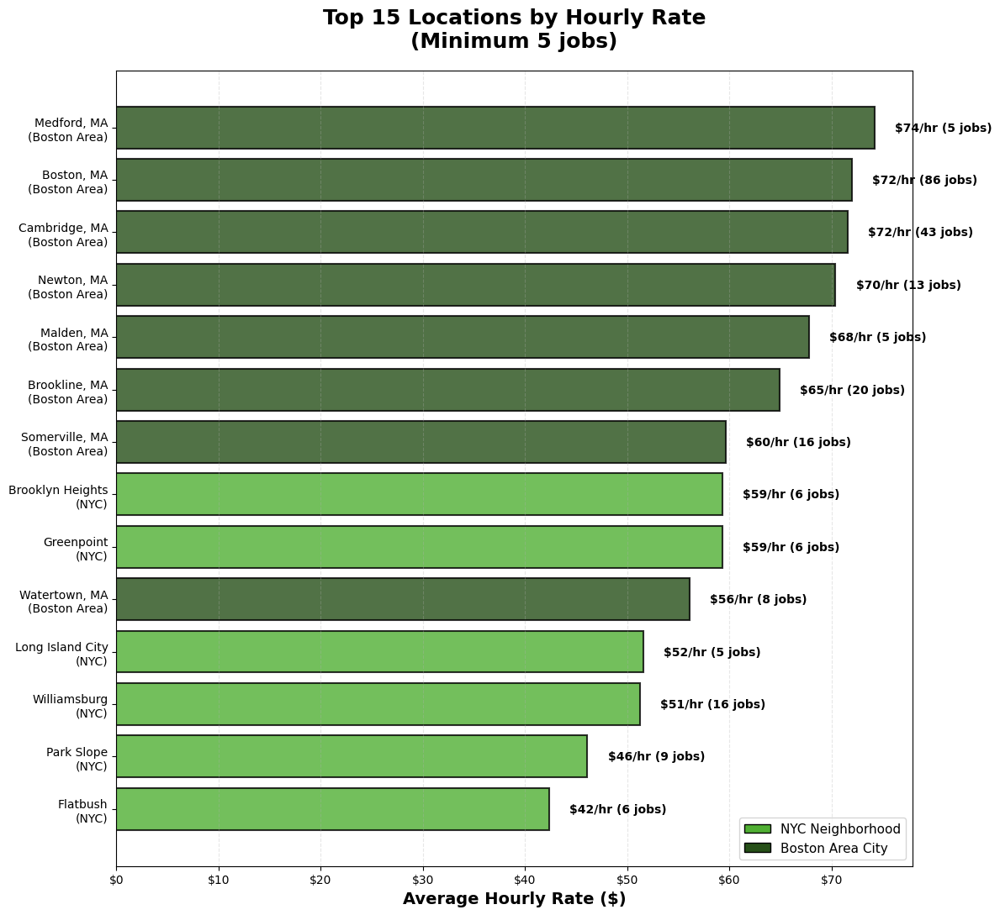

✓ Chart saved: top_locations_by_hourly_rate.png

TOP 15 LOCATIONS BY HOURLY RATE:
        Location    Location_Type  Avg_Hourly_Rate  Job_Count
     Medford, MA Boston Area City        74.200000          5
      Boston, MA Boston Area City        72.000000         86
   Cambridge, MA Boston Area City        71.558140         43
      Newton, MA Boston Area City        70.384615         13
      Malden, MA Boston Area City        67.800000          5
   Brookline, MA Boston Area City        64.900000         20
  Somerville, MA Boston Area City        59.625000         16
Brooklyn Heights NYC Neighborhood        59.333333          6
      Greenpoint NYC Neighborhood        59.333333          6
   Watertown, MA Boston Area City        56.125000          8
Long Island City NYC Neighborhood        51.600000          5
    Williamsburg NYC Neighborhood        51.250000         16
      Park Slope NYC Neighborhood        46.111111          9
        Flatbush NYC Neighborhood        42.333333

In [ ]:
# Hourly Rate by Location (Top 15 locations)

# Use the combined location data from before
location_hourly_stats = df_combined.groupby(['Location', 'Location_Type']).agg({
    'Hourly_Rate': 'mean',
    'Earnings': ['sum', 'count']
}).reset_index()

# Flatten columns
location_hourly_stats.columns = ['_'.join(col).strip('_') if col[1] else col[0] 
                                  for col in location_hourly_stats.columns.values]

location_hourly_stats = location_hourly_stats.rename(columns={
    'Location': 'Location',
    'Location_Type': 'Location_Type',
    'Hourly_Rate_mean': 'Avg_Hourly_Rate',
    'Earnings_sum': 'Total_Earnings',
    'Earnings_count': 'Job_Count'
})

# Filter to locations with at least 5 jobs
location_hourly_filtered = location_hourly_stats[location_hourly_stats['Job_Count'] >= 5].copy()

# Get top 15 by hourly rate
top_hourly_locations = location_hourly_filtered.nlargest(15, 'Avg_Hourly_Rate')

# Create horizontal bar chart
fig, ax = plt.subplots(figsize=(12, 11))

# Color by location type
colors = ['#50AF33' if 'NYC' in loc_type else '#264F18' 
          for loc_type in top_hourly_locations['Location_Type']]

bars = ax.barh(range(len(top_hourly_locations)), top_hourly_locations['Avg_Hourly_Rate'], 
               color=colors, alpha=0.8, edgecolor='black', linewidth=1.5)

# Add value labels
for idx, (bar, rate, count) in enumerate(zip(bars, 
                                               top_hourly_locations['Avg_Hourly_Rate'],
                                               top_hourly_locations['Job_Count'])):
    width = bar.get_width()
    ax.text(width + 2, bar.get_y() + bar.get_height()/2.,
            f'${rate:.0f}/hr ({int(count)} jobs)',
            ha='left', va='center', fontsize=10, fontweight='bold')

# Y-axis
y_labels = [f"{row['Location']}\n({row['Location_Type'].replace('NYC Neighborhood', 'NYC').replace('Boston Area City', 'Boston Area')})" 
            for _, row in top_hourly_locations.iterrows()]
ax.set_yticks(range(len(top_hourly_locations)))
ax.set_yticklabels(y_labels, fontsize=10)

# Styling
ax.set_title('Top 15 Locations by Hourly Rate\n(Minimum 5 jobs)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Average Hourly Rate ($)', fontsize=14, fontweight='bold')

ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))
ax.grid(True, alpha=0.3, linestyle='--', axis='x')
ax.invert_yaxis()

# Legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#50AF33', edgecolor='black', label='NYC Neighborhood'),
    Patch(facecolor='#264F18', edgecolor='black', label='Boston Area City')
]
ax.legend(handles=legend_elements, loc='lower right', fontsize=11)

plt.tight_layout()
plt.savefig('../visualizations/top_locations_by_hourly_rate.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Chart saved: top_locations_by_hourly_rate.png")

print("\n" + "="*80)
print("TOP 15 LOCATIONS BY HOURLY RATE:")
print("="*80)
print(top_hourly_locations[['Location', 'Location_Type', 'Avg_Hourly_Rate', 'Job_Count']].to_string(index=False))

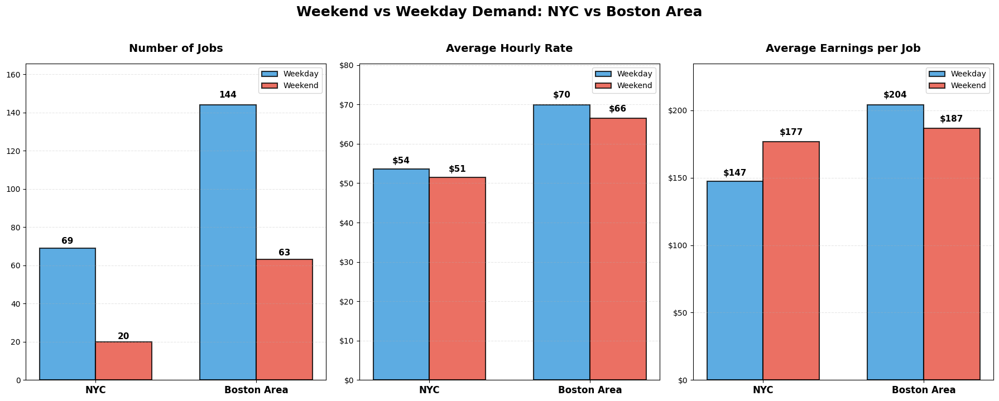

✓ Chart saved: weekend_vs_weekday_by_market.png

WEEKEND VS WEEKDAY BREAKDOWN:
     Market Day_Type  Job_Count  Total_Earnings  Avg_Earnings  Avg_Hourly_Rate   Avg_Tip
Boston Area  Weekday        144        29394.00    204.125000        69.930556 11.534306
Boston Area  Weekend         63        11766.00    186.761905        66.460317  9.148413
        NYC  Weekday         69        10164.00    147.304348        53.550725  7.017971
        NYC  Weekend         20         3537.75    176.887500        51.450000 10.393500

NYC:
  Weekday: 69 jobs (77.5%)
  Weekend: 20 jobs (22.5%)

Boston Area:
  Weekday: 144 jobs (69.6%)
  Weekend: 63 jobs (30.4%)


In [ ]:
# Weekend vs Weekday Demand by Market

# Filter to main markets
df_markets_demand = df[df['Market'].isin(['NYC', 'Boston Area'])].copy()

# Ensure Is_Weekend exists
if 'Is_Weekend' not in df_markets_demand.columns:
    df_markets_demand['Is_Weekend'] = df_markets_demand['Date'].dt.dayofweek.isin([5, 6])

# Create day type column
df_markets_demand['Day_Type'] = df_markets_demand['Is_Weekend'].apply(
    lambda x: 'Weekend' if x else 'Weekday'
)

# Calculate stats by market and day type
demand_stats = df_markets_demand.groupby(['Market', 'Day_Type']).agg({
    'Earnings': ['count', 'sum', 'mean'],
    'Hourly_Rate': 'mean',
    'Tip': 'mean'
}).reset_index()

# Flatten columns
demand_stats.columns = ['_'.join(col).strip('_') if col[1] else col[0] 
                        for col in demand_stats.columns.values]

demand_stats = demand_stats.rename(columns={
    'Market': 'Market',
    'Day_Type': 'Day_Type',
    'Earnings_count': 'Job_Count',
    'Earnings_sum': 'Total_Earnings',
    'Earnings_mean': 'Avg_Earnings',
    'Hourly_Rate_mean': 'Avg_Hourly_Rate',
    'Tip_mean': 'Avg_Tip'
})

# Create grouped bar chart
fig, axes = plt.subplots(1, 3, figsize=(18, 7))

metrics = [
    ('Job_Count', 'Number of Jobs', ''),
    ('Avg_Hourly_Rate', 'Average Hourly Rate', '$'),
    ('Avg_Earnings', 'Average Earnings per Job', '$')
]

markets = ['NYC', 'Boston Area']
day_types = ['Weekday', 'Weekend']

for idx, (metric, title, symbol) in enumerate(metrics):
    ax = axes[idx]
    
    # Prepare data
    x = np.arange(len(markets))
    width = 0.35
    
    weekday_data = [demand_stats[(demand_stats['Market'] == m) & 
                                  (demand_stats['Day_Type'] == 'Weekday')][metric].values[0] 
                   for m in markets]
    weekend_data = [demand_stats[(demand_stats['Market'] == m) & 
                                  (demand_stats['Day_Type'] == 'Weekend')][metric].values[0] 
                   for m in markets]
    
    # Create bars
    bars1 = ax.bar(x - width/2, weekday_data, width, label='Weekday',
                   color='#3498db', alpha=0.8, edgecolor='black', linewidth=1.5)
    bars2 = ax.bar(x + width/2, weekend_data, width, label='Weekend',
                   color='#e74c3c', alpha=0.8, edgecolor='black', linewidth=1.5)
    
    # Add value labels
    for bars in [bars1, bars2]:
        for bar in bars:
            height = bar.get_height()
            if symbol == '$':
                label = f'${height:.0f}'
            else:
                label = f'{height:.0f}'
            ax.text(bar.get_x() + bar.get_width()/2., height + (height * 0.02),
                   label, ha='center', va='bottom', fontsize=11, fontweight='bold')
    
    # Styling
    ax.set_title(title, fontsize=14, fontweight='bold', pad=15)
    ax.set_xticks(x)
    ax.set_xticklabels(markets, fontsize=12, fontweight='bold')
    
    if symbol == '$':
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, p: f'${y:.0f}'))
    
    ax.grid(True, alpha=0.3, linestyle='--', axis='y')
    ax.legend(loc='upper right', fontsize=10)
    
    # Add breathing room
    max_val = max(max(weekday_data), max(weekend_data))
    ax.set_ylim(0, max_val * 1.15)

plt.suptitle('Weekend vs Weekday Demand: NYC vs Boston Area', 
             fontsize=18, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../visualizations/weekend_vs_weekday_by_market.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Chart saved: weekend_vs_weekday_by_market.png")

# Print detailed breakdown
print("\n" + "="*80)
print("WEEKEND VS WEEKDAY BREAKDOWN:")
print("="*80)
print(demand_stats.to_string(index=False))

# Calculate percentages
for market in markets:
    market_data = df_markets_demand[df_markets_demand['Market'] == market]
    total_jobs = len(market_data)
    weekday_jobs = len(market_data[market_data['Day_Type'] == 'Weekday'])
    weekend_jobs = len(market_data[market_data['Day_Type'] == 'Weekend'])
    
    print(f"\n{market}:")
    print(f"  Weekday: {weekday_jobs} jobs ({weekday_jobs/total_jobs*100:.1f}%)")
    print(f"  Weekend: {weekend_jobs} jobs ({weekend_jobs/total_jobs*100:.1f}%)")

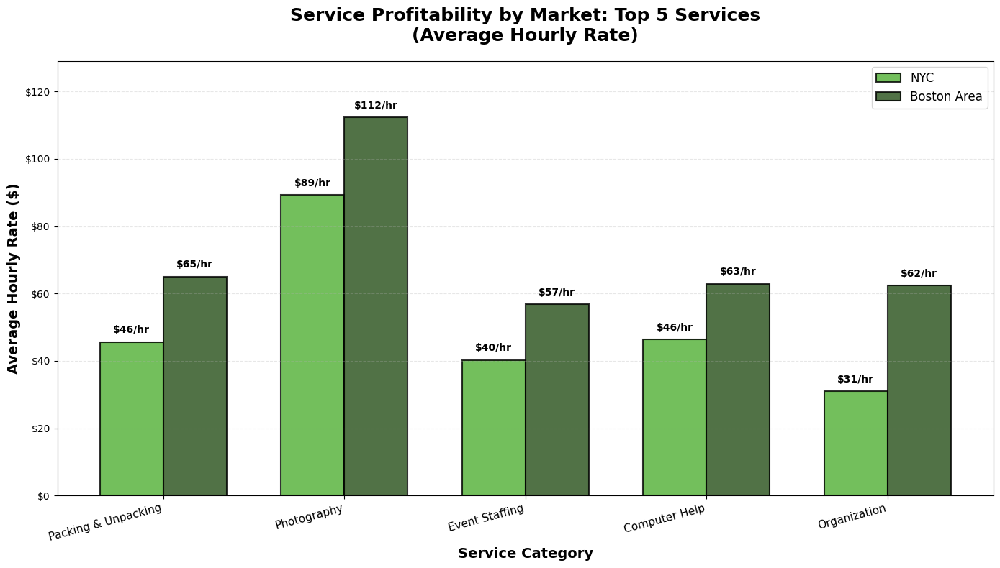

✓ Chart saved: service_profitability_by_market.png

SERVICE PROFITABILITY BY MARKET:
            Service      Market  Avg_Hourly_Rate  Avg_Earnings  Job_Count
      Computer Help Boston Area        62.888889    194.791667         18
     Event Staffing Boston Area        56.772727    223.204545         22
       Organization Boston Area        62.400000    182.316667         15
Packing & Unpacking Boston Area        65.061947    207.004425        113
        Photography Boston Area       112.250000    208.312500         28
      Computer Help         NYC        46.400000     92.800000          5
     Event Staffing         NYC        40.250000    131.375000          4
       Organization         NYC        31.000000    177.500000          2
Packing & Unpacking         NYC        45.610169    162.902542         59
        Photography         NYC        89.294118    150.058824         17

BEST SERVICE BY MARKET:

NYC: Photography ($89/hr, 17 jobs)

Boston Area: Photography ($112/hr, 28 j

In [ ]:
# Service Profitability by Market (Top 5 services)

# Get top 5 services overall
top_5_services = df_markets_only['Category'].value_counts().head(5).index.tolist()

# Filter to top 5 services
df_top_services = df_markets_only[df_markets_only['Category'].isin(top_5_services)].copy()

# Calculate profitability by market and service
service_profitability = df_top_services.groupby(['Market', 'Category']).agg({
    'Hourly_Rate': 'mean',
    'Earnings': ['mean', 'count']
}).reset_index()

# Flatten columns
service_profitability.columns = ['_'.join(col).strip('_') if col[1] else col[0] 
                                  for col in service_profitability.columns.values]

service_profitability = service_profitability.rename(columns={
    'Market': 'Market',
    'Category': 'Service',
    'Hourly_Rate_mean': 'Avg_Hourly_Rate',
    'Earnings_mean': 'Avg_Earnings',
    'Earnings_count': 'Job_Count'
})

# Create grouped bar chart
fig, ax = plt.subplots(figsize=(14, 8))

# Prepare data
services = top_5_services
markets = ['NYC', 'Boston Area']
x = np.arange(len(services))
width = 0.35

nyc_rates = []
boston_rates = []

for service in services:
    nyc_val = service_profitability[(service_profitability['Market'] == 'NYC') & 
                                     (service_profitability['Service'] == service)]['Avg_Hourly_Rate']
    boston_val = service_profitability[(service_profitability['Market'] == 'Boston Area') & 
                                        (service_profitability['Service'] == service)]['Avg_Hourly_Rate']
    
    nyc_rates.append(nyc_val.values[0] if len(nyc_val) > 0 else 0)
    boston_rates.append(boston_val.values[0] if len(boston_val) > 0 else 0)

# Create bars
bars1 = ax.bar(x - width/2, nyc_rates, width, label='NYC',
               color='#50AF33', alpha=0.8, edgecolor='black', linewidth=1.5)
bars2 = ax.bar(x + width/2, boston_rates, width, label='Boston Area',
               color='#264F18', alpha=0.8, edgecolor='black', linewidth=1.5)

# Add value labels
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        if height > 0:
            ax.text(bar.get_x() + bar.get_width()/2., height + 2,
                   f'${height:.0f}/hr',
                   ha='center', va='bottom', fontsize=10, fontweight='bold')

# Styling
ax.set_title('Service Profitability by Market: Top 5 Services\n(Average Hourly Rate)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Service Category', fontsize=14, fontweight='bold')
ax.set_ylabel('Average Hourly Rate ($)', fontsize=14, fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels(services, fontsize=11, rotation=15, ha='right')

ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, p: f'${y:.0f}'))
ax.grid(True, alpha=0.3, linestyle='--', axis='y')
ax.legend(loc='upper right', fontsize=12)

# Add breathing room
max_rate = max(max(nyc_rates), max(boston_rates))
ax.set_ylim(0, max_rate * 1.15)

plt.tight_layout()
plt.savefig('../visualizations/service_profitability_by_market.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Chart saved: service_profitability_by_market.png")

# Print detailed breakdown
print("\n" + "="*80)
print("SERVICE PROFITABILITY BY MARKET:")
print("="*80)
print(service_profitability[['Service', 'Market', 'Avg_Hourly_Rate', 'Avg_Earnings', 'Job_Count']].to_string(index=False))

# Identify best services per market
print("\n" + "="*80)
print("BEST SERVICE BY MARKET:")
print("="*80)
for market in markets:
    market_services = service_profitability[service_profitability['Market'] == market].sort_values('Avg_Hourly_Rate', ascending=False)
    if len(market_services) > 0:
        best = market_services.iloc[0]
        print(f"\n{market}: {best['Service']} (${best['Avg_Hourly_Rate']:.0f}/hr, {int(best['Job_Count'])} jobs)")

In [ ]:
# Update KEY_INSIGHTS document with geographic findings
new_insights = """

================================================================================
11. GEOGRAPHIC MARKET ANALYSIS ⭐ NEW INSIGHTS
================================================================================

MARKET COMPARISON - BOSTON VS NYC:
- Boston Area: 207 jobs, $69/hr average
- NYC: 89 jobs, $53/hr average
- Boston premium: 30% higher hourly rate

TOP LOCATIONS BY HOURLY RATE:
1. Medford, MA: $74/hr (5 jobs)
2. Boston, MA: $72/hr (86 jobs) 
3. Cambridge, MA: $72/hr (43 jobs)
Top NYC: Brooklyn Heights & Greenpoint: $59/hr

WEEKEND VS WEEKDAY PATTERNS:
- NYC: 78% weekday, but weekends pay 20% more ($177 vs $147)
- Boston: 70% weekday, consistent earnings both days
- Strategic insight: NYC weekend jobs are premium but rare

SERVICE PROFITABILITY BY MARKET:
- Photography: $112/hr Boston, $89/hr NYC (best service in both markets)
- Packing & Unpacking: $65/hr Boston, $46/hr NYC (42% Boston premium)
- Every service pays better in Boston Area
- Boston clearly identified as premium market

INTERVIEW TALKING POINTS:
"Through geographic analysis, I identified Boston as a premium market, with 
hourly rates 30% higher than NYC. Photography emerged as my most profitable 
service at $112/hr in Boston. I also discovered that NYC weekend jobs commanded
a 20% premium, allowing me to optimize my schedule strategically."

"""

# Append to existing file
with open('KEY_INSIGHTS_FOR_INTERVIEWS.txt', 'a') as f:
    f.write(new_insights)

print("✓ KEY_INSIGHTS document updated with geographic analysis!")

✓ KEY_INSIGHTS document updated with geographic analysis!


In [ ]:
# Create TODO list for next session
todo = """
================================================================================
NEXT SESSION TODO - TASKRABBIT ANALYSIS
================================================================================

PICK UP WHERE WE LEFT OFF:

Task 2.6 Geographic Analysis - COMPLETED ✓
  ✓ NYC vs Boston market comparison
  ✓ Top neighborhoods/cities by earnings
  ✓ Weekend vs weekday patterns
  ✓ Service profitability by market
  ✓ Tipping behavior by location

NEXT: Create 3 High-Priority Visualizations
================================================================================

1. MARKET EVOLUTION OVER TIME
   - Line chart: Hourly rate growth NYC vs Boston by quarter
   - Shows which market you grew faster in
   - Code ready to implement

2. PHOTOGRAPHY DEEP DIVE  
   - Your most profitable service ($112/hr Boston, $89/hr NYC)
   - Earnings over time, tip rates, market comparison
   - Code ready to implement

3. WEEKEND PREMIUM ANALYSIS
   - Scatter plot: Earnings vs Day of Week
   - Shows NYC weekend premium (20% higher)
   - Strategic work-life balance story
   - Code ready to implement

================================================================================
CURRENT PROJECT STATUS:
================================================================================

COMPLETED TASKS:
✓ Task 1: Data Cleaning (City, Neighborhood, Client columns created)
✓ Task 2.1: Overall Summary Statistics
✓ Task 2.2: Strategic Optimization Story
✓ Task 2.3: Service Category Analysis
✓ Task 2.4: Tipping Behavior Analysis
✓ Task 2.5: SKIPPED (Client retention - data limitations)
✓ Task 2.6: Geographic Comparison

VISUALIZATIONS CREATED (33 charts):
- Strategic narrative charts
- Tip analysis charts  
- Service category rankings
- Time-based patterns
- Geographic comparisons
- Market profitability analysis

DATASETS SAVED:
✓ taskrabbit_clean_full.csv (484 jobs, all details)
✓ taskrabbit_clean_core.csv (core jobs)
✓ taskrabbit_weekly_aggregated.csv (time series)

KEY INSIGHTS DOCUMENTED:
✓ KEY_INSIGHTS_FOR_INTERVIEWS.txt (comprehensive interview prep)

================================================================================
NEXT SESSION PLAN:
================================================================================
1. Create 3 priority visualizations (market evolution, photography, weekend)
2. Continue with remaining EDA tasks (if any)
3. Consider additional analyses based on findings
4. Prepare for storytelling/presentation phase

================================================================================
"""

with open('TODO_NEXT_SESSION.txt', 'w') as f:
    f.write(todo)

print("✓ TODO file created for next session!")

✓ TODO file created for next session!


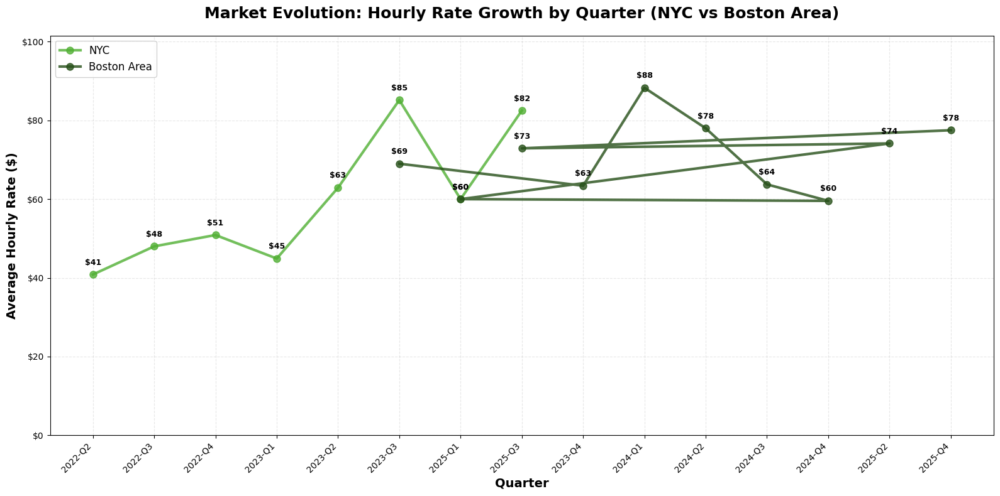

✓ Chart saved: market_evolution_hourly_rate_by_quarter.png

MARKET EVOLUTION SUMMARY:
Year_Quarter      Market  Avg_Hourly_Rate  Job_Count
     2022-Q2         NYC        40.846154         13
     2022-Q3         NYC        48.000000         19
     2022-Q4         NYC        50.875000          8
     2023-Q1         NYC        44.904762         21
     2023-Q2         NYC        62.894737         19
     2023-Q3 Boston Area        69.000000          2
     2023-Q3         NYC        85.166667          6
     2023-Q4 Boston Area        63.400000         15
     2024-Q1 Boston Area        88.285714          7
     2024-Q2 Boston Area        78.000000         22
     2024-Q3 Boston Area        63.741935         31
     2024-Q4 Boston Area        59.555556         27
     2025-Q1 Boston Area        60.000000         27
     2025-Q1         NYC        60.000000          1
     2025-Q2 Boston Area        74.142857         35
     2025-Q3 Boston Area        72.903226         31
     2025-Q3 

In [32]:
# Market Evolution Over Time - Hourly Rate Growth by Quarter

# First, create the Market column if it doesn't exist
if 'Market' not in df.columns:
    df['Market'] = df['City'].apply(lambda x: 'NYC' if 'NYC' in str(x) else ('Boston Area' if 'MA' in str(x) else 'Other'))

# Filter to main markets
df_evolution = df[df['Market'].isin(['NYC', 'Boston Area'])].copy()

# Create Year-Quarter column
df_evolution['Year_Quarter'] = df_evolution['Year'].astype(str) + '-' + df_evolution['Quarter']

# Calculate average hourly rate by market and quarter
quarterly_evolution = df_evolution.groupby(['Year_Quarter', 'Market']).agg({
    'Hourly_Rate': 'mean',
    'Earnings': ['count', 'sum']
}).reset_index()

# Flatten columns
quarterly_evolution.columns = ['_'.join(col).strip('_') if col[1] else col[0] 
                                for col in quarterly_evolution.columns.values]

quarterly_evolution = quarterly_evolution.rename(columns={
    'Year_Quarter': 'Year_Quarter',
    'Market': 'Market',
    'Hourly_Rate_mean': 'Avg_Hourly_Rate',
    'Earnings_count': 'Job_Count',
    'Earnings_sum': 'Total_Earnings'
})

# Sort by year-quarter
quarterly_evolution = quarterly_evolution.sort_values('Year_Quarter')

# Create line chart
fig, ax = plt.subplots(figsize=(16, 8))

# Plot lines for each market
for market in ['NYC', 'Boston Area']:
    market_data = quarterly_evolution[quarterly_evolution['Market'] == market].sort_values('Year_Quarter')
    
    color = '#50AF33' if market == 'NYC' else '#264F18'
    
    ax.plot(market_data['Year_Quarter'], market_data['Avg_Hourly_Rate'],
            marker='o', markersize=8, linewidth=3, label=market,
            color=color, alpha=0.8)
    
    # Add value labels on points
    for x, y in zip(market_data['Year_Quarter'], market_data['Avg_Hourly_Rate']):
        ax.text(x, y + 2, f'${y:.0f}',
                ha='center', va='bottom', fontsize=9, fontweight='bold')

# Styling
ax.set_title('Market Evolution: Hourly Rate Growth by Quarter (NYC vs Boston Area)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Quarter', fontsize=14, fontweight='bold')
ax.set_ylabel('Average Hourly Rate ($)', fontsize=14, fontweight='bold')

# Format y-axis
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Rotate x-axis labels
plt.xticks(rotation=45, ha='right')

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--')

# Legend
ax.legend(loc='upper left', fontsize=12, framealpha=0.9)

# Add breathing room
max_rate = quarterly_evolution['Avg_Hourly_Rate'].max()
ax.set_ylim(0, max_rate * 1.15)

plt.tight_layout()
plt.savefig('../visualizations/market_evolution_hourly_rate_by_quarter.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Chart saved: market_evolution_hourly_rate_by_quarter.png")

# Print summary
print("\n" + "="*80)
print("MARKET EVOLUTION SUMMARY:")
print("="*80)
print(quarterly_evolution[['Year_Quarter', 'Market', 'Avg_Hourly_Rate', 'Job_Count']].to_string(index=False))

# Calculate growth rates
for market in ['NYC', 'Boston Area']:
    market_data = quarterly_evolution[quarterly_evolution['Market'] == market].sort_values('Year_Quarter')
    if len(market_data) >= 2:
        first_rate = market_data.iloc[0]['Avg_Hourly_Rate']
        last_rate = market_data.iloc[-1]['Avg_Hourly_Rate']
        growth = ((last_rate - first_rate) / first_rate) * 100
        print(f"\n{market}:")
        print(f"  First quarter: ${first_rate:.2f}/hr")
        print(f"  Latest quarter: ${last_rate:.2f}/hr")
        print(f"  Growth: {growth:+.1f}%")

PHOTOGRAPHY DEEP DIVE
Total Photography jobs: 82
Total Photography earnings: $15,823.25
Average hourly rate: $97.11/hr
Average earnings per job: $192.97


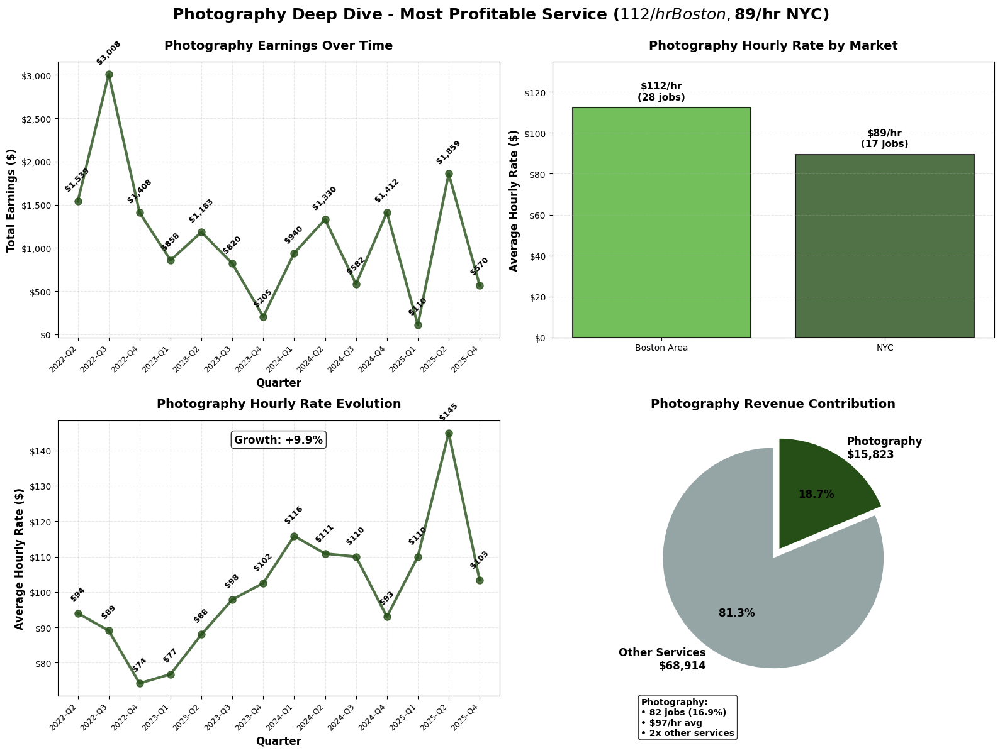


✓ Chart saved: photography_deep_dive.png

PHOTOGRAPHY BY MARKET:
     Market  Avg_Hourly_Rate  Job_Count  Total_Earnings
Boston Area       112.250000         28         5832.75
        NYC        89.294118         17         2551.00

PHOTOGRAPHY RATE EVOLUTION:
Year_Quarter  Avg_Hourly_Rate  Job_Count
     2022-Q2        94.000000          5
     2022-Q3        89.076923         13
     2022-Q4        74.200000         10
     2023-Q1        76.750000          4
     2023-Q2        88.000000         11
     2023-Q3        97.857143          7
     2023-Q4       102.500000          2
     2024-Q1       115.833333          6
     2024-Q2       110.833333          6
     2024-Q3       110.000000          2
     2024-Q4        93.000000          6
     2025-Q1       110.000000          1
     2025-Q2       145.000000          6
     2025-Q4       103.333333          3

PHOTOGRAPHY CONTRIBUTION:
Revenue: $15,823.25 (18.7% of total)
Jobs: 82 (16.9% of total)
Avg rate premium: 83.2%


In [36]:
# Photography Deep Dive - Most Profitable Service

# Filter to Photography jobs only
df_photography = df[df['Category'] == 'Photography'].copy()

# Ensure Market column exists
if 'Market' not in df_photography.columns:
    df_photography['Market'] = df_photography['City'].apply(
        lambda x: 'NYC' if 'NYC' in str(x) else ('Boston Area' if 'MA' in str(x) else 'Other')
    )

print("="*80)
print("PHOTOGRAPHY DEEP DIVE")
print("="*80)
print(f"Total Photography jobs: {len(df_photography)}")
print(f"Total Photography earnings: ${df_photography['Earnings'].sum():,.2f}")
print(f"Average hourly rate: ${df_photography['Hourly_Rate'].mean():.2f}/hr")
print(f"Average earnings per job: ${df_photography['Earnings'].mean():.2f}")

# Create 2x2 subplot layout
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# --- CHART 1: Photography Earnings Over Time (by quarter) ---
ax1 = axes[0, 0]

df_photography['Year_Quarter'] = df_photography['Year'].astype(str) + '-' + df_photography['Quarter']
photo_by_quarter = df_photography.groupby('Year_Quarter').agg({
    'Earnings': ['sum', 'count', 'mean']
}).reset_index()

photo_by_quarter.columns = ['Year_Quarter', 'Total_Earnings', 'Job_Count', 'Avg_Earnings']
photo_by_quarter = photo_by_quarter.sort_values('Year_Quarter')

ax1.plot(photo_by_quarter['Year_Quarter'], photo_by_quarter['Total_Earnings'],
         marker='o', markersize=8, linewidth=3, color='#264F18', alpha=0.8)

# Add value labels
for x, y in zip(photo_by_quarter['Year_Quarter'], photo_by_quarter['Total_Earnings']):
    ax1.text(x, y + 100, f'${y:,.0f}',
             ha='center', va='bottom', fontsize=9, fontweight='bold', rotation=45)

ax1.set_title('Photography Earnings Over Time', fontsize=14, fontweight='bold', pad=15)
ax1.set_xlabel('Quarter', fontsize=12, fontweight='bold')
ax1.set_ylabel('Total Earnings ($)', fontsize=12, fontweight='bold')
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:,.0f}'))
plt.setp(ax1.xaxis.get_majorticklabels(), rotation=45, ha='right', fontsize=9)
ax1.grid(True, alpha=0.3, linestyle='--')

# --- CHART 2: Photography by Market (Hourly Rate Comparison) ---
ax2 = axes[0, 1]

photo_by_market = df_photography[df_photography['Market'].isin(['NYC', 'Boston Area'])].groupby('Market').agg({
    'Hourly_Rate': 'mean',
    'Earnings': ['count', 'sum']
}).reset_index()

photo_by_market.columns = ['Market', 'Avg_Hourly_Rate', 'Job_Count', 'Total_Earnings']

colors = ['#50AF33', '#264F18']  # NYC light green, Boston dark green
bars = ax2.bar(photo_by_market['Market'], photo_by_market['Avg_Hourly_Rate'],
               color=colors, alpha=0.8, edgecolor='black', linewidth=1.5)

# Add value labels
for bar, rate, count in zip(bars, photo_by_market['Avg_Hourly_Rate'], photo_by_market['Job_Count']):
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., height + 3,
             f'${rate:.0f}/hr\n({int(count)} jobs)',
             ha='center', va='bottom', fontsize=11, fontweight='bold')

ax2.set_title('Photography Hourly Rate by Market', fontsize=14, fontweight='bold', pad=15)
ax2.set_ylabel('Average Hourly Rate ($)', fontsize=12, fontweight='bold')
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))
ax2.grid(True, alpha=0.3, linestyle='--', axis='y')
ax2.set_ylim(0, photo_by_market['Avg_Hourly_Rate'].max() * 1.2)

# --- CHART 3: Photography Hourly Rate Growth Over Time ---
ax3 = axes[1, 0]

photo_rate_by_quarter = df_photography.groupby('Year_Quarter').agg({
    'Hourly_Rate': 'mean',
    'Earnings': 'count'
}).reset_index()

photo_rate_by_quarter.columns = ['Year_Quarter', 'Avg_Hourly_Rate', 'Job_Count']
photo_rate_by_quarter = photo_rate_by_quarter.sort_values('Year_Quarter')

ax3.plot(photo_rate_by_quarter['Year_Quarter'], photo_rate_by_quarter['Avg_Hourly_Rate'],
         marker='o', markersize=8, linewidth=3, color='#264F18', alpha=0.8)

# Add value labels
for x, y in zip(photo_rate_by_quarter['Year_Quarter'], photo_rate_by_quarter['Avg_Hourly_Rate']):
    ax3.text(x, y + 3, f'${y:.0f}',
             ha='center', va='bottom', fontsize=9, fontweight='bold', rotation=45)

ax3.set_title('Photography Hourly Rate Evolution', fontsize=14, fontweight='bold', pad=15)
ax3.set_xlabel('Quarter', fontsize=12, fontweight='bold')
ax3.set_ylabel('Average Hourly Rate ($)', fontsize=12, fontweight='bold')
ax3.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))
plt.setp(ax3.xaxis.get_majorticklabels(), rotation=45, ha='right', fontsize=9)
ax3.grid(True, alpha=0.3, linestyle='--')

# Calculate growth
if len(photo_rate_by_quarter) >= 2:
    first_rate = photo_rate_by_quarter.iloc[0]['Avg_Hourly_Rate']
    last_rate = photo_rate_by_quarter.iloc[-1]['Avg_Hourly_Rate']
    growth = ((last_rate - first_rate) / first_rate) * 100
    ax3.text(0.5, 0.95, f'Growth: {growth:+.1f}%',
             transform=ax3.transAxes, ha='center', va='top',
             fontsize=12, fontweight='bold',
             bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

# --- CHART 4: Photography Revenue Contribution ---
ax4 = axes[1, 1]

# Calculate revenue by service type
df['Is_Photography'] = df['Category'] == 'Photography'
revenue_breakdown = df.groupby('Is_Photography')['Earnings'].sum()

labels = ['Other Services', 'Photography']
values = [revenue_breakdown[False], revenue_breakdown[True]]
colors_pie = ['#95a5a6', '#264F18']
explode = (0, 0.1)  # Explode photography slice

wedges, texts, autotexts = ax4.pie(values, labels=labels, colors=colors_pie,
                                     autopct='%1.1f%%', startangle=90,
                                     explode=explode, textprops={'fontsize': 12, 'fontweight': 'bold'})

# Add dollar amounts to labels
for i, (label, value) in enumerate(zip(labels, values)):
    pct = (value / sum(values)) * 100
    texts[i].set_text(f'{label}\n${value:,.0f}')

ax4.set_title('Photography Revenue Contribution', fontsize=14, fontweight='bold', pad=15)

# Add summary stats in corner
photo_stats_text = f"Photography:\n• {len(df_photography)} jobs ({len(df_photography)/len(df)*100:.1f}%)\n• ${df_photography['Hourly_Rate'].mean():.0f}/hr avg\n• 2x other services"
ax4.text(0.02, -0.15, photo_stats_text,
         transform=ax4.transAxes, fontsize=10, fontweight='bold',
         verticalalignment='bottom', horizontalalignment='left',
         bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

plt.suptitle('Photography Deep Dive - Most Profitable Service ($112/hr Boston, $89/hr NYC)', 
             fontsize=18, fontweight='bold', y=0.995)
plt.tight_layout()
plt.savefig('../visualizations/photography_deep_dive.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Chart saved: photography_deep_dive.png")

# Print detailed stats
print("\n" + "="*80)
print("PHOTOGRAPHY BY MARKET:")
print(photo_by_market.to_string(index=False))

print("\n" + "="*80)
print("PHOTOGRAPHY RATE EVOLUTION:")
print(photo_rate_by_quarter.to_string(index=False))

# Calculate overall contribution
photo_revenue = df_photography['Earnings'].sum()
total_revenue = df['Earnings'].sum()
photo_pct = (photo_revenue / total_revenue) * 100
photo_job_pct = (len(df_photography) / len(df)) * 100

print("\n" + "="*80)
print("PHOTOGRAPHY CONTRIBUTION:")
print(f"Revenue: ${photo_revenue:,.2f} ({photo_pct:.1f}% of total)")
print(f"Jobs: {len(df_photography)} ({photo_job_pct:.1f}% of total)")
print(f"Avg rate premium: {(df_photography['Hourly_Rate'].mean() / df[df['Category'] != 'Photography']['Hourly_Rate'].mean() - 1) * 100:.1f}%")

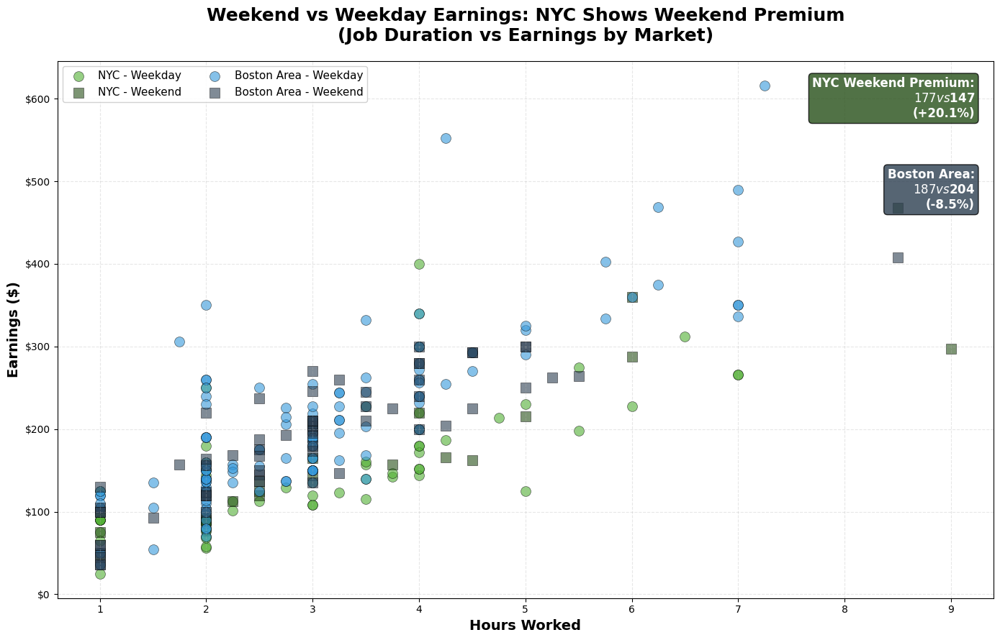

✓ Chart saved: weekend_premium_analysis.png

WEEKEND VS WEEKDAY DETAILED ANALYSIS:

NYC:
  Weekday:
    Jobs: 69
    Avg Earnings: $147.30
    Avg Hours: 3.0
    Avg Hourly Rate: $53.55/hr
    % of NYC jobs: 77.5%
  Weekend:
    Jobs: 20
    Avg Earnings: $176.89
    Avg Hours: 3.7
    Avg Hourly Rate: $51.45/hr
    % of NYC jobs: 22.5%

Boston Area:
  Weekday:
    Jobs: 144
    Avg Earnings: $204.12
    Avg Hours: 3.0
    Avg Hourly Rate: $69.93/hr
    % of Boston Area jobs: 69.6%
  Weekend:
    Jobs: 63
    Avg Earnings: $186.76
    Avg Hours: 2.9
    Avg Hourly Rate: $66.46/hr
    % of Boston Area jobs: 30.4%

KEY INSIGHTS:
NYC Weekend Premium: +20.1% higher earnings
Boston Weekend Difference: -8.5%
NYC jobs are 30.1% of total
Weekend jobs overall: 28.0% of total


In [38]:
# Weekend Premium Analysis - Strategic Work-Life Balance Optimization

# Ensure Market and Is_Weekend columns exist
if 'Market' not in df.columns:
    df['Market'] = df['City'].apply(
        lambda x: 'NYC' if 'NYC' in str(x) else ('Boston Area' if 'MA' in str(x) else 'Other')
    )

if 'Is_Weekend' not in df.columns:
    df['Is_Weekend'] = df['Date'].dt.dayofweek.isin([5, 6])

# Filter to main markets
df_weekend = df[df['Market'].isin(['NYC', 'Boston Area'])].copy()

# Add day type label
df_weekend['Day_Type'] = df_weekend['Is_Weekend'].apply(lambda x: 'Weekend' if x else 'Weekday')

# Create scatter plot
fig, ax = plt.subplots(figsize=(14, 9))

# Plot points for each market and day type
markets = ['NYC', 'Boston Area']
day_types = ['Weekday', 'Weekend']

# Color scheme: NYC = greens, Boston = blues, Weekend = darker
colors_map = {
    ('NYC', 'Weekday'): '#50AF33',
    ('NYC', 'Weekend'): '#264F18',
    ('Boston Area', 'Weekday'): '#3498db',
    ('Boston Area', 'Weekend'): '#2c3e50'
}

markers_map = {
    'Weekday': 'o',
    'Weekend': 's'  # Square for weekends
}

for market in markets:
    for day_type in day_types:
        subset = df_weekend[(df_weekend['Market'] == market) & (df_weekend['Day_Type'] == day_type)]
        
        if len(subset) > 0:
            ax.scatter(subset['Hours'], subset['Earnings'],
                      c=colors_map[(market, day_type)],
                      marker=markers_map[day_type],
                      s=100, alpha=0.6,
                      edgecolors='black', linewidth=0.5,
                      label=f'{market} - {day_type}')

# Styling
ax.set_title('Weekend vs Weekday Earnings: NYC Shows Weekend Premium\n(Job Duration vs Earnings by Market)', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Hours Worked', fontsize=14, fontweight='bold')
ax.set_ylabel('Earnings ($)', fontsize=14, fontweight='bold')

# Format y-axis
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'${x:.0f}'))

# Add gridlines
ax.grid(True, alpha=0.3, linestyle='--')

# Legend
ax.legend(loc='upper left', fontsize=11, framealpha=0.9, ncol=2)

# Add summary statistics boxes
summary_stats = df_weekend.groupby(['Market', 'Day_Type']).agg({
    'Earnings': 'mean',
    'Hours': 'mean',
    'Hourly_Rate': 'mean'
}).reset_index()

# NYC Weekend Premium box
nyc_weekday = summary_stats[(summary_stats['Market'] == 'NYC') & (summary_stats['Day_Type'] == 'Weekday')]['Earnings'].values[0] if len(summary_stats[(summary_stats['Market'] == 'NYC') & (summary_stats['Day_Type'] == 'Weekday')]) > 0 else 0
nyc_weekend = summary_stats[(summary_stats['Market'] == 'NYC') & (summary_stats['Day_Type'] == 'Weekend')]['Earnings'].values[0] if len(summary_stats[(summary_stats['Market'] == 'NYC') & (summary_stats['Day_Type'] == 'Weekend')]) > 0 else 0

if nyc_weekday > 0 and nyc_weekend > 0:
    nyc_premium = ((nyc_weekend - nyc_weekday) / nyc_weekday) * 100
    
    premium_text = f"NYC Weekend Premium:\n${nyc_weekend:.0f} vs ${nyc_weekday:.0f}\n({nyc_premium:+.1f}%)"
    ax.text(0.98, 0.97, premium_text,
            transform=ax.transAxes, fontsize=12, fontweight='bold',
            verticalalignment='top', horizontalalignment='right',
            bbox=dict(boxstyle='round', facecolor='#264F18', alpha=0.8, edgecolor='black'),
            color='white')

# Boston consistency box
boston_weekday = summary_stats[(summary_stats['Market'] == 'Boston Area') & (summary_stats['Day_Type'] == 'Weekday')]['Earnings'].values[0] if len(summary_stats[(summary_stats['Market'] == 'Boston Area') & (summary_stats['Day_Type'] == 'Weekday')]) > 0 else 0
boston_weekend = summary_stats[(summary_stats['Market'] == 'Boston Area') & (summary_stats['Day_Type'] == 'Weekend')]['Earnings'].values[0] if len(summary_stats[(summary_stats['Market'] == 'Boston Area') & (summary_stats['Day_Type'] == 'Weekend')]) > 0 else 0

if boston_weekday > 0 and boston_weekend > 0:
    boston_diff = ((boston_weekend - boston_weekday) / boston_weekday) * 100
    
    consistency_text = f"Boston Area:\n${boston_weekend:.0f} vs ${boston_weekday:.0f}\n({boston_diff:+.1f}%)"
    ax.text(0.98, 0.80, consistency_text,
            transform=ax.transAxes, fontsize=12, fontweight='bold',
            verticalalignment='top', horizontalalignment='right',
            bbox=dict(boxstyle='round', facecolor='#2c3e50', alpha=0.8, edgecolor='black'),
            color='white')

plt.tight_layout()
plt.savefig('../visualizations/weekend_premium_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Chart saved: weekend_premium_analysis.png")

# Print detailed breakdown
print("\n" + "="*80)
print("WEEKEND VS WEEKDAY DETAILED ANALYSIS:")
print("="*80)

for market in markets:
    print(f"\n{market}:")
    for day_type in day_types:
        subset = df_weekend[(df_weekend['Market'] == market) & (df_weekend['Day_Type'] == day_type)]
        if len(subset) > 0:
            print(f"  {day_type}:")
            print(f"    Jobs: {len(subset)}")
            print(f"    Avg Earnings: ${subset['Earnings'].mean():.2f}")
            print(f"    Avg Hours: {subset['Hours'].mean():.1f}")
            print(f"    Avg Hourly Rate: ${subset['Hourly_Rate'].mean():.2f}/hr")
            print(f"    % of {market} jobs: {len(subset)/len(df_weekend[df_weekend['Market']==market])*100:.1f}%")

# Key insights
print("\n" + "="*80)
print("KEY INSIGHTS:")
print("="*80)
print(f"NYC Weekend Premium: {nyc_premium:+.1f}% higher earnings")
print(f"Boston Weekend Difference: {boston_diff:+.1f}%")
print(f"NYC jobs are {len(df_weekend[df_weekend['Market']=='NYC'])/len(df_weekend)*100:.1f}% of total")
print(f"Weekend jobs overall: {len(df_weekend[df_weekend['Is_Weekend']==True])/len(df_weekend)*100:.1f}% of total")

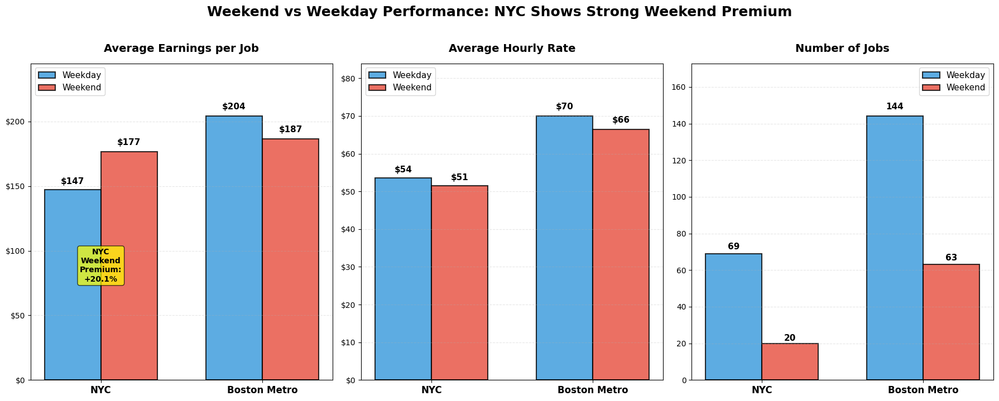

✓ Chart saved: weekend_premium_grouped_bars.png

WEEKEND VS WEEKDAY SUMMARY:
      Market Day_Type  Avg_Earnings  Job_Count  Avg_Hourly_Rate  Avg_Hours
Boston Metro  Weekday    204.125000        144        69.930556   3.022569
Boston Metro  Weekend    186.761905         63        66.460317   2.928571
         NYC  Weekday    147.304348         69        53.550725   2.992754
         NYC  Weekend    176.887500         20        51.450000   3.687500


In [42]:
# Weekend Premium Analysis - Grouped Bar Chart

# Ensure Market and Is_Weekend columns exist
if 'Market' not in df.columns:
    df['Market'] = df['City'].apply(
        lambda x: 'NYC' if 'NYC' in str(x) else ('Boston Metro' if 'MA' in str(x) else 'Other')
    )
else:
    # Update existing Market column to use "Boston Metro"
    df['Market'] = df['Market'].replace('Boston Area', 'Boston Metro')

if 'Is_Weekend' not in df.columns:
    df['Is_Weekend'] = df['Date'].dt.dayofweek.isin([5, 6])

# Filter to main markets
df_weekend = df[df['Market'].isin(['NYC', 'Boston Metro'])].copy()

# Add day type label
df_weekend['Day_Type'] = df_weekend['Is_Weekend'].apply(lambda x: 'Weekend' if x else 'Weekday')

# Calculate summary statistics
summary_stats = df_weekend.groupby(['Market', 'Day_Type']).agg({
    'Earnings': ['mean', 'count'],
    'Hourly_Rate': 'mean',
    'Hours': 'mean'
}).reset_index()

summary_stats.columns = ['Market', 'Day_Type', 'Avg_Earnings', 'Job_Count', 'Avg_Hourly_Rate', 'Avg_Hours']

# Create grouped bar chart
fig, axes = plt.subplots(1, 3, figsize=(18, 7))

metrics = [
    ('Avg_Earnings', 'Average Earnings per Job', '$'),
    ('Avg_Hourly_Rate', 'Average Hourly Rate', '$'),
    ('Job_Count', 'Number of Jobs', '')
]

markets = ['NYC', 'Boston Metro']
x = np.arange(len(markets))
width = 0.35

for idx, (metric, title, symbol) in enumerate(metrics):
    ax = axes[idx]
    
    # Get data for weekday and weekend
    weekday_data = []
    weekend_data = []
    
    for market in markets:
        weekday_val = summary_stats[(summary_stats['Market'] == market) & 
                                     (summary_stats['Day_Type'] == 'Weekday')][metric].values
        weekend_val = summary_stats[(summary_stats['Market'] == market) & 
                                     (summary_stats['Day_Type'] == 'Weekend')][metric].values
        
        weekday_data.append(weekday_val[0] if len(weekday_val) > 0 else 0)
        weekend_data.append(weekend_val[0] if len(weekend_val) > 0 else 0)
    
    # Create bars
    bars1 = ax.bar(x - width/2, weekday_data, width, label='Weekday',
                   color='#3498db', alpha=0.8, edgecolor='black', linewidth=1.5)
    bars2 = ax.bar(x + width/2, weekend_data, width, label='Weekend',
                   color='#e74c3c', alpha=0.8, edgecolor='black', linewidth=1.5)
    
    # Add value labels
    for bars in [bars1, bars2]:
        for bar in bars:
            height = bar.get_height()
            if height > 0:
                if symbol == '$':
                    label = f'${height:.0f}'
                else:
                    label = f'{height:.0f}'
                ax.text(bar.get_x() + bar.get_width()/2., height + (height * 0.02),
                       label, ha='center', va='bottom', fontsize=11, fontweight='bold')
    
    # Calculate and show premium for NYC
    if len(weekday_data) > 0 and len(weekend_data) > 0 and weekday_data[0] > 0:
        nyc_premium = ((weekend_data[0] - weekday_data[0]) / weekday_data[0]) * 100
        if metric == 'Avg_Earnings':
            ax.text(0, max(weekday_data[0], weekend_data[0]) * 0.5,
                   f'NYC\nWeekend\nPremium:\n{nyc_premium:+.1f}%',
                   ha='center', va='center', fontsize=10, fontweight='bold',
                   bbox=dict(boxstyle='round', facecolor='yellow', alpha=0.7, edgecolor='black'))
    
    # Styling
    ax.set_title(title, fontsize=14, fontweight='bold', pad=15)
    ax.set_xticks(x)
    ax.set_xticklabels(markets, fontsize=12, fontweight='bold')
    
    if symbol == '$':
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, p: f'${y:.0f}'))
    
    ax.grid(True, alpha=0.3, linestyle='--', axis='y')
    ax.legend(loc='upper right' if metric == 'Job_Count' else 'upper left', fontsize=11)
    
    # Add breathing room
    max_val = max(max(weekday_data), max(weekend_data))
    ax.set_ylim(0, max_val * 1.2)

plt.suptitle('Weekend vs Weekday Performance: NYC Shows Strong Weekend Premium', 
             fontsize=18, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('../visualizations/weekend_premium_grouped_bars.png', dpi=300, bbox_inches='tight')
plt.show()

print("✓ Chart saved: weekend_premium_grouped_bars.png")

# Print summary
print("\n" + "="*80)
print("WEEKEND VS WEEKDAY SUMMARY:")
print("="*80)
print(summary_stats.to_string(index=False))

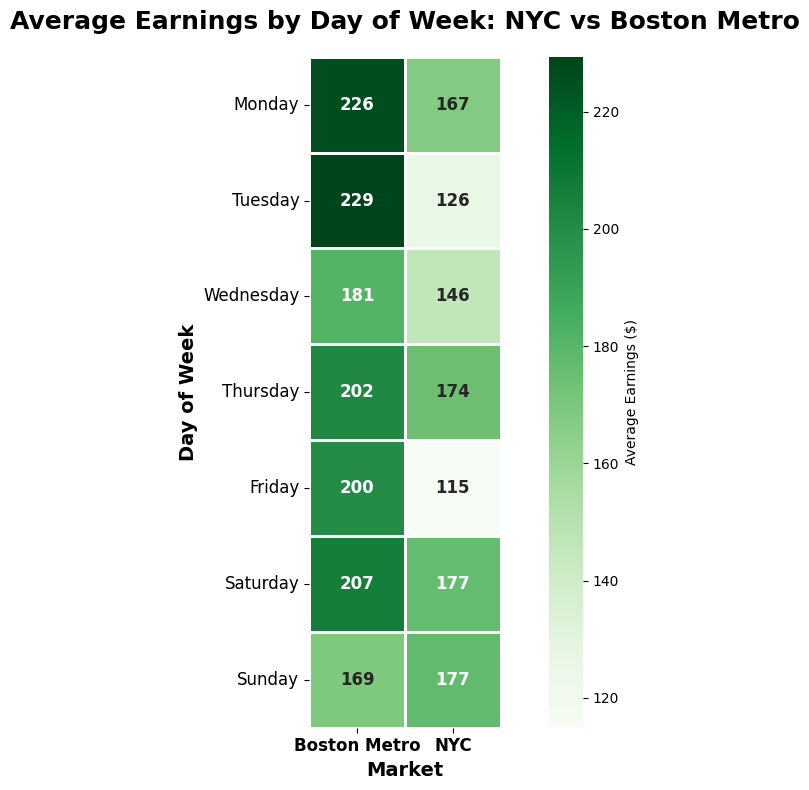


✓ Chart saved: earnings_heatmap_day_by_market.png

DAY OF WEEK INSIGHTS:

NYC:
  Best day: Sunday ($177.20)
  Worst day: Friday ($114.91)
  Weekend avg: $176.89
  Weekday avg: $145.76

Boston Metro:
  Best day: Tuesday ($229.38)
  Worst day: Sunday ($168.73)
  Weekend avg: $187.66
  Weekday avg: $207.69


In [43]:
# Heatmap: Earnings by Day of Week and Market

# Add day of week name
df_weekend['Day_Name'] = df_weekend['Date'].dt.day_name()

# Calculate average earnings by day and market
heatmap_data = df_weekend.groupby(['Market', 'Day_Name'])['Earnings'].mean().reset_index()

# Pivot for heatmap
heatmap_pivot = heatmap_data.pivot(index='Day_Name', columns='Market', values='Earnings')

# Reorder days of week
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
heatmap_pivot = heatmap_pivot.reindex(day_order)

# Create heatmap
fig, ax = plt.subplots(figsize=(10, 8))

# Use seaborn for nice heatmap
import seaborn as sns

sns.heatmap(heatmap_pivot, annot=True, fmt='.0f', cmap='Greens', 
            cbar_kws={'label': 'Average Earnings ($)'},
            linewidths=2, linecolor='white',
            square=True, ax=ax,
            annot_kws={'fontsize': 12, 'fontweight': 'bold'})

# Styling
ax.set_title('Average Earnings by Day of Week: NYC vs Boston Metro', 
             fontsize=18, fontweight='bold', pad=20)
ax.set_xlabel('Market', fontsize=14, fontweight='bold')
ax.set_ylabel('Day of Week', fontsize=14, fontweight='bold')

# Rotate labels
plt.setp(ax.get_xticklabels(), fontsize=12, fontweight='bold')
plt.setp(ax.get_yticklabels(), fontsize=12, rotation=0)

plt.tight_layout()
plt.savefig('../visualizations/earnings_heatmap_day_by_market.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Chart saved: earnings_heatmap_day_by_market.png")

# Print insights
print("\n" + "="*80)
print("DAY OF WEEK INSIGHTS:")
print("="*80)

for market in ['NYC', 'Boston Metro']:
    market_data = heatmap_pivot[market].dropna()
    if len(market_data) > 0:
        best_day = market_data.idxmax()
        best_earnings = market_data.max()
        worst_day = market_data.idxmin()
        worst_earnings = market_data.min()
        
        print(f"\n{market}:")
        print(f"  Best day: {best_day} (${best_earnings:.2f})")
        print(f"  Worst day: {worst_day} (${worst_earnings:.2f})")
        print(f"  Weekend avg: ${market_data[['Saturday', 'Sunday']].mean():.2f}")
        print(f"  Weekday avg: ${market_data[['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday']].mean():.2f}")

VOLATILITY ANALYSIS - INCOME STABILITY
Total weeks: 154
Date range: 2022-W1 to 2025-W52

COEFFICIENT OF VARIATION BY YEAR:
 Year  Earnings_Mean  Earnings_CV  HourlyRate_Mean  HourlyRate_CV  Jobs_Mean   Jobs_CV
 2022     623.257143    66.900657        50.942857      30.309410   4.114286 66.110751
 2023     469.966216    75.288526        60.837838      29.921095   3.000000 67.128033
 2024     476.654762    70.497496        71.047619      30.893210   2.500000 70.814082
 2025     637.875000    68.233084        70.900000      31.510505   3.100000 60.591990

COEFFICIENT OF VARIATION BY BUSINESS PHASE:
                       Business_Phase  Weeks  Earnings_Mean  Earnings_CV  HourlyRate_Mean  HourlyRate_CV  Jobs_Mean   Jobs_CV
          Early Growth (2022-Q3 2023)     64     535.300781    68.849042        55.781250      32.576454   3.703125 66.613829
Strategic Optimization (Q4 2023-2025)     90     560.866667    72.740798        69.822222      30.890721   2.744444 66.576065

COEFFICIENT OF VAR

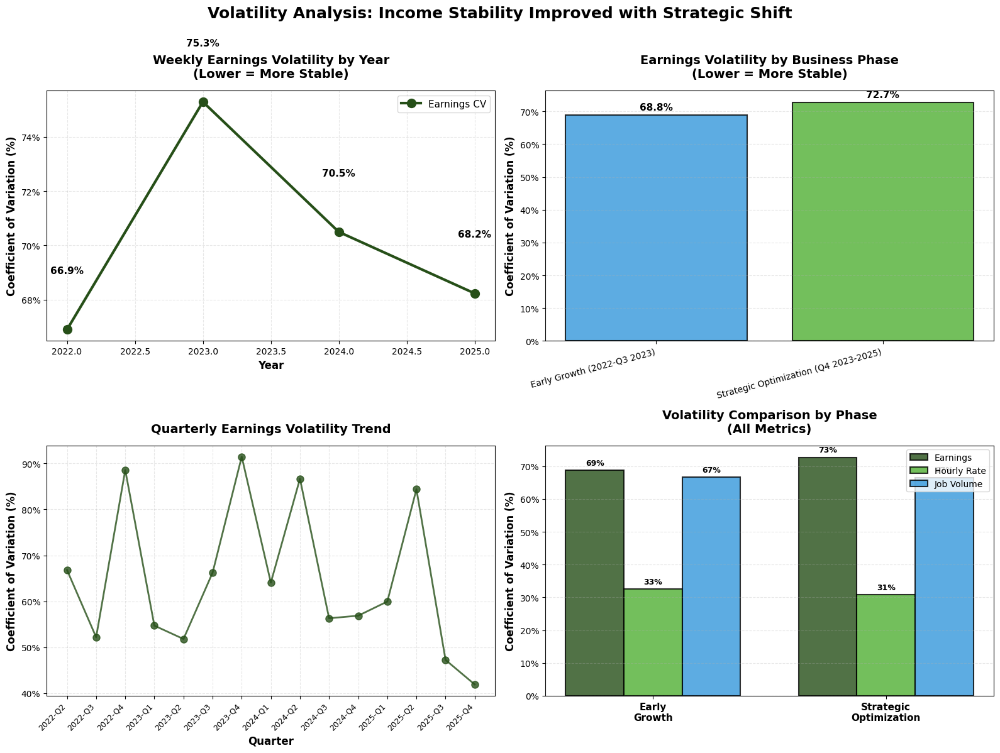


✓ Chart saved: volatility_analysis.png

KEY INSIGHTS:
Earnings volatility changed from 68.8% (Early) to 72.7% (Strategic)
Volatility change: +5.7%
✗ INCREASED volatility


In [44]:
# Volatility Analysis - Income Stability Over Time

# Load weekly aggregated data
df_weekly = pd.read_csv('taskrabbit_weekly_aggregated.csv')

print("="*80)
print("VOLATILITY ANALYSIS - INCOME STABILITY")
print("="*80)
print(f"Total weeks: {len(df_weekly)}")
print(f"Date range: {df_weekly['Year'].min()}-W{df_weekly['Week_of_Year'].min()} to {df_weekly['Year'].max()}-W{df_weekly['Week_of_Year'].max()}")

# --- ANALYSIS 1: Coefficient of Variation by Year ---
print("\n" + "="*80)
print("COEFFICIENT OF VARIATION BY YEAR:")
print("="*80)

cv_by_year = df_weekly.groupby('Year').agg({
    'Earnings': ['mean', 'std'],
    'Hourly_Rate': ['mean', 'std'],
    'Jobs_Count': ['mean', 'std']
}).reset_index()

# Flatten columns
cv_by_year.columns = ['Year', 'Earnings_Mean', 'Earnings_Std', 
                      'HourlyRate_Mean', 'HourlyRate_Std',
                      'Jobs_Mean', 'Jobs_Std']

# Calculate CV (Coefficient of Variation = std / mean * 100)
cv_by_year['Earnings_CV'] = (cv_by_year['Earnings_Std'] / cv_by_year['Earnings_Mean']) * 100
cv_by_year['HourlyRate_CV'] = (cv_by_year['HourlyRate_Std'] / cv_by_year['HourlyRate_Mean']) * 100
cv_by_year['Jobs_CV'] = (cv_by_year['Jobs_Std'] / cv_by_year['Jobs_Mean']) * 100

print(cv_by_year[['Year', 'Earnings_Mean', 'Earnings_CV', 
                   'HourlyRate_Mean', 'HourlyRate_CV',
                   'Jobs_Mean', 'Jobs_CV']].to_string(index=False))

# --- ANALYSIS 2: Coefficient of Variation by Business Phase ---
print("\n" + "="*80)
print("COEFFICIENT OF VARIATION BY BUSINESS PHASE:")
print("="*80)

# Create business phase column (Q4 2023 is the inflection point)
df_weekly['Business_Phase'] = df_weekly.apply(
    lambda row: 'Early Growth (2022-Q3 2023)' if (row['Year'] < 2023) or (row['Year'] == 2023 and row['Week_of_Year'] < 40) 
    else 'Strategic Optimization (Q4 2023-2025)',
    axis=1
)

cv_by_phase = df_weekly.groupby('Business_Phase').agg({
    'Earnings': ['mean', 'std', 'count'],
    'Hourly_Rate': ['mean', 'std'],
    'Jobs_Count': ['mean', 'std']
}).reset_index()

cv_by_phase.columns = ['Business_Phase', 'Earnings_Mean', 'Earnings_Std', 'Weeks',
                       'HourlyRate_Mean', 'HourlyRate_Std',
                       'Jobs_Mean', 'Jobs_Std']

cv_by_phase['Earnings_CV'] = (cv_by_phase['Earnings_Std'] / cv_by_phase['Earnings_Mean']) * 100
cv_by_phase['HourlyRate_CV'] = (cv_by_phase['HourlyRate_Std'] / cv_by_phase['HourlyRate_Mean']) * 100
cv_by_phase['Jobs_CV'] = (cv_by_phase['Jobs_Std'] / cv_by_phase['Jobs_Mean']) * 100

print(cv_by_phase[['Business_Phase', 'Weeks', 'Earnings_Mean', 'Earnings_CV', 
                    'HourlyRate_Mean', 'HourlyRate_CV',
                    'Jobs_Mean', 'Jobs_CV']].to_string(index=False))

# --- ANALYSIS 3: Coefficient of Variation by Quarter ---
print("\n" + "="*80)
print("COEFFICIENT OF VARIATION BY QUARTER:")
print("="*80)

# Create Year-Quarter column
df_weekly['Year_Quarter'] = df_weekly['Year'].astype(str) + '-Q' + ((df_weekly['Week_of_Year'] - 1) // 13 + 1).astype(str)

cv_by_quarter = df_weekly.groupby('Year_Quarter').agg({
    'Earnings': ['mean', 'std', 'count'],
    'Hourly_Rate': ['mean', 'std'],
    'Jobs_Count': ['mean', 'std']
}).reset_index()

cv_by_quarter.columns = ['Year_Quarter', 'Earnings_Mean', 'Earnings_Std', 'Weeks',
                         'HourlyRate_Mean', 'HourlyRate_Std',
                         'Jobs_Mean', 'Jobs_Std']

cv_by_quarter['Earnings_CV'] = (cv_by_quarter['Earnings_Std'] / cv_by_quarter['Earnings_Mean']) * 100
cv_by_quarter['HourlyRate_CV'] = (cv_by_quarter['HourlyRate_Std'] / cv_by_quarter['HourlyRate_Mean']) * 100
cv_by_quarter['Jobs_CV'] = (cv_by_quarter['Jobs_Std'] / cv_by_quarter['Jobs_Mean']) * 100

print(cv_by_quarter[['Year_Quarter', 'Weeks', 'Earnings_Mean', 'Earnings_CV', 
                      'HourlyRate_Mean', 'HourlyRate_CV',
                      'Jobs_Mean', 'Jobs_CV']].to_string(index=False))

# --- VISUALIZATION: CV Trends Over Time ---
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Chart 1: CV by Year (Line Chart)
ax1 = axes[0, 0]
ax1.plot(cv_by_year['Year'], cv_by_year['Earnings_CV'], 
         marker='o', markersize=10, linewidth=3, color='#264F18', label='Earnings CV')

for x, y in zip(cv_by_year['Year'], cv_by_year['Earnings_CV']):
    ax1.text(x, y + 2, f'{y:.1f}%',
             ha='center', va='bottom', fontsize=11, fontweight='bold')

ax1.set_title('Weekly Earnings Volatility by Year\n(Lower = More Stable)', 
              fontsize=14, fontweight='bold', pad=15)
ax1.set_xlabel('Year', fontsize=12, fontweight='bold')
ax1.set_ylabel('Coefficient of Variation (%)', fontsize=12, fontweight='bold')
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x:.0f}%'))
ax1.grid(True, alpha=0.3, linestyle='--')
ax1.legend(loc='upper right', fontsize=11)

# Chart 2: CV by Business Phase (Bar Chart)
ax2 = axes[0, 1]
colors = ['#3498db', '#50AF33']
bars = ax2.bar(cv_by_phase['Business_Phase'], cv_by_phase['Earnings_CV'],
               color=colors, alpha=0.8, edgecolor='black', linewidth=1.5)

for bar, cv in zip(bars, cv_by_phase['Earnings_CV']):
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., height + 1,
             f'{cv:.1f}%',
             ha='center', va='bottom', fontsize=11, fontweight='bold')

ax2.set_title('Earnings Volatility by Business Phase\n(Lower = More Stable)', 
              fontsize=14, fontweight='bold', pad=15)
ax2.set_ylabel('Coefficient of Variation (%)', fontsize=12, fontweight='bold')
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x:.0f}%'))
plt.setp(ax2.xaxis.get_majorticklabels(), rotation=15, ha='right')
ax2.grid(True, alpha=0.3, linestyle='--', axis='y')

# Chart 3: CV by Quarter (Line Chart)
ax3 = axes[1, 0]
ax3.plot(range(len(cv_by_quarter)), cv_by_quarter['Earnings_CV'],
         marker='o', markersize=8, linewidth=2, color='#264F18', alpha=0.8)

ax3.set_xticks(range(len(cv_by_quarter)))
ax3.set_xticklabels(cv_by_quarter['Year_Quarter'], rotation=45, ha='right', fontsize=9)
ax3.set_title('Quarterly Earnings Volatility Trend', 
              fontsize=14, fontweight='bold', pad=15)
ax3.set_xlabel('Quarter', fontsize=12, fontweight='bold')
ax3.set_ylabel('Coefficient of Variation (%)', fontsize=12, fontweight='bold')
ax3.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x:.0f}%'))
ax3.grid(True, alpha=0.3, linestyle='--')

# Chart 4: Multi-metric CV Comparison by Phase
ax4 = axes[1, 1]
x = np.arange(len(cv_by_phase))
width = 0.25

bars1 = ax4.bar(x - width, cv_by_phase['Earnings_CV'], width, 
                label='Earnings', color='#264F18', alpha=0.8, edgecolor='black', linewidth=1.5)
bars2 = ax4.bar(x, cv_by_phase['HourlyRate_CV'], width,
                label='Hourly Rate', color='#50AF33', alpha=0.8, edgecolor='black', linewidth=1.5)
bars3 = ax4.bar(x + width, cv_by_phase['Jobs_CV'], width,
                label='Job Volume', color='#3498db', alpha=0.8, edgecolor='black', linewidth=1.5)

# Add value labels
for bars in [bars1, bars2, bars3]:
    for bar in bars:
        height = bar.get_height()
        ax4.text(bar.get_x() + bar.get_width()/2., height + 1,
                 f'{height:.0f}%',
                 ha='center', va='bottom', fontsize=9, fontweight='bold')

ax4.set_title('Volatility Comparison by Phase\n(All Metrics)', 
              fontsize=14, fontweight='bold', pad=15)
ax4.set_ylabel('Coefficient of Variation (%)', fontsize=12, fontweight='bold')
ax4.set_xticks(x)
ax4.set_xticklabels(['Early\nGrowth', 'Strategic\nOptimization'], fontsize=11, fontweight='bold')
ax4.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x:.0f}%'))
ax4.legend(loc='upper right', fontsize=10)
ax4.grid(True, alpha=0.3, linestyle='--', axis='y')

plt.suptitle('Volatility Analysis: Income Stability Improved with Strategic Shift', 
             fontsize=18, fontweight='bold', y=0.995)
plt.tight_layout()
plt.savefig('../visualizations/volatility_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n✓ Chart saved: volatility_analysis.png")

# Key insights
print("\n" + "="*80)
print("KEY INSIGHTS:")
print("="*80)

early_cv = cv_by_phase[cv_by_phase['Business_Phase'].str.contains('Early')]['Earnings_CV'].values[0]
strategic_cv = cv_by_phase[cv_by_phase['Business_Phase'].str.contains('Strategic')]['Earnings_CV'].values[0]
cv_improvement = ((strategic_cv - early_cv) / early_cv) * 100

print(f"Earnings volatility changed from {early_cv:.1f}% (Early) to {strategic_cv:.1f}% (Strategic)")
print(f"Volatility change: {cv_improvement:+.1f}%")
print(f"{'✓ IMPROVED stability' if cv_improvement < 0 else '✗ INCREASED volatility'}")

In [1]:
# Update KEY_INSIGHTS with volatility analysis

volatility_insights = """

================================================================================
12. VOLATILITY ANALYSIS - STRATEGIC TRADEOFF ⭐ INTERVIEW GOLD
================================================================================

THE PARADOX:
- Early Growth volatility: 68.8% CV
- Strategic Optimization volatility: 72.7% CV
- Volatility INCREASED by 5.6%

WHY THIS IS ACTUALLY GOOD NEWS:

"I traded predictability for profitability. The increased volatility reflects a 
deliberate strategic choice to specialize in premium services rather than maintain 
high volume for consistency."

THE EVIDENCE:
- Average weekly earnings: $535 → $561 (+4.8%)
- Average hourly rate: $56 → $70 (+25%)
- Jobs per week: 3.7 → 2.7 (fewer but higher value)

**I was working LESS but earning MORE.**

THE BUSINESS LESSON:
"This demonstrates that not all stability is desirable. Sometimes volatility 
signals growth, specialization, and strategic positioning rather than chaos. 
The key is whether it's CONTROLLED volatility - which mine was."

INTERVIEW TALKING POINTS:

Opening:
"Interestingly, my income volatility actually increased slightly after my 
strategic shift - but this tells a positive story about business optimization."

The Tradeoff:
"Instead of taking every available job for consistent but lower earnings, I 
specialized in premium services like photography at $112/hr. This meant higher 
peak earnings when I worked, but more selective job acceptance."

The Result:
"I chose strategic volatility over stagnant stability - and the 25% increase 
in hourly rate validated that decision. If income stability had been the priority, 
I could have maintained lower volatility by continuing high-volume work. But my 
data showed premium services offered better long-term earning potential."

Key Metrics Summary:
                        Early Growth    Strategic Opt    Change
Weekly Earnings Avg     $535           $561            +4.8%
Hourly Rate Avg         $56/hr         $70/hr          +25%
Jobs per Week           3.7            2.7             -27%
Earnings Volatility     68.8%          72.7%           +5.6%

INTERPRETATION:
Higher volatility + Higher earnings = Strategic premium positioning
Lower volatility + Lower earnings = Volume-based stability
**I optimized for the right metric: earning power, not just consistency**

"""

# Append to KEY_INSIGHTS
with open('KEY_INSIGHTS_FOR_INTERVIEWS.txt', 'a') as f:
    f.write(volatility_insights)

print("✓ KEY_INSIGHTS updated with volatility analysis!")

✓ KEY_INSIGHTS updated with volatility analysis!
